# OSINT Berlin 2026: Polizeimeldungen und Medien

**Lagebild Berlin, Januar bis Oktober 2026, aus offenen Quellen**

Autor: Amirhoushang Rahmannejad · GitHub: [Amirhouschang](https://github.com/Amirhouschang)

## Übersicht

| Nr. | Abschnitt | Stand |
|---|---|---|
| 1 | Projektüberblick und Fragestellung | fertig |
| 2 | Datenüberblick: Umfang, Spalten, fehlende Werte, Vollständigkeit | fertig |
| 3 | Bereinigung | fertig |
| 4 | Kategorisierung der Meldungen (Regeln und lokales LLM) | fertig |
| 5 | Analyse: zeitlicher Verlauf und große Ereignisse | fertig |
| 6 | Analyse: Bezirke, Orte und Karte | fertig |
| 7 | Medien: Berichterstattung über GDELT | fertig |
| 8 | Vergleich Polizeimeldungen und Medien | fertig |
| 9 | Dashboard | fertig |
| | Limitations | fertig |
| | Quellen | fertig |

## 1. Projektüberblick und Fragestellung

### Ziel

Das Projekt erstellt ein Lagebild der öffentlichen Sicherheit in Berlin von Januar bis Oktober 2026, nur aus offenen Quellen. Grundlage sind die Pressemitteilungen der Polizei Berlin. Dazu kommen Medienberichte aus dem GDELT Global Knowledge Graph (Abschnitt 7), um zu prüfen, welche Ereignisse in Polizeidaten und Medien unterschiedlich stark sichtbar sind.

### Leitfragen

1. Worüber berichtet die Polizei Berlin, und wie verteilen sich die Meldungen auf Themen?
2. Wie verändert sich die Zahl der Meldungen im Jahresverlauf, und erzeugen große Ereignisse (Stromanschlag im Januar, 1. Mai, CSD-Anschlag im Juli, Wahl im September) sichtbare Spitzen?
3. Welche Bezirke kommen in den Meldungen besonders häufig vor?
4. Wo unterscheiden sich Polizeimeldungen und Medienberichterstattung?

### Datenerhebung

Die Daten wurden mit drei eigenen Skripten erhoben. Sie liegen im Projektordner und schreiben alle in dieselbe SQLite-Datenbank `data/raw/polizeimeldungen_2026.db`.

| Skript | Quelle | Ergebnis |
|---|---|---|
| `scrape_polizeimeldungen.py` | Archiv 2026 auf berlin.de | 988 Meldungen, mit Uhrzeit |
| `find_missing_meldungen.py` | Wayback Machine, Common Crawl, Unterseiten | 143 weitere Meldungen |
| `id_scan.py` | direkter Abruf über die Meldungs-ID (20.05. bis 09.07.) | 146 weitere Meldungen |

Der Grund für die zusätzlichen Skripte: Das offizielle Archiv listet nicht alle Meldungen. Die höchste Meldungsnummer bis zum 21.10.2026 ist 1399, im Archiv standen aber nur 988 Einträge, und der Juni fehlte fast vollständig. Alle Abrufe liefen mit Pausen zwischen den Anfragen und nach Prüfung der robots.txt.

## 2. Datenüberblick

Bevor etwas verändert wird, beschreibt dieser Abschnitt die Rohdaten formal: wie viele Zeilen und Spalten es gibt, welche Werte fehlen, wie vollständig der Zeitraum abgedeckt ist und welche Probleme für die Bereinigung bekannt sein müssen.

### 2.1 Bibliotheken und Pfade

In [1]:
import re
import sqlite3
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Projektordner finden: funktioniert, egal ob das Notebook im Hauptordner
# oder im Unterordner notebooks/ liegt
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DB_PATH = ROOT / "data" / "raw" / "polizeimeldungen_2026.db"
OUT_DIR = ROOT / "data" / "processed"

# Anzeige-Einstellungen für Tabellen
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)


# Einheitliche Angaben unter jedem Diagramm: Quelle, Zeitraum und Grundlage,
# damit jedes Diagramm auch allein verständlich ist
ZEITRAUM_TEXT = "01.01. bis 21.10.2026"
QUELLE_POLIZEI = "Polizei Berlin, Pressemitteilungen 2026 (berlin.de, ergänzt über Wayback Machine und Common Crawl)"
QUELLE_MEDIEN = "GDELT Global Knowledge Graph über Google BigQuery, deutschsprachige Online-Artikel mit Berlin-Bezug"

# Begriffe, die in Diagrammen vorkommen, kurz erklärt
BEGRIFF_KATEGORIE = ("„Schusswaffen und OK“ = Schusswaffen und Organisierte Kriminalität. "
                     "„Sonstiges“ = keine der übrigen Kategorien trifft zu.")
BEGRIFF_KBO = "kbO = kriminalitätsbelasteter Ort, von der Polizei Berlin festgelegt (§ 17a ASOG Bln)."
BEGRIFF_MESSER = "Messer = Messer, Machete, Stichwaffe oder Stichverletzung (Merkmal aus 4.4)."
BEGRIFF_GEWALT_POLIZEI = "Gewalt gegen Polizei = tätlicher Angriff, Angriff oder verletzte Polizeikräfte, ohne reinen Widerstand (5.8)."
BEGRIFF_SCHUSSWAFFE = "Schusswaffe durch Polizei = die Polizei schießt, z. B. „Schusswaffengebrauch“, „Polizei erschießt“ (7.7)."
BEGRIFF_DEIG = ("Taser/DEIG durch Polizei = Einsatz eines Distanzelektroimpulsgeräts (DEIG, „Taser“) durch die Polizei, "
                "eine bloße Androhung zählt nicht (7.7).")
BEGRIFF_VORWURF = ("Vorwürfe gegen Polizei = z. B. „Polizeigewalt“, „Körperverletzung im Amt“, „rassistische Polizeikontrolle“ "
                   "sowie Tod in Gewahrsam oder nach einem Polizeieinsatz (7.7). Waffeneinsatz allein ist kein Vorwurf.")
BEGRIFF_MH = ("Migrationshintergrund (Einwohnerregister): ausländische Staatsangehörigkeit, zweite Staatsangehörigkeit, "
              "Geburt im Ausland, Einbürgerung oder Optionskennzeichen, oder unter 18 Jahre mit mindestens einem Elternteil "
              "mit Migrationshintergrund an derselben Adresse. Ausländer haben immer einen Migrationshintergrund.")
BEGRIFF_EINKOMMEN = ("Haushaltsnettoeinkommen = monatliches Nettoeinkommen aller Mitglieder eines Haushalts, "
                     "nicht nach Haushaltsgröße gewichtet. Mikrozensus = Stichprobe von rund 1 % der Haushalte, "
                     "Ergebnisse je Bezirk sind deshalb ungenauer als Zahlen aus dem Melderegister.")
BEGRIFF_ERWERB = ("Erwerbstätige = bezahlte Arbeit von mindestens einer Stunde pro Woche, auch Selbstständige. "
                  "Erwerbslose = ohne Arbeit, aktiv auf Arbeitssuche und sofort verfügbar (Definition der ILO, nicht gleich "
                  "den Arbeitslosen der Bundesagentur für Arbeit). Nichterwerbspersonen = weder erwerbstätig noch erwerbslos, "
                  "z. B. Schüler, Studierende, Rentner. Erwerbslosenquote = Erwerbslose geteilt durch Erwerbspersonen. "
                  "Die Zahl der Erwerbslosen je Bezirk ist klein und hat einen großen Stichprobenfehler.")


def fussnote(fig, *zeilen):
    """Schreibt Quelle, Zeitraum und Grundlage klein und grau unter das Diagramm,
    umgebrochen auf die Breite des Diagramms."""
    breite = int(fig.get_figwidth() * 17)                               # Zeichen pro Zeile bei Schriftgröße 8
    text = "\n".join(textwrap.fill(z, breite) for z in zeilen)
    fig.text(0.01, 0, text, ha="left", va="top", fontsize=8, color="#6b6a65")

print("Datenbank:", DB_PATH, "| vorhanden:", DB_PATH.exists())

Datenbank: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/raw/polizeimeldungen_2026.db | vorhanden: True


### 2.2 Datenbank laden

Die Datenbank enthält zwei Tabellen: `meldungen` mit den eigentlichen Daten und `scan_log`, ein Protokoll des ID-Scans (welche IDs geprüft wurden und mit welchem HTTP-Status). Für die Analyse wird nur `meldungen` gebraucht.

In [2]:
con = sqlite3.connect(DB_PATH)

# Welche Tabellen gibt es, und wie viele Zeilen haben sie?
tabellen = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)
tabellen["zeilen"] = [
    pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", con)["n"][0] for t in tabellen["name"]
]
display(tabellen)

# Rohdaten laden (noch ohne jede Veränderung)
raw = pd.read_sql("SELECT * FROM meldungen", con)
scan_log = pd.read_sql("SELECT * FROM scan_log", con)
con.close()

,name,zeilen
0,meldungen,1277
1,scan_log,19018


### 2.3 Größe und Struktur

In [3]:
print(f"Zeilen (Meldungen): {raw.shape[0]:,}".replace(",", "."))
print(f"Spalten:            {raw.shape[1]}")
print(f"Speicher:           {raw.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
raw.head(3)

Zeilen (Meldungen): 1.277
Spalten:            10
Speicher:           2.6 MB


,url,meldung_id,nr,datum_zeit,ereignisort,titel,text,abgerufen_am,quelle,uhrzeit_bekannt
0,https://www.berlin.de/polizei/polizeimeldungen/2026/pressemitteilung.1728645...,1728645,1399.0,2026-10-21T10:36:00,Mitte,Gefährliche Körperverletzung im Straßenverkehr,Infolge eines Fahrstreifenwechsels kam es gestern Mittag in Mitte zu einer A...,2026-10-21T16:03:32,archiv,1
1,https://www.berlin.de/polizei/polizeimeldungen/2026/pressemitteilung.1728638...,1728638,1398.0,2026-10-21T10:26:00,Mitte,Fußgänger bei Unfall verletzt,"Gestern Abend kam es in Mitte zu einem Verkehrsunfall, bei dem ein Fußgänger...",2026-10-21T16:03:34,archiv,1
2,https://www.berlin.de/polizei/polizeimeldungen/2026/pressemitteilung.1728396...,1728396,1397.0,2026-10-20T16:40:00,Spandau,Unbekannte Personen stehlen Fahrräder und flüchten vor der Polizei,In der vergangenen Nacht wurde die Polizei zu Fahrraddiebstählen nach Kladow...,2026-10-21T16:03:36,archiv,1


### 2.4 Spalten im Detail

Für jede Spalte: Bedeutung, Datentyp, Anzahl gefüllter und fehlender Werte, Anzahl verschiedener Werte und ein Beispiel.

In [4]:
beschreibung = {
    "url":             "Link zur Meldung auf berlin.de",
    "meldung_id":      "interne ID aus der URL (pressemitteilung.<ID>.php)",
    "nr":              "offizielle, fortlaufende Meldungsnummer der Polizei",
    "datum_zeit":      "Datum und Uhrzeit der Veröffentlichung (ISO-Format)",
    "ereignisort":     "Bezirk oder Angabe wie berlinweit",
    "titel":           "Überschrift der Meldung",
    "text":            "Volltext der Meldung",
    "abgerufen_am":    "Zeitpunkt des Abrufs durch das Skript",
    "quelle":          "Weg, über den die Meldung gefunden wurde",
    "uhrzeit_bekannt": "1 = Uhrzeit aus der Archivliste, 0 = nur Datum bekannt",
}

spalten = pd.DataFrame({
    "Bedeutung":   [beschreibung.get(c, "") for c in raw.columns],
    "Datentyp":    raw.dtypes.astype(str).values,
    "gefüllt":     raw.notna().sum().values,
    "fehlend":     raw.isna().sum().values,
    "verschieden": raw.nunique().values,
    "Beispiel":    [str(raw[c].dropna().iloc[0])[:50] for c in raw.columns],
}, index=raw.columns)
spalten

,Bedeutung,Datentyp,gefüllt,fehlend,verschieden,Beispiel
url,Link zur Meldung auf berlin.de,object,1277,0,1277,https://www.berlin.de/polizei/polizeimeldungen/202
meldung_id,interne ID aus der URL (pressemitteilung.<ID>.php),int64,1277,0,1277,1728645
nr,"offizielle, fortlaufende Meldungsnummer der Polizei",float64,1274,3,1270,1399.0
datum_zeit,Datum und Uhrzeit der Veröffentlichung (ISO-Format),object,1277,0,1074,2026-10-21T10:36:00
ereignisort,Bezirk oder Angabe wie berlinweit,object,1275,2,17,Mitte
titel,Überschrift der Meldung,object,1277,0,1215,Gefährliche Körperverletzung im Straßenverkehr
text,Volltext der Meldung,object,1274,3,1274,Infolge eines Fahrstreifenwechsels kam es gestern
abgerufen_am,Zeitpunkt des Abrufs durch das Skript,object,1277,0,1277,2026-10-21T16:03:32
quelle,"Weg, über den die Meldung gefunden wurde",object,1277,0,4,archiv
uhrzeit_bekannt,"1 = Uhrzeit aus der Archivliste, 0 = nur Datum bekannt",int64,1277,0,2,1


`datum_zeit` und `abgerufen_am` sind noch Text und werden in der Bereinigung in echte Zeitangaben umgewandelt. `nr` ist eine Kommazahl, weil Spalten mit fehlenden Werten in pandas sonst nicht ganzzahlig sein können.

### 2.5 Fehlende Werte

In [5]:
fehlend = raw.isna().sum()
fehlend = fehlend[fehlend > 0].to_frame("fehlend")
fehlend["Anteil %"] = (fehlend["fehlend"] / len(raw) * 100).round(2)
display(fehlend)

# Welche Meldungen sind betroffen?
cols = ["nr", "datum_zeit", "quelle", "ereignisort", "titel"]
print("Ohne Text oder ohne Nummer:")
display(raw.loc[raw["text"].isna() | raw["nr"].isna(), cols])
print("Ohne Ereignisort:")
display(raw.loc[raw["ereignisort"].isna(), cols])

,fehlend,Anteil %
nr,3,0.23
ereignisort,2,0.16
text,3,0.23


Ohne Text oder ohne Nummer:


,nr,datum_zeit,quelle,ereignisort,titel
238,NaN,2026-09-05T15:26:00,archiv,Friedrichshain-Kreuzberg,Räuberische Erpressung
298,NaN,2026-08-26T11:36:00,archiv,berlinweit,"„Sichtbar mobil zur Schule"" – Verkehrssicherheits-Aktionstag zum Schulanfang..."
765,NaN,2026-03-14T17:14:00,archiv,Charlottenburg-Wilmersdorf,Verkehrsunfall und Festnahme nach Flucht vor Verkehrskontrolle – zwei Polizi...


Ohne Ereignisort:


,nr,datum_zeit,quelle,ereignisort,titel
438,897.0,2026-07-23T14:24:00,archiv,None,Zwei Festnahmen nach mutmaßlichem Raub
909,109.0,2026-01-29T13:02:00,archiv,None,Cannabisplantage und scharfe Schusswaffe festgestellt - Festnahme


Es fehlen nur sehr wenige Werte. Drei Meldungen haben weder Text noch Nummer: Ihre Seiten haben einen anderen Aufbau, den der Scraper nicht lesen konnte. Zwei Meldungen haben keinen Ereignisort, weil er schon in der Archivliste fehlte. Der Anteil liegt jeweils unter 0,3 %.

### 2.6 Zeitraum und Verteilung pro Monat

In [6]:
zeit = pd.to_datetime(raw["datum_zeit"])
print("Erste Meldung:  ", zeit.min())
print("Letzte Meldung: ", zeit.max())
print("Tage im Zeitraum:", (zeit.max().normalize() - zeit.min().normalize()).days + 1)   # nur Datum, ohne Uhrzeit
print("Tage mit mindestens einer Meldung:", zeit.dt.date.nunique())

pro_monat = zeit.dt.to_period("M").value_counts().sort_index().rename("Meldungen")
pro_monat.to_frame().T

Erste Meldung:   2026-01-01 14:34:00
Letzte Meldung:  2026-10-21 10:36:00
Tage im Zeitraum: 294
Tage mit mindestens einer Meldung: 289


datum_zeit,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
Meldungen,109,99,127,117,144,137,132,134,167,111


Der Oktober ist nur bis zum 21.10. erfasst und deshalb nicht direkt mit den anderen Monaten vergleichbar.

### 2.7 Herkunft der Daten

Die Spalte `quelle` zeigt, über welchen Weg eine Meldung gefunden wurde. Nur Meldungen aus dem Archiv haben eine Uhrzeit, bei allen anderen ist nur das Datum bekannt.

In [7]:
herkunft = pd.crosstab(raw["quelle"], raw["uhrzeit_bekannt"], margins=True, margins_name="gesamt")
herkunft.columns = ["nur Datum", "mit Uhrzeit", "gesamt"]
herkunft.sort_values("gesamt", ascending=False)

,nur Datum,mit Uhrzeit,gesamt
quelle,,,
gesamt,289,988,1277
archiv,0,988,988
id-scan,146,0,146
wayback,140,0,140
commoncrawl,3,0,3


### 2.8 Vollständigkeit über die Meldungsnummern

Die Polizei nummeriert ihre Meldungen fortlaufend (Nr. 1 am 1. Januar). Daraus lässt sich schätzen, wie viele Meldungen fehlen: Für jeden Monat wird die kleinste und größte vorhandene Nummer bestimmt, alles dazwischen müsste vorhanden sein.

Das ist eine Schätzung. Fehlen Meldungen genau am Monatsanfang oder Monatsende, werden sie nicht mitgezählt.

In [8]:
nr = raw.dropna(subset=["nr"]).copy()
nr["nr"] = nr["nr"].astype(int)
nr["monat"] = pd.to_datetime(nr["datum_zeit"]).dt.to_period("M")

# jede Nummer nur einmal zählen (siehe Duplikate in 2.9)
nr_einmal = nr.drop_duplicates("nr")

abdeckung = nr_einmal.groupby("monat")["nr"].agg(von="min", bis="max", vorhanden="count")
abdeckung["erwartet"] = abdeckung["bis"] - abdeckung["von"] + 1
abdeckung["fehlend"] = abdeckung["erwartet"] - abdeckung["vorhanden"]
abdeckung["Abdeckung %"] = (abdeckung["vorhanden"] / abdeckung["erwartet"] * 100).round(1)
display(abdeckung)

hoechste = nr_einmal["nr"].max()
gesamt_quote = nr_einmal["nr"].nunique() / hoechste * 100
print(f"Gesamt: {nr_einmal['nr'].nunique()} von {hoechste} Nummern vorhanden ({gesamt_quote:.1f} %)")

,von,bis,vorhanden,erwartet,fehlend,Abdeckung %
monat,,,,,,
2026-01,1,120,109,120,11,90.8
2026-02,121,224,99,104,5,95.2
2026-03,225,359,126,135,9,93.3
2026-04,360,481,117,122,5,95.9
2026-05,482,641,143,160,17,89.4
2026-06,642,790,137,149,12,91.9
2026-07,791,931,131,141,10,92.9
2026-08,932,1093,133,162,29,82.1
2026-09,1094,1281,166,188,22,88.3


Gesamt: 1270 von 1399 Nummern vorhanden (90.8 %)


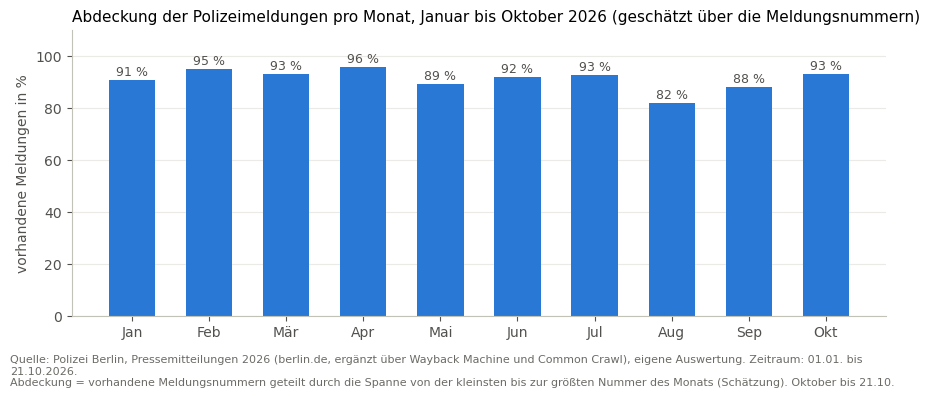

In [9]:
# Balkendiagramm: Abdeckung pro Monat
fig, ax = plt.subplots(figsize=(9, 3.6))
MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
labels = [MONATE[p.month - 1] for p in abdeckung.index]          # deutsche Monatsnamen
werte = abdeckung["Abdeckung %"].values

ax.bar(labels, werte, color="#2a78d6", width=0.6)
for x, w in zip(labels, werte):                                       # Werte direkt an die Balken
    ax.text(x, w + 1.5, f"{w:.0f} %", ha="center", fontsize=9, color="#52514e")

ax.set_ylim(0, 110)
ax.set_ylabel("vorhandene Meldungen in %", color="#52514e")
ax.set_title("Abdeckung der Polizeimeldungen pro Monat, Januar bis Oktober 2026 (geschätzt über die Meldungsnummern)",
             loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         "Abdeckung = vorhandene Meldungsnummern geteilt durch die Spanne von der kleinsten bis zur größten Nummer des Monats (Schätzung). Oktober bis 21.10.")
plt.show()

Nach den drei Erhebungsschritten sind rund 91 % aller Meldungsnummern vorhanden. Die Abdeckung liegt in allen Monaten über 80 %. Am schwächsten ist der August, für den kein zusätzlicher ID-Scan gelaufen ist. Der Juni, der im offiziellen Archiv fast ganz fehlte, ist durch den ID-Scan auf über 90 % gestiegen.

### 2.9 Duplikate

Geprüft wird auf drei Ebenen: gleiche URL, gleiche Meldungs-ID und gleiche Meldungsnummer.

In [10]:
print("Doppelte URLs:        ", raw["url"].duplicated().sum())
print("Doppelte Meldungs-IDs:", raw["meldung_id"].duplicated().sum())

doppelte_nr = raw[raw["nr"].notna() & raw["nr"].duplicated(keep=False)]
print("Meldungen mit doppelter Nummer:", len(doppelte_nr))
doppelte_nr.sort_values("nr")[["nr", "meldung_id", "datum_zeit", "quelle", "titel"]]

Doppelte URLs:         0
Doppelte Meldungs-IDs: 0
Meldungen mit doppelter Nummer: 8


,nr,meldung_id,datum_zeit,quelle,titel
553,543.0,1669301,2026-05-11T16:55:00,archiv,56-Jähriger konnte identifiziert werden
554,543.0,1670097,2026-05-11T13:42:00,archiv,Gestohlener Rucksack führt zu mutmaßlichem Drogenhändler
1253,973.0,1688937,2026-07-02T00:00:00,id-scan,Festnahmen nach räuberischer Erpressung von Jugendlichen
363,973.0,1702822,2026-08-13T14:03:00,archiv,Spätkauf ausgeraubt – Polizei bittet um Mithilfe
1125,1359.0,1724840,2026-10-13T00:00:00,wayback,Mutmaßlicher Einbrecher festgenommen
38,1359.0,1726523,2026-10-13T10:30:00,archiv,Mutmaßlicher Einbrecher festgenommen
37,1360.0,1726531,2026-10-13T12:00:00,archiv,Schüsse auf Café
1126,1360.0,1724948,2026-10-13T00:00:00,wayback,Schüsse auf Café


Es gibt keine doppelten URLs oder IDs, aber vier Nummern kommen zweimal vor. Das sind zwei verschiedene Fälle:

- **Nr. 1359 und 1360:** dieselbe Meldung mit gleichem Titel und Datum, aber unter zwei verschiedenen IDs veröffentlicht. Eine Version stammt aus dem Archiv, die andere aus der Wayback Machine. Das sind echte Duplikate, die Wayback-Version wird entfernt, weil die Archiv-Version die Uhrzeit hat.
- **Nr. 543 und 973:** jeweils zwei verschiedene Meldungen mit unterschiedlichem Titel und Inhalt. Hier hat die Polizei eine Nummer doppelt vergeben. Beide Meldungen bleiben erhalten.

### 2.10 Ereignisorte

In [11]:
bezirke = [
    "Mitte", "Friedrichshain-Kreuzberg", "Pankow", "Charlottenburg-Wilmersdorf",
    "Spandau", "Steglitz-Zehlendorf", "Tempelhof-Schöneberg", "Neukölln",
    "Treptow-Köpenick", "Marzahn-Hellersdorf", "Lichtenberg", "Reinickendorf",
]
orte = raw["ereignisort"].value_counts(dropna=False).rename_axis("ereignisort").to_frame("Meldungen")
orte["Bezirk"] = orte.index.isin(bezirke)
orte

,Meldungen,Bezirk
ereignisort,,
Mitte,161,True
Friedrichshain-Kreuzberg,143,True
Tempelhof-Schöneberg,113,True
Neukölln,111,True
Charlottenburg-Wilmersdorf,107,True
Pankow,90,True
Treptow-Köpenick,85,True
Marzahn-Hellersdorf,84,True
Steglitz-Zehlendorf,74,True


Alle zwölf Berliner Bezirke kommen vor und sind einheitlich geschrieben. Daneben gibt es Angaben, die keinem Bezirk entsprechen (berlinweit, bezirksübergreifend, bundesweit usw.). Sie werden in der Bereinigung in einer eigenen Spalte `ort_typ` zusammengefasst.

### 2.11 Textqualität

Hier wird geprüft, ob der Volltext sauber ist oder noch Reste der Webseite enthält.

In [12]:
texte = raw["text"].dropna()

# Länge der Texte in Zeichen
display(texte.str.len().describe().round(0).to_frame("Zeichen").T)

# Typische technische Reste aus dem HTML der Seite
reste = ["/Flex Text", "Infocolumn.view", "Flex Contact", "Schlagworte:", "Image.view", "Flex Bildergalerie"]
pd.DataFrame({
    "Rest": reste,
    "Meldungen": [texte.str.contains(r, regex=False).sum() for r in reste],
})

,count,mean,std,min,25%,50%,75%,max
Zeichen,1274.0,1301.0,673.0,492.0,894.0,1130.0,1505.0,7834.0


,Rest,Meldungen
0,/Flex Text,1274
1,Infocolumn.view,1274
2,Flex Contact,1274
3,Schlagworte:,1274
4,Image.view,15
5,Flex Bildergalerie,11


In [13]:
# So sieht das Ende eines Textes aus
print(texte.iloc[0][-350:])

ige ärztliche Behandlung jedoch ab. Er erstattete Strafanzeige. Die Ermittlungen dazu wurden vom zuständigen Fachkommissariat der Polizeidirektion 5 (City) übernommen.
/Flex Text
<div class="schlagworte">Schlagworte: Meldung Polizei Berlin vom 21.10.2026, Polizeimeldung, Kriminalität, Verkehr, Transport, ii1728645</div>
Infocolumn.view
Flex Contact


**Befund:** Alle Texte (1.274 von 1.274) enden mit technischen Resten des Content-Management-Systems von berlin.de, zum Beispiel `/Flex Text`, `Infocolumn.view` und einer HTML-Zeile mit Schlagworten. Ursache: Der Scraper liest alle Textknoten nach der Überschrift, und dazu gehören auch HTML-Kommentare, mit denen das System seine Seitenbausteine markiert.

Das ist ein Fehler, aber auch ein Gewinn: Die Zeile `Schlagworte:` enthält die Themen, die die Polizei selbst vergeben hat (z. B. Kriminalität, Verkehr, Zeugen gesucht, Tötungsdelikte). Sie werden in der Bereinigung als eigene Spalte gespeichert und helfen später bei der Kategorisierung.

### 2.12 Zusammenfassung der Befunde

| Punkt | Befund | Maßnahme in Abschnitt 3 |
|---|---|---|
| Umfang | 1.277 Meldungen, 10 Spalten, 01.01. bis 21.10.2026 | keine |
| Vollständigkeit | rund 91 % aller Meldungsnummern, alle Monate über 80 % | in Limitations |
| Fehlende Texte | 3 Meldungen ohne Text und Nummer | entfernen |
| Fehlender Ort | 2 Meldungen | als „unbekannt“ markieren |
| Duplikate | Nr. 1359 und 1360 doppelt gespeichert | Wayback-Version entfernen |
| Doppelte Nummern | Nr. 543 und 973 von der Polizei doppelt vergeben | beide behalten |
| Uhrzeit | bei 289 Meldungen nur das Datum bekannt | Stunde nur bei bekannter Uhrzeit |
| Textreste | technische Reste am Textende | entfernen, Schlagworte als Spalte sichern |
| Datentypen | Datum als Text | in Zeitangaben umwandeln |

## 3. Bereinigung

Alle Schritte arbeiten auf einer Kopie der Rohdaten. Nach jedem Schritt wird ausgegeben, wie viele Zeilen betroffen sind, damit jede Veränderung nachvollziehbar bleibt.

In [14]:
df = raw.copy()
print("Start:", len(df), "Meldungen")

Start: 1277 Meldungen


### 3.1 Duplikate entfernen

Als Duplikat gilt eine Meldung mit gleicher Nummer, gleichem Datum und gleichem Titel. Behalten wird die Version mit Uhrzeit (aus dem Archiv).

In [15]:
df["datum"] = df["datum_zeit"].str[:10]

vorher = len(df)
df = (
    df.sort_values("uhrzeit_bekannt", ascending=False)      # Version mit Uhrzeit zuerst
      .drop_duplicates(subset=["nr", "datum", "titel"], keep="first")
      .sort_values("datum_zeit")
      .reset_index(drop=True)
)
print("Entfernte Duplikate:", vorher - len(df))

Entfernte Duplikate: 2


### 3.2 Meldungen ohne Text entfernen

In [16]:
vorher = len(df)
df = df[df["text"].notna()].reset_index(drop=True)
print("Entfernt (ohne Text):", vorher - len(df))

Entfernt (ohne Text): 3


### 3.3 Technische Reste entfernen und Schlagworte sichern

Zuerst werden die Schlagworte aus der HTML-Zeile gelesen. Dabei bleiben nur echte Themen übrig: technische Einträge wie die interne Kennung (`ii1726531`), Datumsangaben und das allgemeine Wort „Polizeimeldung“ werden verworfen. Danach wird der Text auf den eigentlichen Meldungstext gekürzt. Zeilenumbrüche stammen aus dem HTML-Quelltext und stehen oft mitten im Satz, deshalb wird der Text zu einem Fließtext zusammengefügt.

Die Spalte `gemeinsame_meldung` zeigt, ob eine Meldung gemeinsam mit der Staatsanwaltschaft oder anderen Behörden veröffentlicht wurde.

In [17]:
def schlagworte_lesen(text: str) -> str:
    """Liest die Themen aus der Zeile 'Schlagworte: ...' und gibt sie mit '; ' getrennt zurück."""
    m = re.search(r"Schlagworte:\s*(.*?)</div>", text)
    if not m:
        return ""
    themen = []
    for wort in m.group(1).split(","):
        wort = wort.strip()
        if (
            not wort
            or re.fullmatch(r"ii\d+", wort)                   # interne Kennung
            or re.search(r"\d{1,2}\.\s?\w*\.?\s?\d{4}", wort)   # Datumsangaben
            or re.fullmatch(r"\d{4}", wort)                   # nur Jahreszahl
            or wort.startswith(("Meldung", "Polizeimeldung", "vom"))
            or wort == "Polizei"
        ):
            continue
        themen.append(wort)
    return "; ".join(dict.fromkeys(themen))                   # ohne Wiederholungen


# Zeilen, die nur Markierungen des Content-Management-Systems sind
MARKER = re.compile(
    r"^(/?Flex\b.*|/?[\w]+\.view|/?(video/audio|info) container|<div class=\"schlagworte\">.*)$"
)

def text_bereinigen(text: str) -> str:
    """Kürzt den Text auf den Meldungstext und entfernt Markierungszeilen."""
    # alles nach dem letzten Ende eines Textbausteins abschneiden
    if "/Flex Text" in text:
        text = text[: text.rfind("/Flex Text")]
    zeilen = [z.strip() for z in text.split("\n")]
    zeilen = [z for z in zeilen if z and not MARKER.match(z)]
    text = " ".join(zeilen)                                # Zeilenumbrüche mitten im Satz entfernen
    return re.sub(r"[ \t]{2,}", " ", text).strip()        # doppelte Leerzeichen


# Schlagworte und Hinweis auf gemeinsame Meldung zuerst aus dem Rohtext lesen,
# weil beides in den Zeilen steht, die danach entfernt werden
df["schlagworte"] = df["text"].apply(schlagworte_lesen)
df["gemeinsame_meldung"] = df["text"].str.contains("Gemeinsame Meldung", regex=False)
df["text"] = df["text"].apply(text_bereinigen)
df["text"] = df["text"].str.replace(r"^bis \d+\s+", "", regex=True)   # Sammelmeldungen "Nr. X bis Y"

# Kontrolle: Sind noch Reste übrig?
for r in reste:
    print(f"{r:20} noch {df['text'].str.contains(r, regex=False).sum()}")
print()
print(df["text"].iloc[0][:300], "…")

/Flex Text           noch 0
Infocolumn.view      noch 0
Flex Contact         noch 0
Schlagworte:         noch 0
Image.view           noch 0
Flex Bildergalerie   noch 0

Wie bereits in den Vorjahren hat sich die Polizei Berlin intensiv auf den Silvestereinsatz vorbereitet und war neben den aufgestockten Kräften des täglichen Dienstes mit rund 3.200 zusätzlichen Polizistinnen und Polizisten im Einsatz, darunter 785 Unterstützungskräfte von der Bundespolizei sowie aus …


In [18]:
# Welche Schlagworte vergibt die Polizei, und wie oft?
(
    df["schlagworte"].str.split("; ").explode()
      .replace("", pd.NA).dropna()
      .value_counts().head(15).to_frame("Meldungen")
)

,Meldungen
schlagworte,
Kriminalität,824
Verkehr,218
Transport,218
Zeugen gesucht,64
Sicherheit und Ordnung,43
Gesuchte Personen,23
Vermisst,13
Tötungsdelikte,12
Mord,11


### 3.4 Zeitspalten

`datum_zeit` wird in eine echte Zeitangabe umgewandelt. Daraus entstehen Spalten für Monat, Kalenderwoche und Wochentag. Die Stunde wird nur eingetragen, wenn die Uhrzeit bekannt ist. Bei den übrigen Meldungen stünde sonst fälschlich 0 Uhr.

In [19]:
df["datum_zeit"] = pd.to_datetime(df["datum_zeit"])
df["datum"] = df["datum_zeit"].dt.normalize()
df["monat"] = df["datum_zeit"].dt.to_period("M").astype(str)
df["kalenderwoche"] = df["datum_zeit"].dt.isocalendar().week.astype(int)
df["wochentag"] = df["datum_zeit"].dt.day_name(locale=None).map({
    "Monday": "Mo", "Tuesday": "Di", "Wednesday": "Mi", "Thursday": "Do",
    "Friday": "Fr", "Saturday": "Sa", "Sunday": "So",
})
df["stunde"] = df["datum_zeit"].dt.hour.where(df["uhrzeit_bekannt"] == 1).astype("Int64")
df["abgerufen_am"] = pd.to_datetime(df["abgerufen_am"])
df["nr"] = df["nr"].astype("Int64")

df[["datum_zeit", "datum", "monat", "kalenderwoche", "wochentag", "stunde"]].sample(5, random_state=1)

,datum_zeit,datum,monat,kalenderwoche,wochentag,stunde
996,2026-08-31 12:47:00,2026-08-31,2026-08,36,Mo,12
201,2026-02-27 00:00:00,2026-02-27,2026-02,9,Fr,<NA>
594,2026-05-31 00:00:00,2026-05-31,2026-05,22,So,<NA>
375,2026-04-13 10:54:00,2026-04-13,2026-04,16,Mo,10
1041,2026-09-08 09:47:00,2026-09-08,2026-09,37,Di,9


### 3.5 Ereignisort vereinheitlichen

Die Spalte `bezirk` enthält nur echte Bezirke. Alle anderen Angaben landen in `ort_typ`:

- **Bezirk:** einer der zwölf Bezirke
- **berlinweit:** berlinweit oder bezirksübergreifend
- **überregional:** Berlin/Brandenburg, bundeslandübergreifend, bundesweit
- **unbekannt:** kein Ort angegeben

In [20]:
def ort_typ(ort) -> str:
    if pd.isna(ort):
        return "unbekannt"
    if ort in bezirke:
        return "Bezirk"
    if ort in ("berlinweit", "bezirksübergreifend"):
        return "berlinweit"
    return "überregional"

df["ort_typ"] = df["ereignisort"].apply(ort_typ)
df["bezirk"] = df["ereignisort"].where(df["ort_typ"] == "Bezirk")
df["ereignisort"] = df["ereignisort"].fillna("unbekannt")

df["ort_typ"].value_counts().to_frame("Meldungen")

,Meldungen
ort_typ,
Bezirk,1169
berlinweit,83
überregional,18
unbekannt,2


### 3.6 Neue Spalten und Ergebnis prüfen

In [21]:
df["textlaenge"] = df["text"].str.len()

spalten_final = [
    "meldung_id", "nr", "datum_zeit", "datum", "monat", "kalenderwoche", "wochentag",
    "stunde", "uhrzeit_bekannt", "ereignisort", "ort_typ", "bezirk", "titel", "text",
    "textlaenge", "schlagworte", "gemeinsame_meldung", "quelle", "url", "abgerufen_am",
]
df = df[spalten_final]

print("Meldungen nach der Bereinigung:", len(df), f"(vorher {len(raw)})")
print()
print("Fehlende Werte (erwartet nur bei stunde und bezirk):")
print(df.isna().sum()[df.isna().sum() > 0])
print()
display(df["textlaenge"].describe().round(0).to_frame("Zeichen").T)
df.dtypes.to_frame("Datentyp").T

Meldungen nach der Bereinigung: 1272 (vorher 1277)

Fehlende Werte (erwartet nur bei stunde und bezirk):
stunde    287
bezirk    103
dtype: int64



,count,mean,std,min,25%,50%,75%,max
Zeichen,1272.0,1136.0,661.0,329.0,742.0,970.0,1342.0,7685.0


,meldung_id,nr,datum_zeit,datum,monat,kalenderwoche,wochentag,stunde,uhrzeit_bekannt,ereignisort,ort_typ,bezirk,titel,text,textlaenge,schlagworte,gemeinsame_meldung,quelle,url,abgerufen_am
Datentyp,int64,Int64,datetime64[ns],datetime64[ns],object,int64,object,Int64,int64,object,object,object,object,object,int64,object,bool,object,object,datetime64[ns]


Nach der Bereinigung bleiben 1.272 Meldungen. Fehlende Werte gibt es nur noch in `stunde` (keine Uhrzeit bekannt) und `bezirk` (Meldung ohne einzelnen Bezirk). Beides ist gewollt. Die Texte sind deutlich kürzer als vorher, weil die technischen Reste entfernt sind.

### 3.7 Speichern

Die bereinigten Daten werden als CSV in `data/processed/` gespeichert. Die Rohdatenbank bleibt unverändert.

In [22]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
ziel = OUT_DIR / "meldungen_clean.csv"
df.to_csv(ziel, index=False, encoding="utf-8")
print("Gespeichert:", ziel, f"({len(df)} Zeilen, {df.shape[1]} Spalten)")

Gespeichert: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/meldungen_clean.csv (1272 Zeilen, 20 Spalten)


## 4. Kategorisierung der Meldungen

Die Polizei vergibt eigene Schlagworte, doch die sind zu grob: „Kriminalität“ steht bei 824 von 1.272 Meldungen. Für ein Lagebild braucht es feinere Themen. Jede Meldung bekommt deshalb **eine Hauptkategorie** und zusätzlich einige **Merkmale** (z. B. Messer, Festnahme), die unabhängig von der Kategorie gelten.

Die Kategorien werden auf zwei Wegen bestimmt und dann verglichen:

1. **Regeln:** Schlagwortlisten mit regulären Ausdrücken. Schnell, vollständig nachvollziehbar, aber blind für Zusammenhänge.
2. **Lokales Sprachmodell über Ollama:** versteht den Zusammenhang einer Meldung. Es läuft auf dem eigenen Rechner, die Texte verlassen also nicht den Computer.

Zum Schluss wird eine Zufallsstichprobe von Hand geprüft. Erst sie zeigt, welche Methode wirklich besser ist.

### 4.1 Daten laden

In [23]:
from tqdm import tqdm                                  # Textbalken, braucht kein Internet
import json
import requests

df = pd.read_csv(OUT_DIR / "meldungen_clean.csv", parse_dates=["datum_zeit", "datum", "abgerufen_am"])
df["schlagworte"] = df["schlagworte"].fillna("")      # leere Schlagworte liest pandas als fehlend ein
df["nr"] = df["nr"].astype("Int64")
df["stunde"] = df["stunde"].astype("Int64")
print(len(df), "Meldungen geladen")

1272 Meldungen geladen


### 4.2 Kategorienschema

Die Kategorien orientieren sich an den Themen, die in Berliner Polizeimeldungen tatsächlich vorkommen, und an den Schwerpunkten der Sicherheitslage 2026 (Schusswaffengewalt, politisch motivierte Taten). Die Reihenfolge ist zugleich die Priorität, wenn bei den Regeln zwei Kategorien gleich viele Punkte haben.

Dieselben Beschreibungen bekommt später auch das Sprachmodell, damit beide Methoden mit denselben Definitionen arbeiten.

In [24]:
KATEGORIEN = {
    "Politisch motiviert":         "Taten mit politischem, rassistischem, antisemitischem, queerfeindlichem oder "
                                   "extremistischem Hintergrund, Angriffe auf Parteien, Wahlplakate, Gedenkorte; "
                                   "auch wenn der Staatsschutz ermittelt",
    "Schusswaffen und OK":         "Schüsse, Sprengungen und Explosionen, Funde illegaler Schusswaffen, "
                                   "Ermittlungen gegen organisierte Kriminalität (z. B. BAO Ferrum), Schutzgeld",
    "Gewalt":                      "Körperverletzung, Messerangriffe, Tötungsdelikte, Bedrohung, sexuelle Gewalt, "
                                   "häusliche Gewalt, Schlägereien",
    "Raub und Diebstahl":          "Raub, Überfälle, Diebstahl, Einbruch, Hehlerei",
    "Betrug":                      "Betrug, Schockanrufe, falsche Polizeibeamte, Trickdiebstahl, Computerbetrug",
    "Brand und Sachbeschädigung":  "Brände, Brandstiftung, Sachbeschädigung, Graffiti",
    "Drogen":                      "Handel mit oder Besitz von Betäubungsmitteln",
    "Verkehr":                     "Verkehrsunfälle, Fahrerflucht, illegale Rennen, Verkehrskontrollen",
    "Vermisste und Fahndung":      "vermisste Personen, Öffentlichkeitsfahndungen mit Bild, unbekannte Personen",
    "Einsatzlage und Versammlung": "Demonstrationen, Versammlungen, Großeinsätze, Silvester, Allgemeinverfügungen",
    "Prävention und Service":      "Präventionsaktionen, Veranstaltungen und Informationen der Polizei",
    "Sonstiges":                   "alles, was in keine andere Kategorie passt",
}
pd.DataFrame.from_dict(KATEGORIEN, orient="index", columns=["Beschreibung"])

,Beschreibung
Politisch motiviert,"Taten mit politischem, rassistischem, antisemitischem, queerfeindlichem oder..."
Schusswaffen und OK,"Schüsse, Sprengungen und Explosionen, Funde illegaler Schusswaffen, Ermittlu..."
Gewalt,"Körperverletzung, Messerangriffe, Tötungsdelikte, Bedrohung, sexuelle Gewalt..."
Raub und Diebstahl,"Raub, Überfälle, Diebstahl, Einbruch, Hehlerei"
Betrug,"Betrug, Schockanrufe, falsche Polizeibeamte, Trickdiebstahl, Computerbetrug"
Brand und Sachbeschädigung,"Brände, Brandstiftung, Sachbeschädigung, Graffiti"
Drogen,Handel mit oder Besitz von Betäubungsmitteln
Verkehr,"Verkehrsunfälle, Fahrerflucht, illegale Rennen, Verkehrskontrollen"
Vermisste und Fahndung,"vermisste Personen, Öffentlichkeitsfahndungen mit Bild, unbekannte Personen"
Einsatzlage und Versammlung,"Demonstrationen, Versammlungen, Großeinsätze, Silvester, Allgemeinverfügungen"


### 4.3 Regelbasierte Kategorisierung

Für jede Kategorie gibt es eine Liste typischer Wörter. Jede Meldung bekommt pro Kategorie Punkte:

- **5 Punkte** für jeden Treffer im Titel, weil der Titel den Kern der Meldung nennt
- **1 Punkt** für jeden Treffer im Text, höchstens 4, damit lange Texte nicht überwiegen
- **3 Punkte** zusätzlich, wenn die Polizei ein passendes Schlagwort vergeben hat (z. B. „Verkehr“, „Vermisst“)
- **3 Punkte** zusätzlich für „Politisch motiviert“, wenn der Staatsschutz ermittelt. Er ist bei der Polizei Berlin für politisch motivierte Kriminalität zuständig.

Die Kategorie mit den meisten Punkten gewinnt. Ohne jeden Treffer gilt „Sonstiges“. Liegt die zweitbeste Kategorie höchstens 1 Punkt dahinter, wird die Meldung als **knapp** markiert. Diese Fälle sind unsicher.

Wichtig bei den Mustern: `brand\b` findet „Wohnungsbrand“, aber nicht „Brandenburg“. Groß- und Kleinschreibung wird ignoriert.

In [25]:
REGELN = {
    "Politisch motiviert": r"Staatsschutz|antisemit\w*|rassist\w*|queerfeindlich\w*|homophob\w*|transfeindlich\w*|"
                           r"Hakenkreuz\w*|verfassungsfeindlich\w*|Volksverhetzung|Hitlergru\w*|Wahlplakat\w*|"
                           r"Parteib(ü|u)ro\w*|Terror\w*|extremist\w*|islamist\w*|israelfeindlich\w*|"
                           r"Gedenk(tafel|stein|ort)\w*",
    "Schusswaffen und OK": r"\bSchuss\w*|Schüsse|geschossen|Druckluftwaffe\w*|Waffengesetz|Schusswaffe\w*|"
                           r"BAO Ferrum|Sprengstoff\w*|Explosion\w*|Sprengung\w*|gesprengt|"
                           r"kriminelle\w* Vereinigung|Schutzgeld\w*",
    "Gewalt":              r"Körperverletzung\w*|geschlagen|getreten|Messer\w*|Stichverletz\w*|gestochen|Faustschl\w*|"
                           r"angegriffen|Angriff\w*|Tötungsdelikt\w*|getötet|Mordkommission|Totschlag\w*|bedroht\w*|"
                           r"Bedrohung\w*|gewürgt|Vergewaltigung\w*|sexuell\w*|Schlägerei\w*|Auseinandersetzung\w*",
    "Raub und Diebstahl":  r"\bRaub\w*|Räuber\w*|räuberisch\w*|überfallen|Überfall\w*|dieb\w*|gestohlen\w*|"
                           r"Einbruch\w*|eingebrochen|Einbrecher\w*|entwendet\w*|Hehlerei",
    "Betrug":              r"Betrug\w*|betrogen|Betrüger\w*|Schockanruf\w*|falsche\w* Polizeibeamt\w*|"
                           r"Enkeltrick\w*|falsche\w* Paketbot\w*|Trickdieb\w*",
    "Brand und Sachbeschädigung": r"brand(stift\w*|anschlag\w*|satz\w*|stelle\w*|ort\w*)?\b|brände\b|brannte\w*|"
                           r"angezündet|\bFeuer\b|Sachbeschädigung\w*|beschmiert\w*|Graffiti|beschädigt\w*",
    "Drogen":              r"Betäubungsmittel\w*|\bDrogen\w*|Kokain|Cannabis\w*|Heroin|Marihuana|Dealer\w*|"
                           r"Rauschgift\w*",
    "Verkehr":             r"Verkehrsunfall\w*|\bUnfall\w*|angefahren|Fahrerflucht|Unfallflucht|zusammengestoßen|"
                           r"Zusammenstoß\w*|Verkehrskontrolle\w*|Fahrerlaubnis|Führerschein\w*|"
                           r"Kraftfahrzeugrennen|überschlug|kollidiert\w*",
    "Vermisste und Fahndung": r"vermisst\w*|Öffentlichkeitsfahndung|Wer kennt|Wer erkennt|Fahndungsfoto\w*|"
                           r"Lichtbild\w*",
    "Einsatzlage und Versammlung": r"Versammlung\w*|Demonstration\w*|Kundgebung\w*|\bAufzug\w*|Großeinsatz\w*|"
                           r"Silvester\w*|Jahreswechsel|1\. Mai|Fußballspiel\w*|Gefährdungslage|Allgemeinverfügung\w*",
    "Prävention und Service": r"Prävention\w*|Aktionstag\w*|Seniorensicherheitstag|Tag der offenen Tür|"
                           r"Informationsveranstaltung\w*|Ausbildung\w*|Kampagne\w*",
}
MUSTER = {k: re.compile(v, re.IGNORECASE) for k, v in REGELN.items()}

# Schlagworte der Polizei, die eine Kategorie zusätzlich stützen
SCHLAGWORT_BONUS = {
    "Verkehr": "Verkehr", "Tötungsdelikte": "Gewalt", "Mord": "Gewalt",
    "Vermisst": "Vermisste und Fahndung", "Gesuchte Personen": "Vermisste und Fahndung",
}


def regel_punkte(titel: str, text: str, schlagworte: str) -> dict:
    """Punkte pro Kategorie: 5 je Treffer im Titel, 1 je Treffer im Text (max. 4), 3 für passendes Schlagwort."""
    punkte = {k: 5 * len(m.findall(titel)) + min(len(m.findall(text)), 4) for k, m in MUSTER.items()}
    for sw in schlagworte.split("; "):
        if sw in SCHLAGWORT_BONUS:
            punkte[SCHLAGWORT_BONUS[sw]] += 3
    if "Staatsschutz" in text:                    # ermittelt der Staatsschutz, gilt die Tat als politisch
        punkte["Politisch motiviert"] += 3
    return punkte


def regel_kategorie(row) -> pd.Series:
    p = regel_punkte(row["titel"], row["text"], row["schlagworte"])
    rangfolge = sorted(p.values(), reverse=True)
    if rangfolge[0] == 0:
        return pd.Series({"kategorie_regel": "Sonstiges", "regel_punkte": 0, "regel_knapp": False})
    sieger = next(k for k in REGELN if p[k] == rangfolge[0])    # Reihenfolge = Priorität bei Gleichstand
    return pd.Series({
        "kategorie_regel": sieger,
        "regel_punkte": rangfolge[0],
        "regel_knapp": rangfolge[0] - rangfolge[1] <= 1,
    })


df[["kategorie_regel", "regel_punkte", "regel_knapp"]] = df.apply(regel_kategorie, axis=1)

ergebnis_regel = df["kategorie_regel"].value_counts().to_frame("Meldungen")
ergebnis_regel["Anteil %"] = (ergebnis_regel["Meldungen"] / len(df) * 100).round(1)
ergebnis_regel["davon knapp"] = df.groupby("kategorie_regel")["regel_knapp"].sum()
display(ergebnis_regel)
print(f"Knappe Entscheidungen insgesamt: {df['regel_knapp'].sum()} ({df['regel_knapp'].mean() * 100:.0f} %)")

,Meldungen,Anteil %,davon knapp
kategorie_regel,,,
Verkehr,328,25.8,17
Gewalt,293,23.0,44
Schusswaffen und OK,152,11.9,26
Raub und Diebstahl,145,11.4,19
Brand und Sachbeschädigung,120,9.4,8
Politisch motiviert,92,7.2,19
Vermisste und Fahndung,44,3.5,2
Drogen,33,2.6,6
Sonstiges,23,1.8,0


Knappe Entscheidungen insgesamt: 149 (12 %)


In [26]:
# Stichprobe: je Kategorie drei Titel, um die Regeln mit eigenen Augen zu prüfen
(
    df.sample(frac=1, random_state=1)                 # zufällig mischen
      .groupby("kategorie_regel").head(3)             # dann je Kategorie die ersten drei
      .sort_values("kategorie_regel")
      [["kategorie_regel", "regel_knapp", "titel"]]
)

,kategorie_regel,regel_knapp,titel
35,Betrug,False,Drei Festnahmen von falschen Polizisten
636,Betrug,False,Trickbetrug durch falsche Polizeibeamte – Wer erkennt den Tatverdächtigen?
198,Betrug,False,Schockanrufe in russischer Sprache – hohe Schadenssummen in sehr kurzer Zeit
375,Brand und Sachbeschädigung,False,Brandstiftung in Friseursalon
262,Brand und Sachbeschädigung,False,Toter Mann nach Wohnungsbrand geborgen
1047,Brand und Sachbeschädigung,False,Wahlplakate durch Feuer beschädigt
644,Drogen,False,Netzwerk aufgedeckt - Durchsuchungsbeschlüsse gegen den illegalen Handel mit...
288,Drogen,False,Durchsuchungsbeschlüsse wegen des Verdachts des Handeltreibens mit Betäubung...
19,Drogen,False,Mutmaßliches Kokstaxi aufgespürt – zwei Festnahmen
663,Einsatzlage und Versammlung,False,Polizei Berlin erlässt Allgemeinverfügung zum 17. Juni 2026


Die Regeln ordnen fast alle Meldungen einer Kategorie zu, nur rund 2 % landen in „Sonstiges“. Verkehr und Gewalt sind mit je etwa einem Viertel die größten Gruppen, danach folgen Schusswaffen und OK, Raub und Diebstahl sowie Brände.

Etwa jede achte Entscheidung ist knapp. Das zeigt die Grenze der Methode: Eine Meldung wie „Mutmaßlicher Raub mit Messer“ trifft Wörter aus „Raub“ und „Gewalt“, und die Regel entscheidet nur nach Punkten. Genau für solche Fälle ist das Sprachmodell gedacht.

### 4.4 Zusatzmerkmale

Manche Eigenschaften sind unabhängig von der Kategorie wichtig: Ein Messer kann bei einem Raub, einem Streit oder einem politischen Angriff vorkommen. Diese Merkmale werden deshalb als eigene Ja/Nein-Spalten gespeichert und nur aus dem Text gelesen.

In [27]:
MERKMALE = {
    "messer":              r"Messer\w*|Machete\w*|Stichverletz\w*|Stichwunde\w*|gestochen|Stichwaffe\w*",
    "schusswaffe":         r"\bSchuss\w*|Schüsse|geschossen|Schusswaffe\w*|Pistole\w*|Revolver",
    "festnahme":           r"festgenommen|Festnahme\w*|Haftbefehl\w*|Untersuchungshaft",
    "zeugenaufruf":        r"Zeug(?:en|innen)\w* gesucht|bittet um Mithilfe|Hinweisportal|Zeugenaufruf|"
                           r"Hinweise nimmt",
    "staatsschutz":        r"Staatsschutz",
    "angriff_auf_polizei": r"Widerstand|(?:Polizei|Einsatz)\w* (?:wurde|wurden)? ?(?:angegriffen|attackiert)|"
                           r"(?:Polizist|Polizeibeamt|Einsatzkr)\w* (?:leicht |schwer )?verletzt",
}
for name, muster in MERKMALE.items():
    df[name] = df["titel"].str.contains(muster, case=False, regex=True) | \
               df["text"].str.contains(muster, case=False, regex=True)

merkmale = df[list(MERKMALE)].sum().to_frame("Meldungen")
merkmale["Anteil %"] = (merkmale["Meldungen"] / len(df) * 100).round(1)
merkmale

,Meldungen,Anteil %
messer,175,13.8
schusswaffe,201,15.8
festnahme,309,24.3
zeugenaufruf,100,7.9
staatsschutz,147,11.6
angriff_auf_polizei,96,7.5


### 4.5 Kategorisierung mit lokalem Sprachmodell (Ollama)

**Voraussetzungen:** Ollama läuft (`ollama serve`) und das Modell ist geladen. Welche Modelle vorhanden sind, zeigt `ollama list` im Terminal. Der Name in `MODELL` muss genau so geschrieben sein.

**Welche Meldungen das Modell bekommt:** Das Vorgehen lief in zwei Schritten.

1. **Modellvergleich:** Ein erster Test mit Mistral Small 3.1 zeigte rund 24 Sekunden pro Meldung, für alle 1.272 Meldungen also rund 8,5 Stunden. Vier Modelle bekamen deshalb zunächst nur 254 Meldungen:
    - alle **knappen** Regel-Entscheidungen
    - alle Meldungen in **„Sonstiges“**
    - die **Zufallsstichprobe** von 100 Meldungen für die Bewertung in 4.7
2. **Endgültiger Lauf:** Gemma 4 (26B) schnitt in 4.7 zusammen mit Mistral am besten ab und braucht nur rund 5 Sekunden pro Meldung. Es kategorisiert deshalb **alle 1.272 Meldungen**. Für die 1.018 Meldungen, die noch nicht im Cache standen, brauchte es 1 Stunde 24 Minuten.

Die Einstellung `NUR_UNSICHERE` in der nächsten Zelle schaltet zwischen beiden Schritten um. Die bereits kategorisierten Meldungen bleiben im Cache und werden nicht neu berechnet.

**So funktioniert es:**

- Das Modell bekommt Titel und den **ganzen Text** jeder Meldung, dazu die Kategorien mit ihren Beschreibungen aus 4.2. Das kostet Zeit, lohnt sich aber, weil gerade bei schwierigen Fällen der entscheidende Hinweis (z. B. „der Staatsschutz ermittelt“) oft erst am Ende steht. Die längste Meldung hat rund 7.700 Zeichen und passt in das Kontextfenster von 4.096 Tokens.
- Über ein **JSON-Schema** wird die Antwort erzwungen: Das Modell muss genau eine Kategorie aus der Liste wählen und eine Begründung von höchstens 10 Wörtern geben. Freier Text ist nicht möglich.
- `temperature = 0` macht die Antworten reproduzierbar.
- Jede Antwort wird sofort in einer eigenen Datei pro Modell gespeichert (`data/processed/llm_kategorien_<modell>.csv`). Bricht der Lauf ab, macht ein Neustart dort weiter. So lassen sich auch mehrere Modelle vergleichen, ohne dass sich die Ergebnisse vermischen.

In [28]:
OLLAMA_URL = "http://localhost:11434"
MODELL = "gemma4:26b"      # an das eigene Modell anpassen (ollama list)
LLM_CACHE = OUT_DIR / f"llm_kategorien_{MODELL.replace(':', '_').replace('/', '_')}.csv"
TEXT_ZEICHEN = None                     # None = ganzer Text; eine Zahl kürzt den Text
NUR_UNSICHERE = False                   # True = nur knappe, Sonstiges und Stichprobe (Modellvergleich)
                                        # False = alle Meldungen (endgültiger Lauf)

# Läuft Ollama, und ist das Modell vorhanden?
try:
    modelle = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()["models"]]
    print("Ollama läuft. Vorhandene Modelle:", ", ".join(modelle))
    print("Gewähltes Modell vorhanden:", MODELL in modelle)
except requests.RequestException:
    print("Ollama ist nicht erreichbar. Im Terminal starten: ollama serve")

Ollama läuft. Vorhandene Modelle: qwen3.6:35b, gemma4:31b, aya-expanse:8b, aya-expanse:32b, gemma4:26b, gemma2:9b, mistral-small3.1:latest, nomic-embed-text:latest, qwen3.6:27b, qwen3-coder:30b, qwen2.5:32b
Gewähltes Modell vorhanden: True


In [29]:
KATEGORIE_LISTE = list(KATEGORIEN)

SYSTEM_PROMPT = (
    "Du ordnest Pressemitteilungen der Polizei Berlin genau einer Kategorie zu.\n"
    "Wähle die Kategorie, die den Kern der Meldung beschreibt, nicht ein Nebendetail.\n"
    "Regeln:\n"
    "- Wenn ein politisches, rassistisches, antisemitisches oder queerfeindliches Motiv genannt wird "
    "oder der Staatsschutz ermittelt: 'Politisch motiviert'.\n"
    "- Wenn geschossen wurde oder eine Sprengung stattfand: 'Schusswaffen und OK'.\n"
    "- Ein Raub oder eine Bedrohung mit Schusswaffe, bei der nicht geschossen wurde, ist "
    "'Raub und Diebstahl' oder 'Gewalt'.\n"
    "- Wähle nur, was im Text steht. Ziehe keine Schlüsse über Waffen oder Sprengstoff, "
    "die nicht ausdrücklich genannt werden.\n"
    "- Ein Raub mit Messer ist 'Raub und Diebstahl', ein Streit mit Messer ist 'Gewalt'.\n"
    "- Nur wenn nichts passt: 'Sonstiges'.\n"
    "- Begründung: höchstens 10 Wörter.\n\n"
    "Kategorien:\n" + "\n".join(f"- {k}: {v}" for k, v in KATEGORIEN.items())
)

# JSON-Schema: erzwingt eine Kategorie aus der Liste und eine Begründung
ANTWORT_SCHEMA = {
    "type": "object",
    "properties": {
        "kategorie":   {"type": "string", "enum": KATEGORIE_LISTE},
        "begruendung": {"type": "string"},
    },
    "required": ["kategorie", "begruendung"],
}


def llm_kategorie(titel: str, text: str) -> dict:
    """Schickt eine Meldung an Ollama und gibt Kategorie und Begründung zurück."""
    payload = {
        "model": MODELL,
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Titel: {titel}\n\nText: {text[:TEXT_ZEICHEN]}"},
        ],
        "format": ANTWORT_SCHEMA,
        "stream": False,
        "think": False,                       # Denkmodus aus (nur für Modelle, die ihn haben)
        "options": {"temperature": 0, "num_ctx": 4096},
    }
    r = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=300)
    r.raise_for_status()
    antwort = json.loads(r.json()["message"]["content"])
    if antwort.get("kategorie") not in KATEGORIE_LISTE:       # Sicherheitsnetz
        antwort["kategorie"] = "FEHLER"
    return antwort


# Test mit einer einzelnen Meldung, bevor der große Lauf startet
beispiel = df.iloc[0]
print(beispiel["titel"])
print(llm_kategorie(beispiel["titel"], beispiel["text"]))

Bilanz der polizeilichen Maßnahmen zum Jahreswechsel 2025/2026
{'kategorie': 'Einsatzlage und Versammlung', 'begruendung': 'Zusammenfassung der polizeilichen Maßnahmen und Einsätze an Silvester.'}


In [30]:
# Zufallsstichprobe für 4.7 anlegen, aber nur, wenn sie noch nicht existiert,
# damit eigene Einträge nie überschrieben werden
STICHPROBE = OUT_DIR / "stichprobe_manuell.csv"
if not STICHPROBE.exists():
    # ohne die Ergebnisse der Methoden, damit sie das eigene Urteil nicht beeinflussen
    probe = df.sample(100, random_state=2026)[["meldung_id", "titel", "text"]].copy()
    probe["text"] = probe["text"].str[:600]                       # zum Lesen reicht der Anfang
    probe.insert(2, "kategorie_manuell", "")                        # wird von Hand ausgefüllt
    probe.to_csv(STICHPROBE, index=False, encoding="utf-8")
    print("Stichprobe angelegt:", STICHPROBE)
else:
    print("Stichprobe existiert bereits, wird nicht überschrieben:", STICHPROBE)
stichprobe_ids = set(pd.read_csv(STICHPROBE)["meldung_id"])

# Auswahlgrund für jede Meldung: knapp, Sonstiges, Stichprobe oder eindeutig
df["in_stichprobe"] = df["meldung_id"].isin(stichprobe_ids)
df["llm_grund"] = "eindeutig"
df.loc[df["in_stichprobe"], "llm_grund"] = "stichprobe"
df.loc[df["kategorie_regel"] == "Sonstiges", "llm_grund"] = "sonstiges"
df.loc[df["regel_knapp"], "llm_grund"] = "knapp"

# Auswahl für das Sprachmodell (siehe NUR_UNSICHERE in den Einstellungen)
if NUR_UNSICHERE:
    auswahl = df["llm_grund"] != "eindeutig"
else:
    auswahl = pd.Series(True, index=df.index)

print(df.loc[auswahl, "llm_grund"].value_counts().to_string())
print(f"Für das Sprachmodell ausgewählt: {auswahl.sum()} von {len(df)} Meldungen")

Stichprobe existiert bereits, wird nicht überschrieben: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/stichprobe_manuell.csv
llm_grund
eindeutig     1018
knapp          149
stichprobe      82
sonstiges       23
Für das Sprachmodell ausgewählt: 1272 von 1272 Meldungen


In [31]:
# Großer Lauf: alle ausgewählten Meldungen, die noch nicht im Cache stehen
if LLM_CACHE.exists():
    fertig = set(pd.read_csv(LLM_CACHE)["meldung_id"])
else:
    fertig = set()
    pd.DataFrame(columns=["meldung_id", "kategorie_llm", "begruendung_llm", "modell", "zeitpunkt"]) \
      .to_csv(LLM_CACHE, index=False)

offen = df[auswahl & ~df["meldung_id"].isin(fertig)]
print(f"Bereits kategorisiert: {len(fertig)} | offen: {len(offen)}")

fehler = 0
for _, row in tqdm(offen.iterrows(), total=len(offen), desc="LLM"):
    try:
        a = llm_kategorie(row["titel"], row["text"])
    except Exception as e:                    # Netzwerk- oder Formatfehler: Meldung später erneut versuchen
        fehler += 1
        continue
    pd.DataFrame([{
        "meldung_id": row["meldung_id"], "kategorie_llm": a["kategorie"],
        "begruendung_llm": a.get("begruendung", ""), "modell": MODELL,
        "zeitpunkt": pd.Timestamp.now().isoformat(timespec="seconds"),
    }]).to_csv(LLM_CACHE, mode="a", header=False, index=False)    # sofort speichern

print("Fertig. Fehler in diesem Lauf:", fehler, "(bei Fehlern einfach diese Zelle erneut starten)")

Bereits kategorisiert: 1272 | offen: 0


LLM: 0it [00:00, ?it/s]

Fertig. Fehler in diesem Lauf: 0 (bei Fehlern einfach diese Zelle erneut starten)


In [32]:
# Ergebnisse des Sprachmodells mit den Meldungen verbinden
llm = pd.read_csv(LLM_CACHE).drop_duplicates("meldung_id", keep="last")
df = df.drop(columns=["kategorie_llm", "begruendung_llm"], errors="ignore") \
       .merge(llm[["meldung_id", "kategorie_llm", "begruendung_llm"]], on="meldung_id", how="left")

print("Mit LLM-Kategorie:", df["kategorie_llm"].notna().sum(), "von", auswahl.sum(), "ausgewählten Meldungen")
ergebnis_llm = df["kategorie_llm"].value_counts().to_frame("Meldungen")
ergebnis_llm["Anteil %"] = (ergebnis_llm["Meldungen"] / df["kategorie_llm"].notna().sum() * 100).round(1)
ergebnis_llm

Mit LLM-Kategorie: 1272 von 1272 ausgewählten Meldungen


,Meldungen,Anteil %
kategorie_llm,,
Verkehr,316,24.8
Gewalt,223,17.5
Politisch motiviert,167,13.1
Raub und Diebstahl,166,13.1
Schusswaffen und OK,152,11.9
Brand und Sachbeschädigung,90,7.1
Vermisste und Fahndung,45,3.5
Drogen,36,2.8
Betrug,27,2.1


In [33]:
# Datei zur Prüfung der LLM-Entscheidungen (z. B. durch ein zweites, größeres Modell)
pruefung = df.loc[df["kategorie_llm"].notna(), [
    "meldung_id", "llm_grund", "titel", "text", "kategorie_regel", "kategorie_llm", "begruendung_llm",
]].copy()
pruefung["text"] = pruefung["text"].str[:TEXT_ZEICHEN]          # genau der Text, den das Modell sah
pruefung.to_csv(OUT_DIR / f"pruefung_{LLM_CACHE.stem}.csv", index=False, encoding="utf-8")
print("Prüfdatei:", OUT_DIR / f"pruefung_{LLM_CACHE.stem}.csv", f"({len(pruefung)} Zeilen)")

Prüfdatei: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/pruefung_llm_kategorien_gemma4_26b.csv (1272 Zeilen)


### 4.6 Vergleich: Regeln und Sprachmodell

Zwei Kennzahlen zeigen, wie ähnlich beide Methoden entscheiden:

- **Übereinstimmung:** Anteil der Meldungen mit gleicher Kategorie
- **Cohens Kappa:** Übereinstimmung, bereinigt um den Anteil, der schon durch Zufall zu erwarten wäre. Faustregel: über 0,6 gut, über 0,8 sehr gut.

Wichtig beim Lesen: Die Werte werden getrennt nach Auswahlgrund gezeigt. Bei den **eindeutigen** Regel-Entscheidungen ist eine hohe Übereinstimmung zu erwarten, bei den **knappen** eine niedrige, denn genau dort soll das Modell die Entscheidung klären. Aussagekräftig für die Gesamtqualität ist die **Zufallsstichprobe**, weil sie leichte und schwere Fälle in ihrem echten Verhältnis enthält.

Übereinstimmung heißt noch nicht, dass beide richtig liegen. Das zeigt erst die manuelle Prüfung in 4.7.

In [34]:
def cohens_kappa(a: pd.Series, b: pd.Series) -> float:
    """Cohens Kappa für zwei Listen von Kategorien gleicher Länge."""
    po = (a == b).mean()                                          # beobachtete Übereinstimmung
    kategorien = set(a) | set(b)
    pe = sum((a == k).mean() * (b == k).mean() for k in kategorien)   # zufällig erwartete Übereinstimmung
    return (po - pe) / (1 - pe)

beide = df.dropna(subset=["kategorie_llm"])
gleich = beide["kategorie_regel"] == beide["kategorie_llm"]
print(f"Verglichen: {len(beide)} Meldungen")
print(f"Übereinstimmung: {gleich.mean() * 100:.1f} %")
print(f"Cohens Kappa:    {cohens_kappa(beide['kategorie_regel'], beide['kategorie_llm']):.2f}")
print()
print("Nach Auswahlgrund:")
for grund in ["eindeutig", "stichprobe", "knapp", "sonstiges"]:
    teil = beide[beide["llm_grund"] == grund]
    if len(teil):
        print(f"  {grund:11} {len(teil):4} Meldungen, Übereinstimmung "
              f"{(teil['kategorie_regel'] == teil['kategorie_llm']).mean() * 100:5.1f} %")
# zusätzlich: alle Stichproben-Meldungen, auch wenn sie zugleich knapp waren
teil = beide[beide["in_stichprobe"]]
if len(teil):
    print(f"  ganze Stichprobe ({len(teil)}): Übereinstimmung "
          f"{(teil['kategorie_regel'] == teil['kategorie_llm']).mean() * 100:.1f} %, "
          f"Kappa {cohens_kappa(teil['kategorie_regel'], teil['kategorie_llm']):.2f}")
print()

pd.crosstab(beide["kategorie_regel"], beide["kategorie_llm"], margins=True, margins_name="gesamt")

Verglichen: 1272 Meldungen
Übereinstimmung: 84.2 %
Cohens Kappa:    0.81

Nach Auswahlgrund:
  eindeutig   1018 Meldungen, Übereinstimmung  89.0 %
  stichprobe    82 Meldungen, Übereinstimmung  87.8 %
  knapp        149 Meldungen, Übereinstimmung  55.0 %
  sonstiges     23 Meldungen, Übereinstimmung  47.8 %
  ganze Stichprobe (100): Übereinstimmung 81.0 %, Kappa 0.78



kategorie_llm,Betrug,Brand und Sachbeschädigung,Drogen,Einsatzlage und Versammlung,Gewalt,Politisch motiviert,Prävention und Service,Raub und Diebstahl,Schusswaffen und OK,Sonstiges,Verkehr,Vermisste und Fahndung,gesamt
kategorie_regel,,,,,,,,,,,,,
Betrug,15,0,0,0,0,0,1,0,0,0,0,0,16
Brand und Sachbeschädigung,0,85,0,1,1,29,0,1,2,0,1,0,120
Drogen,0,0,28,0,0,0,0,0,3,0,2,0,33
Einsatzlage und Versammlung,0,0,1,18,0,3,0,0,0,0,0,0,22
Gewalt,0,2,1,2,208,37,2,24,10,3,2,2,293
Politisch motiviert,0,0,0,0,0,92,0,0,0,0,0,0,92
Prävention und Service,0,0,0,0,0,0,4,0,0,0,0,0,4
Raub und Diebstahl,9,0,2,0,0,3,2,126,1,0,1,1,145
Schusswaffen und OK,0,0,2,0,5,1,0,9,135,0,0,0,152


In [35]:
# Beispiele, bei denen Regeln und Sprachmodell verschieden entscheiden
beide.loc[~gleich, ["titel", "kategorie_regel", "kategorie_llm", "begruendung_llm"]].sample(
    min(15, (~gleich).sum()), random_state=1
)

,titel,kategorie_regel,kategorie_llm,begruendung_llm
640,Fahrradfahrerin fährt Kind an,Gewalt,Verkehr,Es handelt sich um einen Verkehrsunfall mit Personenschaden.
799,Senior in Wohnung beraubt und verletzt,Gewalt,Raub und Diebstahl,Es handelt sich um einen Raubüberfall in einer Wohnung.
385,Geraubte Wertgegenstände zum Kauf angeboten - Festnahme,Gewalt,Raub und Diebstahl,Raub mit Messer und anschließendes Angebot zum Rückkauf.
237,Brandstiftung an einem Veranstaltungsgebäude,Brand und Sachbeschädigung,Politisch motiviert,Nationalsozialistische Symbole und Ermittlungen durch den Staatsschutz.
1048,Queere Person angegriffen,Gewalt,Politisch motiviert,Angriff auf queere Person und Ermittlung durch Staatsschutz.
951,Schutzscheibe in Linienbus eingeschlagen,Gewalt,Brand und Sachbeschädigung,Einschlagen einer Schutzscheibe ist Sachbeschädigung.
171,Autofahrer flüchtete vor Überprüfung - Festnahme,Drogen,Verkehr,Fahrer flüchtete vor Kontrolle und gefährdete andere Verkehrsteilnehmer.
524,Mann rassistisch beleidigt und angegriffen,Gewalt,Politisch motiviert,Rassistische Beleidigung als Tatmotiv genannt.
15,Trickdiebstahl bei Seniorin,Raub und Diebstahl,Betrug,Täter gaben sich als Polizisten und Mitarbeiter aus.
83,Spätkauf mit Schusswaffe überfallen,Schusswaffen und OK,Raub und Diebstahl,Überfall mit Vorhalten einer Schusswaffe ist Raub.


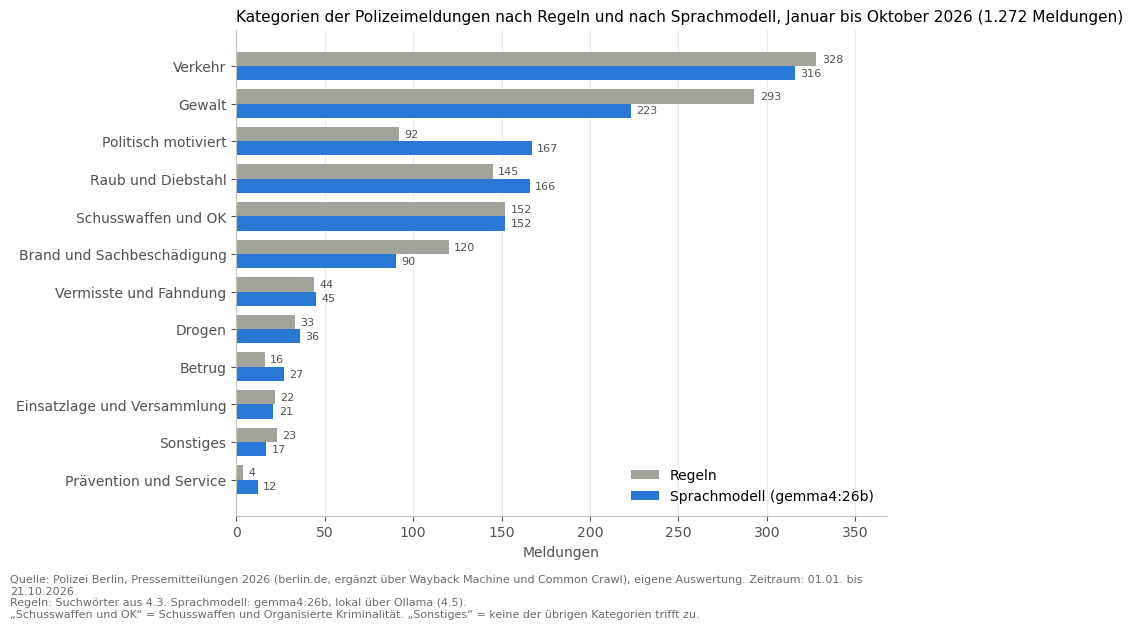

In [36]:
# Diagramm: Verteilung der Kategorien nach Regeln und nach Sprachmodell
vergleich = pd.DataFrame({
    "Regeln": beide["kategorie_regel"].value_counts(),
    "Sprachmodell": beide["kategorie_llm"].value_counts(),
}).fillna(0).astype(int).sort_values("Sprachmodell")          # größte Kategorie oben

fig, ax = plt.subplots(figsize=(9, 5.8))
pos = range(len(vergleich))
hoehe = 0.38
ax.barh([p + hoehe / 2 for p in pos], vergleich["Regeln"], height=hoehe, color="#a3a29b", label="Regeln")
ax.barh([p - hoehe / 2 for p in pos], vergleich["Sprachmodell"], height=hoehe, color="#2a78d6",
        label=f"Sprachmodell ({MODELL})")

# Werte direkt an die Balken
for p, (r, s) in zip(pos, vergleich[["Regeln", "Sprachmodell"]].values):
    ax.text(r + 3, p + hoehe / 2, str(r), va="center", fontsize=8, color="#52514e")
    ax.text(s + 3, p - hoehe / 2, str(s), va="center", fontsize=8, color="#52514e")

ax.set_yticks(list(pos))
ax.set_yticklabels(vergleich.index)
ax.set_xlim(0, vergleich.values.max() * 1.12)
ax.set_xlabel("Meldungen", color="#52514e")
anzahl = f"{len(beide):,}".replace(",", ".")                    # deutscher Tausenderpunkt
ax.set_title(f"Kategorien der Polizeimeldungen nach Regeln und nach Sprachmodell, Januar bis Oktober 2026 ({anzahl} Meldungen)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Regeln: Suchwörter aus 4.3. Sprachmodell: {MODELL}, lokal über Ollama (4.5).",
         BEGRIFF_KATEGORIE)
plt.show()

#### Interpretation: Regeln und Sprachmodell

- **Insgesamt hohe Übereinstimmung.** Bei 84 % der 1.272 Meldungen wählen Regeln und Gemma 4 dieselbe Kategorie (Kappa 0,81). Wo die Regeln eindeutig sind, liegt die Übereinstimmung bei 89 %, bei den knappen Entscheidungen nur bei 55 %. Das Modell ändert also vor allem dort etwas, wo die Regeln unsicher waren.
- **Die größte Verschiebung betrifft „Politisch motiviert“: von 92 auf 167 Meldungen.** Die zusätzlichen 75 kommen vor allem aus „Gewalt“ (37) und „Brand und Sachbeschädigung“ (29). Typisch sind Angriffe oder Schmierereien, bei denen ein Motiv genannt wird oder der Staatsschutz ermittelt. Umgekehrt hat das Modell keine der 92 politischen Meldungen der Regeln einer anderen Kategorie zugeordnet.
- **„Gewalt“ schrumpft von 293 auf 223.** Neben den politischen Fällen gehen 24 Meldungen zu „Raub und Diebstahl“, etwa wenn ein Opfer geschlagen und dabei beraubt wurde, und 10 zu „Schusswaffen und OK“.
- **„Betrug“ wächst von 16 auf 27**, davon 9 aus „Raub und Diebstahl“. Das sind vor allem Trickdiebstähle, die laut Definition in 4.2 zu „Betrug“ gehören (siehe Limitations), sowie Karten- und Computerbetrug.
- **„Sonstiges“ sinkt von 23 auf 17.** Was übrig bleibt, passt wirklich in keine Kategorie, zum Beispiel medizinische Notfälle, Unfälle ohne Straftat oder Menschenhandel.
- **Folge für die Analyse:** Nach dem Modell betreffen 13 % der Meldungen politisch motivierte Taten, nach den Regeln nur 7 %. Eine reine Zählung über Schlagwörter unterschätzt diesen Bereich also deutlich.


### 4.7 Manuelle Stichprobe

Für eine echte Bewertung wird eine Zufallsstichprobe von 100 Meldungen von Hand kategorisiert. Die Datei `data/processed/stichprobe_manuell.csv` wurde schon in 4.5 angelegt, weil das Sprachmodell diese Meldungen ebenfalls bekommt.

**Vorgehen:**

1. Datei in LibreOffice oder einem Editor öffnen
2. In der Spalte `kategorie_manuell` für jede Zeile die richtige Kategorie eintragen, genau wie in 4.2 geschrieben
3. Die Datei enthält bewusst nicht die Ergebnisse der Regeln und des Sprachmodells, damit sie das eigene Urteil nicht beeinflussen
4. Speichern (als CSV, UTF-8) und die nächste Zelle ausführen

Zum Ausfüllen wurde die Stichprobe in eine Excel-Tabelle mit Auswahlliste und vollem Text übertragen. Das Ergebnis steht wieder in der CSV.

**Nachträgliche Korrektur:** Beim Abgleich mit den Modellen fielen sechs eigene Einträge auf, die der Definition aus 4.2 widersprachen: vier Meldungen mit Staatsschutz-Ermittlung oder genanntem Motiv (eingetragen als Tat statt als „Politisch motiviert“), eine Allgemeinverfügung (eingetragen als „Prävention und Service“) und eine Bedrohung mit Schreckschusswaffe ohne Schuss (eingetragen als „Schusswaffen und OK“). Sie wurden korrigiert. Weil die Korrektur erst durch den Abgleich ausgelöst wurde, kann sie die Bewertung leicht zugunsten der Modelle verschieben. Vor der Korrektur lagen Gemma 4 und Mistral bei 90 %, die Regeln bei 83 %.

In [37]:
# Auswertung der Stichprobe (erst sinnvoll, wenn kategorie_manuell ausgefüllt ist)
probe = pd.read_csv(STICHPROBE, dtype={"kategorie_manuell": "string"})
probe["kategorie_manuell"] = probe["kategorie_manuell"].fillna("").str.strip()
probe = probe[probe["kategorie_manuell"] != ""]

if probe.empty:
    print("Noch keine manuellen Kategorien eingetragen.")
else:
    unbekannt = set(probe["kategorie_manuell"]) - set(KATEGORIE_LISTE)
    if unbekannt:
        print("Achtung, Schreibweise prüfen:", unbekannt)
    # Ergebnisse der Methoden erst jetzt dazuholen
    probe = probe.merge(
        df[["meldung_id", "kategorie_regel", "kategorie_llm"]], on="meldung_id", how="left"
    )
    print(f"Bewertet: {len(probe)} Meldungen")
    for methode in ["kategorie_regel", "kategorie_llm"]:
        treffer = (probe[methode] == probe["kategorie_manuell"]).mean() * 100
        kappa = cohens_kappa(probe[methode].fillna("fehlt"), probe["kategorie_manuell"])
        print(f"{methode:16} richtig: {treffer:5.1f} %   Kappa: {kappa:.2f}")

    # Trefferquote je Kategorie (nach manueller Kategorie)
    display(
        probe.assign(regel_richtig=probe["kategorie_regel"] == probe["kategorie_manuell"],
                     llm_richtig=probe["kategorie_llm"] == probe["kategorie_manuell"])
             .groupby("kategorie_manuell")[["regel_richtig", "llm_richtig"]]
             .agg(["sum", "count"])
    )

Bewertet: 100 Meldungen
kategorie_regel  richtig:  83.0 %   Kappa: 0.80
kategorie_llm    richtig:  94.0 %   Kappa: 0.93


regel_richtig       llm_richtig      
                                      sum count         sum count
kategorie_manuell                                                
Betrug                                  1     1           1     1
Brand und Sachbeschädigung              9     9           8     9
Drogen                                  4     4           3     4
Einsatzlage und Versammlung             1     1           1     1
Gewalt                                 14    15          13    15
Politisch motiviert                     4    13          12    13
Prävention und Service                  1     1           1     1
Raub und Diebstahl                     12    16          15    16
Schusswaffen und OK                    16    18          18    18
Verkehr                                19    20          20    20
Vermisste und Fahndung                  2     2           2     2

In [38]:
# Vergleich aller ausprobierten Modelle
# Liest jede Cache-Datei llm_kategorien_<modell>.csv und bewertet sie gegen die manuelle Stichprobe
manuell = pd.read_csv(STICHPROBE, dtype={"kategorie_manuell": "string"})[["meldung_id", "kategorie_manuell"]]
manuell = manuell[manuell["kategorie_manuell"].fillna("").str.strip() != ""]

zeilen = []
for datei in sorted(OUT_DIR.glob("llm_kategorien_*.csv")):
    cache = pd.read_csv(datei)
    if cache.empty:
        continue
    modell = cache["modell"].iloc[0]
    v = manuell.merge(cache[["meldung_id", "kategorie_llm"]], on="meldung_id", how="left")
    v["kategorie_llm"] = v["kategorie_llm"].fillna("fehlt")          # nicht kategorisiert = falsch
    # Sekunden pro Meldung: Median der Abstände zwischen zwei gespeicherten Antworten
    # (Median, damit Pausen und Abbrüche das Ergebnis nicht verzerren)
    sek = pd.to_datetime(cache["zeitpunkt"]).sort_values().diff().dt.total_seconds().median()
    zeilen.append({
        "Methode": modell,
        "Meldungen": len(cache),
        "richtig (%)": round((v["kategorie_llm"] == v["kategorie_manuell"]).mean() * 100, 1),
        "Kappa": round(cohens_kappa(v["kategorie_llm"], v["kategorie_manuell"]), 2),
        "Sekunden pro Meldung": round(sek, 1),
    })

# Regeln als Vergleichsbasis
v = manuell.merge(df[["meldung_id", "kategorie_regel"]], on="meldung_id", how="left")
zeilen.append({
    "Methode": "Regeln",
    "Meldungen": len(df),
    "richtig (%)": round((v["kategorie_regel"] == v["kategorie_manuell"]).mean() * 100, 1),
    "Kappa": round(cohens_kappa(v["kategorie_regel"], v["kategorie_manuell"]), 2),
    "Sekunden pro Meldung": None,
})

modellvergleich = pd.DataFrame(zeilen).sort_values("richtig (%)", ascending=False).reset_index(drop=True)
print(f"Bewertet gegen {len(manuell)} manuell kategorisierte Meldungen")
display(modellvergleich)

Bewertet gegen 100 manuell kategorisierte Meldungen


,Methode,Meldungen,richtig (%),Kappa,Sekunden pro Meldung
0,gemma4:26b,1272,94.0,0.93,5.0
1,mistral-small3.1:latest,254,94.0,0.93,18.0
2,qwen3.6:35b,254,92.0,0.91,6.0
3,gemma2:9b,254,89.0,0.87,10.0
4,Regeln,1272,83.0,0.80,NaN


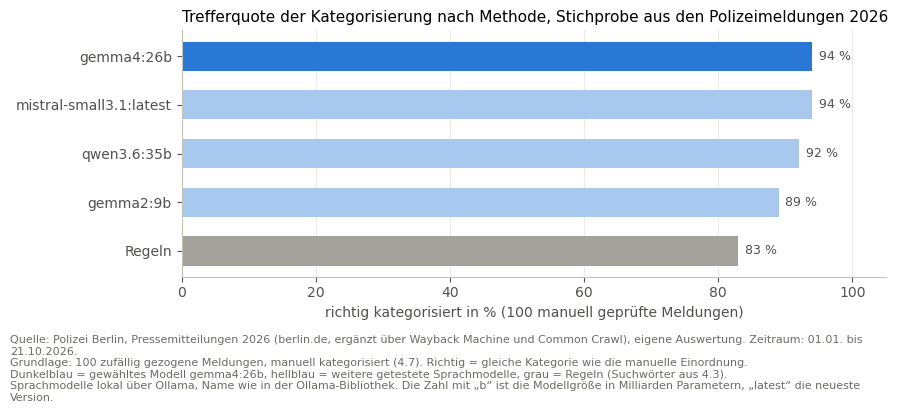

In [39]:
# Diagramm: Trefferquote jeder Methode gegen die manuelle Stichprobe
daten = modellvergleich.sort_values("richtig (%)")               # beste Methode oben
farben = ["#2a78d6" if m == MODELL else "#a3a29b" if m == "Regeln" else "#a9c8ee"
          for m in daten["Methode"]]                              # gewähltes Modell hervorheben

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(daten["Methode"], daten["richtig (%)"], height=0.6, color=farben)
for y, w in enumerate(daten["richtig (%)"]):                        # Werte direkt an die Balken
    ax.text(w + 1, y, f"{w:.0f} %", va="center", fontsize=9, color="#52514e")

ax.set_xlim(0, 105)
ax.set_xlabel(f"richtig kategorisiert in % ({len(manuell)} manuell geprüfte Meldungen)", color="#52514e")
ax.set_title("Trefferquote der Kategorisierung nach Methode, Stichprobe aus den Polizeimeldungen 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(manuell)} zufällig gezogene Meldungen, manuell kategorisiert (4.7). Richtig = gleiche Kategorie wie die manuelle Einordnung.",
         f"Dunkelblau = gewähltes Modell {MODELL}, hellblau = weitere getestete Sprachmodelle, grau = Regeln (Suchwörter aus 4.3).",
         "Sprachmodelle lokal über Ollama, Name wie in der Ollama-Bibliothek. Die Zahl mit „b“ ist die Modellgröße in Milliarden Parametern, „latest“ die neueste Version.")
plt.show()

#### Interpretation: Modellvergleich

- **Alle vier Modelle sind besser als die Regeln.** Die Regeln treffen 83 von 100 Meldungen, die Modelle 89 bis 94. Der Abstand zwischen den Modellen ist dagegen klein: Bei 100 Meldungen entspricht ein Prozentpunkt einer einzigen Meldung. Ob Gemma 4 und Mistral (94 %) wirklich besser sind als Qwen 3.6 (92 %), lässt sich mit dieser Stichprobe nicht belegen.
- **Der größte Gewinn liegt bei „Politisch motiviert“.** Die Regeln erkennen nur 4 der 13 politischen Meldungen, das Modell 12. Der Hinweis auf ein Motiv oder auf den Staatsschutz steht oft erst am Ende des Textes, die Regeln vergeben dann die Kategorie der Tat, zum Beispiel „Gewalt“ oder „Brand und Sachbeschädigung“.
- **Warum Gemma 4 gewählt wurde:** Gemma 4 und Mistral schneiden in der Stichprobe gleich ab. In den 28 der 254 Meldungen, in denen sich beide widersprechen, lag Gemma 4 bei manueller Durchsicht 9-mal klar richtig, Mistral 5-mal, der Rest sind Grenzfälle. Außerdem ist Gemma 4 mehr als dreimal so schnell (rund 5 statt 18 Sekunden pro Meldung). Erst dadurch ist der Lauf über alle 1.272 Meldungen in vertretbarer Zeit möglich.
- **Größe allein entscheidet nicht.** Gemma 4 (26B) ist ein Mixture-of-Experts-Modell und rechnet pro Wort nur mit rund 4 Milliarden seiner 25 Milliarden Parameter. Das erklärt, warum es schneller ist als das viel kleinere Gemma 2 (9B) und trotzdem genauer.
- **Bekannte Schwächen von Gemma 4:** Die Staatsschutz-Regel aus dem Prompt befolgt es nicht immer (27 von 30 solchen Meldungen unter den 254 richtig), und Schüsse durch die Polizei ordnet es teils als „Schusswaffen und OK“ ein, obwohl die Kategorie für Schüsse durch Täter gedacht ist.


### 4.8 Endgültige Kategorie und Speichern

Für die weitere Analyse gilt die Kategorie des Sprachmodells (Gemma 4), weil es in der Stichprobe deutlich besser abschneidet als die Regeln (94 % gegen 83 %). Fehlt eine LLM-Kategorie (Fehler im Lauf), wird die Regel verwendet. Die Spalte `kategorie_quelle` zeigt, woher die Kategorie stammt. Beide Einzelergebnisse bleiben in den Daten, damit der Vergleich jederzeit nachvollziehbar ist.

In [40]:
nutze_llm = df["kategorie_llm"].notna() & (df["kategorie_llm"] != "FEHLER")
df["kategorie"] = df["kategorie_llm"].where(nutze_llm, df["kategorie_regel"])
df["kategorie_quelle"] = nutze_llm.map({True: "llm", False: "regel"})

display(df["kategorie_quelle"].value_counts().to_frame("Meldungen"))

ziel = OUT_DIR / "meldungen_kategorisiert.csv"
df.to_csv(ziel, index=False, encoding="utf-8")
print("Gespeichert:", ziel, f"({len(df)} Zeilen, {df.shape[1]} Spalten)")

,Meldungen
kategorie_quelle,
llm,1272


Gespeichert: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/meldungen_kategorisiert.csv (1272 Zeilen, 35 Spalten)


### 4.9 Kategorien im Zeitverlauf

Zwei Blicke auf die Monate Januar bis Oktober:

1. **Gestapeltes Balkendiagramm:** alle Meldungen pro Monat, aufgeteilt nach der endgültigen Kategorie aus 4.8. Die sechs häufigsten Kategorien haben eine eigene Farbe, die übrigen sechs sind als „Weitere“ zusammengefasst, weil mehr Farben nicht mehr sicher zu unterscheiden sind.
2. **Kleine Liniendiagramme:** jede Kategorie in einem eigenen Feld, jeweils mit beiden Methoden. So wird sichtbar, ob Regeln und Sprachmodell nur im Niveau oder auch im Verlauf voneinander abweichen.

Beim Lesen beachten: Es sind Meldungen, keine Fallzahlen. Der Oktober ist nur bis zum 21.10. erfasst, und die Abdeckung schwankt je Monat zwischen 82 und 96 % (siehe 2.8).

kategorie_grob,Verkehr,Gewalt,Politisch motiviert,Raub und Diebstahl,Schusswaffen und OK,Brand und Sachbeschädigung,Weitere,gesamt
monat,,,,,,,,
2026-01,28,7,10,20,14,11,19,109
2026-02,26,11,11,17,13,11,10,99
2026-03,33,26,13,17,12,11,14,126
2026-04,27,23,12,18,13,12,12,117
2026-05,35,35,19,15,19,6,15,144
2026-06,39,33,10,13,15,8,19,137
2026-07,33,24,18,19,20,5,13,132
2026-08,28,22,30,12,14,8,19,133
2026-09,36,18,34,22,20,12,24,166


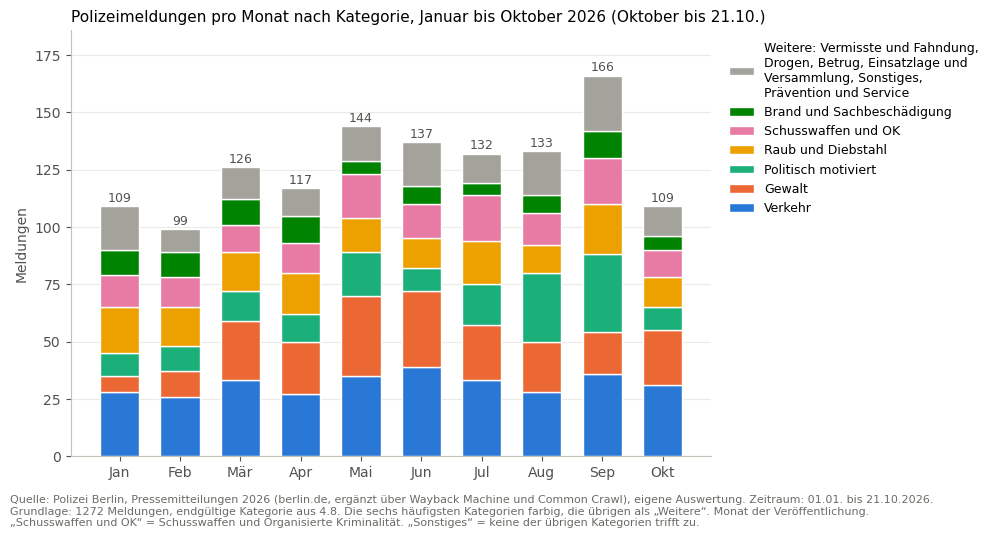

In [41]:
# Gestapeltes Balkendiagramm: Meldungen pro Monat nach Kategorie (endgültige Kategorie aus 4.8)
MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
# feste Farbreihenfolge; mehr als sechs Farben sind schwer zu unterscheiden,
# deshalb werden die kleinen Kategorien zu "Weitere" zusammengefasst
FARBEN = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GRAU = "#a3a29b"

grosse = df["kategorie"].value_counts().index[:len(FARBEN)].tolist()   # die sechs häufigsten
df["kategorie_grob"] = df["kategorie"].where(df["kategorie"].isin(grosse), "Weitere")

pro_monat_kat = (
    df.groupby(["monat", "kategorie_grob"]).size()
      .unstack(fill_value=0)[grosse + ["Weitere"]]                   # Reihenfolge = Stapelfolge
)
display(pro_monat_kat.assign(gesamt=pro_monat_kat.sum(axis=1)))

fig, ax = plt.subplots(figsize=(10, 5))
labels = [MONATE[int(m[5:7]) - 1] for m in pro_monat_kat.index]
unten = pd.Series(0, index=pro_monat_kat.index)
kleine = [k for k in df["kategorie"].value_counts().index if k not in grosse]          # was in "Weitere" steckt
legende = {k: k for k in grosse} | {"Weitere": textwrap.fill("Weitere: " + ", ".join(kleine), 32)}
for kat, farbe in zip(pro_monat_kat.columns, FARBEN + [GRAU]):
    ax.bar(labels, pro_monat_kat[kat], bottom=unten, color=farbe, width=0.65,
           edgecolor="white", linewidth=1, label=legende[kat])
    unten += pro_monat_kat[kat]
for x, summe in zip(labels, unten):                                   # Monatssumme über dem Balken
    ax.text(x, summe + 2, str(summe), ha="center", fontsize=9, color="#52514e")

ax.set_ylim(0, unten.max() * 1.12)
ax.set_ylabel("Meldungen", color="#52514e")
ax.set_title("Polizeimeldungen pro Monat nach Kategorie, Januar bis Oktober 2026 (Oktober bis 21.10.)",
             loc="left", fontsize=11)
handles, namen = ax.get_legend_handles_labels()
ax.legend(handles[::-1], namen[::-1], frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=9)                                                 # Legende in Stapelfolge, oben = oben
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(df)} Meldungen, endgültige Kategorie aus 4.8. Die sechs häufigsten Kategorien farbig, die übrigen als „Weitere“. Monat der Veröffentlichung.",
         BEGRIFF_KATEGORIE)
plt.show()

#### Interpretation: Meldungen pro Monat

- **Zwischen 99 und 166 Meldungen pro Monat.** Am wenigsten sind es im Februar, am meisten im September. Weil die Abdeckung in allen Monaten über 80 % liegt, sind diese Unterschiede nicht nur Lücken in den Daten.
- **Verkehr ist in fast allen Monaten die größte Kategorie** und bleibt mit 26 bis 39 Meldungen pro Monat stabil. Nur im August liegt „Politisch motiviert“ vorn (30 zu 28), im Mai sind Verkehr und Gewalt gleichauf (je 35).
- **Gewalt steigt im Frühjahr deutlich.** Im Januar und Februar sind es nur 7 und 11 Meldungen, von März bis August jeweils über 20, mit dem Höchststand im Mai (35) und Juni (33).
- **Politisch motiviert erreicht im August (30) und September (34) fast das Dreifache des Frühjahrs.** Grund ist vor allem der Wahlkampf zur Abgeordnetenhauswahl: Von den 64 politischen Meldungen dieser beiden Monate nennen 23 schon im Titel Wahlplakate oder die Wahl, dazu kommen Angriffe an Infoständen und mehrere queerfeindliche Angriffe. Im Oktober fällt der Wert auf 10 zurück. Auch der Juli liegt mit 18 höher, in diesen Monat fällt der Anschlag im Umfeld des CSD.
- **Brand und Sachbeschädigung ist von Mai bis August niedrig** (5 bis 8 Meldungen). Beschädigte Wahlplakate zählen hier nicht mit, weil sie als politisch motiviert eingeordnet sind.

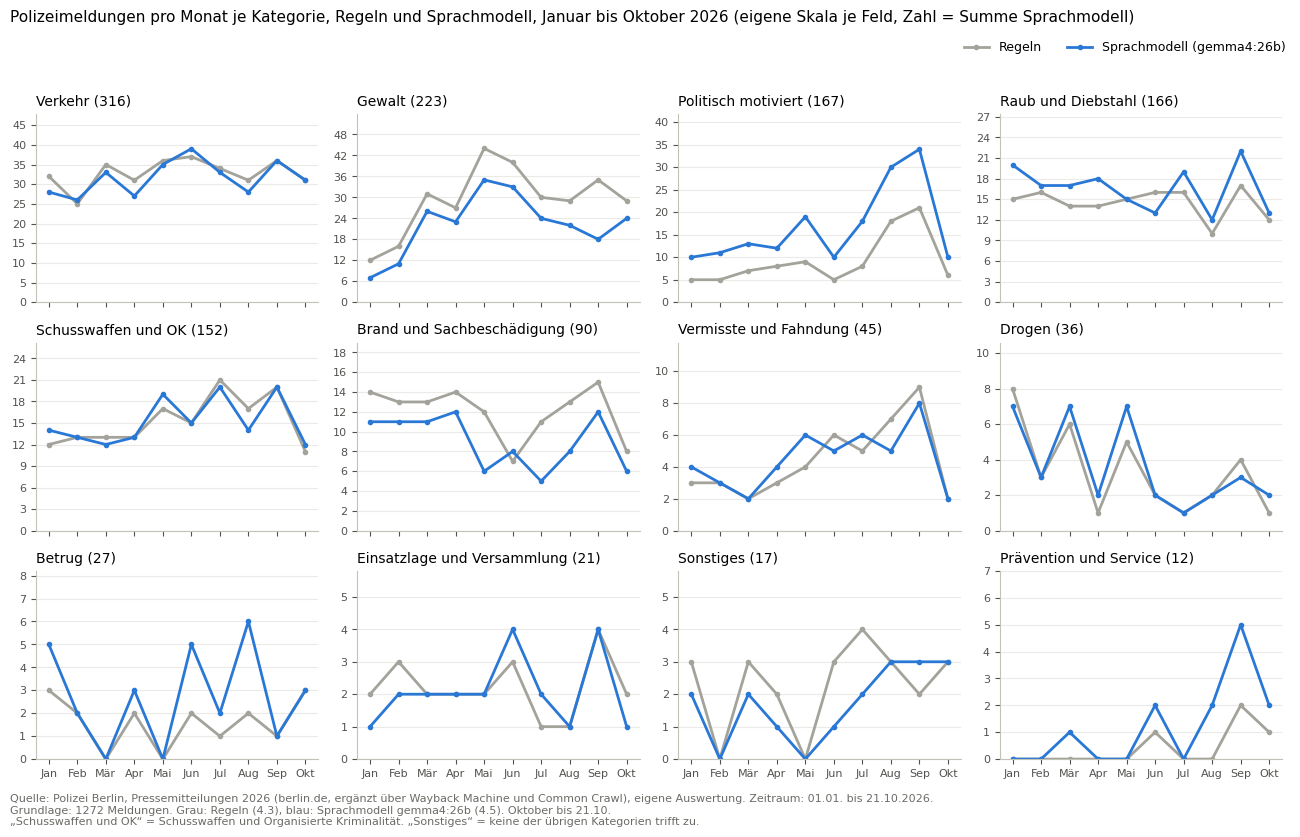

In [42]:
# Kleine Liniendiagramme: jede Kategorie einzeln, Regeln und Sprachmodell im Vergleich
from matplotlib.ticker import MaxNLocator
monate = sorted(df["monat"].unique())
labels = [MONATE[int(m[5:7]) - 1] for m in monate]
regel_monat = df.groupby(["kategorie_regel", "monat"]).size().unstack(fill_value=0).reindex(columns=monate, fill_value=0)
llm_monat = df.groupby(["kategorie", "monat"]).size().unstack(fill_value=0).reindex(columns=monate, fill_value=0)
reihenfolge = df["kategorie"].value_counts().index                   # häufigste Kategorie zuerst

fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True)
for ax, kat in zip(axes.flat, reihenfolge):
    r = regel_monat.reindex([kat], fill_value=0).iloc[0]
    l = llm_monat.reindex([kat], fill_value=0).iloc[0]
    ax.plot(labels, r.values, color=GRAU, linewidth=2, marker="o", markersize=3, label="Regeln")
    ax.plot(labels, l.values, color="#2a78d6", linewidth=2, marker="o", markersize=3,
            label=f"Sprachmodell ({MODELL})")
    ax.set_title(f"{kat} ({l.sum()})", loc="left", fontsize=10)
    ax.set_ylim(0, max(r.max(), l.max()) * 1.2 + 1)                    # jede Kategorie mit eigener Skala
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))               # nur ganze Zahlen
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8)
    ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
for ax in axes.flat[len(reihenfolge):]:                                # leere Felder ausblenden
    ax.set_visible(False)

handles, namen = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, namen, loc="upper right", bbox_to_anchor=(1, 0.955), frameon=False, ncol=2, fontsize=9)   # unter dem Titel
fig.suptitle("Polizeimeldungen pro Monat je Kategorie, Regeln und Sprachmodell, Januar bis Oktober 2026 (eigene Skala je Feld, Zahl = Summe Sprachmodell)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.93))
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(df)} Meldungen. Grau: Regeln (4.3), blau: Sprachmodell {MODELL} (4.5). Oktober bis 21.10.",
         BEGRIFF_KATEGORIE)
plt.show()

#### Interpretation: Regeln und Sprachmodell je Kategorie

- **Fast deckungsgleich** sind beide Linien bei Verkehr, Schusswaffen und OK, Drogen sowie Vermisste und Fahndung. Hier reichen die Schlagwörter aus.
- **Gewalt liegt nach den Regeln in jedem Monat höher, Politisch motiviert in jedem Monat niedriger.** Der Abstand ist im August und September am größten (Regeln 18 und 21, Sprachmodell 30 und 34): Bei Angriffen auf Wahlkampfhelfer oder Infostände zählen die Regeln die Tat, das Sprachmodell das Motiv.
- **Brand und Sachbeschädigung liegt nach den Regeln fast immer höher**, am deutlichsten im Mai und Juli.
- **Kleine Kategorien sind nicht deutbar.** Betrug, Einsatzlage und Versammlung, Sonstiges sowie Prävention und Service haben höchstens 6 Meldungen pro Monat. Ausschläge dort entstehen durch einzelne Meldungen.
- **Folge:** Der Jahresverlauf ist bei beiden Methoden ähnlich, das Niveau einzelner Kategorien hängt aber von der Methode ab. Die weitere Analyse verwendet die Kategorie des Sprachmodells (4.8).

## 5. Zeitlicher Verlauf und große Ereignisse

Leitfrage 2: Wie verändert sich die Zahl der Meldungen im Jahresverlauf, und erzeugen große Ereignisse sichtbare Spitzen? Abschnitt 4.9 hat die Monate gezeigt. Dieser Abschnitt geht feiner vor, nach Wochen und Tagen, prüft vier Ereignisse einzeln und zeigt weitere Themen, die das ganze Jahr vorkommen:

| Nr. | Unterabschnitt |
|---|---|
| 5.1 | Daten laden und Ereignisse festlegen |
| 5.2 | Meldungen pro Tag |
| 5.3 | Die Tage mit den meisten Meldungen |
| 5.4 | Die vier Ereignisse in den Meldungen |
| 5.5 | Wahlkampf im Wochenverlauf |
| 5.6 | Wann die Polizei veröffentlicht |
| 5.7 | Weitere Themen: Nahost, Extremismus, Rassismus, Versammlungen, Messer |
| 5.8 | Gewalt gegen Polizei |

### 5.1 Daten laden und Ereignisse festlegen

Grundlage ist die Datei aus 4.8 mit der endgültigen Kategorie. Die vier Ereignisse stammen aus den Leitfragen. Ihr Datum ist mit einer Quelle belegt, bei drei Ereignissen mit der Polizeimeldung selbst.

In [43]:
import re

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(OUT_DIR / "meldungen_kategorisiert.csv", parse_dates=["datum_zeit", "datum"])
print(len(df), "Meldungen geladen,", df["datum"].min().date(), "bis", df["datum"].max().date())

# Die vier großen Ereignisse aus den Leitfragen, mit Datum und Beleg
EREIGNISSE = pd.DataFrame([
    {"ereignis": "Brandanschlag auf Stromkabel", "datum": "2026-01-03",
     "beleg": "Polizeimeldung Nr. 12 vom 04.01.2026 („gestern früh“)"},
    {"ereignis": "1. Mai", "datum": "2026-05-01",
     "beleg": "Polizeimeldung Nr. 490 vom 02.05.2026"},
    {"ereignis": "Anschlag im Umfeld des CSD", "datum": "2026-07-25",
     "beleg": "Polizeimeldung Nr. 906 vom 26.07.2026 („am 25.07.2026“)"},
    {"ereignis": "Wahl zum Abgeordnetenhaus", "datum": "2026-09-20",
     "beleg": "berlin.de, Wahlamt: Berlinwahl 20.09.2026"},
])
EREIGNISSE["datum"] = pd.to_datetime(EREIGNISSE["datum"])
EREIGNISSE

1272 Meldungen geladen, 2026-01-01 bis 2026-10-21


,ereignis,datum,beleg
0,Brandanschlag auf Stromkabel,2026-01-03,Polizeimeldung Nr. 12 vom 04.01.2026 („gestern früh“)
1,1. Mai,2026-05-01,Polizeimeldung Nr. 490 vom 02.05.2026
2,Anschlag im Umfeld des CSD,2026-07-25,Polizeimeldung Nr. 906 vom 26.07.2026 („am 25.07.2026“)
3,Wahl zum Abgeordnetenhaus,2026-09-20,"berlin.de, Wahlamt: Berlinwahl 20.09.2026"


### 5.2 Meldungen pro Tag

Die helle Linie zeigt die Meldungen jedes einzelnen Tages, auch Tage ohne Meldung. Weil die Tageswerte stark schwanken, zeigt die dunkle Linie zusätzlich den Durchschnitt über 7 Tage (der Tag selbst, drei Tage davor und drei danach).

Tage: 294, Durchschnitt 4.3 Meldungen pro Tag, Minimum 0, Maximum 13, Tage ohne Meldung: 5
Tage ohne Meldung: 03.01., 05.04., 26.06., 25.07., 05.08.
01.01. bis 30.04.: 3.8 Meldungen pro Tag
01.05. bis 31.07.: 4.5 Meldungen pro Tag
01.08. bis 21.10.: 5.0 Meldungen pro Tag
Tiefster 7-Tage-Durchschnitt: 2.1 am 06.01.
Brandanschlag auf Stromkabel: 0 Meldungen am 03.01., 2 am Tag danach (7-Tage-Durchschnitt am Rand des Zeitraums nicht berechnet)
1. Mai: 5 Meldungen am 01.05., 6 am Tag danach, 7-Tage-Durchschnitt 4.6
Anschlag im Umfeld des CSD: 0 Meldungen am 25.07., 1 am Tag danach, 7-Tage-Durchschnitt 4.3
Wahl zum Abgeordnetenhaus: 6 Meldungen am 20.09., 7 am Tag danach, 7-Tage-Durchschnitt 6.1


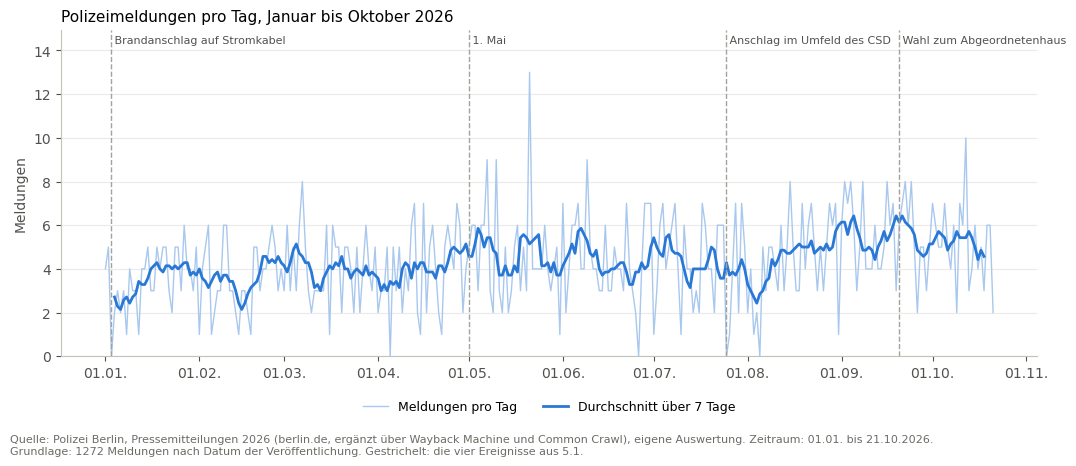

In [44]:
# Meldungen pro Tag, dazu der Durchschnitt über 7 Tage; große Ereignisse als senkrechte Linien
alle_tage = pd.date_range(df["datum"].min(), df["datum"].max(), freq="D")
pro_tag = df.groupby("datum").size().reindex(alle_tage, fill_value=0)   # Tage ohne Meldung = 0
schnitt_7 = pro_tag.rolling(7, center=True).mean()                        # gleitender Durchschnitt
print(f"Tage: {len(pro_tag)}, Durchschnitt {pro_tag.mean():.1f} Meldungen pro Tag, "
      f"Minimum {pro_tag.min()}, Maximum {pro_tag.max()}, Tage ohne Meldung: {(pro_tag == 0).sum()}")
print("Tage ohne Meldung:", ", ".join(pro_tag[pro_tag == 0].index.strftime("%d.%m.")))
for von, bis in [("2026-01-01", "2026-04-30"), ("2026-05-01", "2026-07-31"), ("2026-08-01", "2026-10-21")]:
    print(f"{pd.Timestamp(von):%d.%m.} bis {pd.Timestamp(bis):%d.%m.}: {pro_tag[von:bis].mean():.1f} Meldungen pro Tag")
print(f"Tiefster 7-Tage-Durchschnitt: {schnitt_7.min():.1f} am {schnitt_7.idxmin():%d.%m.}")
for _, e in EREIGNISSE.iterrows():                                        # Meldungen am Tag des Ereignisses und am Tag danach
    tag0 = pd.Timestamp(e["datum"]).normalize()
    print(f"{e['ereignis']}: {pro_tag.get(tag0, 0)} Meldungen am {tag0:%d.%m.}, {pro_tag.get(tag0 + pd.Timedelta(days=1), 0)} am Tag danach, "
          f"7-Tage-Durchschnitt {schnitt_7[tag0]:.1f}" if pd.notna(schnitt_7.get(tag0)) else
          f"{e['ereignis']}: {pro_tag.get(tag0, 0)} Meldungen am {tag0:%d.%m.}, {pro_tag.get(tag0 + pd.Timedelta(days=1), 0)} am Tag danach "
          f"(7-Tage-Durchschnitt am Rand des Zeitraums nicht berechnet)")

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(pro_tag.index, pro_tag.values, color="#a9c8ee", linewidth=1, label="Meldungen pro Tag")
ax.plot(schnitt_7.index, schnitt_7.values, color="#2a78d6", linewidth=2, label="Durchschnitt über 7 Tage")
for _, e in EREIGNISSE.iterrows():                                        # Ereignisse markieren
    ax.axvline(e["datum"], color="#a3a29b", linestyle="--", linewidth=1)
    ax.text(e["datum"], pro_tag.max() * 1.13, " " + e["ereignis"], fontsize=8, color="#52514e",
            ha="left", va="top")

ax.set_ylim(0, pro_tag.max() * 1.15)
ax.set_ylabel("Meldungen", color="#52514e")
ax.set_title("Polizeimeldungen pro Tag, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m."))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(df)} Meldungen nach Datum der Veröffentlichung. Gestrichelt: die vier Ereignisse aus 5.1.")
plt.show()

#### Interpretation: Meldungen pro Tag

- **Im Schnitt 4,3 Meldungen pro Tag**, an einzelnen Tagen zwischen 0 und 13.
- **Die Zahl steigt über das Jahr.** Von Januar bis April sind es 3,8 Meldungen pro Tag, von Mai bis Juli 4,5 und von August bis Oktober 5,0. An der Datenlage liegt das nicht, denn die Abdeckung ist im August und September sogar am niedrigsten (2.8). Warum die Polizei in der zweiten Jahreshälfte mehr veröffentlicht, lässt sich aus den Daten nicht ablesen.
- **Die großen Ereignisse erzeugen keine Spitzen.** Am 1. Mai gibt es 5 Meldungen und am Tag danach 6, kaum mehr als im Durchschnitt. Am Tag des CSD-Anschlags (Samstag, 25.07.) gibt es keine einzige Meldung, am Tag danach eine. Nach dem Brandanschlag am 03.01. erreicht der 7-Tage-Durchschnitt am 06.01. mit 2,1 seinen tiefsten Wert im ganzen Jahr. Rund um die Wahl liegt er bei gut 6 Meldungen pro Tag, so hoch wie Anfang September.
- **Fünf Tage ohne Meldung.** Am 03.01. und am 26.06. fehlen Meldungsnummern, dort liegt wahrscheinlich eine Lücke in den Daten. Am 05.04. (Ostersonntag), am 25.07. und am 05.08. fehlt keine Nummer, die Polizei hat an diesen Tagen also nichts veröffentlicht.
- **Folge:** Die Polizei veröffentlicht ungefähr gleich viel, egal was in der Stadt passiert. Große Lagen zeigen sich nicht in der Menge der Meldungen, sondern höchstens im Inhalt. Das prüfen 5.4 und 5.5.


### 5.3 Die Tage mit den meisten Meldungen

Die Tabelle zeigt die zehn stärksten Tage mit der häufigsten Kategorie und prüft, ob ein Tag bis zu drei Tage nach einem der vier Ereignisse liegt. Bei Gleichstand zeigt `haeufigste_kategorie` nur eine der gleich häufigen Kategorien.

In [45]:
# Die zehn Tage mit den meisten Meldungen und was an diesen Tagen gemeldet wurde
# pro_tag aus 5.2: alle Kalendertage, auch Tage ohne Meldung
print(f"Durchschnitt: {pro_tag.mean():.1f} Meldungen pro Tag, Median {pro_tag.median():.0f}")

top_tage = (
    df.groupby("datum")
      .agg(meldungen=("meldung_id", "size"),
           wochentag=("wochentag", "first"),
           haeufigste_kategorie=("kategorie", lambda s: s.value_counts().index[0]),
           davon_politisch=("kategorie", lambda s: (s == "Politisch motiviert").sum()))
      .sort_values("meldungen", ascending=False)
      .head(10)
)
# Liegt ein Spitzentag nahe an einem der vier Ereignisse (bis 3 Tage danach)?
top_tage["nahe_ereignis"] = [
    any(0 <= (tag - e).days <= 3 for e in EREIGNISSE["datum"]) for tag in top_tage.index
]
top_tage.index = top_tage.index.strftime("%d.%m.%Y")
top_tage

Durchschnitt: 4.3 Meldungen pro Tag, Median 4


,meldungen,wochentag,haeufigste_kategorie,davon_politisch,nahe_ereignis
datum,,,,,
21.05.2026,13,Do,Politisch motiviert,4,False
12.10.2026,10,Mo,Gewalt,0,False
09.06.2026,9,Di,Betrug,0,False
10.05.2026,9,So,Gewalt,1,False
07.05.2026,9,Do,Verkehr,0,False
15.08.2026,8,Sa,Verkehr,2,False
07.03.2026,8,Sa,Verkehr,2,False
02.09.2026,8,Mi,Verkehr,1,False
16.09.2026,8,Mi,Politisch motiviert,4,False


#### Interpretation: Spitzentage

- **Im Schnitt 4,3 Meldungen pro Tag**, der Median liegt bei 4. Der stärkste Tag ist der 21.05. mit 13 Meldungen.
- **Keiner der zehn Spitzentage liegt kurz nach einem der vier Ereignisse.**
- **Nur zwei Spitzentage haben einen klaren Schwerpunkt.** Am 21.05. sind 4 der 13 Meldungen politisch motiviert, darunter ein Angriff mit transphobem Hintergrund am Alexanderplatz und ein homophober Angriff. Am 16.09., vier Tage vor der Wahl, sind es ebenfalls 4, darunter drei Angriffe an Infoständen von Parteien.
- An den übrigen Spitzentagen mischen sich Verkehr, Gewalt und andere Kategorien ohne gemeinsamen Anlass.

### 5.4 Die vier Ereignisse in den Meldungen

Für jedes Ereignis werden die Meldungen in einem Zeitraum rund um das Datum nach passenden Suchwörtern durchsucht, in Titel und Text. Der Zeitraum ist bei Ereignissen mit Vorlauf (1. Mai, Wahl) eine Woche davor und danach, bei Anschlägen vier Wochen danach.

In [46]:
# Welche Meldungen beziehen sich auf die vier Ereignisse?
# Suchwörter in Titel und Text, nur im Zeitraum rund um das Ereignis
BEZUG = {
    "Brandanschlag auf Stromkabel": (r"Stromausfall|Stromnetz|Starkstromkabel", 0, 28),
    "1. Mai":                       (r"1\. Mai", -7, 7),
    "Anschlag im Umfeld des CSD":   (r"Christopher Street|\bCSD\b", 0, 28),
    "Wahl zum Abgeordnetenhaus":    (r"Wahl|Partei|Info-?stand|Informationsstand|Abgeordnete", -7, 7),
}
# (Suchwörter, Tage vor dem Ereignis, Tage danach)

zeilen, treffer_liste = [], []
for _, e in EREIGNISSE.iterrows():
    muster, vor, nach = BEZUG[e["ereignis"]]
    fenster = df[(df["datum"] >= e["datum"] + pd.Timedelta(days=vor)) &
                 (df["datum"] <= e["datum"] + pd.Timedelta(days=nach))]
    treffer = fenster[(fenster["titel"] + " " + fenster["text"]).str.contains(muster, case=False, regex=True)]
    zeilen.append({"Ereignis": e["ereignis"], "Datum": e["datum"].strftime("%d.%m.%Y"),
                   "Zeitraum (Tage)": f"{vor} bis +{nach}",
                   "Meldungen im Zeitraum": len(fenster), "davon mit Bezug": len(treffer)})
    treffer_liste.append(treffer.assign(ereignis=e["ereignis"]))

display(pd.DataFrame(zeilen))
pd.concat(treffer_liste)[["ereignis", "datum", "nr", "kategorie", "titel"]] \
  .assign(datum=lambda d: d["datum"].dt.strftime("%d.%m.")).reset_index(drop=True)

,Ereignis,Datum,Zeitraum (Tage),Meldungen im Zeitraum,davon mit Bezug
0,Brandanschlag auf Stromkabel,03.01.2026,0 bis +28,100,3
1,1. Mai,01.05.2026,-7 bis +7,78,2
2,Anschlag im Umfeld des CSD,25.07.2026,0 bis +28,117,1
3,Wahl zum Abgeordnetenhaus,20.09.2026,-7 bis +7,84,7


,ereignis,datum,nr,kategorie,titel
0,Brandanschlag auf Stromkabel,04.01.,12,Politisch motiviert,Starkstromkabel angezündet – Zeuginnen und Zeugen gesucht
1,Brandanschlag auf Stromkabel,05.01.,15,Raub und Diebstahl,Einbruchsversuch - Festnahmen
2,Brandanschlag auf Stromkabel,06.01.,18,Betrug,Trickdiebstahl bei Seniorin
3,1. Mai,24.04.,447,Einsatzlage und Versammlung,Allgemeinverfügung zum 1. Mai 2026 – Einschränkungen im Bereich Treptower Park
4,1. Mai,02.05.,490,Einsatzlage und Versammlung,Polizei Berlin zieht Bilanz zur Versammlungslage am 1. Mai 2026
5,Anschlag im Umfeld des CSD,26.07.,906,Politisch motiviert,Anschlag im Umfeld des Christopher Street Day - Tatverdächtiger bei Polizeie...
6,Wahl zum Abgeordnetenhaus,14.09.,1180,Politisch motiviert,Wahlplakat und E-Scooter angezündet
7,Wahl zum Abgeordnetenhaus,16.09.,1189,Politisch motiviert,Abgeordneter an Partei-Infostand angegangen
8,Wahl zum Abgeordnetenhaus,16.09.,1190,Politisch motiviert,Frau an einem Informationsstand einer Partei angegriffen
9,Wahl zum Abgeordnetenhaus,16.09.,1194,Politisch motiviert,Sachbeschädigungen an Wahlplakaten im Zusammenhang mit der Wahl zum Abgeordn...


#### Interpretation: die vier Ereignisse

- **Brandanschlag auf die Stromkabel (03.01.): 3 Meldungen.** Eine Meldung berichtet direkt über den Anschlag in Lichterfelde und den „großflächigen Stromausfall“, der Staatsschutz ermittelt. Eine zweite beschreibt einen Einbruchsversuch, den eine Einsatzhundertschaft bei der Streife „im vom Stromausfall betroffenen Gebiet“ verhindert hat, also eine Folge der Lage. Die dritte ist ein Trickdiebstahl in Prenzlauer Berg, bei dem sich die Täter als Mitarbeiter des Stromnetzes ausgaben. Ein Zusammenhang mit dem Anschlag ist dort nicht belegt.
- **1. Mai: 2 Meldungen**, die Allgemeinverfügung vorher und die Bilanz danach. Die Bilanz fasst mehr als 90 Versammlungen mit über 70.000 Teilnehmenden und über 5.300 Einsatzkräften in einer einzigen Meldung zusammen. Vorfälle aus dem Versammlungsgeschehen erscheinen nicht als eigene Meldung, sondern nur gesammelt in der Bilanz.
- **Anschlag im Umfeld des CSD (25.07.): 1 Meldung** im Datensatz, über den Tod des Tatverdächtigen bei einem Polizeieinsatz am Tag danach. Die erste Meldung mit der Öffentlichkeitsfahndung (Nr. 905) fehlt in den Daten, ihr Text ist aber in Nr. 906 enthalten.
- **Wahl zum Abgeordnetenhaus (20.09.): 7 Meldungen**, alle in der Woche vor der Wahl, keine am Wahltag oder danach.
- **Folge:** Gerade die großen Ereignisse sind in den Polizeimeldungen kaum sichtbar, oft mit nur einer oder zwei Meldungen. Ob die Polizei über solche Lagen auf anderen Wegen informiert hat, etwa über soziale Medien, zeigen diese Daten nicht. Für das Lagebild sind deshalb die Medien in Abschnitt 7 wichtig.

### 5.5 Wahlkampf im Wochenverlauf

Anders als die einzelnen Ereignisse zieht sich der Wahlkampf über Wochen. Gezählt werden alle Meldungen mit Wahlbezug über das ganze Jahr, also Meldungen zu Wahlplakaten, Infoständen, Parteibüros oder Abgeordneten. Das Diagramm zeigt die Wochen ab Juli, weil vorher fast nichts passiert. Jede Woche ist nach ihrem Montag benannt.

Meldungen mit Wahlbezug: 41
davon als 'Politisch motiviert' kategorisiert: 41
Januar bis Juni zusammen: 8


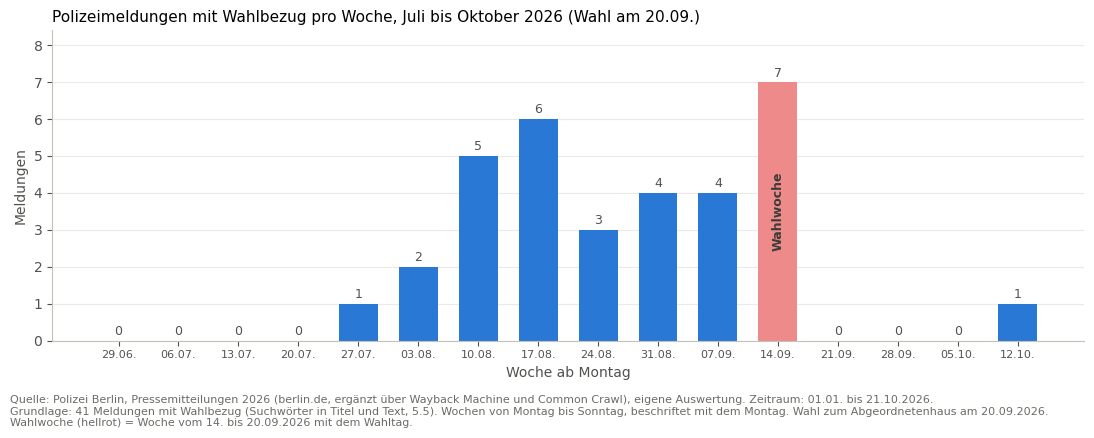

In [47]:
# Meldungen mit Wahlbezug pro Woche
WAHL = (r"Wahlplakat|Wahlkampf|Wahlkreisbüro|Wahl zum Abgeordnetenhaus|Info-?stand|Informationsstand|"
        r"Parteibüro|Geschäftsstelle einer Partei|Parteimitglied|Politiker|Abgeordnete")
df["wahlbezug"] = (df["titel"] + " " + df["text"]).str.contains(WAHL, case=False, regex=True)
wahltag = EREIGNISSE.loc[EREIGNISSE["ereignis"] == "Wahl zum Abgeordnetenhaus", "datum"].iloc[0]
wahl = df[df["wahlbezug"]]
print("Meldungen mit Wahlbezug:", len(wahl))
print("davon als 'Politisch motiviert' kategorisiert:", (wahl["kategorie"] == "Politisch motiviert").sum())
print("Januar bis Juni zusammen:", (wahl["datum"] < "2026-07-01").sum())

# Wochen von Montag bis Sonntag, benannt nach dem Montag; gezeigt ab Juli, die letzte Woche (ab 19.10.) ist unvollständig
wahl_woche = wahl.set_index("datum").resample("W-MON", label="left", closed="left").size()
alle_wochen = pd.date_range("2026-06-29", "2026-10-12", freq="W-MON")
wahl_woche = wahl_woche.reindex(alle_wochen, fill_value=0)
labels = wahl_woche.index.strftime("%d.%m.")
wahlwoche = [d <= wahltag < d + pd.Timedelta(days=7) for d in wahl_woche.index]   # Woche mit dem Wahltag
farben = ["#ee8a89" if w else "#2a78d6" for w in wahlwoche]                      # Wahlwoche hellrot

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(labels, wahl_woche.values, color=farben, width=0.65)
for x, w, ist_wahl in zip(labels, wahl_woche.values, wahlwoche):     # Werte direkt an die Balken
    ax.text(x, w + 0.15, str(w), ha="center", fontsize=9, color="#52514e")
    if ist_wahl:                                                    # Beschriftung senkrecht im Balken
        ax.text(x, w / 2, "Wahlwoche", ha="center", va="center", rotation=90,
                fontsize=9, color="#3d3c39", fontweight="bold")
ax.set_ylim(0, wahl_woche.max() * 1.2)
ax.set_ylabel("Meldungen", color="#52514e")
ax.set_xlabel("Woche ab Montag", color="#52514e")
ax.set_title("Polizeimeldungen mit Wahlbezug pro Woche, Juli bis Oktober 2026 (Wahl am 20.09.)",
             loc="left", fontsize=11)
ax.tick_params(axis="x", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(wahl)} Meldungen mit Wahlbezug (Suchwörter in Titel und Text, 5.5). Wochen von Montag bis Sonntag, beschriftet mit dem Montag. Wahl zum Abgeordnetenhaus am 20.09.2026.",
         "Wahlwoche (hellrot) = Woche vom 14. bis 20.09.2026 mit dem Wahltag.")
plt.show()

#### Interpretation: Wahlkampf

- **41 Meldungen mit Wahlbezug**, alle von Gemma 4 als „Politisch motiviert“ eingeordnet.
- **Der Wahlkampf ist klar sichtbar.** Von Januar bis Juni gibt es zusammen nur 8 solche Meldungen, im Juli keine. Ab Anfang August steigt die Zahl, von Mitte August bis zur Wahl sind es 3 bis 7 pro Woche. Der Höchststand ist die Wahlwoche (14. bis 20.09.) mit 7.
- **Nach dem Wahltag endet das Thema fast sofort.** Bis zum 21.10. folgt nur noch eine Meldung.
- **Folge:** Anders als bei den einzelnen Ereignissen zeigt sich der Wahlkampf deutlich, weil er viele kleine Vorfälle erzeugt, über die die Polizei jeweils einzeln berichtet. Er erklärt einen großen Teil des Anstiegs der politisch motivierten Meldungen im August und September (4.9).

### 5.6 Wann die Polizei veröffentlicht

Datum und Uhrzeit in den Daten beziehen sich auf die **Veröffentlichung**, nicht auf die Tat. Die Uhrzeit ist nur bei den Meldungen aus dem Archiv bekannt (2.7), nach der Bereinigung sind das 985.

Meldungen mit Uhrzeit: 985, davon zwischen 9 und 17 Uhr: 95 %
Meldungen ohne Uhrzeit: 287 | erster Satz mit „gestern“, „gestrig“, „vergangenen Nacht“ oder „Nacht zu“: 940 von 1272 (74 %)


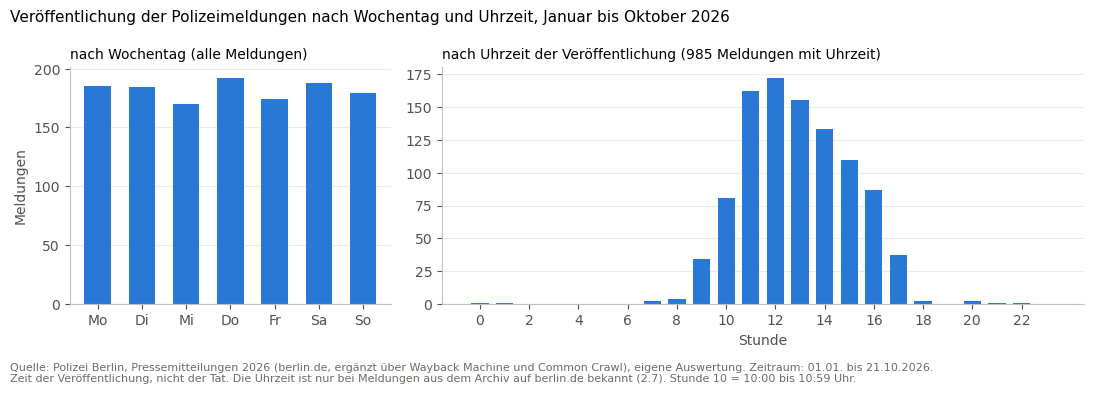

In [48]:
# Wann veröffentlicht die Polizei? Wochentag (alle Meldungen) und Uhrzeit (nur Meldungen mit bekannter Uhrzeit)
TAGE = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
pro_wochentag = df["wochentag"].value_counts().reindex(TAGE)
mit_uhrzeit = df[df["uhrzeit_bekannt"] == 1]
pro_stunde = mit_uhrzeit["stunde"].value_counts().reindex(range(24), fill_value=0)
anteil_buero = pro_stunde.loc[9:16].sum() / pro_stunde.sum() * 100
print(f"Meldungen mit Uhrzeit: {len(mit_uhrzeit)}, davon zwischen 9 und 17 Uhr: {anteil_buero:.0f} %")
# Tatzeit und Veröffentlichung: steht schon im ersten Satz, dass die Tat am Vortag oder in der Nacht war?
erster_satz = df["text"].fillna("").str.split(r"(?<=[.!?])\s", n=1, regex=True).str[0]
vortag = erster_satz.str.contains(r"gestern|gestrig|vergangenen Nacht|Nacht zu", case=False, regex=True)
print(f"Meldungen ohne Uhrzeit: {len(df) - len(mit_uhrzeit)} | erster Satz mit „gestern“, „gestrig“, "
      f"„vergangenen Nacht“ oder „Nacht zu“: {vortag.sum()} von {len(df)} ({vortag.mean() * 100:.0f} %)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
ax1.bar(TAGE, pro_wochentag.values, color="#2a78d6", width=0.6)
ax1.set_title("nach Wochentag (alle Meldungen)", loc="left", fontsize=10)
ax2.bar(pro_stunde.index, pro_stunde.values, color="#2a78d6", width=0.7)
ax2.set_title(f"nach Uhrzeit der Veröffentlichung ({len(mit_uhrzeit)} Meldungen mit Uhrzeit)",
              loc="left", fontsize=10)
ax2.set_xticks(range(0, 24, 2))
ax2.set_xlabel("Stunde", color="#52514e")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
ax1.set_ylabel("Meldungen", color="#52514e")
fig.suptitle("Veröffentlichung der Polizeimeldungen nach Wochentag und Uhrzeit, Januar bis Oktober 2026", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         "Zeit der Veröffentlichung, nicht der Tat. Die Uhrzeit ist nur bei Meldungen aus dem Archiv auf berlin.de bekannt (2.7). Stunde 10 = 10:00 bis 10:59 Uhr.")
plt.show()

#### Interpretation: Veröffentlichung

- **Die Polizei veröffentlicht an allen sieben Tagen gleich viel**, zwischen 170 und 192 Meldungen je Wochentag. Auch am Wochenende arbeitet die Pressestelle.
- **95 % der Meldungen erscheinen zwischen 9 und 17 Uhr**, die meisten um 12 Uhr. Das ist die Arbeitszeit der Pressestelle.
- **Folge:** Aus diesen Daten lässt sich nicht ablesen, wann in Berlin etwas passiert. In 74 % der Meldungen steht schon im ersten Satz „gestern“, „gestrig“, „in der vergangenen Nacht“ oder „in der Nacht zu“. Die Tat liegt also meist einen Tag vor der Veröffentlichung, ihre genaue Uhrzeit steht nur im Text.

### 5.7 Weitere Themen: Nahost, Extremismus, Rassismus, Versammlungen, Messer

Neben den vier Ereignissen gibt es Themen, die das ganze Jahr über vorkommen. Sie werden wie in 5.4 über Suchwörter in Titel und Text gefunden, „Messer“ kommt aus den Merkmalen in 4.4 und umfasst auch Macheten, Stichwaffen und Stichverletzungen. Jedes Thema sucht nach mehreren verwandten Wörtern und Wortformen, bei Queerfeindlichkeit zum Beispiel nach „homophob“, „transphob“, „queer“, „homosexuell“ und „Transperson“. Die vollständigen Listen stehen im Code. Eine Meldung kann zu mehreren Themen gehören, etwa ein antisemitischer Angriff mit Bezug zum Nahost-Konflikt.

**Zum Thema Terror:** Außer dem Anschlag im Umfeld des CSD enthalten die Meldungen 2026 keinen Terroranschlag in Berlin. Das Wort „terroristisch“ erscheint sonst nur als juristischer Begriff („Verwenden von Kennzeichen verfassungswidriger und terroristischer Organisationen“), in 6 Meldungen über Versammlungen und Schmierereien. Nach dem CSD-Anschlag folgen 5 Meldungen über beschädigte Gedenkorte für die Opfer (eine Regenbogenbank und ein Gedenkbaum im Tiergarten).

**Zum Thema Linksextremismus:** Die Polizei nennt eine linke Ausrichtung in ihren Meldungen fast nie ausdrücklich. Nur 3 Meldungen enthalten solche Begriffe: zweimal „kommunistisch“ (Parolen an Hauswänden, eine Fahne bei einer nicht angemeldeten Versammlung) und einmal „linksextrem“ (Schriftzüge auf Wahlplakaten). Taten, die in der öffentlichen Debatte häufig der linken Szene zugeordnet werden, stehen in den Meldungen ohne diese Einordnung: der Brandanschlag auf Stromkabel in Lichterfelde (03.01.), die Durchsuchungen am 24.03. wegen „verfassungsfeindlicher Sabotage“ nach einem Anschlag auf Strommasten im September 2025 und die wiederkehrenden Angriffe auf Einsatzkräfte in der Rigaer Straße (siehe 6.5). Ob diese Taten linksextrem motiviert sind, sagen die Meldungen nicht. Das lässt sich nur mit anderen Quellen klären (Abschnitt 7).

monat,Jan,Feb,Mär,Apr,Mai,Jun,Jul,Aug,Sep,Okt,gesamt
Nahost-Konflikt,0,2,0,1,2,1,1,1,1,2,11
Antisemitismus,1,1,5,2,5,2,0,1,2,2,21
Rechtsextremismus,1,0,4,2,1,1,3,2,2,1,17
Linksextremismus,2,0,0,0,0,0,0,0,1,0,3
Rassismus,2,2,2,2,3,7,3,5,1,2,29
Queerfeindlichkeit,1,3,0,1,7,1,4,3,14,2,36
Versammlungen,2,4,2,0,2,3,2,1,4,2,22
Messer,10,12,24,21,20,21,24,16,14,13,175


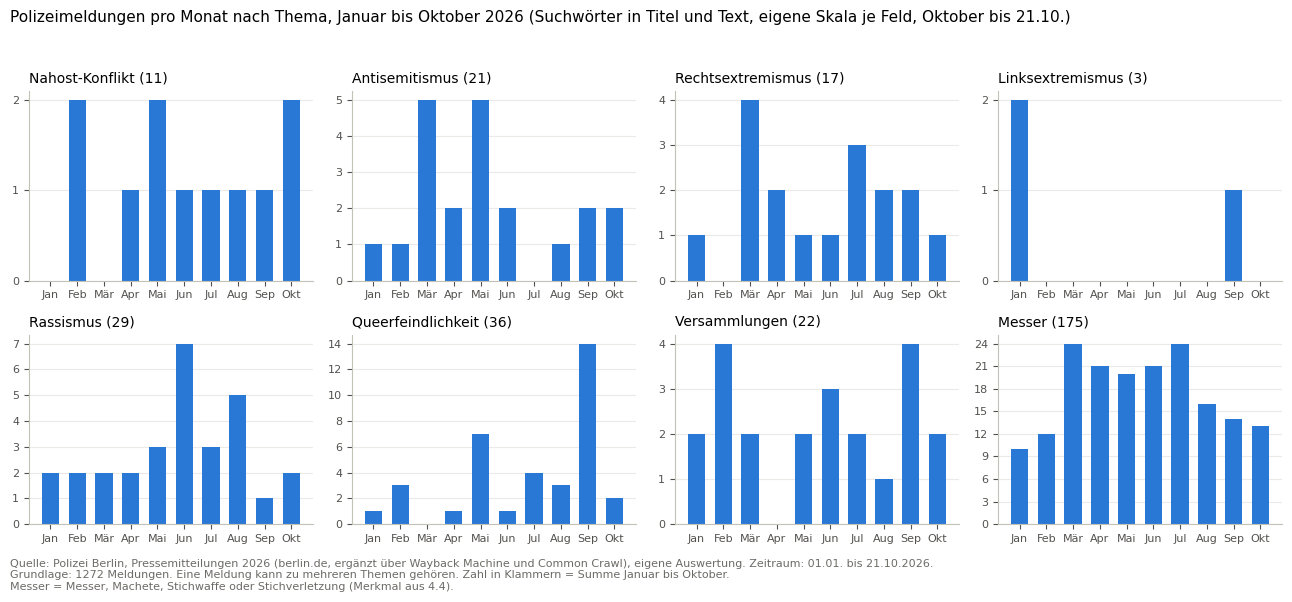

In [49]:
# Weitere Themen über Suchwörter in Titel und Text; eine Meldung kann zu mehreren Themen gehören
MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
THEMEN = {
    "Nahost-Konflikt":    r"Nahost|Palästin|Israel|Gaza|Hamas|Hisbollah",
    "Antisemitismus":     r"antisemit|Synagoge|Judenhass|jüdisch",
    "Rechtsextremismus":  (r"rechtsextrem|Hakenkreuz|Hitlergruß|rechte[nr]? Szene|SS-Rune|nationalsozialistisch motiviert|"
                           r"nationalsozialistische[n]? (?:Parole|Symbol|Äußerung)"),
    "Linksextremismus":   r"linksextrem|linksradikal|linke[nr]? Szene|kommunistisch|anarchist|antikapitalist",
    "Rassismus":          r"rassist|fremdenfeindlich|ausländerfeindlich|islamfeindlich|muslimfeindlich|antimuslim|Kopftuch",
    "Queerfeindlichkeit": (r"queer|homophob|homosexuell|schwul|lesbisch|bisexuell|transfeindlich|transphob|"
                           r"Transperson|Transfrau|Transmann|nicht-binär|sexuellen (?:Identität|Orientierung)|"
                           r"Regenbogen|Anschlags? auf den (?:Berliner )?CSD"),         # inkl. Gedenkorte für den CSD-Anschlag
    "Versammlungen":      r"Versammlung(?:en)?\b|Versammlungsgeschehen|Versammlungslage|Demonstration|Kundgebung",
}
volltext = df["titel"] + " " + df["text"]
for thema, muster in THEMEN.items():
    df[thema] = volltext.str.contains(muster, case=False, regex=True)
df["Messer"] = df["messer"]                                    # Merkmal aus 4.4
themen = list(THEMEN) + ["Messer"]

monat_thema = df.groupby("monat")[themen].sum().astype(int)
display(monat_thema.T.assign(gesamt=monat_thema.sum()).rename(
    columns=lambda m: MONATE[int(m[5:7]) - 1] if m != "gesamt" else m))

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharex=True)
labels = [MONATE[int(m[5:7]) - 1] for m in monat_thema.index]
for ax, thema in zip(axes.flat, themen):
    werte = monat_thema[thema]
    ax.bar(labels, werte.values, color="#2a78d6", width=0.65)
    ax.set_title(f"{thema} ({werte.sum()})", loc="left", fontsize=10)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8, labelbottom=True)    # Monate in jedem Feld
    ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
for ax in axes.flat[len(themen):]:                               # leere Felder ausblenden
    ax.set_visible(False)
fig.suptitle("Polizeimeldungen pro Monat nach Thema, Januar bis Oktober 2026 (Suchwörter in Titel und Text, eigene Skala je Feld, Oktober bis 21.10.)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.95))
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(df)} Meldungen. Eine Meldung kann zu mehreren Themen gehören. Zahl in Klammern = Summe Januar bis Oktober.",
         BEGRIFF_MESSER)
plt.show()

#### Interpretation: weitere Themen

- **Die meisten Themen sind selten.** Bis auf Messer, Queerfeindlichkeit und Rassismus kommen sie auf höchstens 5 Meldungen pro Monat. Einzelne Ausschläge entstehen dort durch wenige Meldungen und sind kein Trend.
- **Queerfeindlichkeit (36) ist nach dem Wahlkampf (41, siehe 5.5) das häufigste politische Thema**, mit dem Höchststand im September (14). Davon sind 10 Angriffe, Bedrohungen oder Beleidigungen und 4 Beschädigungen von Gedenkorten für den CSD-Anschlag (dreimal die Regenbogenbank, einmal ein Gedenkbaum). Im Mai sind es 7 Meldungen.
- **Antisemitismus (21)** verteilt sich über das ganze Jahr, mit je 5 Meldungen im März und Mai, darunter Schmierereien an Gedenkorten und einer Synagoge. Rund um den Jahrestag des 7. Oktober gibt es keine Häufung.
- **Nahost-Konflikt (11):** höchstens 2 Meldungen pro Monat, vor allem Versammlungen, Schmierereien und einzelne Angriffe. Die größte Lage ist der 7. Oktober 2026 mit mehr als 1.100 Einsatzkräften, acht pro-israelischen und zwei pro-palästinensischen Versammlungen, alles in einer einzigen Meldung.
- **Rechtsextremismus (17):** vor allem Hitlergruß und Hakenkreuz-Schmierereien, mit dem Höchststand im März (4).
- **Linksextremismus (3):** Nur drei Meldungen nennen eine linke Ausrichtung ausdrücklich (siehe Einleitung). Die Zahl zeigt vor allem, wie selten die Polizei diese Einordnung vornimmt, nicht wie oft solche Taten vorkommen.
- **Rassismus (29):** rassistische und fremdenfeindliche Beleidigungen und Angriffe, auch gegen Frauen mit Kopftuch. Der Höchststand liegt im Juni (7). Alle Meldungen bis auf eine hat Gemma 4 als politisch motiviert eingeordnet.
- **Versammlungen (22):** Die Polizei meldet Versammlungen meist als Bilanz in einer einzigen Meldung, auch bei sehr großen Lagen. Die Versammlung gegen die Wehrpflicht am 25.09. hatte in der Spitze rund 3.400 Teilnehmende.
- **Messer (175)** ist das mit Abstand häufigste Thema. Von März bis Juli kommt ein Messer oder eine Stichwaffe in 14 bis 19 % der Meldungen vor, im Januar in 9 % und im September in 8 %.

### 5.8 Gewalt gegen Polizei

Gewalt gegen Polizeikräfte verteilt sich auf viele Kategorien, etwa „Gewalt“, „Verkehr“ oder „Politisch motiviert“. Deshalb sucht Python sie hier eigens, Satz für Satz in Titel und Text, und beantwortet drei Fragen: wie viele, wo und in welchem Zusammenhang.

Gezählt wird eine Meldung, wenn mindestens eines davon zutrifft:

- **tätlicher Angriff** (§ 114 StGB), so wie die Polizei den Tatbestand selbst nennt
- **Polizeikräfte als Ziel**: angegriffen, bedroht, bespuckt, beworfen, gebissen, getreten, geschlagen
- **verletzte Polizeikräfte**, aber nicht bei Verkehrsunfällen und nicht bei Sätzen wie „wurden nicht verletzt“

**Widerstand** (§ 113 StGB) wird getrennt gezählt. Er umfasst auch Fälle, in denen sich jemand nur gegen die Festnahme sperrt.

,Meldungen
tätlicher Angriff (§ 114 StGB),39
"Polizei angegriffen, bedroht, bespuckt usw.",45
Polizeikräfte verletzt (ohne Verkehrsunfälle),37
Gewalt gegen Polizei (mindestens eines davon),80
"Widerstand (§ 113 StGB), zum Vergleich",84
Gewalt gegen Polizei oder Widerstand,114


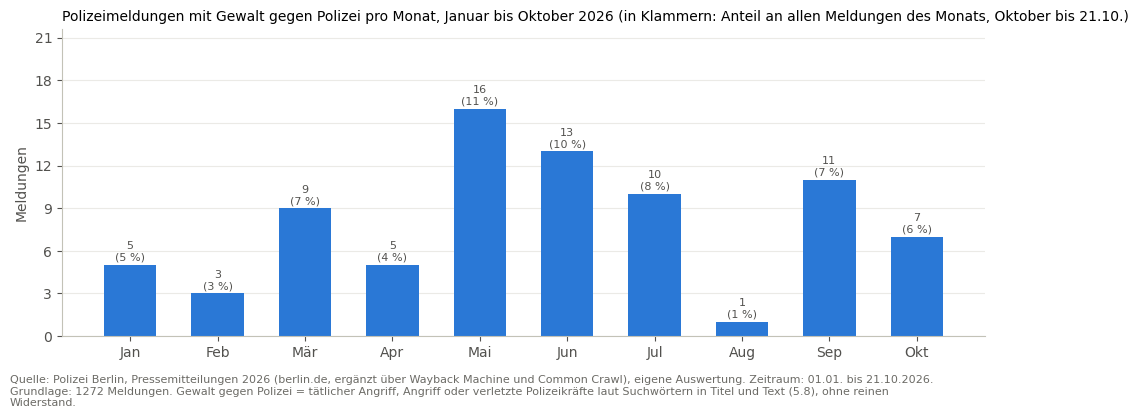

In [50]:
# Gewalt gegen Polizei: Python sucht in Titel und Text, Satz für Satz
KONTAKT = re.compile(r"[^.]*(?:entgegen|Rufnummer|Telefonnummer|Internetwache|\(030\))[^.]*\.")
POLIZEI = r"(?:Polizist\w*|Polizeibeamt\w*|Beamt\w*|Einsatzkr\w*|Dienstkr\w*|Polizeikr\w*|Zivilfahnd\w*|Funkwagenbesatzung)"
TAETLICH = re.compile(r"tätliche[nr]? Angriff\w*", re.I)                     # § 114 StGB
WIDERSTAND = re.compile(r"Widerstand(?:es|s)?\b(?!skämpf)|Widerstandshandlung\w*", re.I)   # § 113 StGB
ANGRIFF = re.compile(                                                         # Polizei als Ziel eines Angriffs
    rf"{POLIZEI}\s+(?:\w+\s+){{0,4}}(?:angegriffen|attackiert|bespuckt|angespuckt|bedroht|beworfen|beschossen|gebissen|getreten|geschlagen)\b"
    rf"|\b(?:griff\w*|attackiert\w*|bespuckt\w*|bedroht\w*|bewarf\w*|beschoss\w*|schlug|trat|biss)\s+(?:\w+\s+){{0,5}}{POLIZEI}", re.I)
VERLETZT = re.compile(rf"{POLIZEI}[^.]{{0,60}}?\bverletzt\b", re.I)
KEIN_ANGRIFF = re.compile(r"\bnicht\b|\bkein\w*|unverletzt|Unfall|Zusammenstoß|kollidier|verunglückt", re.I)


def polizei_verletzt(titel: str, text: str) -> bool:
    """Ein Satz nennt verletzte Polizeikräfte, ohne Verneinung und ohne Verkehrsunfall."""
    if re.search(r"Unfall|verunglückt", titel, re.I):
        return False
    return any(VERLETZT.search(s) and not KEIN_ANGRIFF.search(s) for s in re.split(r"(?<=\.)\s+", text))


texte = (df["titel"] + ". " + df["text"]).str.replace(KONTAKT, " ", regex=True)
df["pol_taetlich"] = texte.str.contains(TAETLICH)
df["pol_angriff"] = texte.str.contains(ANGRIFF)
df["pol_verletzt"] = [polizei_verletzt(t, x) for t, x in zip(df["titel"], texte)]
df["pol_widerstand"] = texte.str.contains(WIDERSTAND)
df["gewalt_gegen_polizei"] = df["pol_taetlich"] | df["pol_angriff"] | df["pol_verletzt"]

uebersicht = pd.Series({
    "tätlicher Angriff (§ 114 StGB)": df["pol_taetlich"].sum(),
    "Polizei angegriffen, bedroht, bespuckt usw.": df["pol_angriff"].sum(),
    "Polizeikräfte verletzt (ohne Verkehrsunfälle)": df["pol_verletzt"].sum(),
    "Gewalt gegen Polizei (mindestens eines davon)": df["gewalt_gegen_polizei"].sum(),
    "Widerstand (§ 113 StGB), zum Vergleich": df["pol_widerstand"].sum(),
    "Gewalt gegen Polizei oder Widerstand": (df["gewalt_gegen_polizei"] | df["pol_widerstand"]).sum(),
}, name="Meldungen")
display(uebersicht.to_frame())

# Pro Monat: Anteil an allen Meldungen des Monats
pol_monat = df.groupby("monat").agg(meldungen=("meldung_id", "size"), gewalt=("gewalt_gegen_polizei", "sum"))
pol_monat["anteil_%"] = (pol_monat["gewalt"] / pol_monat["meldungen"] * 100).round(1)
labels = [MONATE[int(m[5:7]) - 1] for m in pol_monat.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(labels, pol_monat["gewalt"], color="#2a78d6", width=0.6)
for x, w, a in zip(labels, pol_monat["gewalt"], pol_monat["anteil_%"]):
    ax.text(x, w + 0.3, f"{w}\n({a:.0f} %)", ha="center", fontsize=8, color="#52514e")
ax.set_ylim(0, pol_monat["gewalt"].max() * 1.35)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Meldungen", color="#52514e")
ax.set_title("Polizeimeldungen mit Gewalt gegen Polizei pro Monat, Januar bis Oktober 2026 (in Klammern: Anteil an allen Meldungen des Monats, Oktober bis 21.10.)",
             loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(df)} Meldungen. Gewalt gegen Polizei = tätlicher Angriff, Angriff oder verletzte Polizeikräfte laut Suchwörtern in Titel und Text (5.8), ohne reinen Widerstand.")
plt.show()

In [51]:
# Wo und in welchem Zusammenhang?
pol = df[df["gewalt_gegen_polizei"]].copy()
pol_texte = texte[pol.index]

# Wo: Bezirk, im Vergleich zum Anteil des Bezirks an allen Meldungen
wo = pd.DataFrame({
    "Gewalt gegen Polizei": pol["bezirk"].fillna("ohne einzelnen Bezirk").value_counts(),
    "alle Meldungen": df["bezirk"].fillna("ohne einzelnen Bezirk").value_counts(),
}).fillna(0).astype(int)
wo["Anteil an allen Meldungen des Bezirks %"] = (wo["Gewalt gegen Polizei"] / wo["alle Meldungen"] * 100).round(1)
display(wo.sort_values("Gewalt gegen Polizei", ascending=False))

# Zusammenhang: Suchwörter im Text, eine Meldung kann mehrere Zusammenhänge haben
ZUSAMMENHANG = {
    "bei einer Festnahme": r"Festnahme|festgenommen|festnehmen",
    "Verkehrskontrolle oder Flucht mit dem Auto": (r"Verkehrskontrolle|Fahrzeugkontrolle|Fahrzeugüberprüfung|Polizeikontrolle|"
                                                   r"flücht\w*[^.]{0,40}(?:Auto|Fahrzeug|Pkw|Wagen)"),
    "psychischer Ausnahmezustand": r"psychisch\w* Ausnahme",
    "Alkohol": r"alkoholisiert|Atemalkohol|Alkoholeinfluss",
    "Versammlung, Fußball oder Großlage": r"Versammlung|Demonstration|Kundgebung|Fußball|Stadion|Silvester",
    "aus einer Gruppe heraus": r"Personengruppe|aus einer Gruppe|Gruppe von|mehrere[n]? Personen",
    "Polizei setzt Distanzelektroimpulsgerät (DEIG) ein": r"Distanzelektroimpulsgerät|Distanz-Elektroimpulsgerät|\bDEIG\b",
}
zusammenhang = pd.Series({k: pol_texte.str.contains(m, case=False, regex=True).sum() for k, m in ZUSAMMENHANG.items()},
                         name="Meldungen").sort_values(ascending=False)
display(zusammenhang.to_frame().assign(**{"Anteil %": lambda d: (d["Meldungen"] / len(pol) * 100).round(0)}))

print("Kategorie dieser Meldungen (Gemma 4):")
print(pol["kategorie"].value_counts().to_string())

,Gewalt gegen Polizei,alle Meldungen,Anteil an allen Meldungen des Bezirks %
bezirk,,,
Friedrichshain-Kreuzberg,19,141,13.5
Mitte,10,161,6.2
ohne einzelnen Bezirk,9,103,8.7
Charlottenburg-Wilmersdorf,8,106,7.5
Spandau,6,71,8.5
Treptow-Köpenick,5,85,5.9
Neukölln,5,110,4.5
Tempelhof-Schöneberg,5,113,4.4
Marzahn-Hellersdorf,3,84,3.6


,Meldungen,Anteil %
bei einer Festnahme,51,64.0
Polizei setzt Distanzelektroimpulsgerät (DEIG) ein,17,21.0
Alkohol,14,18.0
aus einer Gruppe heraus,14,18.0
"Versammlung, Fußball oder Großlage",10,12.0
Verkehrskontrolle oder Flucht mit dem Auto,8,10.0
psychischer Ausnahmezustand,5,6.0


Kategorie dieser Meldungen (Gemma 4):
kategorie
Gewalt                         39
Verkehr                        10
Politisch motiviert             9
Einsatzlage und Versammlung     7
Drogen                          5
Schusswaffen und OK             4
Raub und Diebstahl              4
Vermisste und Fahndung          1
Sonstiges                       1


#### Interpretation: Gewalt gegen Polizei

- **80 Meldungen berichten von Gewalt gegen Polizeikräfte**, das sind 6 % aller Meldungen. Dazu kommen Meldungen, die nur Widerstand nennen. Gewalt oder Widerstand zusammen kommen in 114 Meldungen vor (9 %).
- **Wann:** am meisten im Mai (16) und Juni (13), am wenigsten im August (1).
- **Wo:** In Friedrichshain-Kreuzberg betrifft fast jede siebte Meldung Gewalt gegen Polizei (19 von 141, 13,5 %), mehr als doppelt so oft wie in Mitte (6,2 %). Am seltensten ist es in Steglitz-Zehlendorf (2,7 %).
- **Zusammenhang:**
  - Zwei Drittel der Fälle passieren bei einer Festnahme (64 %).
  - In jeder fünften Meldung setzt die Polizei danach ein Distanzelektroimpulsgerät ein (21 %).
  - Alkohol (18 %) und Angriffe aus einer Gruppe heraus (18 %) kommen häufig vor.
  - Seltener sind Versammlungen, Fußball und Großlagen (12 %), Verkehrskontrollen oder Fluchten mit dem Auto (10 %) und ein psychischer Ausnahmezustand (6 %).
- **Nur knapp die Hälfte dieser Meldungen steht in der Kategorie „Gewalt“** (39 von 80). Die übrigen verteilen sich vor allem auf Verkehr (10) und Politisch motiviert (9). Ohne diese eigene Suche wäre das Thema im Lagebild kaum sichtbar.
- **Gezählt werden Meldungen, nicht verletzte Beamte.** Eine Bilanz wie nach einem Fußballspiel fasst oft viele Angriffe in einer Meldung zusammen.

## 6. Bezirke, Orte und Karte

Leitfrage 3: Welche Bezirke und Orte kommen in den Meldungen besonders häufig vor? Der Abschnitt geht vom Bezirk bis zur einzelnen Straße.

| Nr. | Unterabschnitt |
|---|---|
| 6.1 | Daten laden |
| 6.2 | Meldungen pro Bezirk |
| 6.3 | Kategorien je Bezirk |
| 6.4 | Orte aus dem Text |
| 6.5 | Kriminalitätsbelastete Orte |
| 6.6 | Koordinaten der Orte |
| 6.7 | Karte |

**Voraussetzungen:** Die Abschnitte 6.5 bis 6.7 brauchen Internet (berlin.de, OpenStreetMap, Geodatenportal Berlin) und die Pakete `folium` und `adjustText` (`pip install folium adjustText`). adjustText verschiebt die Ortsnamen auf der festen Karte so, dass sie sich nicht überdecken. Alle geladenen Daten werden gespeichert, beim nächsten Lauf kommen sie aus den Dateien.

### 6.1 Daten laden

Grundlage ist die Datei aus 4.8. Die Spalte `bezirk` stammt aus der Angabe „Ereignisort“ der Polizei (3.5).

In [52]:
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from matplotlib.colors import LinearSegmentedColormap
from tqdm import tqdm

df = pd.read_csv(OUT_DIR / "meldungen_kategorisiert.csv", parse_dates=["datum_zeit", "datum"])
MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
print(len(df), "Meldungen geladen")
print(df["ort_typ"].value_counts().to_string())

1272 Meldungen geladen
ort_typ
Bezirk          1169
berlinweit        83
überregional      18
unbekannt          2


### 6.2 Meldungen pro Bezirk

Gezählt werden nur Meldungen mit einem einzelnen Bezirk. Berlinweite und überregionale Meldungen fehlen hier.

Meldungen mit Bezirk: 1169 von 1272


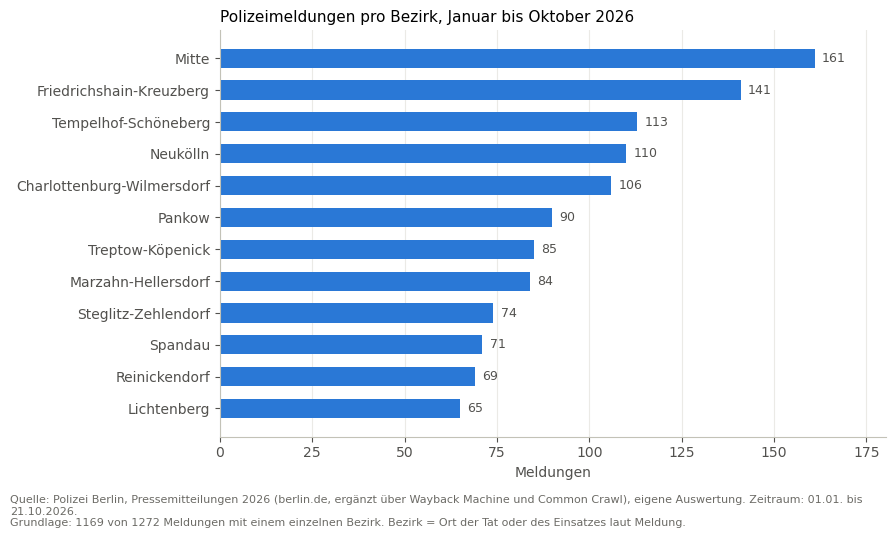

In [53]:
# Meldungen pro Bezirk (nur Meldungen mit einem einzelnen Bezirk)
pro_bezirk = df["bezirk"].value_counts().sort_values()               # kleinster Wert unten
print(f"Meldungen mit Bezirk: {pro_bezirk.sum()} von {len(df)}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(pro_bezirk.index, pro_bezirk.values, color="#2a78d6", height=0.6)
for y, w in enumerate(pro_bezirk.values):                             # Werte direkt an die Balken
    ax.text(w + 2, y, str(w), va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, pro_bezirk.max() * 1.12)
ax.set_xlabel("Meldungen", color="#52514e")
ax.set_title("Polizeimeldungen pro Bezirk, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {pro_bezirk.sum()} von {len(df)} Meldungen mit einem einzelnen Bezirk. Bezirk = Ort der Tat oder des Einsatzes laut Meldung.")
plt.show()

#### Interpretation: Bezirke

- **Mitte (161) und Friedrichshain-Kreuzberg (141) liegen vorn**, Lichtenberg (65) hat die wenigsten Meldungen. Mitte kommt damit auf rund zweieinhalbmal so viele Meldungen wie Lichtenberg.
- **Die Zahlen sind hier noch nicht pro Einwohner gerechnet.** Das folgt im nächsten Schritt.
- Wie im ganzen Notebook gilt: Es sind veröffentlichte Meldungen, keine Fallzahlen.

#### Meldungen je 100.000 Einwohner

Große Bezirke haben schon wegen ihrer Einwohnerzahl mehr Meldungen. Deshalb wird die Zahl der Meldungen hier durch die Einwohnerzahl geteilt. Die Einwohnerzahlen stammen aus dem Statistischen Bericht A I 5 (hj 1/26) des Amts für Statistik Berlin-Brandenburg (Tabelle 3, Stichtag 30.06.2026). Die Datei liegt unter `data/raw/SB_A01-05-00_2026h01_BE.xlsx`. Python sucht die Bezirke und den letzten Stichtag in der Tabelle selbst.

Stichtag der Einwohnerzahl: 30.06.2026. Berlin: 3.917.196 | Summe der 12 Bezirke: 3.917.196
Berlin insgesamt: 29.8 Meldungen mit Bezirk je 100.000 Einwohner


,Meldungen,Einwohner,je 100.000 Einwohner,Rang Meldungen,Rang je Einwohner
Friedrichshain-Kreuzberg,141,292066,48.3,2,1
Mitte,161,398505,40.4,1,2
Neukölln,110,331744,33.2,4,3
Tempelhof-Schöneberg,113,358125,31.6,3,4
Charlottenburg-Wilmersdorf,106,342638,30.9,5,5
Marzahn-Hellersdorf,84,297570,28.2,8,6
Treptow-Köpenick,85,305168,27.9,7,7
Spandau,71,263683,26.9,10,8
Reinickendorf,69,270735,25.5,11,9
Steglitz-Zehlendorf,74,309084,23.9,9,10


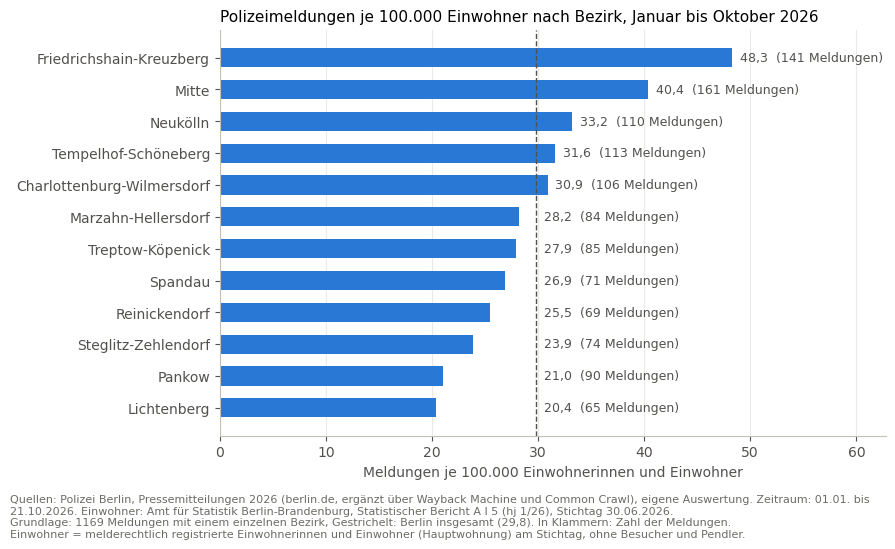

In [54]:
# Meldungen je 100.000 Einwohnerinnen und Einwohner
# Einwohnerzahl je Bezirk: Amt für Statistik Berlin-Brandenburg, Statistischer Bericht A I 5 (hj 1/26),
# Tabelle 3 (Einwohnerinnen und Einwohner nach Bezirken), Block „insgesamt“, letzter Stichtag
EINWOHNER_DATEI = ROOT / "data" / "raw" / "SB_A01-05-00_2026h01_BE.xlsx"
roh = pd.read_excel(EINWOHNER_DATEI, sheet_name="T3 T4", header=None)


def schluessel(name) -> str:
    """Nur Buchstaben, klein: „Friedrichs-\\nhain-\\nKreuz-\\nberg“ und „Friedrichshain-Kreuzberg“ werden gleich."""
    return re.sub(r"[^a-zäöüß]", "", str(name).lower())


# Python sucht die Kopfzeile (beginnt mit „Stichtag“) und den Block „insgesamt“ selbst
kopf = roh.index[roh[0].astype(str).str.strip() == "Stichtag"][0]
spalte = {schluessel(roh.iat[kopf, j]): j for j in range(roh.shape[1]) if pd.notna(roh.iat[kopf, j])}
start = roh.index[roh.apply(lambda z: z.astype(str).str.strip().str.lower().eq("insgesamt").any(), axis=1)][0]
zeilen = []
for i in range(start + 1, len(roh)):                                   # Datumszeilen bis zum Ende des Blocks
    if pd.isna(pd.to_datetime(roh.iat[i, 0], errors="coerce")):
        break
    zeilen.append(i)
letzte = max(zeilen, key=lambda i: pd.to_datetime(roh.iat[i, 0]))
STICHTAG = pd.to_datetime(roh.iat[letzte, 0])

fehlen = [b for b in pro_bezirk.index if schluessel(b) not in spalte]
assert not fehlen, f"Bezirke nicht in der Tabelle gefunden: {fehlen}"
einwohner = pd.Series({b: int(roh.iat[letzte, spalte[schluessel(b)]]) for b in pro_bezirk.index})
berlin = int(roh.iat[letzte, spalte["berlin"]])
print(f"Stichtag der Einwohnerzahl: {STICHTAG:%d.%m.%Y}, Berlin: {berlin:,}".replace(",", "."),
      f"| Summe der 12 Bezirke: {einwohner.sum():,}".replace(",", "."))

je_einwohner = pd.DataFrame({"Meldungen": pro_bezirk, "Einwohner": einwohner})
je_einwohner["je 100.000 Einwohner"] = (je_einwohner["Meldungen"] / je_einwohner["Einwohner"] * 100_000).round(1)
je_einwohner["Rang Meldungen"] = je_einwohner["Meldungen"].rank(ascending=False, method="min").astype(int)
je_einwohner["Rang je Einwohner"] = je_einwohner["je 100.000 Einwohner"].rank(ascending=False, method="min").astype(int)
je_einwohner = je_einwohner.sort_values("je 100.000 Einwohner", ascending=False)
gesamt_je = pro_bezirk.sum() / berlin * 100_000
print(f"Berlin insgesamt: {gesamt_je:.1f} Meldungen mit Bezirk je 100.000 Einwohner")
display(je_einwohner)

daten = je_einwohner.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(daten.index, daten["je 100.000 Einwohner"], color="#2a78d6", height=0.6)
ax.axvline(gesamt_je, color="#52514e", linewidth=1, linestyle="--")
for y, (w, n) in enumerate(zip(daten["je 100.000 Einwohner"], daten["Meldungen"])):   # Text nie auf der Linie
    ax.text(max(w, gesamt_je) + daten["je 100.000 Einwohner"].max() * 0.015, y, f"{w:.1f}".replace(".", ",") + f"  ({n} Meldungen)",
            va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, daten["je 100.000 Einwohner"].max() * 1.3)
ax.set_xlabel("Meldungen je 100.000 Einwohnerinnen und Einwohner", color="#52514e")
ax.set_title("Polizeimeldungen je 100.000 Einwohner nach Bezirk, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}. "
         f"Einwohner: Amt für Statistik Berlin-Brandenburg, Statistischer Bericht A I 5 (hj 1/26), Stichtag {STICHTAG:%d.%m.%Y}.",
         f"Grundlage: {pro_bezirk.sum()} Meldungen mit einem einzelnen Bezirk. Gestrichelt: Berlin insgesamt "
         f"({gesamt_je:.1f}".replace(".", ",") + "). In Klammern: Zahl der Meldungen.",
         "Einwohner = melderechtlich registrierte Einwohnerinnen und Einwohner (Hauptwohnung) am Stichtag, ohne Besucher und Pendler.")
(ROOT / "images").mkdir(exist_ok=True)                                  # Bild für die README
fig.savefig(ROOT / "images" / "meldungen_je_einwohner.png", dpi=150, bbox_inches="tight")
plt.show()


#### Interpretation: Meldungen je Einwohner

- **Je Einwohner liegt Friedrichshain-Kreuzberg vorn** mit 48,3 Meldungen je 100.000 Einwohner, vor Mitte (40,4). Berlin insgesamt kommt auf 29,8. Friedrichshain-Kreuzberg hat damit mehr als doppelt so viele Meldungen je Einwohner wie Lichtenberg (20,4).
- **Pankow fällt am stärksten zurück:** Nach der Zahl der Meldungen steht es auf Rang 6 (90 Meldungen), je Einwohner auf Rang 11 (21,0). Pankow ist mit 428.973 Einwohnern der größte Bezirk.
- **Aufgestiegen sind Marzahn-Hellersdorf** (von Rang 8 auf 6), Spandau (10 auf 8) und Reinickendorf (11 auf 9).
- **Vorsicht bei Mitte und Friedrichshain-Kreuzberg:** Dort sind viele Besucher, Pendler und Nachtleben. Die Meldungen betreffen also nicht nur die Menschen, die dort wohnen. Je Einwohner gerechnet wirken diese Bezirke deshalb höher belastet, als sie es für die Bewohner sind.
- Wie im ganzen Notebook gilt: Es sind veröffentlichte Meldungen, keine Fallzahlen. Die Einwohnerzahl gilt für den 30.06.2026, also für die Mitte des Zeitraums.

#### Bevölkerung nach Staatsangehörigkeit und Migrationshintergrund

Hier steht neben den Meldungen je Einwohner, wie sich die Bevölkerung jedes Bezirks zusammensetzt: Deutsche ohne Migrationshintergrund, Deutsche mit Migrationshintergrund und Ausländerinnen und Ausländer. Die Zahlen stammen aus Tabelle 7 derselben Einwohner-Datei (Stichtag 30.06.2026). Python sucht die Spalten und Bezirke selbst und prüft, ob die Teile die Summen ergeben.

**Wichtig vor dem Lesen:** Der Vergleich beschreibt Bezirke, nicht Menschen. Er zeigt, in welchem Umfeld Meldungen veröffentlicht werden, aber nicht, wer Taten begeht oder Opfer wird. Polizeimeldungen nennen die Herkunft von Beteiligten nur selten, und viele Beteiligte wohnen gar nicht im Bezirk. Für die Staatsangehörigkeit von Tatverdächtigen ist die Polizeiliche Kriminalstatistik (PKS) die richtige Quelle.

Weil es nur 12 Bezirke sind, misst ein Zufallstest, wie oft eine zufällige Zuordnung der Bezirke einen mindestens so starken Zusammenhang ergibt (p). Die Rechnung läuft einmal mit allen Bezirken und einmal ohne die beiden Bezirke mit den meisten Meldungen je Einwohner.

Tabelle 7 gelesen, Summen geprüft, Einwohner gleich wie in Tabelle 3.


,je 100.000 Einwohner,Rang je Einwohner,Deutsche ohne Migrationshintergrund %,Deutsche mit Migrationshintergrund %,Ausländerinnen und Ausländer %,mit Migrationshintergrund zusammen %
Friedrichshain-Kreuzberg,48.3,1,49.3,20.5,30.2,50.7
Mitte,40.4,2,40.4,23.0,36.6,59.6
Neukölln,33.2,3,46.9,24.4,28.7,53.1
Tempelhof-Schöneberg,31.6,4,56.0,20.8,23.2,44.0
Charlottenburg-Wilmersdorf,30.9,5,52.5,21.0,26.5,47.5
Marzahn-Hellersdorf,28.2,6,67.9,11.7,20.4,32.1
Treptow-Köpenick,27.9,7,71.5,10.4,18.1,28.5
Spandau,26.9,8,51.8,20.9,27.3,48.2
Reinickendorf,25.5,9,57.7,19.4,22.8,42.3
Steglitz-Zehlendorf,23.9,10,65.8,16.7,17.5,34.2


,Anteil,Bezirke,Spearman,Zufallstest p
0,Deutsche ohne Migrationshintergrund,alle 12 Bezirke,-0.69,0.02
1,Deutsche ohne Migrationshintergrund,ohne Friedrichshain-Kreuzberg und Mitte,-0.50,0.14
2,Deutsche mit Migrationshintergrund,alle 12 Bezirke,0.59,0.05
3,Deutsche mit Migrationshintergrund,ohne Friedrichshain-Kreuzberg und Mitte,0.50,0.14
4,Ausländerinnen und Ausländer,alle 12 Bezirke,0.67,0.02
5,Ausländerinnen und Ausländer,ohne Friedrichshain-Kreuzberg und Mitte,0.44,0.20
6,mit Migrationshintergrund zusammen,alle 12 Bezirke,0.69,0.02
7,mit Migrationshintergrund zusammen,ohne Friedrichshain-Kreuzberg und Mitte,0.50,0.14


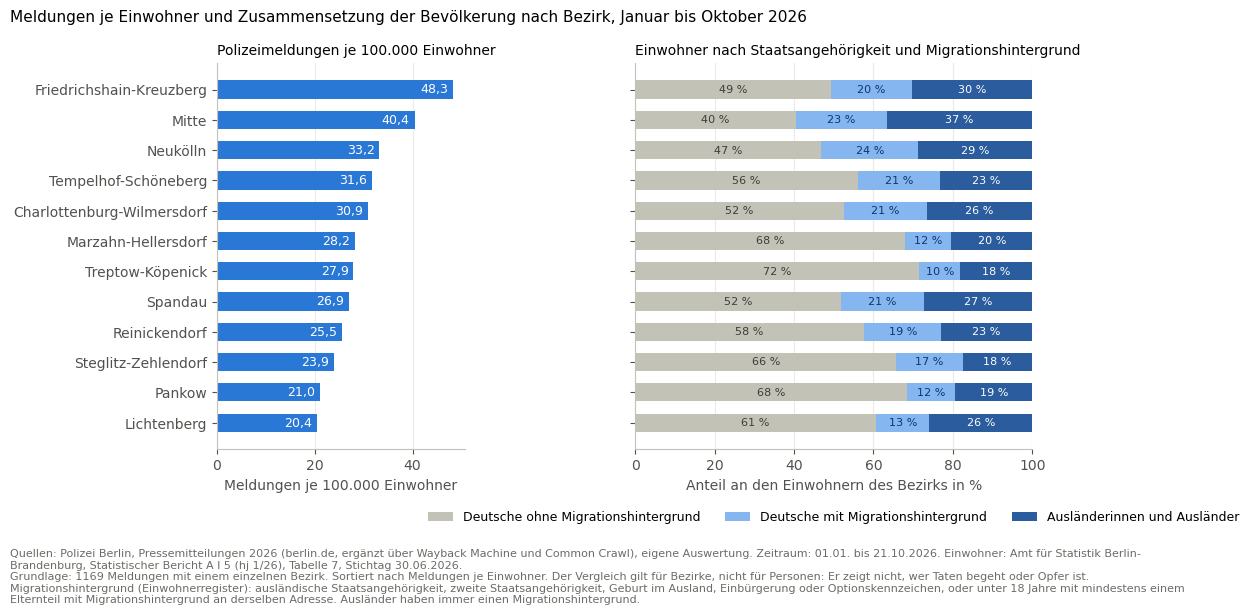

In [55]:
# Bevölkerung der Bezirke nach Staatsangehörigkeit und Migrationshintergrund, neben den Meldungen je Einwohner
# Quelle: Amt für Statistik Berlin-Brandenburg, Statistischer Bericht A I 5 (hj 1/26), Tabelle 7
# (Einwohnerinnen und Einwohner mit bzw. ohne Migrationshintergrund nach Bezirken), Block „insgesamt“
import numpy as np

roh7 = pd.read_excel(EINWOHNER_DATEI, sheet_name="T7", header=None)

# Python sucht die Zeile mit den Spaltennummern 1 bis 12 und den Block „insgesamt“ selbst
nummern = roh7.index[roh7.apply(lambda z: list(pd.to_numeric(z, errors="coerce").dropna().astype(int)) == list(range(1, 13)),
                                axis=1)][0]
sp = {int(roh7.iat[nummern, j]): j for j in range(roh7.shape[1]) if pd.notna(pd.to_numeric(roh7.iat[nummern, j], errors="coerce"))}
ist_block = roh7.apply(lambda z: z.astype(str).str.strip().str.lower().eq("insgesamt").any(), axis=1)
start7 = roh7.index[ist_block & (roh7.index > nummern)][0]                # Block unter dem Tabellenkopf, nicht die Kopfzeile
bezirk_zeile = {}
for i in range(start7 + 1, len(roh7)):
    name = str(roh7.iat[i, 0]).strip()
    if schluessel(name) in {schluessel(b) for b in pro_bezirk.index}:
        bezirk_zeile[schluessel(name)] = i
    if schluessel(name) == "berlin":
        break

# Spalten laut Tabellenkopf: 1 Insgesamt, 3 mit Migrationshintergrund (Sp. 9 + 11), 5 Deutsche zusammen,
# 7 Deutsche ohne Migrationshintergrund, 9 Deutsche mit Migrationshintergrund, 11 Ausländer (jeweils Anzahl)
bevoelkerung = pd.DataFrame({b: {"insgesamt": roh7.iat[bezirk_zeile[schluessel(b)], sp[1]],
                             "mit_mh": roh7.iat[bezirk_zeile[schluessel(b)], sp[3]],
                             "deutsche": roh7.iat[bezirk_zeile[schluessel(b)], sp[5]],
                             "ohne_mh": roh7.iat[bezirk_zeile[schluessel(b)], sp[7]],
                             "deutsche_mh": roh7.iat[bezirk_zeile[schluessel(b)], sp[9]],
                             "auslaender": roh7.iat[bezirk_zeile[schluessel(b)], sp[11]]} for b in pro_bezirk.index}).T.astype(int)

# Prüfung, ob die Spalten richtig gelesen wurden: die Teile müssen die Summen ergeben
assert (bevoelkerung["ohne_mh"] + bevoelkerung["deutsche_mh"] == bevoelkerung["deutsche"]).all()
assert (bevoelkerung["deutsche"] + bevoelkerung["auslaender"] == bevoelkerung["insgesamt"]).all()
assert (bevoelkerung["deutsche_mh"] + bevoelkerung["auslaender"] == bevoelkerung["mit_mh"]).all()
assert (bevoelkerung["insgesamt"] == einwohner.loc[bevoelkerung.index]).all(), "Tabelle 7 und Tabelle 3 haben andere Einwohnerzahlen"
print("Tabelle 7 gelesen, Summen geprüft, Einwohner gleich wie in Tabelle 3.")

GRUPPEN = {"ohne_mh": "Deutsche ohne Migrationshintergrund", "deutsche_mh": "Deutsche mit Migrationshintergrund",
           "auslaender": "Ausländerinnen und Ausländer"}
anteile_herkunft = bevoelkerung[list(GRUPPEN) + ["mit_mh"]].div(bevoelkerung["insgesamt"], axis=0).mul(100).round(1)
herkunft_vergleich = je_einwohner[["je 100.000 Einwohner", "Rang je Einwohner"]].join(
    anteile_herkunft.rename(columns={**{k: v + " %" for k, v in GRUPPEN.items()}, "mit_mh": "mit Migrationshintergrund zusammen %"}))
display(herkunft_vergleich)


def zufallstest(x, y, runden=20_000, seed=1):
    """Spearman-Korrelation und wie oft eine zufällige Zuordnung der Bezirke einen mindestens so starken
    Zusammenhang ergibt (Permutationstest, zweiseitig). Bei nur 12 Bezirken ist das ehrlicher als eine Formel."""
    rx, ry = x.rank().to_numpy(), y.rank().to_numpy()
    r = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(seed)
    zufall = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(runden)])
    return r, (np.abs(zufall) >= abs(r) - 1e-12).mean()


# Rechnung mit allen 12 Bezirken und ohne die beiden Bezirke mit den meisten Meldungen je Einwohner
spitze_bezirke = list(je_einwohner.index[:2])
zeilen_test = []
for spalte_name in list(GRUPPEN) + ["mit_mh"]:
    for umfang, bezirke in [("alle 12 Bezirke", je_einwohner.index), ("ohne " + " und ".join(spitze_bezirke), je_einwohner.index[2:])]:
        r, p = zufallstest(je_einwohner.loc[bezirke, "je 100.000 Einwohner"], anteile_herkunft.loc[bezirke, spalte_name])
        zeilen_test.append({"Anteil": GRUPPEN.get(spalte_name, "mit Migrationshintergrund zusammen"), "Bezirke": umfang,
                            "Spearman": round(r, 2), "Zufallstest p": round(p, 2)})
herkunft_tests = pd.DataFrame(zeilen_test)
display(herkunft_tests)

# Diagramm: links Meldungen je Einwohner, rechts die Zusammensetzung der Bevölkerung, gleiche Reihenfolge
daten = herkunft_vergleich.iloc[::-1]
farben = {"ohne_mh": "#c3c2b7", "deutsche_mh": "#86b6ef", "auslaender": "#2a5c9e"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})
ax1.barh(daten.index, daten["je 100.000 Einwohner"], color="#2a78d6", height=0.6)
for y, w in enumerate(daten["je 100.000 Einwohner"]):                          # Wert weiß im Balken
    ax1.text(w - daten["je 100.000 Einwohner"].max() * 0.02, y, f"{w:.1f}".replace(".", ","), va="center", ha="right",
             fontsize=9, color="white")
ax1.set_xlabel("Meldungen je 100.000 Einwohner", color="#52514e")
ax1.set_title("Polizeimeldungen je 100.000 Einwohner", loc="left", fontsize=10)
links = np.zeros(len(daten))
for k, name in GRUPPEN.items():
    werte = anteile_herkunft.loc[daten.index, k].to_numpy()
    ax2.barh(daten.index, werte, left=links, color=farben[k], height=0.6, label=name)
    for y, (l, w) in enumerate(zip(links, werte)):
        if w >= 8:
            ax2.text(l + w / 2, y, f"{w:.0f} %", va="center", ha="center", fontsize=8,
                     color="#3d3c39" if k == "ohne_mh" else ("#0d366b" if k == "deutsche_mh" else "white"))
    links += werte
ax2.set_xlim(0, 100)
ax2.set_xlabel("Anteil an den Einwohnern des Bezirks in %", color="#52514e")
ax2.set_title("Einwohner nach Staatsangehörigkeit und Migrationshintergrund", loc="left", fontsize=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=9)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Meldungen je Einwohner und Zusammensetzung der Bevölkerung nach Bezirk, Januar bis Oktober 2026", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}. Einwohner: Amt für Statistik "
         f"Berlin-Brandenburg, Statistischer Bericht A I 5 (hj 1/26), Tabelle 7, Stichtag {STICHTAG:%d.%m.%Y}.",
         f"Grundlage: {pro_bezirk.sum()} Meldungen mit einem einzelnen Bezirk. Sortiert nach Meldungen je Einwohner. "
         "Der Vergleich gilt für Bezirke, nicht für Personen: Er zeigt nicht, wer Taten begeht oder Opfer ist.",
         BEGRIFF_MH)
plt.show()


#### Interpretation: Bevölkerung und Meldungen

- **Die drei Bezirke mit den meisten Meldungen je Einwohner haben auch den höchsten Anteil an Einwohnern mit Migrationshintergrund:** Friedrichshain-Kreuzberg (48,3 Meldungen je 100.000 Einwohner, 50,7 % mit Migrationshintergrund), Mitte (40,4 und 59,6 %) und Neukölln (33,2 und 53,1 %).
- **Über alle 12 Bezirke hängen die Werte zusammen:** Spearman 0,69 für den Migrationshintergrund und 0,67 für den Ausländeranteil (Zufallstest p 0,02). Für Deutsche mit Migrationshintergrund allein ist der Zusammenhang schwächer (0,59, p 0,05).
- **Der Zusammenhang beruht vor allem auf zwei Bezirken.** Ohne Friedrichshain-Kreuzberg und Mitte sinkt er auf 0,50 (Migrationshintergrund) bzw. 0,44 (Ausländer), und der Zufallstest liegt bei p 0,14 bzw. 0,20. Ein so starker Zusammenhang kann bei 10 Bezirken also auch zufällig entstehen.
- **Es gibt deutliche Ausnahmen:** Spandau hat mit 48,2 % fast so viele Einwohner mit Migrationshintergrund wie Friedrichshain-Kreuzberg, liegt bei den Meldungen je Einwohner aber nur auf Rang 8 (26,9). Marzahn-Hellersdorf hat mit 32,1 % einen der niedrigsten Anteile und liegt auf Rang 6 (28,2). Lichtenberg hat die wenigsten Meldungen je Einwohner (20,4) bei 39,3 %.
- **Was die Zahlen nicht zeigen:** Sie beschreiben Bezirke, nicht Menschen. Daraus lässt sich nicht ablesen, wer Taten begeht oder Opfer wird, und auch nicht, ob Menschen mit Migrationshintergrund häufiger beteiligt sind. Wer das aus diesen Zahlen schließt, begeht einen ökologischen Fehlschluss.
- **Warum die Werte zusammenhängen, lässt sich mit diesen Daten nicht sagen.** Die Bezirke unterscheiden sich in vielem gleichzeitig, z. B. Lage in der Innenstadt, Besucher und Pendler, Nachtleben, Alter und soziale Lage der Bewohner. Mit 12 Bezirken lassen sich diese Einflüsse nicht voneinander trennen.

#### Haushalte nach Einkommen

Als zweites Merkmal des Umfelds steht hier das monatliche Haushaltsnettoeinkommen neben den Meldungen je Einwohner. Die Zahlen stammen aus dem Mikrozensus 2025 des Amts für Statistik Berlin-Brandenburg (Tabelle 7.5, Haushalte nach Bezirken und Haushaltsnettoeinkommen, Erstergebnis). Die Datei liegt unter `data/raw/SB_A01-10-00_2025j01_BE.pdf`. Python findet die Tabelle in der PDF selbst und prüft, ob die Einkommensstufen die Summe ergeben. Zum Lesen der PDF wird `pypdf` gebraucht (`pip install pypdf`).

Gerechnet wird mit zwei Anteilen: Haushalte unter 1.500 € und Haushalte mit 4.000 € und mehr. Auch hier gilt: Der Vergleich beschreibt Bezirke, nicht Menschen.

Tabelle 7.5 (2025) gelesen: 12 Bezirke, Summe der Stufen weicht höchstens um 1 Tausend ab.


,je 100.000 Einwohner,Rang je Einwohner,unter 1.500 € %,1.500 bis 2.000 € %,2.000 bis 3.000 € %,3.000 bis 4.000 € %,4.000 € und mehr %,Haushalte (Tausend)
Friedrichshain-Kreuzberg,48.3,1,23.0,11.2,22.4,13.8,29.6,152
Mitte,40.4,2,22.2,11.9,20.6,16.5,28.9,194
Neukölln,33.2,3,23.1,12.4,23.7,17.8,23.1,168
Tempelhof-Schöneberg,31.6,4,17.8,12.1,23.0,16.1,31.0,175
Charlottenburg-Wilmersdorf,30.9,5,18.6,12.0,22.4,13.7,33.3,183
Marzahn-Hellersdorf,28.2,6,14.8,12.0,28.2,16.9,28.2,141
Treptow-Köpenick,27.9,7,15.2,11.9,25.2,16.6,31.1,150
Spandau,26.9,8,19.2,12.8,24.8,15.2,28.0,124
Reinickendorf,25.5,9,19.5,11.7,23.4,14.8,30.5,129
Steglitz-Zehlendorf,23.9,10,16.1,9.4,20.1,14.1,40.3,149


,Anteil Haushalte,Bezirke,Spearman,Zufallstest p
0,unter 1.500 €,alle 12 Bezirke,0.42,0.18
1,unter 1.500 €,ohne Friedrichshain-Kreuzberg und Mitte,0.03,0.95
2,4.000 € und mehr,alle 12 Bezirke,-0.19,0.56
3,4.000 € und mehr,ohne Friedrichshain-Kreuzberg und Mitte,-0.16,0.66


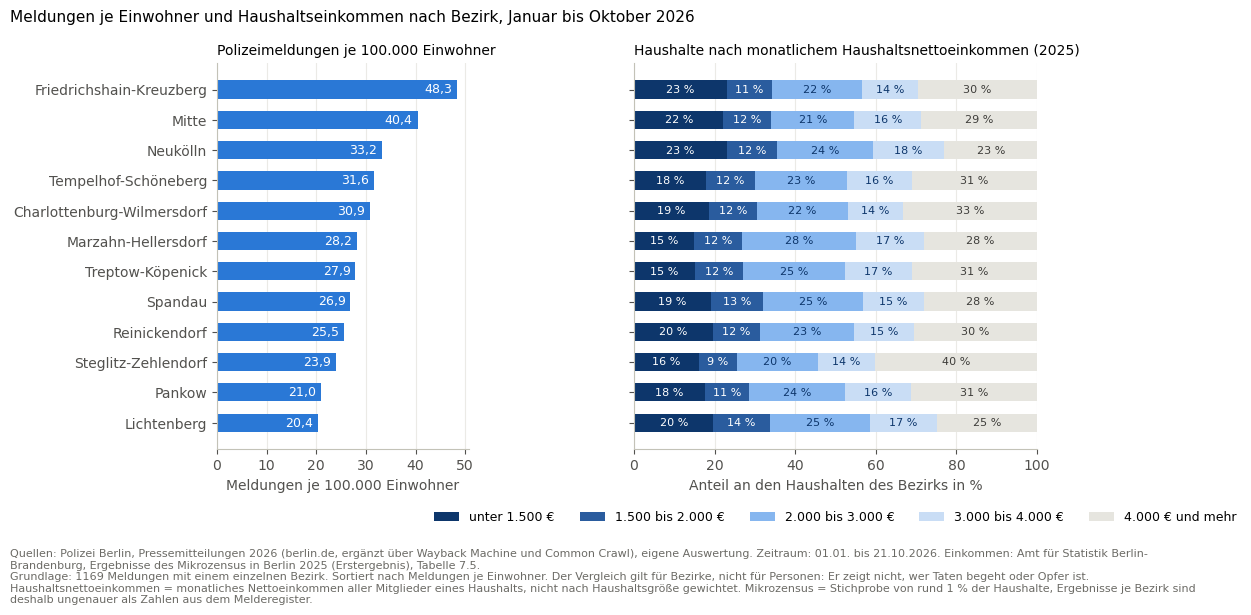

In [56]:
# Haushalte nach Haushaltsnettoeinkommen je Bezirk, neben den Meldungen je Einwohner
# Quelle: Amt für Statistik Berlin-Brandenburg, Statistischer Bericht A I 10 / A I 11 / A VI 2 - j / 25,
# Ergebnisse des Mikrozensus in Berlin 2025 (Erstergebnis), Tabelle 7.5 (Haushalte nach Bezirken und Haushaltsnettoeinkommen)
from pypdf import PdfReader

MIKROZENSUS_DATEI = ROOT / "data" / "raw" / "SB_A01-10-00_2025j01_BE.pdf"
seiten = [s.extract_text() or "" for s in PdfReader(MIKROZENSUS_DATEI).pages]

# Python sucht die Seite mit Tabelle 7.5 selbst
seite_75 = [t for t in seiten if re.search(r"7\.5\s+Haushalte im Land Berlin \d{4} nach Bezirken und Haushaltsnettoeinkommen", t)]
assert len(seite_75) == 1, "Tabelle 7.5 nicht eindeutig gefunden"
seite_75 = seite_75[0]
MZ_JAHR = int(re.search(r"7\.5\s+Haushalte im Land Berlin (\d{4})", seite_75).group(1))

# Einkommensstufen in der Reihenfolge der Tabellenspalten (Euro pro Monat, netto, ganzer Haushalt)
STUFEN = ["unter 1.500 €", "1.500 bis 2.000 €", "2.000 bis 3.000 €", "3.000 bis 4.000 €", "4.000 € und mehr"]
assert "unter" in seite_75 and "und mehr" in seite_75, "Spaltenköpfe der Tabelle 7.5 nicht gefunden"

haushalte = {}
for zeile in seite_75.splitlines():
    teile = zeile.split()
    if not teile:
        continue
    name = " ".join(t for t in teile if not t.isdigit())
    zahlen = [int(t) for t in teile if t.isdigit()]
    if schluessel(name) in {schluessel(b) for b in pro_bezirk.index} and len(zahlen) == 6:
        b = next(b for b in pro_bezirk.index if schluessel(b) == schluessel(name))
        haushalte[b] = zahlen
haushalte = pd.DataFrame(haushalte, index=["insgesamt"] + STUFEN).T                      # in 1.000 Haushalten
assert len(haushalte) == 12, f"nur {len(haushalte)} Bezirke in Tabelle 7.5 gefunden"
abweichung = (haushalte[STUFEN].sum(axis=1) - haushalte["insgesamt"]).abs()
assert (abweichung <= 2).all(), "Stufen ergeben nicht die Summe"                           # Rundung auf Tausend
print(f"Tabelle 7.5 ({MZ_JAHR}) gelesen: 12 Bezirke, Summe der Stufen weicht höchstens um {abweichung.max()} Tausend ab.")

einkommen = haushalte[STUFEN].div(haushalte[STUFEN].sum(axis=1), axis=0).mul(100).round(1)   # Anteil in %
einkommen_vergleich = je_einwohner[["je 100.000 Einwohner", "Rang je Einwohner"]].join(
    einkommen.rename(columns={s: s + " %" for s in STUFEN})).join(haushalte["insgesamt"].rename("Haushalte (Tausend)"))
display(einkommen_vergleich)

zeilen_test = []
for stufe in [STUFEN[0], STUFEN[-1]]:
    for umfang, bezirke in [("alle 12 Bezirke", je_einwohner.index), ("ohne " + " und ".join(spitze_bezirke), je_einwohner.index[2:])]:
        r, p = zufallstest(je_einwohner.loc[bezirke, "je 100.000 Einwohner"], einkommen.loc[bezirke, stufe])
        zeilen_test.append({"Anteil Haushalte": stufe, "Bezirke": umfang, "Spearman": round(r, 2), "Zufallstest p": round(p, 2)})
einkommen_tests = pd.DataFrame(zeilen_test)
display(einkommen_tests)

# Diagramm wie oben: links Meldungen je Einwohner, rechts die Haushalte nach Einkommen, gleiche Reihenfolge
daten = einkommen_vergleich.iloc[::-1]
farben_stufen = ["#0d366b", "#2a5c9e", "#86b6ef", "#c9ddf5", "#e6e5df"]
schrift_stufen = ["white", "white", "#0d366b", "#0d366b", "#3d3c39"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})
ax1.barh(daten.index, daten["je 100.000 Einwohner"], color="#2a78d6", height=0.6)
for y, w in enumerate(daten["je 100.000 Einwohner"]):                          # Wert weiß im Balken
    ax1.text(w - daten["je 100.000 Einwohner"].max() * 0.02, y, f"{w:.1f}".replace(".", ","), va="center", ha="right",
             fontsize=9, color="white")
ax1.set_xlabel("Meldungen je 100.000 Einwohner", color="#52514e")
ax1.set_title("Polizeimeldungen je 100.000 Einwohner", loc="left", fontsize=10)
links = np.zeros(len(daten))
for stufe, farbe, schrift in zip(STUFEN, farben_stufen, schrift_stufen):
    werte = einkommen.loc[daten.index, stufe].to_numpy()
    ax2.barh(daten.index, werte, left=links, color=farbe, height=0.6, label=stufe)
    for y, (l, w) in enumerate(zip(links, werte)):
        if w >= 8:
            ax2.text(l + w / 2, y, f"{w:.0f} %", va="center", ha="center", fontsize=8, color=schrift)
    links += werte
ax2.set_xlim(0, 100)
ax2.set_xlabel("Anteil an den Haushalten des Bezirks in %", color="#52514e")
ax2.set_title(f"Haushalte nach monatlichem Haushaltsnettoeinkommen ({MZ_JAHR})", loc="left", fontsize=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False, fontsize=9)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Meldungen je Einwohner und Haushaltseinkommen nach Bezirk, Januar bis Oktober 2026", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}. Einkommen: Amt für Statistik "
         f"Berlin-Brandenburg, Ergebnisse des Mikrozensus in Berlin {MZ_JAHR} (Erstergebnis), Tabelle 7.5.",
         f"Grundlage: {pro_bezirk.sum()} Meldungen mit einem einzelnen Bezirk. Sortiert nach Meldungen je Einwohner. "
         "Der Vergleich gilt für Bezirke, nicht für Personen: Er zeigt nicht, wer Taten begeht oder Opfer ist.",
         BEGRIFF_EINKOMMEN)
plt.show()


#### Interpretation: Einkommen und Meldungen

- **Die drei Bezirke mit den meisten Meldungen je Einwohner haben auch den höchsten Anteil an Haushalten unter 1.500 € im Monat:** Neukölln (23,1 %), Friedrichshain-Kreuzberg (23,0 %) und Mitte (22,2 %). Die übrigen Bezirke liegen zwischen 14,8 % (Marzahn-Hellersdorf) und 19,7 % (Lichtenberg).
- **Über alle Bezirke ist der Zusammenhang schwach und unsicher:** Spearman 0,42 für Haushalte unter 1.500 € (Zufallstest p 0,18) und -0,19 für Haushalte mit 4.000 € und mehr (p 0,56). Ohne Friedrichshain-Kreuzberg und Mitte verschwindet er ganz (0,03, p 0,95).
- **Ausnahmen:** Marzahn-Hellersdorf hat den kleinsten Anteil an Haushalten unter 1.500 €, liegt bei den Meldungen je Einwohner aber auf Rang 6. Lichtenberg hat die wenigsten Meldungen je Einwohner bei 19,7 % Haushalten unter 1.500 €. Steglitz-Zehlendorf hat mit 40,3 % die meisten Haushalte mit 4.000 € und mehr und liegt auf Rang 10.
- **Zusammen mit dem Migrationshintergrund:** In Friedrichshain-Kreuzberg, Mitte und Neukölln kommen mehrere Merkmale zusammen: viele Meldungen je Einwohner, ein hoher Anteil an Einwohnern mit Migrationshintergrund, viele Haushalte mit niedrigem Einkommen und die Lage in der Innenstadt. Welches Merkmal wie viel beiträgt, lässt sich mit 12 Bezirken nicht trennen.
- **Was die Zahlen nicht zeigen:** Auch hier beschreiben die Zahlen Bezirke, nicht Menschen. Sie zeigen nicht, ob Menschen mit wenig Einkommen häufiger Taten begehen oder Opfer werden. Das Einkommen gilt außerdem für den ganzen Haushalt und nicht je Person.

#### Erwerbstätige, Erwerbslose und Nichterwerbspersonen

Als drittes Merkmal steht hier die Erwerbsbeteiligung der Bevölkerung von 15 bis unter 65 Jahren, aus derselben Mikrozensus-PDF (Tabelle 7.3). Python findet die Tabelle selbst und prüft die Summen. Die Zahl der Erwerbslosen je Bezirk ist klein: Das Amt für Statistik setzt sie bei den meisten Bezirken in Klammern (Aussagewert eingeschränkt) und weist sie für zwei Bezirke gar nicht aus. Dort wird sie als Erwerbspersonen minus Erwerbstätige berechnet und in der Tabelle als unsicher markiert.

Tabelle 7.3 (2025) gelesen: 12 Bezirke, Summen geprüft. Erwerbslose: 4 Bezirke gesichert, 6 mit eingeschränktem Aussagewert, 2 nicht ausgewiesen (berechnet).


,je 100.000 Einwohner,Rang je Einwohner,Erwerbstätige %,Erwerbslose %,Nichterwerbspersonen %,Erwerbslosenquote %,Angabe Erwerbslose
Friedrichshain-Kreuzberg,48.3,1,73.0,6.4,20.6,8.0,gesichert
Mitte,40.4,2,70.6,6.0,23.4,7.9,gesichert
Neukölln,33.2,3,69.0,6.7,24.3,8.8,gesichert
Tempelhof-Schöneberg,31.6,4,72.1,4.9,23.0,6.3,eingeschränkt
Charlottenburg-Wilmersdorf,30.9,5,72.5,4.7,22.7,6.1,eingeschränkt
Marzahn-Hellersdorf,28.2,6,74.7,3.5,21.8,4.5,"berechnet, unsicher"
Treptow-Köpenick,27.9,7,73.3,4.7,22.0,6.1,eingeschränkt
Spandau,26.9,8,68.8,5.6,25.6,7.6,eingeschränkt
Reinickendorf,25.5,9,68.9,5.0,26.1,6.7,eingeschränkt
Steglitz-Zehlendorf,23.9,10,77.1,3.2,19.7,4.0,"berechnet, unsicher"


,Merkmal,Bezirke,Spearman,Zufallstest p
0,Erwerbstätige,alle 12 Bezirke,-0.20,0.55
1,Erwerbstätige,ohne Friedrichshain-Kreuzberg und Mitte,-0.21,0.56
2,Erwerbslosenquote,alle 12 Bezirke,0.53,0.08
3,Erwerbslosenquote,ohne Friedrichshain-Kreuzberg und Mitte,0.22,0.53


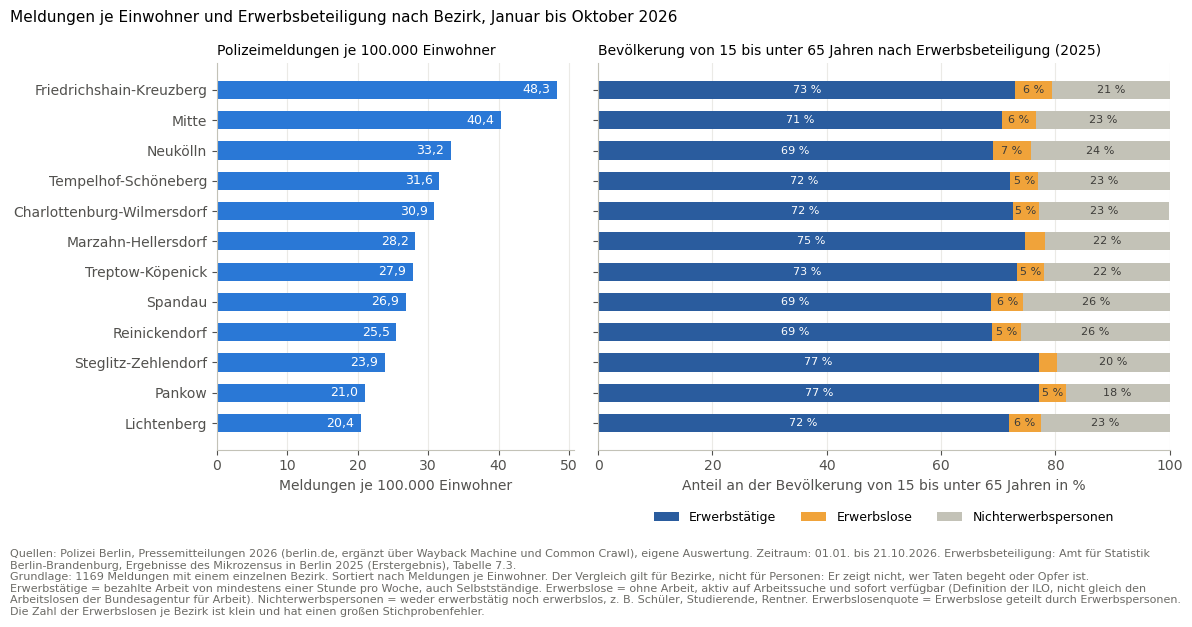

In [57]:
# Bevölkerung von 15 bis unter 65 Jahren nach Erwerbsbeteiligung je Bezirk, neben den Meldungen je Einwohner
# Quelle: dieselbe Mikrozensus-PDF wie oben, Tabelle 7.3 (Bevölkerung nach Bezirken, Erwerbsbeteiligung und Geschlecht),
# Block „Insgesamt“. Zeichen des Amts: (Zahl) = Aussagewert eingeschränkt, / = Wert nicht sicher genug, nicht ausgewiesen.
seite_73 = [t for t in seiten if re.search(r"7\.3\s+Bevölkerung im Land Berlin \d{4} im Alter von 15 bis unter 65 Jahren", t)]
assert len(seite_73) == 1, "Tabelle 7.3 nicht eindeutig gefunden"
seite_73 = seite_73[0]

erwerb, unsicher = {}, {}
for zeile in seite_73.splitlines():
    if zeile.strip().startswith("Männlich"):                                   # nur der erste Block (Insgesamt)
        break
    teile = zeile.split()
    werte = [t for t in teile if re.fullmatch(r"\d+|\(\d+\)|/", t)]
    name = " ".join(t for t in teile if t not in werte)
    if schluessel(name) in {schluessel(b) for b in pro_bezirk.index} and len(werte) == 5:
        b = next(b for b in pro_bezirk.index if schluessel(b) == schluessel(name))
        erwerb[b] = [int(w.strip("()")) if w != "/" else None for w in werte]
        unsicher[b] = werte[3]                                                    # Spalte Erwerbslose
erwerb = pd.DataFrame(erwerb, index=["bevoelkerung", "erwerbspersonen", "erwerbstaetige", "erwerbslose",
                                     "nichterwerbspersonen"]).T                    # in 1.000 Personen
assert len(erwerb) == 12, f"nur {len(erwerb)} Bezirke in Tabelle 7.3 gefunden"
# Fehlt die Zahl der Erwerbslosen („/“), wird sie als Erwerbspersonen minus Erwerbstätige berechnet und als unsicher markiert
erwerb["erwerbslose"] = erwerb["erwerbslose"].fillna(erwerb["erwerbspersonen"] - erwerb["erwerbstaetige"])
erwerb = erwerb.astype(int)
assert ((erwerb["erwerbstaetige"] + erwerb["erwerbslose"] - erwerb["erwerbspersonen"]).abs() <= 2).all()
assert ((erwerb["erwerbspersonen"] + erwerb["nichterwerbspersonen"] - erwerb["bevoelkerung"]).abs() <= 2).all()
erwerb["Angabe Erwerbslose"] = ["eingeschränkt" if u.startswith("(") else ("berechnet, unsicher" if u == "/" else "gesichert")
                                for u in pd.Series(unsicher).loc[erwerb.index]]
print(f"Tabelle 7.3 ({MZ_JAHR}) gelesen: 12 Bezirke, Summen geprüft. Erwerbslose: "
      f"{(erwerb['Angabe Erwerbslose'] == 'gesichert').sum()} Bezirke gesichert, "
      f"{(erwerb['Angabe Erwerbslose'] == 'eingeschränkt').sum()} mit eingeschränktem Aussagewert, "
      f"{(erwerb['Angabe Erwerbslose'] == 'berechnet, unsicher').sum()} nicht ausgewiesen (berechnet).")

ERWERB = {"erwerbstaetige": "Erwerbstätige", "erwerbslose": "Erwerbslose", "nichterwerbspersonen": "Nichterwerbspersonen"}
erwerb_anteile = erwerb[list(ERWERB)].div(erwerb[list(ERWERB)].sum(axis=1), axis=0).mul(100).round(1)
erwerb_anteile["erwerbslosenquote"] = (erwerb["erwerbslose"] / erwerb["erwerbspersonen"] * 100).round(1)
erwerb_vergleich = je_einwohner[["je 100.000 Einwohner", "Rang je Einwohner"]].join(
    erwerb_anteile.rename(columns={**{k: v + " %" for k, v in ERWERB.items()}, "erwerbslosenquote": "Erwerbslosenquote %"})
).join(erwerb["Angabe Erwerbslose"])
display(erwerb_vergleich)

zeilen_test = []
for spalte_name, text in [("erwerbstaetige", "Erwerbstätige"), ("erwerbslosenquote", "Erwerbslosenquote")]:
    for umfang, bezirke in [("alle 12 Bezirke", je_einwohner.index), ("ohne " + " und ".join(spitze_bezirke), je_einwohner.index[2:])]:
        r, p = zufallstest(je_einwohner.loc[bezirke, "je 100.000 Einwohner"], erwerb_anteile.loc[bezirke, spalte_name])
        zeilen_test.append({"Merkmal": text, "Bezirke": umfang, "Spearman": round(r, 2), "Zufallstest p": round(p, 2)})
erwerb_tests = pd.DataFrame(zeilen_test)
display(erwerb_tests)

# Diagramm wie oben: links Meldungen je Einwohner, rechts die Bevölkerung von 15 bis 64 Jahren nach Erwerbsbeteiligung
daten = erwerb_vergleich.iloc[::-1]
farben_erwerb = {"erwerbstaetige": ("#2a5c9e", "white"), "erwerbslose": ("#f0a33a", "#3d3c39"),
                 "nichterwerbspersonen": ("#c3c2b7", "#3d3c39")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})
ax1.barh(daten.index, daten["je 100.000 Einwohner"], color="#2a78d6", height=0.6)
for y, w in enumerate(daten["je 100.000 Einwohner"]):                          # Wert weiß im Balken
    ax1.text(w - daten["je 100.000 Einwohner"].max() * 0.02, y, f"{w:.1f}".replace(".", ","), va="center", ha="right",
             fontsize=9, color="white")
ax1.set_xlabel("Meldungen je 100.000 Einwohner", color="#52514e")
ax1.set_title("Polizeimeldungen je 100.000 Einwohner", loc="left", fontsize=10)
links = np.zeros(len(daten))
for k, name in ERWERB.items():
    werte = erwerb_anteile.loc[daten.index, k].to_numpy()
    ax2.barh(daten.index, werte, left=links, color=farben_erwerb[k][0], height=0.6, label=name)
    for y, (l, w) in enumerate(zip(links, werte)):
        if w >= 4:
            ax2.text(l + w / 2, y, f"{w:.0f} %", va="center", ha="center", fontsize=8, color=farben_erwerb[k][1])
    links += werte
ax2.set_xlim(0, 100)
ax2.set_xlabel("Anteil an der Bevölkerung von 15 bis unter 65 Jahren in %", color="#52514e")
ax2.set_title(f"Bevölkerung von 15 bis unter 65 Jahren nach Erwerbsbeteiligung ({MZ_JAHR})", loc="left", fontsize=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=9)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Meldungen je Einwohner und Erwerbsbeteiligung nach Bezirk, Januar bis Oktober 2026", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}. Erwerbsbeteiligung: Amt für Statistik "
         f"Berlin-Brandenburg, Ergebnisse des Mikrozensus in Berlin {MZ_JAHR} (Erstergebnis), Tabelle 7.3.",
         f"Grundlage: {pro_bezirk.sum()} Meldungen mit einem einzelnen Bezirk. Sortiert nach Meldungen je Einwohner. "
         "Der Vergleich gilt für Bezirke, nicht für Personen: Er zeigt nicht, wer Taten begeht oder Opfer ist.",
         BEGRIFF_ERWERB)
plt.show()


#### Interpretation: Erwerbsbeteiligung und Meldungen

- **Die drei Bezirke mit den meisten Meldungen je Einwohner haben auch die höchste Erwerbslosenquote:** Neukölln (8,8 %), Friedrichshain-Kreuzberg (8,0 %) und Mitte (7,9 %). Danach folgen Spandau (7,6 %) und Lichtenberg (7,1 %).
- **Über alle Bezirke ist der Zusammenhang mittel und unsicher:** Spearman 0,53 für die Erwerbslosenquote (Zufallstest p 0,08). Ohne Friedrichshain-Kreuzberg und Mitte sinkt er auf 0,22 (p 0,53). Der Anteil der Erwerbstätigen hängt kaum mit den Meldungen zusammen (-0,20, p 0,55).
- **Ausnahmen:** Spandau hat die vierthöchste Erwerbslosenquote, liegt bei den Meldungen je Einwohner aber auf Rang 8. Lichtenberg hat die wenigsten Meldungen je Einwohner bei 7,1 %.
- **Die Werte sind unsicher:** Nur für 4 Bezirke weist das Amt für Statistik die Zahl der Erwerbslosen ohne Einschränkung aus, für 6 nur mit eingeschränktem Aussagewert, für Steglitz-Zehlendorf und Marzahn-Hellersdorf gar nicht (hier berechnet). Unterschiede von ein bis zwei Prozentpunkten können reiner Stichprobenfehler sein.
- **Alle drei Merkmale zusammen:** Friedrichshain-Kreuzberg, Mitte und Neukölln liegen bei Migrationshintergrund, niedrigem Einkommen und Erwerbslosigkeit vorn und haben zugleich die meisten Meldungen je Einwohner. Ohne diese beiden Innenstadtbezirke Friedrichshain-Kreuzberg und Mitte zeigt keines der Merkmale einen gesicherten Zusammenhang. Die Daten beschreiben damit das Umfeld der Bezirke, erklären aber nicht, warum dort mehr Meldungen veröffentlicht werden.

### 6.3 Kategorien je Bezirk

Jede Zeile zeigt, wie sich die Meldungen eines Bezirks auf die Kategorien verteilen, jede Zeile ergibt 100 %. So lassen sich Bezirke mit unterschiedlich vielen Meldungen vergleichen.

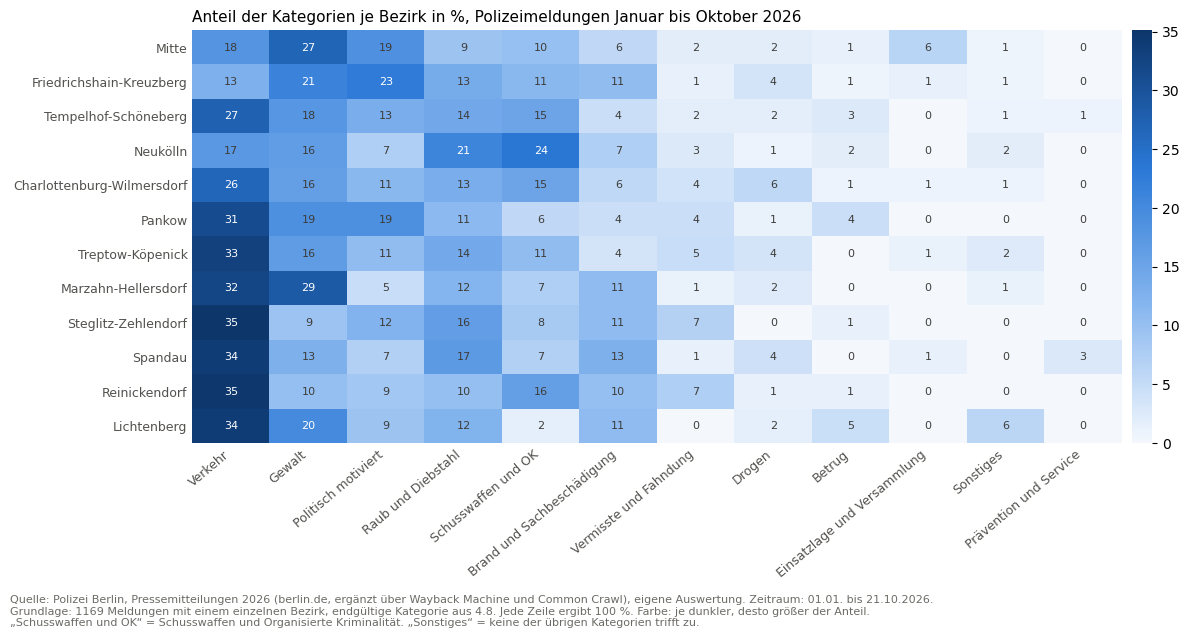

In [58]:
# Anteil der Kategorien je Bezirk in Prozent (jede Zeile ergibt 100 %)
anteile = pd.crosstab(df["bezirk"], df["kategorie"], normalize="index") * 100
reihenfolge = df["kategorie"].value_counts().index                     # häufigste Kategorie links
anteile = anteile[reihenfolge].loc[pro_bezirk.index[::-1]]            # Bezirke wie in 6.2, größter oben

BLAU = LinearSegmentedColormap.from_list("blau", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(12, 6))
bild = ax.imshow(anteile.values, cmap=BLAU, aspect="auto", vmin=0, vmax=anteile.values.max())
for i in range(anteile.shape[0]):                                     # Prozentwerte in die Felder
    for j in range(anteile.shape[1]):
        wert = anteile.iloc[i, j]
        ax.text(j, i, f"{wert:.0f}", ha="center", va="center", fontsize=8,
                color="white" if wert > anteile.values.max() * 0.55 else "#3d3c39")
ax.set_xticks(range(anteile.shape[1]))
ax.set_xticklabels(anteile.columns, rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(anteile.shape[0]))
ax.set_yticklabels(anteile.index, fontsize=9)
ax.tick_params(colors="#52514e", length=0)
for seite in ax.spines.values():
    seite.set_visible(False)
ax.set_title("Anteil der Kategorien je Bezirk in %, Polizeimeldungen Januar bis Oktober 2026", loc="left", fontsize=11)
fig.colorbar(bild, ax=ax, fraction=0.025, pad=0.01).outline.set_visible(False)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {pro_bezirk.sum()} Meldungen mit einem einzelnen Bezirk, endgültige Kategorie aus 4.8. Jede Zeile ergibt 100 %. Farbe: je dunkler, desto größer der Anteil.",
         BEGRIFF_KATEGORIE)
plt.show()

#### Interpretation: Kategorien je Bezirk

- **In den Außenbezirken überwiegt Verkehr.** In Steglitz-Zehlendorf, Reinickendorf, Spandau, Lichtenberg, Treptow-Köpenick und Marzahn-Hellersdorf betrifft rund ein Drittel der Meldungen den Verkehr (32 bis 35 %), in Mitte nur 18 % und in Friedrichshain-Kreuzberg 13 %.
- **Friedrichshain-Kreuzberg ist der einzige Bezirk, in dem „Politisch motiviert“ die größte Kategorie ist** (23 %). Mitte und Pankow folgen mit je 19 %, Marzahn-Hellersdorf liegt bei 5 %.
- **In Neukölln ist „Schusswaffen und OK“ die größte Kategorie** (24 %), dazu kommt Raub mit 21 %. In Lichtenberg liegt der Anteil von Schusswaffen und OK bei 2 %.
- **Gewalt** hat den höchsten Anteil in Marzahn-Hellersdorf (29 %) und Mitte (27 %).
- **Einsatzlage und Versammlung** kommt fast nur in Mitte vor (6 %).
- Kleine Werte sind unsicher: In Lichtenberg mit 65 Meldungen entspricht eine Meldung schon 1,5 Prozentpunkten.

### 6.4 Orte aus dem Text

Die Polizei nennt den genauen Ort nur im Text. Python sucht ihn in drei Schritten:

1. **Kontaktangaben entfernen:** Sätze wie „Hinweise nimmt … entgegen“ enthalten Adressen von LKA und Staatsschutz und werden vor der Suche gelöscht.
2. **Ortsnamen erkennen:** Ein Muster findet Wörter, die auf -straße, -allee, -damm, -platz, -park, -ufer, -brücke und ähnliche Endungen enden, Namen wie „Rigaer Straße“ oder „Tempelhofer Feld“ sowie U- und S-Bahnhöfe.
3. **Gattungswörter entfernen:** Steht ein unbestimmter Artikel davor („auf einem Parkplatz“), ist das Wort kein Eigenname.

Ort und Bezirk werden zusammen gezählt, weil es Straßennamen wie „Hauptstraße“ in mehreren Bezirken gibt. Eine Meldung kann mehrere Orte nennen, etwa bei einer Verfolgungsfahrt.

In [59]:
# Orte aus dem Text: Straßen, Plätze, Parks, Brücken und Bahnhöfe
# 1. Sätze mit Kontaktangaben entfernen, sonst zählen Adressen von LKA und Staatsschutz mit
KONTAKT = re.compile(r"[^.]*(?:entgegen|Rufnummer|Telefonnummer|Internetwache|\(030\))[^.]*\.")
# 2. Muster für Ortsnamen
ENDUNG = r"(?:straße|allee|damm|platz|park|(?<![rä])ufer|chaussee|brücke|markt|ring|weg|steig|promenade|kiez)"   # nicht "Anrufer", "Verkäufer"
ENDUNG_GROSS = r"(?:Straße|Allee|Damm|Platz|Park|Ufer|Chaussee|Brücke|Markt|Ring|Weg|Steig|Promenade|Kiez)"
ORT_MUSTER = re.compile(
    r"(?:S- und U-|U- und S-|U-|S-)?Bahnhofs? [A-ZÄÖÜ][\wäöüß\-]*"             # U-Bahnhof Kottbusser Tor
    r"(?: (?:Straße|Platz|Tor|Allee|Damm|Brücke|Zoo|[A-ZÄÖÜ][\wäöüß\-]*))?"
    r"|Volkspark [A-ZÄÖÜ][\wäöüß\-]*"                                         # Volkspark Friedrichshain
    r"|Platz der [A-ZÄÖÜ][\wäöüß\-]*|Straße des 17\. Juni"                    # Platz der Luftbrücke
    rf"|[A-ZÄÖÜ][\wäöüß\-]*er (?:{ENDUNG_GROSS}|Tor|Feld|[A-ZÄÖÜ][\wäöüß]*{ENDUNG})\b"   # Rigaer Straße, Rudower Landstraße
    rf"|[A-ZÄÖÜ][\wäöüß]*(?:-(?:[A-ZÄÖÜ][\wäöüß]*|von|van|der|de|zu|vom|am))*?(?:-?{ENDUNG}|-{ENDUNG_GROSS})\b"
)                                                                            # Sonnenallee, Karl-Marx-Straße, Heinrich-von-Gagern-Straße
# 3. Gattungswörter erkennen: steht ein unbestimmter Artikel davor ("auf einem Parkplatz"), ist es kein Name
UNBESTIMMT = re.compile(r"\b(?:ein|eine|einem|einen|einer|eines|kein\w*)\s+$", re.I)

zeilen, gattung = [], set()
for _, r in df.iterrows():
    text = KONTAKT.sub(" ", r["titel"] + ". " + r["text"])
    for m in ORT_MUSTER.finditer(text):
        name = m.group(0).replace("Bahnhofs", "Bahnhof")
        if UNBESTIMMT.search(text[max(0, m.start() - 12):m.start()]):
            gattung.add(name)
        zeilen.append({"meldung_id": r["meldung_id"], "ort": name, "bezirk": r["bezirk"],
                       "monat": r["monat"], "kategorie": r["kategorie"]})

orte = pd.DataFrame(zeilen).drop_duplicates(["meldung_id", "ort"])
orte = orte[~orte["ort"].isin(gattung)]                                  # Gattungswörter entfernen
print("Als Gattungswort erkannt und entfernt:", ", ".join(sorted(gattung)))
print(f"Meldungen mit mindestens einem Ort: {orte['meldung_id'].nunique()} von {len(df)}")
print(f"Verschiedene Orte: {orte['ort'].nunique()}")

# Ort und Bezirk zusammen, weil es manche Straßennamen in mehreren Bezirken gibt
ort_tabelle = (
    orte.groupby(["ort", "bezirk"], dropna=False)
        .agg(meldungen=("meldung_id", "nunique"),
             monate=("monat", "nunique"),
             haeufigste_kategorie=("kategorie", lambda s: s.value_counts().index[0]))
        .reset_index()
        .sort_values("meldungen", ascending=False)
)
ort_tabelle.head(25)

Als Gattungswort erkannt und entfernt: Anwohnerparkplatz, Discounter-Parkplatz, Fahrradstellplatz, Gehweg, Marktplatz, Mietparkplatz, Parkplatz, Rettungsring, Schlagring, Spielplatz, Sportplatz, Supermarkt, Supermarkt-Parkplatz, Zugangsweg
Meldungen mit mindestens einem Ort: 1165 von 1272
Verschiedene Orte: 1361


,ort,bezirk,meldungen,monate,haeufigste_kategorie
1321,Sonnenallee,Neukölln,12,7,Verkehr
878,Mehringdamm,Friedrichshain-Kreuzberg,11,6,Verkehr
493,Görlitzer Park,Friedrichshain-Kreuzberg,10,7,Gewalt
632,Johannisthaler Chaussee,Neukölln,10,6,Raub und Diebstahl
1316,Skalitzer Straße,Friedrichshain-Kreuzberg,9,6,Gewalt
569,Hermannstraße,Neukölln,9,6,Schusswaffen und OK
849,Mariendorfer Damm,Tempelhof-Schöneberg,9,5,Verkehr
661,Karl-Marx-Straße,Neukölln,9,8,Gewalt
351,Frankfurter Allee,Lichtenberg,8,6,Politisch motiviert
1135,Rigaer Straße,Friedrichshain-Kreuzberg,8,6,Politisch motiviert


#### Interpretation: Orte

- **1.165 der 1.272 Meldungen nennen mindestens einen Ort.**
- **Die häufigsten Orte sind lange Hauptstraßen**, etwa Sonnenallee (12), Mehringdamm (11), Johannisthaler Chaussee (10) und Mariendorfer Damm (9). Bei drei davon ist Verkehr die häufigste Kategorie, bei der Johannisthaler Chaussee Raub und Diebstahl. Lange Straßen kommen schon wegen ihrer Länge öfter vor.
- **Auffällig sind Orte mit einer anderen Hauptkategorie:** Görlitzer Park (10, meist Gewalt), Skalitzer Straße (9, Gewalt), Hermannstraße (9, Schusswaffen und OK), Karl-Marx-Straße (9 Meldungen in 8 verschiedenen Monaten, meist Gewalt) und Rigaer Straße (8, meist politisch motiviert).
- Noch enthalten sind einzelne Gattungswörter ohne unbestimmten Artikel, etwa „Radweg“, „Bahnsteig“ und „Vorplatz“. Sie sollen in 6.6 wegfallen, weil dort nur ein Treffer mit genau diesem Namen gilt.

### 6.5 Kriminalitätsbelastete Orte

An kriminalitätsbelasteten Orten (kbO) darf die Polizei Personen und Sachen auch ohne Verdacht kontrollieren und durchsuchen. Seit dem 24.12.2025 legt die Senatsverwaltung für Inneres und Sport sie per Verordnung fest (§ 17a ASOG Bln). Die aktuelle Liste gilt seit dem 01.07.2026.

Python lädt die Liste von der Seite der Polizei Berlin und sucht die Namen in den Meldungen. Bei Doppelnamen wie „Görlitzer Park/Wrangelkiez“ zählt jeder der beiden Begriffe.

kbO-Liste aus der gespeicherten Datei: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/kbo_liste.json
7 kriminalitätsbelastete Orte: Alexanderplatz, Görlitzer Park/Wrangelkiez, Hermannplatz/Donaukiez, Hermannstraße/Bahnhof Neukölln, Kottbusser Tor, Rigaer Straße, Warschauer Brücke


,kbO,Meldungen,Monate mit Meldung,häufigste Kategorien
0,Alexanderplatz,15,8,"Raub und Diebstahl (3), Gewalt (3), Politisch motiviert (2)"
1,Görlitzer Park/Wrangelkiez,15,8,"Brand und Sachbeschädigung (6), Gewalt (4), Raub und Diebstahl (2)"
2,Hermannstraße/Bahnhof Neukölln,15,7,"Schusswaffen und OK (5), Verkehr (4), Gewalt (3)"
3,Kottbusser Tor,10,8,"Raub und Diebstahl (3), Gewalt (3), Politisch motiviert (2)"
4,Hermannplatz/Donaukiez,9,6,"Verkehr (2), Drogen (1), Schusswaffen und OK (1)"
5,Rigaer Straße,8,6,"Politisch motiviert (4), Brand und Sachbeschädigung (2), Gewalt (1)"
6,Warschauer Brücke,3,3,"Schusswaffen und OK (1), Prävention und Service (1), Gewalt (1)"


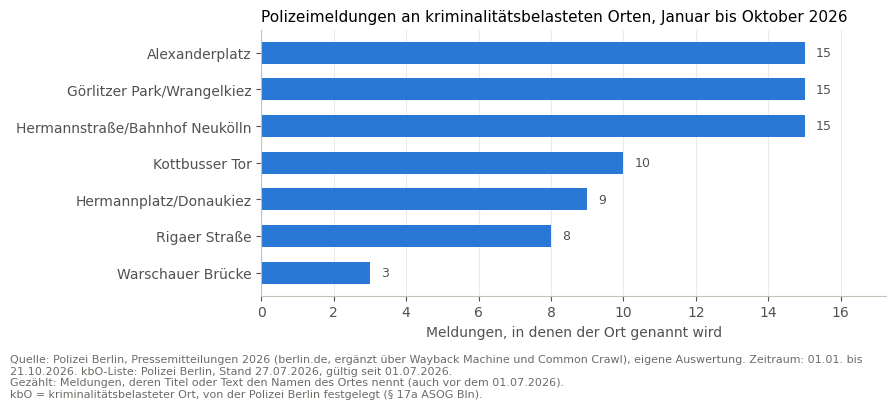

In [60]:
# Kriminalitätsbelastete Orte (kbO): Liste direkt von der Seite der Polizei Berlin laden
KBO_URL = "https://www.berlin.de/polizei/polizeimeldungen/fakten-hintergruende/artikel.1078268.php"
KBO_CACHE = OUT_DIR / "kbo_liste.json"
HEADERS = {"User-Agent": "osint-berlin-2026 (github.com/Amirhouschang)"}

if KBO_CACHE.exists():                                                   # einmal geladen, dann aus der Datei
    KBO = json.loads(KBO_CACHE.read_text(encoding="utf-8"))
    print("kbO-Liste aus der gespeicherten Datei:", KBO_CACHE)
else:
    seite = requests.get(KBO_URL, headers=HEADERS, timeout=30)
    seite.raise_for_status()
    zeilen_text = BeautifulSoup(seite.text, "lxml").get_text("\n")
    # jede Zeile, die nur aus "kbO <Name>" besteht, zum Beispiel "kbO Görlitzer Park/Wrangelkiez"
    KBO = sorted({m.group(1) for z in zeilen_text.splitlines()
                  if (m := re.fullmatch(r"kbO ([A-ZÄÖÜ][\wäöüß\-]*(?:[ /][\wäöüß\-]+){0,4})", z.strip()))})
    KBO_CACHE.write_text(json.dumps(KBO, ensure_ascii=False, indent=1), encoding="utf-8")
    print("kbO-Liste von berlin.de geladen und gespeichert:", KBO_CACHE)
print(len(KBO), "kriminalitätsbelastete Orte:", ", ".join(KBO))

# Meldungen je kbO: Suche nach den Namen im Text, "Görlitzer Park/Wrangelkiez" ergibt zwei Suchbegriffe
volltext = (df["titel"] + ". " + df["text"]).str.replace(KONTAKT, " ", regex=True)
kbo_zeilen = []
for kbo in KBO:
    muster = "|".join(re.escape(teil.strip()) for teil in kbo.split("/"))
    treffer = df[volltext.str.contains(muster, regex=True)]
    df[f"kbo_{kbo}"] = volltext.str.contains(muster, regex=True)
    kbo_zeilen.append({
        "kbO": kbo,
        "Meldungen": len(treffer),
        "Monate mit Meldung": treffer["monat"].nunique(),
        "häufigste Kategorien": ", ".join(f"{k} ({n})" for k, n in treffer["kategorie"].value_counts().head(3).items()),
    })
kbo_tabelle = pd.DataFrame(kbo_zeilen).sort_values("Meldungen", ascending=False).reset_index(drop=True)
display(kbo_tabelle)

fig, ax = plt.subplots(figsize=(9, 3.6))
daten = kbo_tabelle.sort_values("Meldungen")
ax.barh(daten["kbO"], daten["Meldungen"], color="#2a78d6", height=0.6)
for y, w in enumerate(daten["Meldungen"]):
    ax.text(w + 0.3, y, str(w), va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, daten["Meldungen"].max() * 1.15)
ax.set_xlabel("Meldungen, in denen der Ort genannt wird", color="#52514e")
ax.set_title("Polizeimeldungen an kriminalitätsbelasteten Orten, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}." + " kbO-Liste: Polizei Berlin, Stand 27.07.2026, gültig seit 01.07.2026.",
         "Gezählt: Meldungen, deren Titel oder Text den Namen des Ortes nennt (auch vor dem 01.07.2026).",
         BEGRIFF_KBO)
plt.show()

#### Interpretation: kriminalitätsbelastete Orte

- **Alexanderplatz, Görlitzer Park/Wrangelkiez und Hermannstraße/Bahnhof Neukölln kommen auf je 15 Meldungen**, danach folgen Kottbusser Tor (10), Hermannplatz/Donaukiez (9), Rigaer Straße (8) und Warschauer Brücke (3).
- **Jeder kbO hat ein eigenes Profil:**
  - Görlitzer Park: 6 der 15 Meldungen betreffen den Zaun oder die Tore des Parks, die beschädigt oder gestohlen wurden. Deshalb ist „Brand und Sachbeschädigung“ dort die häufigste Kategorie.
  - Hermannstraße/Bahnhof Neukölln: vor allem Schusswaffen und OK (5)
  - Rigaer Straße: vor allem politisch motiviert (4), mit brennenden Reifen auf der Fahrbahn und Angriffen auf Einsatzkräfte über das ganze Jahr
  - Alexanderplatz und Kottbusser Tor: gemischt, vor allem Raub und Gewalt
- **Die Zahlen sind eine Untergrenze.** Gezählt wird nur, wenn der Name im Text steht. Die kbO-Gebiete sind größer, ihre Grenzen stehen in der Anlage der Verordnung. Die Warschauer Brücke wird in den Meldungen oft anders genannt, die Hermannstraße dagegen wird auf ihrer ganzen Länge gezählt.

### 6.6 Koordinaten der Orte

Für die Karte braucht jeder Ort Koordinaten. Python fragt sie bei OpenStreetMap ab (Dienst Nominatim), nur für Orte mit mindestens 2 Meldungen.

- **Nur genaue Treffer zählen:** Der Name bei OpenStreetMap muss genau dem Namen aus der Meldung entsprechen, und die Art muss passen (Straße, Bahnhof, Park, Brücke oder Platz). Ortsteile und Gattungswörter wie „Radweg“ oder „Vorplatz“ finden so keinen Treffer und kommen nicht auf die Karte. Die Ausgabe listet sie am Ende auf.
- **Zwei Versuche:** Zuerst wird mit dem Bezirk der Meldung gesucht, dann ohne, weil der Bezirk nicht immer zum genannten Ort passt. Bei Bahnhöfen wird ohne „U-Bahnhof“ gesucht, weil OpenStreetMap den Bahnhof nur „Kottbusser Tor“ nennt.
- **Regeln von Nominatim:** höchstens eine Abfrage pro Sekunde, ein eigener Name für das Programm (User-Agent), Ergebnisse speichern. Jede Antwort wird sofort in `data/processed/geocode_orte.csv` gespeichert, ein Neustart macht dort weiter.

In [61]:
# Koordinaten für die Orte von OpenStreetMap (Nominatim), mit Cache-Datei wie beim Sprachmodell
# Regeln von Nominatim: höchstens 1 Abfrage pro Sekunde, eigener User-Agent, Ergebnisse speichern
GEO_CACHE = OUT_DIR / "geocode_orte.csv"
NOMINATIM = "https://nominatim.openstreetmap.org/search"
MIN_MELDUNGEN = 2                                  # nur Orte, die in mindestens 2 Meldungen vorkommen
ERLAUBT = {"highway", "railway", "public_transport", "leisure", "man_made", "place"}   # Straßen, Bahnhöfe, Parks, Brücken, Plätze
SUCHVERSION = 2                                    # Version 2: zweiter Versuch ohne Bezirk, Bahnhöfe ohne "U-Bahnhof"


def vergleichsform(name: str) -> str:
    """Name ohne U-/S-Bahnhof, klein, ß als ss, für den Vergleich mit dem OSM-Namen."""
    name = re.sub(r"^(?:S- und U-|U- und S-|U-|S-)?Bahnhof ", "", name)
    return name.casefold().replace("ß", "ss").replace("-", " ").strip()


def nominatim(frage: str, ort: str):
    """Eine Abfrage. Gültig ist nur ein Treffer mit genau diesem Namen und passender Art."""
    antwort = requests.get(NOMINATIM, headers=HEADERS, timeout=30, params={
        "q": frage, "format": "jsonv2", "limit": 5, "countrycodes": "de",
        "viewbox": "13.08,52.68,13.77,52.33", "bounded": 1})            # nur innerhalb von Berlin
    antwort.raise_for_status()
    time.sleep(1.1)                                                       # höchstens 1 Abfrage pro Sekunde
    for t in antwort.json():
        art_ok = t.get("category") in ERLAUBT and not (t.get("category") == "place" and t.get("type") != "square")
        if art_ok and vergleichsform(t.get("name", "")) == vergleichsform(ort):
            return {"lat": float(t["lat"]), "lon": float(t["lon"]), "osm_art": f'{t["category"]}/{t["type"]}'}
    return None


def koordinaten(ort: str, bezirk) -> dict:
    """Erst mit Bezirk suchen, dann ohne (der Bezirk der Meldung passt nicht immer zum genannten Ort)."""
    suchname = re.sub(r"^(?:S- und U-|U- und S-|U-|S-)?Bahnhof ", "", ort)    # "U-Bahnhof Kottbusser Tor" -> "Kottbusser Tor"
    fragen = ([f"{suchname}, {bezirk}, Berlin"] if isinstance(bezirk, str) else []) + [f"{suchname}, Berlin"]
    for frage in fragen:
        treffer = nominatim(frage, ort)
        if treffer:
            return {**treffer, "suchversion": SUCHVERSION}
    return {"lat": None, "lon": None, "osm_art": None, "suchversion": SUCHVERSION}   # kein echter Ortsname


suchen = ort_tabelle[ort_tabelle["meldungen"] >= MIN_MELDUNGEN][["ort", "bezirk"]]
geo = pd.read_csv(GEO_CACHE) if GEO_CACHE.exists() else pd.DataFrame(columns=["ort", "bezirk", "lat", "lon", "osm_art", "suchversion"])
if "suchversion" not in geo.columns:
    geo["suchversion"] = 1
# Nicht gefundene Orte aus einer älteren Suchversion noch einmal suchen, gefundene bleiben
geo = geo[geo["lat"].notna() | (geo["suchversion"] >= SUCHVERSION)]
geo.to_csv(GEO_CACHE, index=False)
offen = suchen.merge(geo[["ort", "bezirk"]], on=["ort", "bezirk"], how="left", indicator=True)
offen = offen[offen["_merge"] == "left_only"]
print(f"Orte mit mindestens {MIN_MELDUNGEN} Meldungen: {len(suchen)} | schon im Cache: {len(suchen) - len(offen)} "
      f"| offen: {len(offen)} (ca. {len(offen) * 2.2 / 60:.0f} Minuten)")

for _, r in tqdm(offen.iterrows(), total=len(offen), desc="Nominatim"):
    try:
        ergebnis = koordinaten(r["ort"], r["bezirk"])
    except requests.RequestException:
        time.sleep(5)                                                     # Netzwerkfehler: später erneut versuchen
        continue
    pd.DataFrame([{"ort": r["ort"], "bezirk": r["bezirk"], **ergebnis}]).to_csv(
        GEO_CACHE, mode="a", header=False, index=False)

geo = pd.read_csv(GEO_CACHE)
orte_geo = ort_tabelle.merge(geo, on=["ort", "bezirk"], how="inner")
gefunden = orte_geo[orte_geo["lat"].notna()]
nicht_gefunden = orte_geo[orte_geo["lat"].isna()]
print(f"Gefunden: {len(gefunden)} | nicht gefunden: {len(nicht_gefunden)}")
print("\nArt der gefundenen Orte bei OpenStreetMap:")
print(gefunden["osm_art"].value_counts().head(10).to_string())
print("\nNicht gefunden und deshalb NICHT auf der Karte (Gattungswörter oder Namen ohne genauen Treffer):")
print(", ".join(f"{o} ({n})" for o, n in nicht_gefunden.groupby("ort")["meldungen"].sum()
                .sort_values(ascending=False).items()))

Orte mit mindestens 2 Meldungen: 403 | schon im Cache: 403 | offen: 0 (ca. 0 Minuten)


Nominatim: 0it [00:00, ?it/s]

Gefunden: 382 | nicht gefunden: 21

Art der gefundenen Orte bei OpenStreetMap:
osm_art
highway/secondary        99
highway/residential      84
highway/tertiary         61
railway/station          51
highway/primary          38
place/square             10
railway/halt              7
leisure/park              6
highway/footway           6
highway/living_street     6

Nicht gefunden und deshalb NICHT auf der Karte (Gattungswörter oder Namen ohne genauen Treffer):
Radweg (12), Bahnsteig (8), Vorplatz (7), Endplatz (4), Querallee (4), Falkenhagener Feld (4), Krugallee (3), Fußgängerüberweg (2), Königsallee (2), Kleiner Querallee (2), Tempelhofer Feld (2), Wochenmarkt (2)


#### Interpretation: Koordinaten

- **382 der 403 Orte mit mindestens 2 Meldungen wurden gefunden** (95 %). Die meisten sind Straßen, dazu mindestens 58 Bahnhöfe und Haltepunkte, 10 Plätze und 6 Parks.
- **Die 21 nicht gefundenen Namen sind vor allem Gattungswörter**, also keine Orte: Radweg, Bahnsteig, Vorplatz, Fußgängerüberweg, Wochenmarkt. Sie kommen zu Recht nicht auf die Karte. Falkenhagener Feld ist ein Ortsteil und fällt deshalb ebenfalls heraus.
- **Einige echte Orte fehlen trotzdem**, zum Beispiel Krugallee, Königsallee, Querallee und Tempelhofer Feld. Sie haben jeweils höchstens 4 Meldungen und verändern das Gesamtbild nicht.

### 6.7 Karte

Die Bezirke sind nach der Zahl der Meldungen eingefärbt, die Grenzen kommen vom Geodatenportal Berlin. Jeder Punkt ist ein Ort mit mindestens 3 Meldungen, die Größe zeigt die Zahl der Meldungen. Rote Punkte sind kriminalitätsbelastete Orte.

Es gibt zwei Fassungen:

1. **Feste Karte im Notebook** (matplotlib): Sie wird überall angezeigt, auch auf GitHub. Beschriftet sind die zehn häufigsten Orte. Wo es eng wird, steht der Name etwas weiter weg und eine dünne Linie zeigt auf den Punkt.
2. **Interaktive Karte** als `data/processed/karte_orte.html` zum Öffnen im Browser. Die Bezirke sind mit Name und Zahl beschriftet. Beim Darüberfahren mit der Maus erscheinen bei einem Punkt Ort, Zahl der Meldungen und häufigste Kategorie, bei einem Bezirk Name und Zahl der Meldungen. Sie hat keinen Straßenhintergrund, weil die Kartenserver von OpenStreetMap Abrufe aus einer lokalen Datei sperren („Access blocked“).

Bezirksname im Feld: namgem
Punkte auf der Karte: 168, davon an kriminalitätsbelasteten Orten: 10
Punkte je Bezirk der Meldung: Mitte 28, Friedrichshain-Kreuzberg 25, Charlottenburg-Wilmersdorf 15, Neukölln 13, Tempelhof-Schöneberg 13, Treptow-Köpenick 12, Marzahn-Hellersdorf 11, Spandau 11, Steglitz-Zehlendorf 9, Lichtenberg 8, Pankow 8, Reinickendorf 8


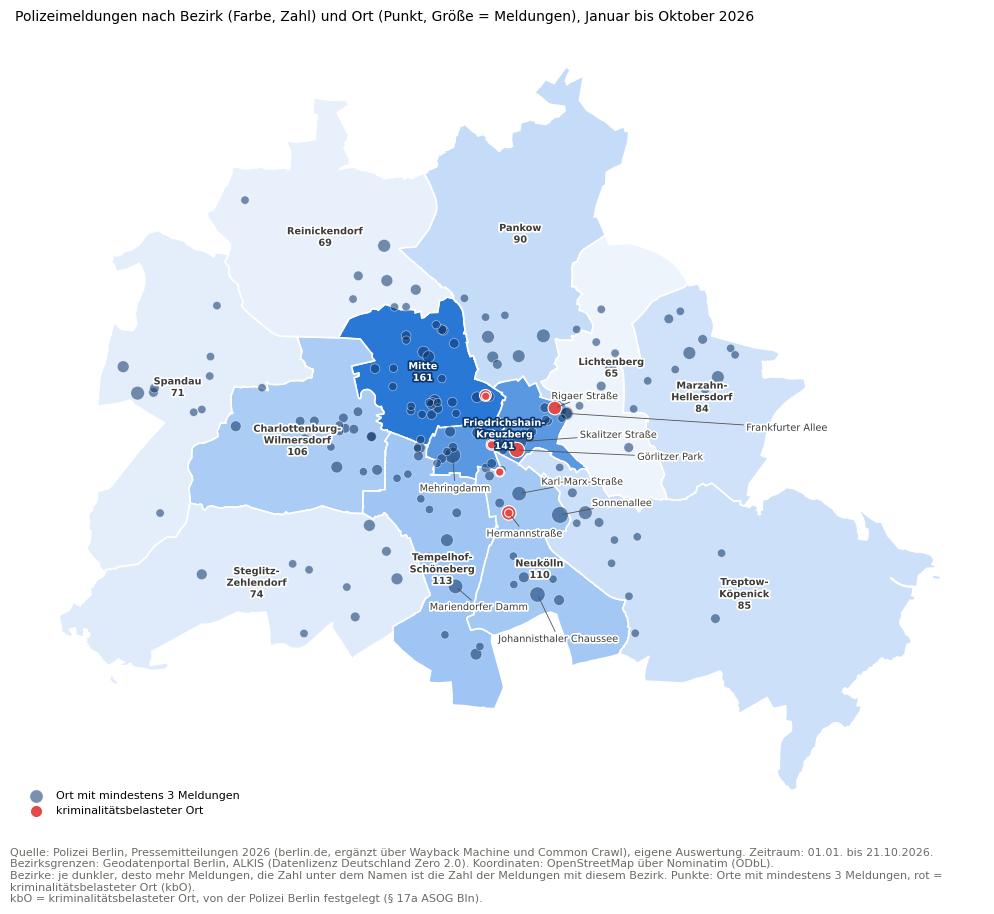

Interaktive Karte gespeichert: /home/amir/Dokumente/Github_projects/berlin_osint_2026/data/processed/karte_orte.html


In [62]:
# Karte: Bezirke eingefärbt nach Zahl der Meldungen, Orte als Punkte (Größe = Zahl der Meldungen)
import folium
from adjustText import adjust_text
from matplotlib import patheffects
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon as Flaeche

BEZIRKE_DATEI = ROOT / "data" / "raw" / "bezirksgrenzen.geojson"
BEZIRKE_WFS = ("https://gdi.berlin.de/services/wfs/alkis_bezirke?service=WFS&version=2.0.0&request=GetFeature"
               "&typeNames=alkis_bezirke:bezirksgrenzen&outputFormat=application/json&srsName=EPSG:4326")
if not BEZIRKE_DATEI.exists():                                          # einmal laden, dann aus der Datei
    BEZIRKE_DATEI.write_text(requests.get(BEZIRKE_WFS, headers=HEADERS, timeout=60).text, encoding="utf-8")
bezirke_geo = json.loads(BEZIRKE_DATEI.read_text(encoding="utf-8"))


def tausche_achsen(koord):
    """Dreht (Breite, Länge) zu (Länge, Breite), falls der Dienst die Achsen andersherum liefert."""
    if isinstance(koord[0], (int, float)):
        return [koord[1], koord[0]]
    return [tausche_achsen(k) for k in koord]


def ringe(geometrie):
    """Alle äußeren Ringe eines Polygons oder Multipolygons als Liste von (Länge, Breite)-Punkten."""
    if geometrie["type"] == "Polygon":
        return [geometrie["coordinates"][0]]
    return [teil[0] for teil in geometrie["coordinates"]]


erster_punkt = ringe(bezirke_geo["features"][0]["geometry"])[0][0]
if erster_punkt[0] > 40:                                                 # 52,... zuerst bedeutet Breite zuerst
    for f in bezirke_geo["features"]:
        f["geometry"]["coordinates"] = tausche_achsen(f["geometry"]["coordinates"])

# Welches Feld enthält den Bezirksnamen? Das Feld, dessen Werte zu den Bezirken in den Daten passen
eigenschaften = bezirke_geo["features"][0]["properties"]
NAMENSFELD = max(eigenschaften, key=lambda feld: sum(
    str(f["properties"].get(feld)) in set(pro_bezirk.index) for f in bezirke_geo["features"]))
print(f"Bezirksname im Feld: {NAMENSFELD}")

KBO_BEGRIFFE = [teil.strip() for kbo in KBO for teil in kbo.split("/")]
punkte = gefunden[gefunden["meldungen"] >= 3].copy()
punkte["kbo"] = [any(vergleichsform(b) in vergleichsform(o) for b in KBO_BEGRIFFE) for o in punkte["ort"]]
print(f"Punkte auf der Karte: {len(punkte)}, davon an kriminalitätsbelasteten Orten: {punkte['kbo'].sum()}")
print("Punkte je Bezirk der Meldung:", ", ".join(f"{b} {n}" for b, n in punkte["bezirk"].value_counts().items()))

def schwerpunkt(ring):
    """Flächenschwerpunkt eines Rings (Gaußsche Trapezformel), für die Beschriftung der Bezirke."""
    a = cx = cy = 0.0
    for (x0, y0), (x1, y1) in zip(ring[:-1], ring[1:]):
        k = x0 * y1 - x1 * y0
        a, cx, cy = a + k, cx + (x0 + x1) * k, cy + (y0 + y1) * k
    return cx / (3 * a), cy / (3 * a)


# 1. Feste Karte mit matplotlib: wird überall angezeigt, auch auf GitHub
BLAU = LinearSegmentedColormap.from_list("blau", ["#eef4fc", "#9ec5f4", "#2a78d6"])
skala = Normalize(vmin=pro_bezirk.min(), vmax=pro_bezirk.max())
fig, ax = plt.subplots(figsize=(10, 8.5))
bezirk_texte = []
for f in bezirke_geo["features"]:
    name = f["properties"][NAMENSFELD]
    for ring in ringe(f["geometry"]):
        ax.add_patch(Flaeche(ring, closed=True, facecolor=BLAU(skala(pro_bezirk.get(name, 0))),
                             edgecolor="white", linewidth=1.2))
    x, y = schwerpunkt(max(ringe(f["geometry"]), key=len))                # Mitte der größten Teilfläche
    dunkel = skala(pro_bezirk.get(name, 0)) > 0.7                         # auf dunkler Fläche weiße Schrift
    bezirk_texte.append(ax.text(
        x, y, f"{name.replace('-', '-' + chr(10))}\n{pro_bezirk.get(name, 0)}", ha="center", va="center",
        fontsize=7, fontweight="bold", zorder=5, color="white" if dunkel else "#3d3c39",
        path_effects=[patheffects.withStroke(linewidth=2.5, foreground="#0d366b" if dunkel else "white")]))
normal = punkte[~punkte["kbo"]]
ax.scatter(normal["lon"], normal["lat"], s=normal["meldungen"] * 12, color="#0d366b", alpha=0.55,
           edgecolor="white", linewidth=0.5, label="Ort mit mindestens 3 Meldungen")
kbo_punkte = punkte[punkte["kbo"]]
ax.scatter(kbo_punkte["lon"], kbo_punkte["lat"], s=kbo_punkte["meldungen"] * 12, color="#e34948",
           edgecolor="white", linewidth=0.8, label="kriminalitätsbelasteter Ort")
ax.set_aspect(1 / 0.61)                                                   # Längengrade in Berlin sind kürzer (cos 52,5°)
ax.autoscale_view()
top = punkte.nlargest(10, "meldungen")                                    # die zehn häufigsten Orte beschriften
ort_texte = [ax.text(p["lon"], p["lat"], p["ort"], fontsize=7, color="#3d3c39", zorder=6,
                     path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")])
             for _, p in top.iterrows()]
# adjustText schiebt die Namen auseinander, weg von den Punkten und den Bezirksnamen; eine Linie zeigt auf den Ort
# Die Bezirksnamen sollen frei bleiben: ihre Fläche wird mit unsichtbaren Punkten belegt, die adjustText meidet
fig.canvas.draw()
meiden_x, meiden_y = punkte["lon"].tolist(), punkte["lat"].tolist()
for t in bezirk_texte:
    kasten = t.get_window_extent().transformed(ax.transData.inverted())
    for i in range(6):
        for j in range(4):
            meiden_x.append(kasten.x0 + kasten.width * i / 5)
            meiden_y.append(kasten.y0 + kasten.height * j / 3)
adjust_text(ort_texte, x=meiden_x, y=meiden_y, ax=ax,
            target_x=top["lon"].tolist(), target_y=top["lat"].tolist(), expand=(1.3, 1.6),
            force_text=(0.4, 0.6), max_move=(15, 15), iter_lim=1000,
            arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.6))
ax.axis("off")
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.set_title("Polizeimeldungen nach Bezirk (Farbe, Zahl) und Ort (Punkt, Größe = Meldungen), Januar bis Oktober 2026",
             loc="left", fontsize=10)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_POLIZEI}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         "Bezirksgrenzen: Geodatenportal Berlin, ALKIS (Datenlizenz Deutschland Zero 2.0). Koordinaten: OpenStreetMap über Nominatim (ODbL).",
         "Bezirke: je dunkler, desto mehr Meldungen, die Zahl unter dem Namen ist die Zahl der Meldungen mit diesem Bezirk. "
         "Punkte: Orte mit mindestens 3 Meldungen, rot = kriminalitätsbelasteter Ort (kbO).", BEGRIFF_KBO)
plt.show()

# 2. Interaktive Karte als HTML-Datei, zum Öffnen im Browser (ohne Kartenhintergrund,
#    weil die Kartenserver von OpenStreetMap Abrufe aus lokalen Dateien sperren)
karte = folium.Map(location=[52.52, 13.405], zoom_start=10, tiles=None)
folium.Choropleth(
    geo_data=bezirke_geo, data=pro_bezirk.rename_axis("bezirk").reset_index(name="meldungen"),
    columns=["bezirk", "meldungen"], key_on=f"feature.properties.{NAMENSFELD}",
    fill_color="Blues", fill_opacity=0.6, line_color="#52514e", line_weight=1,
    legend_name="Meldungen pro Bezirk",
).add_to(karte)
# Bezirksnamen fest auf die Karte schreiben, dazu ein Hinweis beim Darüberfahren
for f in bezirke_geo["features"]:
    name = f["properties"][NAMENSFELD]
    f["properties"]["meldungen"] = int(pro_bezirk.get(name, 0))
    x, y = schwerpunkt(max(ringe(f["geometry"]), key=len))
    folium.Marker(location=[y, x], interactive=False, icon=folium.DivIcon(   # interactive=False: Punkte darunter bleiben anklickbar
        icon_size=(130, 30), icon_anchor=(65, 15),
        html=(f'<div style="font-size:11px;font-weight:bold;color:#3d3c39;text-align:center;'
              f'text-shadow:0 0 3px white,0 0 3px white;pointer-events:none">'
              f'{name.replace("-", "-<br>")}<br>{pro_bezirk.get(name, 0)}</div>'))).add_to(karte)
folium.GeoJson(
    bezirke_geo, style_function=lambda f: {"fillOpacity": 0, "weight": 0},   # unsichtbar, nur für den Hinweis
    tooltip=folium.GeoJsonTooltip(fields=[NAMENSFELD, "meldungen"], aliases=["Bezirk", "Meldungen"]),
).add_to(karte)
for _, p in punkte.iterrows():
    folium.CircleMarker(
        location=[p["lat"], p["lon"]], radius=3 + p["meldungen"] ** 0.5 * 2.5,
        color="#c0392b" if p["kbo"] else "#0d366b", weight=2 if p["kbo"] else 1,
        fill=True, fill_color="#e34948" if p["kbo"] else "#2a78d6", fill_opacity=0.75,
        tooltip=(f"{p['ort']} ({p['bezirk'] if isinstance(p['bezirk'], str) else 'ohne Bezirk'}): "
                 f"{p['meldungen']} Meldungen, meist {p['haeufigste_kategorie']}" + (" · kbO" if p["kbo"] else "")),
    ).add_to(karte)
# Titel oben und Quellen unten, damit die Karte auch allein verständlich ist
folium.Element(
    '<div style="position:fixed;top:10px;left:50px;z-index:9999;background:white;padding:6px 10px;'
    'font:14px sans-serif;color:#3d3c39;border-radius:4px;box-shadow:0 0 4px #aaa">'
    'Polizeimeldungen nach Bezirk (Farbe, Zahl) und Ort (Punkt, Größe = Meldungen), Januar bis Oktober 2026<br>'
    '<span style="font-size:12px">Punkte: Orte mit mindestens 3 Meldungen, rot = kriminalitätsbelasteter Ort (kbO)</span></div>'
    '<div style="position:fixed;bottom:10px;left:10px;z-index:9999;background:white;padding:4px 8px;'
    f'font:11px sans-serif;color:#6b6a65;border-radius:4px">Quelle: {QUELLE_POLIZEI}, eigene Auswertung. '
    f'Zeitraum: {ZEITRAUM_TEXT}.<br>Bezirksgrenzen: Geodatenportal Berlin, ALKIS (Datenlizenz Deutschland Zero 2.0). '
    'Koordinaten: OpenStreetMap über Nominatim (ODbL).</div>'
).add_to(karte.get_root().html)
KARTE_DATEI = OUT_DIR / "karte_orte.html"
karte.save(KARTE_DATEI)
print("Interaktive Karte gespeichert:", KARTE_DATEI)

#### Interpretation: Karte

- **Die Orte ballen sich in der Innenstadt.** Von den 168 Orten mit mindestens 3 Meldungen liegen 66 in Mitte (28), Friedrichshain-Kreuzberg (25) und Neukölln (13), obwohl diese drei Bezirke nur einen kleinen Teil der Stadtfläche ausmachen.
- **In den Außenbezirken liegen die Punkte vor allem an großen Straßen**, etwa der Heerstraße in Spandau. Dort geht es meist um Verkehr (6.3, 6.4).
- **Alle kriminalitätsbelasteten Orte liegen in Mitte, Friedrichshain-Kreuzberg und Neukölln.** Auf der Karte liegen sie innerhalb der dichtesten Ballung.
- **Die Karte zeigt, wo die Polizei über Vorfälle berichtet, nicht wo am meisten passiert.** Es gelten dieselben Einschränkungen wie für die Meldungen insgesamt, dazu die Grenzen der Ortssuche (Limitations).

## 7. Medien: Berichterstattung über GDELT

Leitfrage 4 vergleicht Polizeimeldungen und Medien. Die Medienartikel kommen aus GDELT, einer frei zugänglichen Datenbank, die weltweit Online-Nachrichten erfasst. Gespeichert werden nur Titel, Adresse, Datum und Quelle der Artikel, keine Volltexte.

Untersucht werden die Themen aus 5.7 und zusätzlich zwei Themen:

1. **Gewalt gegen Polizei in Berlin** (Gegenstück zu 5.8)
2. **Gewalt durch die Polizei in Berlin**, getrennt in drei Themen: Schusswaffe durch Polizei, Taser/DEIG durch Polizei und Vorwürfe gegen Polizei

### 7.1 Test: GDELT-DOC-API

Zuerst wurde die DOC-API von GDELT getestet, eine einfache Suchschnittstelle im Internet. Für jedes der vier Ereignisse aus 5.1 wurde nach deutschsprachigen Artikeln rund um das Datum gesucht. Der Testcode ist nicht mehr im Notebook, weil die API nicht nutzbar war und jeder Lauf mehrere Minuten gewartet hätte.

#### Ergebnis 7.1

- **Die DOC-API ist nicht nutzbar.** Bei allen Anfragen kam entweder Status 429 (zu viele Anfragen) oder eine leere Antwort zurück, auch mit Pausen zwischen den Anfragen. Der Test dauerte knapp 8 Minuten und lieferte keinen einzigen Artikel.
- **Folge:** Die Artikel werden stattdessen über Google BigQuery abgefragt. Dort liegt die vollständige GDELT-Datenbank (Global Knowledge Graph) ohne diese Sperre.

### 7.2 Verbindung zu BigQuery

Die BigQuery-Sandbox ist kostenlos und braucht keine Kreditkarte. Sie erlaubt 1 TB Abfragen pro Monat.

**Einmalige Einrichtung:**

1. Auf https://console.cloud.google.com/bigquery mit einem Google-Konto anmelden und ein Projekt anlegen.
2. Die Projekt-ID (z. B. `osint-berlin-123456`) unten bei `PROJEKT` eintragen.
3. Pakete installieren: `pip install google-cloud-bigquery db-dtypes pydata-google-auth`
4. Beim ersten Lauf öffnet sich der Browser für die Anmeldung. Der Zugang wird lokal gespeichert, nicht im Notebook.

**Was die Zelle prüft:**

1. Wie viele GB die ganze Abfrage (01.01. bis 21.10.2026) lesen würde. Das ist ein Probelauf, er verbraucht nichts.
2. Ob es für einen Tag (20.09.2026, Wahltag) Artikel gibt und ob Titel und GDELT-Themen mitgeliefert werden. Themen und Orte werden für den Vergleich mit den Kategorien und Bezirken der Polizeimeldungen gebraucht.

Ausgewählt werden deutschsprachige Artikel (`srclc:deu`), die einen Ort im Land Berlin nennen (GDELT-Code `GM16`).

In [63]:
# Verbindung zu BigQuery testen: Gibt es GDELT-Daten für 2026, und wie viel würde die ganze Abfrage kosten?
# Einmalig: pip install google-cloud-bigquery db-dtypes pydata-google-auth
import pydata_google_auth
from google.cloud import bigquery

PROJEKT = "osint-berlin-2026"                     # die ID aus der Google Cloud Console (BigQuery-Sandbox)
GKG = "gdelt-bq.gdeltv2.gkg_partitioned"
ZEITRAUM = ("2026-01-01", "2026-10-21")
GRENZE_GB = 300                                    # Sicherheitsgrenze, die Sandbox erlaubt 1 TB pro Monat

# Anmeldung im Browser beim ersten Lauf, danach wird der Zugang gespeichert
zugang = pydata_google_auth.get_user_credentials(["https://www.googleapis.com/auth/bigquery"])
client = bigquery.Client(project=PROJEKT, credentials=zugang)

# Deutschsprachige Artikel (srclc:deu), die einen Ort im Land Berlin nennen (ADM1-Code GM16)
SQL = f"""
SELECT
  DATE AS zeit,
  SourceCommonName AS quelle,
  DocumentIdentifier AS url,
  REGEXP_EXTRACT(Extras, r'<PAGE_TITLE>(.*?)</PAGE_TITLE>') AS titel,
  V2Themes AS themen,                              -- GDELT-Themen, z. B. CRIME, ARREST, PROTEST
  V2Locations AS orte                              -- genannte Orte, für die Bezirke in Abschnitt 6
FROM `{GKG}`
WHERE _PARTITIONTIME BETWEEN TIMESTAMP(@von) AND TIMESTAMP(@bis)
  AND TranslationInfo LIKE '%srclc:deu%'
  AND V2Locations LIKE '%#GM16#%'
"""


def abfrage(von: str, bis: str, probe: bool = False) -> bigquery.QueryJob:
    """Führt die Abfrage aus. probe=True rechnet nur die Datenmenge aus, ohne etwas zu verbrauchen."""
    einstellung = bigquery.QueryJobConfig(
        dry_run=probe, use_query_cache=False,
        query_parameters=[bigquery.ScalarQueryParameter("von", "STRING", von),
                          bigquery.ScalarQueryParameter("bis", "STRING", bis)])
    return client.query(SQL, job_config=einstellung)


# 1. Was würde die ganze Abfrage kosten? (Probelauf, verbraucht nichts)
gb = abfrage(*ZEITRAUM, probe=True).total_bytes_processed / 1e9
print(f"Ganze Abfrage {ZEITRAUM[0]} bis {ZEITRAUM[1]}: {gb:.0f} GB "
      f"({'unter' if gb < GRENZE_GB else 'ÜBER'} der Grenze von {GRENZE_GB} GB)")

# 2. Ein Tag als Stichprobe: Gibt es Daten, und enthält die Spalte Extras den Titel?
probe_tag = abfrage("2026-09-20", "2026-09-20").to_dataframe()
print(f"Stichprobe 20.09.2026: {len(probe_tag)} Artikel, davon mit Titel: {probe_tag['titel'].fillna('').str.strip().ne('').sum()}, "
      f"mit Themen: {probe_tag['themen'].notna().sum()}")
display(probe_tag[["zeit", "quelle", "titel"]].head(10))


Ganze Abfrage 2026-01-01 bis 2026-10-21: 176 GB (unter der Grenze von 300 GB)


/home/amir/miniconda3/envs/jupyter-env/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Stichprobe 20.09.2026: 1021 Artikel, davon mit Titel: 1021, mit Themen: 997


,zeit,quelle,titel
0,20260920234500,die-glocke.de,Clan-Mitglied auf Linken-Party - Partei distanziert sich
1,20260920234500,rnz.de,Abgeordnetenhauswahl: Linke will Berlin regieren &#x2013; Streit um Enteignu...
2,20260920234500,wdr.de,"Junge Union im Kreis Paderborn: ""Unfassbares Ergebnis"""
3,20260920233000,mz.de,Wahl zum Abgeordnetenhaus: Eralp gewinnt Direktmandat mit gro&#xDF;em Vorsprung
4,20260920233000,n-tv.de,Berlin & Brandenburg: Eralp gewinnt Direktmandat mit gro&#xDF;em Vorsprung
5,20260920233000,mz.de,Landtagswahl in MV: Vorl&#xE4;ufiges Ergebnis: AfD siegt in MV
6,20260920233000,mz.de,Landtagswahlen: CDU im Nordosten unter f&#xFC;nf Prozent &#x2013; Linke sieg...
7,20260920233000,mz.de,Wahl zum Abgeordnetenhaus: Berliner CDU-Spitzenkandidat Evers verliert Direk...
8,20260920233000,mz.de,"Wahl in Berlin: &#x201E;Stadt ver&#xE4;ndern"": Linke greift in Berlin nach d..."
9,20260920233000,mz.de,Abgeordnetenhauswahl: Clan-Mitglied auf Linken-Party - Partei distanziert sich


#### Ergebnis 7.2

- **Die Verbindung steht.** Die ganze Abfrage liest 176 GB und liegt damit unter der Grenze von 300 GB. Mit 1 TB pro Monat reicht das für höchstens fünf volle Läufe, deshalb wird das Ergebnis in 7.3 einmal gespeichert und danach nur noch geladen.
- **Titel und Themen sind vorhanden.** Am 20.09.2026 gab es 1021 Artikel, alle mit Titel und 997 mit GDELT-Themen.
- **Sonderzeichen sind kodiert.** In den Titeln steht z. B. `&#xDF;` statt ß. Python wandelt das in 7.3 um.
- **Nicht jeder Artikel handelt von Berlin.** Schon die Stichprobe enthält Titel zur Landtagswahl in Mecklenburg-Vorpommern und zur Jungen Union in Paderborn. GDELT zählt jeden Artikel, der irgendwo einen Berliner Ort nennt. Die Artikel werden deshalb in den nächsten Schritten nach Themen gefiltert.
- **Die Warnung „BigQuery Storage module not found“ ist harmlos.** Die Daten kommen dann über einen langsameren, aber kostenlosen Weg.

### 7.3 Abfrage für den ganzen Zeitraum

Die Zelle fragt alle deutschsprachigen Artikel mit Berlin-Bezug vom 01.01. bis 21.10.2026 ab und speichert sie als `data/raw/gdelt_berlin_2026.csv`. Die Datei bleibt lokal und kommt nicht auf GitHub. Ist sie schon vorhanden, wird nur die Datei geladen und BigQuery nicht erneut abgefragt.

Gespeichert werden:

1. Zeit, Quelle, Adresse und Titel des Artikels
2. die GDELT-Themen, jedes nur einmal
3. die genannten Orte im Land Berlin

Die Zelle braucht `client`, `GKG`, `ZEITRAUM` und `GRENZE_GB` aus 7.2. Der erste Lauf kann einige Minuten dauern.

In [64]:
# Alle deutschsprachigen Berlin-Artikel 01.01. bis 21.10.2026 einmal abfragen und lokal speichern
# Die Abfrage liest rund 176 GB (siehe 7.2). Ist die Datei schon da, wird sie nur geladen, BigQuery wird nicht erneut abgefragt.
import html
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
GDELT_DATEI = ROOT / "data" / "raw" / "gdelt_berlin_2026.csv"   # bleibt lokal, nicht auf GitHub

# Wie 7.2, zusätzlich:
# themen: jedes GDELT-Thema nur einmal, ohne Textposition (spart Speicher)
# orte_berlin: nur die Orte im Land Berlin (GM16), ohne Koordinaten
SQL_JAHR = f"""
SELECT
  DATE AS zeit,
  SourceCommonName AS quelle,
  DocumentIdentifier AS url,
  REGEXP_EXTRACT(Extras, r'<PAGE_TITLE>(.*?)</PAGE_TITLE>') AS titel,
  ARRAY_TO_STRING(ARRAY(
    SELECT DISTINCT SPLIT(t, ',')[OFFSET(0)]
    FROM UNNEST(SPLIT(V2Themes, ';')) AS t WHERE t != ''), ';') AS themen,
  ARRAY_TO_STRING(ARRAY(
    SELECT DISTINCT SPLIT(o, '#')[SAFE_OFFSET(1)]
    FROM UNNEST(SPLIT(V2Locations, ';')) AS o WHERE o LIKE '%#GM16#%'), ';') AS orte_berlin
FROM `{GKG}`
WHERE _PARTITIONTIME BETWEEN TIMESTAMP(@von) AND TIMESTAMP(@bis)
  AND DATE BETWEEN 20260101000000 AND 20261021235959
  AND TranslationInfo LIKE '%srclc:deu%'
  AND V2Locations LIKE '%#GM16#%'
"""

if GDELT_DATEI.exists():
    medien = pd.read_csv(GDELT_DATEI, parse_dates=["zeit"])
    print(f"Geladen aus {GDELT_DATEI.name} (keine neue Abfrage)")
else:
    einstellung = lambda probe: bigquery.QueryJobConfig(
        dry_run=probe, use_query_cache=False,
        query_parameters=[bigquery.ScalarQueryParameter("von", "STRING", ZEITRAUM[0]),
                          bigquery.ScalarQueryParameter("bis", "STRING", ZEITRAUM[1])])
    # Sicherheitsprüfung vor dem echten Lauf
    gb = client.query(SQL_JAHR, job_config=einstellung(True)).total_bytes_processed / 1e9
    print(f"Abfrage liest {gb:.0f} GB")
    if gb > GRENZE_GB:
        raise RuntimeError(f"Abfrage größer als {GRENZE_GB} GB, abgebrochen")

    medien = client.query(SQL_JAHR, job_config=einstellung(False)).to_dataframe()
    medien["zeit"] = pd.to_datetime(medien["zeit"].astype(str), format="%Y%m%d%H%M%S")
    medien["titel"] = medien["titel"].map(lambda t: html.unescape(t).strip() if isinstance(t, str) else t)  # &#xDF; wird zu ß
    GDELT_DATEI.parent.mkdir(parents=True, exist_ok=True)
    medien.to_csv(GDELT_DATEI, index=False)
    print(f"Gespeichert: {GDELT_DATEI.name}")

# Gleiche Adresse mehrfach (z. B. aktualisierter Artikel) nur einmal zählen
vorher = len(medien)
medien = medien.drop_duplicates("url").reset_index(drop=True)
tage = medien["zeit"].dt.normalize()

print(f"Artikel: {len(medien)} (doppelte Adressen entfernt: {vorher - len(medien)})")
print(f"Zeitraum: {tage.min():%d.%m.%Y} bis {tage.max():%d.%m.%Y}, Tage mit Artikeln: {tage.nunique()}")
print(f"Quellen: {medien['quelle'].nunique()}, Artikel pro Tag im Mittel: {len(medien) / tage.nunique():.0f}")
print(f"Ohne Titel (leer): {(medien['titel'].fillna('').str.strip() == '').sum()}, "
      f"ohne Themen: {(medien['themen'].fillna('') == '').sum()}")
display(medien[["zeit", "quelle", "titel", "orte_berlin"]].sample(10, random_state=1))


Geladen aus gdelt_berlin_2026.csv (keine neue Abfrage)
Artikel: 132636 (doppelte Adressen entfernt: 0)
Zeitraum: 01.01.2026 bis 21.10.2026, Tage mit Artikeln: 294
Quellen: 511, Artikel pro Tag im Mittel: 451
Ohne Titel (leer): 44, ohne Themen: 10441


,zeit,quelle,titel,orte_berlin
50935,2026-03-12 05:00:00,tz.de,Karriere Menü Folge 2 mit Sebastian Frank: Sternekoch & Sellerie,"Berlin, Berlin, Germany"
63028,2026-04-26 10:15:00,berliner-kurier.de,Das kommt im Mai: Was Verbraucher jetzt wissen müssen,"Berlin, Berlin, Germany"
5511,2026-10-12 23:00:00,finanznachrichten.de,Wissler wirbt für Rot-Grün-Rot in Berlin,"Berlin, Berlin, Germany"
113551,2026-02-27 08:45:00,badische-zeitung.de,Warnstreiks im Nahverkehr vielerorts in Deutschland angelaufen,"Berlin, Berlin, Germany"
28761,2026-08-06 07:45:00,t-online.de,"Demo Plauen: Bewegung ""M1llion"" mobilisiert in Sachsen – was ihr Ziel ist","Berlin, Berlin, Germany"
113529,2026-02-27 09:15:00,gmx.at,Warnstreiks im Nahverkehr vielerorts angelaufen,"Berlin, Berlin, Germany"
18437,2026-08-21 23:30:00,shz.de,Gegen Hitze: Warum Städte Straßen und Parkplätze opfern müssen,"Berlin, Berlin, Germany"
125490,2026-05-06 14:15:00,volksstimme.de,Durchsuchungen: Nach Gewalttaten: Razzia gegen junge Neonazi-Gruppen,"Berlin, Berlin, Germany"
92317,2026-02-05 15:00:00,n-tv.de,Hamburg & Schleswig-Holstein: Schleswig-Holstein macht weniger Schulden,"Berlin, Berlin, Germany"
69835,2026-05-07 20:15:00,derwesten.de,"NRW-Minister schwant Böses bei Lanz: ""Werden das nicht überleben""","Berlin, Berlin, Germany"


#### Ergebnis 7.3

- **132.636 Artikel** aus 511 Quellen, im Mittel 451 pro Tag. Doppelte Adressen gab es keine.
- **Alle 294 Tage** vom 01.01. bis 21.10.2026 haben Artikel, es gibt also keine Lücke in den Daten.
- **Fast alle Artikel haben einen Titel,** nur 44 Titel sind leer. 10.441 Artikel (7,9 %) haben keine GDELT-Themen.
- **Der Ort ist meist nur „Berlin“.** In der Stichprobe von 10 Artikeln steht bei allen nur „Berlin, Berlin, Germany“, also die Stadt als Ganzes. Bezirke und Orte werden deshalb nicht flächendeckend verglichen. Wo ein Artikel einen Bezirk oder Ort nennt, zeigt die Auswertung, in welchem Zusammenhang er genannt wird.
- **Viele Artikel handeln nicht von Berlin**, z. B. Warnstreiks „vielerorts“, Hamburg oder NRW. Der nächste Schritt filtert deshalb die Artikel zu Polizei und Kriminalität heraus.

### 7.4 Auswahl: Artikel zu Polizei und Kriminalität in Berlin

Von den Artikeln aus 7.3 handeln viele nicht von Berlin oder nicht von Polizei und Kriminalität. Ausgewählt wird ein Artikel, wenn sein Titel beide Bedingungen erfüllt:

1. **Berlin-Bezug:** Der Titel nennt Berlin oder einen Berliner Ort. Die Orte stammen aus den Polizeimeldungen: Bezirke (ohne „Mitte“, das auch ein Alltagswort ist), die Orte mit Treffer bei OpenStreetMap aus 6.6 und die kbO aus 6.5. Rubriken wie „Berlin & Brandenburg:“ und Ortsangaben wie „bei Berlin“ zählen nicht.
2. **Polizei oder Kriminalität:** Eine Kategorie aus 4.3 trifft zu (außer „Prävention und Service“), oder der Titel enthält ein Wort wie Polizei, Festnahme, Anschlag oder Demo.

Die Kategorien aus 4.3 werden unverändert übernommen, damit Medien und Polizeimeldungen in Abschnitt 8 mit denselben Regeln verglichen werden. Die GDELT-Orte aus 7.3 werden für die Auswahl nicht verwendet, weil sie auch Artikel erfassen, die Berlin nur im Text nebenbei nennen.

**Zwei Prüfungen:**

1. **GDELT-Themen:** GDELT vergibt die Themen selbst, unabhängig von den Suchwörtern. Passt die Auswahl, kommen Polizei- und Kriminalitätsthemen dort deutlich häufiger vor als im Rest.
2. **Stichprobe:** 20 zufällige Titel aus der Auswahl zum Nachlesen.

In [65]:
# Artikel zu Polizei und Kriminalität in Berlin herausfiltern
# Zwei Bedingungen, beide im Titel:
#   1. Berlin-Bezug: "Berlin" oder ein Berliner Ort, den Python schon in den Polizeimeldungen gefunden hat
#   2. Polizei oder Kriminalität: eine Kategorie aus 4.3 trifft, oder ein Wort wie Polizei, Festnahme, Anschlag
import re
from collections import Counter

# 7.4 braucht Ergebnisse aus früheren Abschnitten, das Notebook muss also von oben ausgeführt sein
fehlt = [n for n in ["df", "MUSTER", "KBO", "GEO_CACHE", "medien"] if n not in globals()]
if fehlt:
    raise RuntimeError(f"Es fehlen {', '.join(fehlt)}. Bitte das Notebook von oben ausführen (Run All).")

# 1. Berlin-Bezug
BERLIN = re.compile(r"\bBerlin\w*")
NICHT_BERLIN = re.compile(r"Berlin ?(?:&|/|und) ?Brandenburg:|(?:bei|nahe|vor den Toren von) Berlin\b")  # Rubrik bzw. Umland
bezirksteile = {teil for b in df["bezirk"].dropna().unique() for teil in b.split("-")} - {"Mitte"}  # "Mitte" ist auch ein Alltagswort
orte_osm = set(pd.read_csv(GEO_CACHE).dropna(subset=["lat"])["ort"])        # Orte aus 6.6 mit Treffer bei OpenStreetMap
kbo_namen = {teil.strip() for k in KBO for teil in k.split("/")}
ORTSNAMEN = sorted(bezirksteile | orte_osm | kbo_namen, key=len, reverse=True)
ORT = re.compile(r"\b(?:" + "|".join(map(re.escape, ORTSNAMEN)) + r")\b")

titel = medien["titel"].fillna("")
medien["berlin_im_titel"] = titel.str.replace(NICHT_BERLIN, " ", regex=True).str.contains(BERLIN)
medien["ort_im_titel"] = titel.str.contains(ORT)
medien["berlin_bezug"] = medien["berlin_im_titel"] | medien["ort_im_titel"]

# 2. Polizei oder Kriminalität
# Die Kategorien aus 4.3 (ohne "Prävention und Service": Wörter wie Ausbildung oder Kampagne sind in Medien zu allgemein)
KATEGORIE_TREFFER = pd.concat([titel.map(lambda t, m=m: m.search(t) is not None)
                               for k, m in MUSTER.items() if k != "Prävention und Service"], axis=1).any(axis=1)
# Wörter, die in Medientiteln für Polizei- und Kriminalitätsthemen stehen, in den Kategorien aber fehlen
POLIZEI_KRIMI = re.compile(
    r"Polizei\w*|Polizist\w*|Festnahme\w*|festgenommen|Staatsanwalt\w*|ermittl\w*|verdächtig\w*|\bTäter\w*|"
    r"Razzia\w*|Razzien|Durchsuchung\w*|\bLKA\b|\bSEK\b|Kripo|Mord\w*|Haftbefehl\w*|Kriminalität\w*|kriminell\w*|"
    r"Straftat\w*|Verbrechen\w*|Anschlag\w*|Anschläge\w*|Attentat\w*|Attentäter\w*|Geiselnahme\w*|Saboteur\w*|"
    r"\bDemos?\b|demonstrier\w*", re.I)
medien["polizei_krimi"] = KATEGORIE_TREFFER | titel.str.contains(POLIZEI_KRIMI)

# Sehr lange "Titel" sind Seitenbeschreibungen oder Schlagwortlisten, keine Überschriften
MAX_TITEL = 250
medien["titel_ok"] = titel.str.len() <= MAX_TITEL

medien["auswahl"] = medien["berlin_bezug"] & medien["polizei_krimi"] & medien["titel_ok"]
krimi = medien[medien["auswahl"]].copy()

zeilen = [
    ("Alle Artikel", len(medien), ""),
    ("mit Berlin-Bezug im Titel", medien["berlin_bezug"].sum(),
     f"davon nur über einen Ortsnamen: {(medien['ort_im_titel'] & ~medien['berlin_im_titel']).sum()}"),
    ("davon zu Polizei oder Kriminalität", len(krimi), f"{len(krimi) / len(medien) * 100:.1f} % aller Artikel"),
    (f"Titel länger als {MAX_TITEL} Zeichen", (~medien["titel_ok"]).sum(), "nicht berücksichtigt"),
    ("Ortsnamen für die Suche", len(ORTSNAMEN), "Bezirke, Orte aus 6.6, kbO"),
]
for name, zahl, hinweis in zeilen:
    print(f"{name:36s}{zahl:7d}   {hinweis}")

# Prüfung 1: Welche GDELT-Themen kommen in der Auswahl deutlich häufiger vor als im Rest?
# GDELT vergibt die Themen selbst, unabhängig von den Suchwörtern. Passt die Auswahl, stehen oben Polizei- und Kriminalitätsthemen.
themen_listen = medien["themen"].fillna("").str.split(";")
def themen_anteil(maske):
    zaehler = Counter(t for liste in themen_listen[maske] for t in set(liste) if t)
    return pd.Series(zaehler) / maske.sum()
vergleich = pd.DataFrame({"Auswahl %": themen_anteil(medien["auswahl"]) * 100,
                          "Rest %": themen_anteil(~medien["auswahl"]) * 100}).fillna(0)
vergleich = vergleich[vergleich["Auswahl %"] >= 10]                  # nur Themen in mindestens 10 % der Auswahl
vergleich["Faktor"] = vergleich["Auswahl %"] / vergleich["Rest %"]
display(vergleich.sort_values("Faktor", ascending=False).head(10).round(1))

# Prüfung 2: 20 zufällige Titel aus der Auswahl zum Nachlesen
display(krimi[["zeit", "quelle", "titel"]].sample(20, random_state=1))


Alle Artikel                         132636   
mit Berlin-Bezug im Titel             38568   davon nur über einen Ortsnamen: 1786
davon zu Polizei oder Kriminalität     8807   6.6 % aller Artikel
Titel länger als 250 Zeichen            145   nicht berücksichtigt
Ortsnamen für die Suche                 371   Bezirke, Orte aus 6.6, kbO


,Auswahl %,Rest %,Faktor
TAX_FNCACT_SPOKESMAN,12.3,1.9,6.5
TAX_FNCACT_FIREFIGHTER,16.2,3.1,5.2
WOUND,31.7,6.2,5.1
DISASTER_FIRE,13.6,2.8,4.9
TAX_FNCACT_POLICE,68.4,13.9,4.9
SECURITY_SERVICES,68.5,14.4,4.8
WB_2025_INVESTIGATION,34.0,7.8,4.4
TAX_FNCACT_PROSECUTOR,19.8,4.9,4.1
WB_2024_ANTI_CORRUPTION_AUTHORITIES,34.7,8.7,4.0
WB_1014_CRIMINAL_JUSTICE,36.8,9.5,3.9


,zeit,quelle,titel
39852,2026-01-19 15:00:00,op-online.de,Fünfjähriger stirbt bei Unfall in Berliner Kita
29128,2026-09-23 07:00:00,thueringer-allgemeine.de,"Söder und Rhein: Kein Steuergeld für „Haushaltschaoten und Extremisten"" in B..."
92191,2026-05-29 16:15:00,tagesspiegel.de,Bekannter der Mutter brachte ihn nicht zurück: Berliner Polizei sucht vermis...
35926,2026-01-04 16:30:00,berliner-zeitung.de,Anschlag auf Berliner Stromversorgung: Warum das Chaos bis Donnerstag anhält
37870,2026-04-20 21:45:00,tagesspiegel.de,Gasaustritt auf der Sonnenallee: Feuerwehr sichert beschädigte Mitteldruckle...
107609,2026-01-26 19:00:00,dw.com,Berlins junge Juden und Antisemitismus: Nur nicht auffallen
83634,2026-09-05 14:45:00,oz-online.de,Nach Hackerangriff: Sensible Berliner Daten im Netz: Welche Gefahren drohen ...
11586,2026-05-20 20:00:00,bild.de,Berlin: Richter bedroht! Senatorin bestätigt Ermittlungen nach BILD-Bericht
130408,2026-09-07 18:30:00,gmx.at,Bitte nicht zu nahe kommen! Berliner Polizei sucht diese Frau
53882,2026-08-22 16:00:00,tagesspiegel.de,Vandalismus im Berliner Wahlkampf: Zwei AfD‑Wahlplakate in Spandau in Brand ...


#### Ergebnis 7.4

- **8.807 Artikel bleiben übrig**, 6,6 % aller Artikel. 38.568 Titel haben einen Berlin-Bezug, davon 1.786 nur über einen Ortsnamen ohne das Wort „Berlin“. Gesucht wurde mit 371 Ortsnamen.
- **Die GDELT-Themen bestätigen die Auswahl.** Das Polizei-Thema (TAX_FNCACT_POLICE) steht in 68,4 % der ausgewählten Artikel, im Rest nur in 13,9 %. Ähnlich ist es bei Sicherheitsbehörden (68,5 % zu 14,4 %), Verletzten (31,7 % zu 6,2 %) und Ermittlungen (34,0 % zu 7,8 %).
- **Auch Feuerwehr-Themen sind häufiger** (16,2 % zu 3,1 %). Die Kategorie „Brand und Sachbeschädigung“ erfasst in den Medien auch Brände und Feuerwehreinsätze ohne Straftat, z. B. einen Gasaustritt in der Sonnenallee.
- **Die Stichprobe ist überwiegend passend** (Vermisste, Anschlag auf die Stromversorgung, bedrohter Richter, angezündete Wahlplakate). Es gibt aber Fehlgriffe, vor allem politische Artikel, die ein Suchwort enthalten, z. B. zu Steuergeld für „Extremisten“ in Berlin.

### 7.5 Kategorien in den Medien

Die Regeln aus 4.3 werden unverändert auf die Medientitel angewendet, mit denselben Punkten und derselben Reihenfolge bei Gleichstand. Weil es nur den Titel gibt, fallen Text und Schlagworte weg. Artikel, die nur über ein Wort wie „Polizei“ oder „Anschlag“ aus 7.4 ausgewählt wurden, bekommen „Sonstiges“. Die Zelle zeigt, über welche Wörter diese Artikel in die Auswahl kamen.

Das Balkendiagramm ist wie in 4.9 aufgebaut: die sechs häufigsten Kategorien in Farbe, die übrigen hellgrau als „Weitere“ und „Sonstiges“ getrennt in Grau.

,Artikel,Anteil %
kategorie,,
Sonstiges,3130,35.5
Gewalt,1318,15.0
Politisch motiviert,1177,13.4
Brand und Sachbeschädigung,1018,11.6
Schusswaffen und OK,803,9.1
Verkehr,415,4.7
Einsatzlage und Versammlung,387,4.4
Raub und Diebstahl,219,2.5
Drogen,160,1.8


Sonstiges, häufigste Auswahlwörter: anschlag (927), polizei (645), demo (136), kriminalität (110), ermittlungen (97), geiselnahme (76), razzia (69), polizeieinsatz (64)


kategorie_grob,Gewalt,Politisch motiviert,Brand und Sachbeschädigung,Schusswaffen und OK,Verkehr,Einsatzlage und Versammlung,Weitere,Sonstiges,gesamt
monat,,,,,,,,,
2026-01,128,177,313,76,138,72,50,647,1601
2026-02,73,36,273,47,41,9,84,142,705
2026-03,115,58,96,93,19,24,62,242,709
2026-04,105,37,106,92,47,74,62,172,695
2026-05,120,39,34,150,36,73,54,130,636
2026-06,65,47,22,59,48,24,52,183,500
2026-07,232,209,20,42,26,58,95,980,1662
2026-08,209,110,62,140,17,17,42,210,807
2026-09,229,243,63,78,27,23,49,328,1040


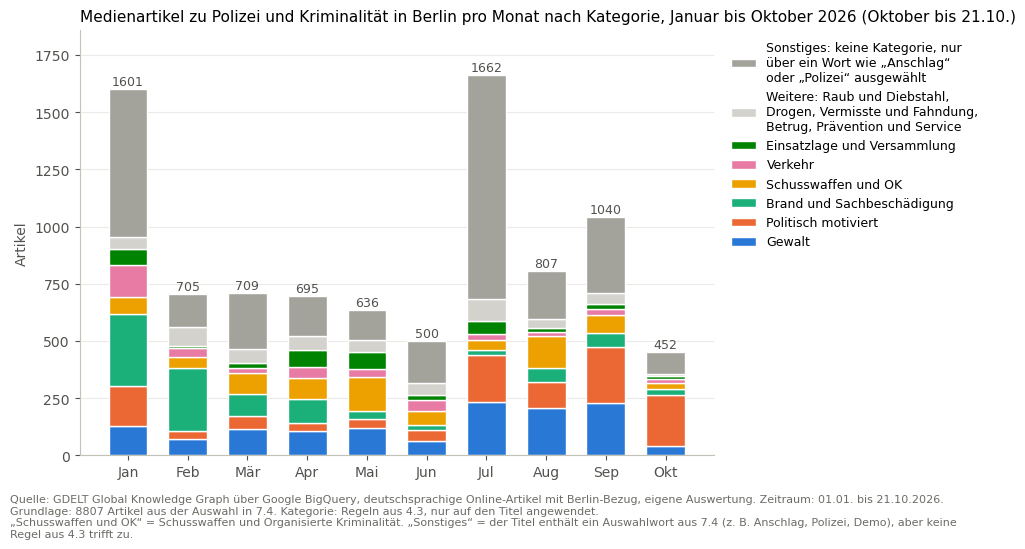

In [66]:
# Kategorien aus 4.3 auf die Medientitel anwenden: gleiche Regeln, gleiche Punkte, aber nur der Titel
def kategorie_titel(titel: str) -> str:
    punkte = regel_punkte(titel, "", "")                  # kein Text, keine Schlagworte
    hoechster = max(punkte.values())
    if hoechster == 0:
        return "Sonstiges"                                # nur über ein Wort wie "Polizei" oder "Anschlag" ausgewählt
    return next(k for k in REGELN if punkte[k] == hoechster)   # Reihenfolge = Priorität bei Gleichstand, wie in 4.3


krimi["kategorie"] = krimi["titel"].map(kategorie_titel)
krimi["monat"] = krimi["zeit"].dt.strftime("%Y-%m")

kat_medien = krimi["kategorie"].value_counts().to_frame("Artikel")
kat_medien["Anteil %"] = (kat_medien["Artikel"] / len(krimi) * 100).round(1)
display(kat_medien)

# Über welches Wort kamen die Artikel ohne Kategorie in die Auswahl? (Wörter aus 7.4)
sonstige = krimi.loc[krimi["kategorie"] == "Sonstiges", "titel"]
woerter = Counter(m.group(0).lower() for t in sonstige for m in [POLIZEI_KRIMI.search(t)] if m)
print("Sonstiges, häufigste Auswahlwörter:", ", ".join(f"{w} ({n})" for w, n in woerter.most_common(8)))

# Gestapelte Balken pro Monat, gleiche Farben und gleiche Darstellung wie in 4.9
FARBEN = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GRAU = "#a3a29b"
grosse_m = [k for k in kat_medien.index if k != "Sonstiges"][:len(FARBEN)]   # die sechs häufigsten echten Kategorien
krimi["kategorie_grob"] = krimi["kategorie"].where(krimi["kategorie"].isin(grosse_m + ["Sonstiges"]), "Weitere")
monat_kat_m = krimi.groupby(["monat", "kategorie_grob"]).size().unstack(fill_value=0)[grosse_m + ["Weitere", "Sonstiges"]]
display(monat_kat_m.assign(gesamt=monat_kat_m.sum(axis=1)))

fig, ax = plt.subplots(figsize=(10, 5))
labels = [MONATE[int(m[5:7]) - 1] for m in monat_kat_m.index]
unten = pd.Series(0, index=monat_kat_m.index)
kleine_m = [k for k in kat_medien.index if k not in grosse_m + ["Sonstiges"]]          # was in "Weitere" steckt
legende_m = {k: k for k in grosse_m} | {
    "Weitere": textwrap.fill("Weitere: " + ", ".join(kleine_m), 32),
    "Sonstiges": textwrap.fill("Sonstiges: keine Kategorie, nur über ein Wort wie „Anschlag“ oder „Polizei“ ausgewählt", 32)}
for kat, farbe in zip(monat_kat_m.columns, FARBEN + ["#d3d2cc", GRAU]):   # Weitere hell, Sonstiges grau
    ax.bar(labels, monat_kat_m[kat], bottom=unten, color=farbe, width=0.65, edgecolor="white", linewidth=1,
           label=legende_m[kat])
    unten += monat_kat_m[kat]
for x, summe in zip(labels, unten):
    ax.text(x, summe + unten.max() * 0.01, str(summe), ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, unten.max() * 1.12)
ax.set_ylabel("Artikel", color="#52514e")
ax.set_title("Medienartikel zu Polizei und Kriminalität in Berlin pro Monat nach Kategorie, Januar bis Oktober 2026 (Oktober bis 21.10.)",
             loc="left", fontsize=11)
handles, namen = ax.get_legend_handles_labels()
ax.legend(handles[::-1], namen[::-1], frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_MEDIEN}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(krimi)} Artikel aus der Auswahl in 7.4. Kategorie: Regeln aus 4.3, nur auf den Titel angewendet.",
         "„Schusswaffen und OK“ = Schusswaffen und Organisierte Kriminalität. „Sonstiges“ = der Titel enthält ein Auswahlwort aus 7.4 (z. B. Anschlag, Polizei, Demo), aber keine Regel aus 4.3 trifft zu.")
plt.show()


#### Interpretation 7.5: Kategorien in den Medien

- **Ein gutes Drittel bleibt ohne Kategorie.** 3.130 Artikel (35,5 %) sind „Sonstiges“. Sie kamen über ein Wort aus 7.4 in die Auswahl, vor allem „Anschlag“ (927), „Polizei“ (645) und „Demo“ (136). Das Wort „Anschlag“ allein steht nicht in den Regeln aus 4.3, deshalb landen viele Berichte über die Anschläge auf die Stromversorgung und den CSD hier.
- **Die größten Kategorien** sind Gewalt (1.318 Artikel, 15,0 %), Politisch motiviert (1.177, 13,4 %), Brand und Sachbeschädigung (1.018, 11,6 %) und Schusswaffen und OK (803, 9,1 %).
- **Januar und Juli ragen heraus.** Mit 1.601 und 1.662 Artikeln sind sie mehr als doppelt so stark wie die meisten anderen Monate. In beiden Monaten ist „Sonstiges“ der größte Block (647 und 980), also vor allem Artikel zu den Anschlägen.
- **Brand und Sachbeschädigung** ist im Januar (313) und Februar (273) groß, von Mai bis Juli liegt die Kategorie bei höchstens 34 Artikeln im Monat.
- **Politisch motiviert steigt im September und Oktober** auf 243 und 221 Artikel. Im Oktober ist fast die Hälfte der Artikel (221 von 452) politisch motiviert. Das passt zum Thema Antisemitismus in 7.7.
- Oktober ist nur bis 21.10. erfasst.

### 7.6 Artikel pro Tag

Wie in 5.2: die helle Linie zeigt jeden Tag, die dunkle den Durchschnitt über 7 Tage, die senkrechten Linien die vier Ereignisse aus 5.1.

Die Tabelle zeigt die zehn Tage mit den meisten Artikeln. Die Stichwörter findet Python selbst: das Wort, das an diesem Tag in den meisten Titeln steht. Ausgenommen sind die 40 häufigsten Wörter der ganzen Auswahl (z. B. Berlin, Polizei) und Wörter, die auch kleingeschrieben vorkommen und nur am Satzanfang groß stehen (z. B. „Warum“).

Tage: 294, Durchschnitt 30.0 Artikel pro Tag, Median 20, Maximum 490 am 26.07.


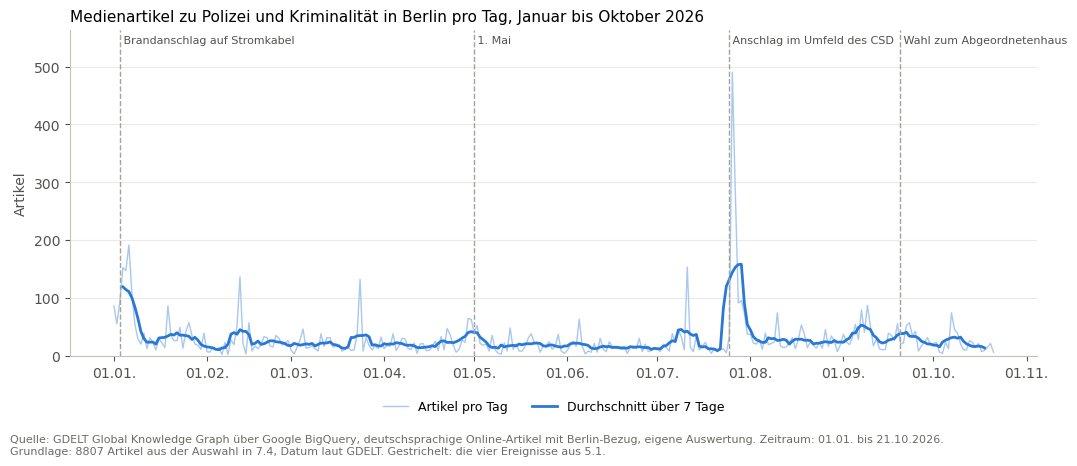

,Tag,Artikel,Stichwörter,bis 3 Tage nach Ereignis
0,26.07.2026,490,"Menschenmenge (37), Gesellschaft (30), Terroranschlag (22)",Anschlag im Umfeld des CSD
1,27.07.2026,283,"Attentäter (22), Tatverdächtiger (19), Mutter (19)",Anschlag im Umfeld des CSD
2,06.01.2026,192,"Bundesanwaltschaft (54), Längster (26), Generalbundesanwalt (19)",Brandanschlag auf Stromkabel
3,11.07.2026,154,"Geiselnahme (106), Supermarkt (92), Geiselname (19)",
4,04.01.2026,153,"Vulkangruppe (44), Wegner (29), Zehntausende (22)",Brandanschlag auf Stromkabel
5,05.01.2026,148,"Vulkangruppe (44), Terroranschlag (20), Endzeitstimmung (19)",Brandanschlag auf Stromkabel
6,12.02.2026,137,"Schwerverletzte (66), Totes (32), Friedrichsfelde (17)",
7,24.03.2026,133,"Razzien (27), Strommasten (27), Razzia (22)",
8,07.01.2026,108,"Stromversorgung (11), Südwesten (8), Blackout (6)",
9,29.07.2026,96,"Justiz (12), Attentäter (11), Salafist (9)",


In [67]:
# Artikel pro Tag mit Durchschnitt über 7 Tage, die vier Ereignisse aus 5.1 als senkrechte Linien
krimi["tag"] = krimi["zeit"].dt.normalize()
alle_tage_m = pd.date_range("2026-01-01", "2026-10-21", freq="D")
pro_tag_m = krimi.groupby("tag").size().reindex(alle_tage_m, fill_value=0)
schnitt_7_m = pro_tag_m.rolling(7, center=True).mean()
print(f"Tage: {len(pro_tag_m)}, Durchschnitt {pro_tag_m.mean():.1f} Artikel pro Tag, "
      f"Median {pro_tag_m.median():.0f}, Maximum {pro_tag_m.max()} am {pro_tag_m.idxmax():%d.%m.}")

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(pro_tag_m.index, pro_tag_m.values, color="#a9c8ee", linewidth=1, label="Artikel pro Tag")
ax.plot(schnitt_7_m.index, schnitt_7_m.values, color="#2a78d6", linewidth=2, label="Durchschnitt über 7 Tage")
for _, e in EREIGNISSE.iterrows():
    ax.axvline(e["datum"], color="#a3a29b", linestyle="--", linewidth=1)
    ax.text(e["datum"], pro_tag_m.max() * 1.13, " " + e["ereignis"], fontsize=8, color="#52514e", ha="left", va="top")
ax.set_ylim(0, pro_tag_m.max() * 1.15)
ax.set_ylabel("Artikel", color="#52514e")
ax.set_title("Medienartikel zu Polizei und Kriminalität in Berlin pro Tag, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m."))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_MEDIEN}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(krimi)} Artikel aus der Auswahl in 7.4, Datum laut GDELT. Gestrichelt: die vier Ereignisse aus 5.1.")
plt.show()

# Die zehn Tage mit den meisten Artikeln: Worum ging es?
# Stichwort = das Wort, das an diesem Tag am häufigsten in den Titeln steht,
# ohne die 40 Wörter, die in der ganzen Auswahl am häufigsten sind (z. B. Berlin, Polizei),
# und ohne Wörter, die auch kleingeschrieben vorkommen (großgeschrieben nur am Satzanfang, z. B. "Warum", "Vier")
WORT = re.compile(r"\b[A-ZÄÖÜ][\wäöüß\-]{2,}")
alle_woerter = Counter(w for t in krimi["titel"] for w in set(WORT.findall(t)))
klein = {w for t in krimi["titel"] for w in re.findall(r"\b[a-zäöüß][\wäöüß\-]{2,}", t)}
allgemein = {w for w, _ in alle_woerter.most_common(40)} | {w for w in alle_woerter if w.lower() in klein}

zeilen = []
for tag, anzahl in pro_tag_m.sort_values(ascending=False).head(10).items():
    titel_tag = krimi.loc[krimi["tag"] == tag, "titel"]
    woerter_tag = Counter(w for t in titel_tag for w in set(WORT.findall(t)) if w not in allgemein)
    nahe = EREIGNISSE[(tag >= EREIGNISSE["datum"]) & (tag <= EREIGNISSE["datum"] + pd.Timedelta(days=3))]
    zeilen.append({
        "Tag": tag.strftime("%d.%m.%Y"), "Artikel": anzahl,
        "Stichwörter": ", ".join(f"{w} ({n})" for w, n in woerter_tag.most_common(3)),
        "bis 3 Tage nach Ereignis": nahe["ereignis"].iloc[0] if len(nahe) else "",
    })
display(pd.DataFrame(zeilen))


#### Interpretation 7.6: Artikel pro Tag

- **Die Medien berichten in Wellen.** Im Mittel erscheinen 30,0 Artikel pro Tag, der Median liegt bei 20. Der stärkste Tag ist der 26.07. mit 490 Artikeln, der Tag nach dem Anschlag im Umfeld des CSD.
- **Fünf der zehn stärksten Tage** liegen bis drei Tage nach einem der vier Ereignisse: der 26.07. und 27.07. nach dem CSD-Anschlag, der 04.01., 05.01. und 06.01. nach dem Brandanschlag auf das Stromnetz. Der 07.01. (Stichwort Stromversorgung) und der 29.07. (Attentäter) liegen vier Tage danach und gehören inhaltlich ebenfalls zu den Anschlägen.
- **Drei Spitzen gehen auf andere Ereignisse zurück:** der 11.07. (154 Artikel, Stichwort Geiselnahme, Supermarkt), der 12.02. (137, Schwerverletzte, Friedrichsfelde) und der 24.03. (133, Razzien, Strommasten).
- **1. Mai und Wahl** erzeugen keinen Tag unter den zehn stärksten.

### 7.7 Themen in den Medien

Die Themen aus 5.7 und das Merkmal Messer aus 4.4 werden mit denselben Suchwörtern im Titel gesucht. Dazu kommen zwei Themen:

1. **Gewalt gegen Polizei:** die Muster aus 5.8, erweitert um Formen aus Überschriften wie „Angriffe auf Polizei“ oder „30 verletzte Polizisten“. Verletzte Polizeikräfte zählen wie in 5.8 nur, wenn der Titel keinen Unfall nennt. „Polizei greift ein“ zählt nicht.
2. **Gewalt durch die Polizei, in drei getrennten Themen.** Getrennt, weil ein rechtmäßiger Waffeneinsatz und ein Vorwurf gegen Polizeikräfte etwas ganz anderes sind:
   - **Schusswaffe durch Polizei:** die Polizei schießt, z. B. „Schusswaffengebrauch“, „Polizei erschießt“, „Schussabgabe eines Polizeibeamten“.
   - **Taser/DEIG durch Polizei:** Einsatz eines Distanzelektroimpulsgeräts. Eine bloße Androhung zählt nicht.
   - **Vorwürfe gegen Polizei:** z. B. „Polizeigewalt“, „Körperverletzung im Amt“, „rassistische Polizeikontrolle“ sowie Tod in Gewahrsam oder nach einem Polizeieinsatz.

   Die Zählung sagt nichts darüber, ob ein Einsatz rechtmäßig war.

Zum Nachlesen zeigt die Zelle je 8 zufällige Titel zu den vier Polizei-Themen.

monat,Jan,Feb,Mär,Apr,Mai,Jun,Jul,Aug,Sep,Okt,gesamt
Nahost-Konflikt,9,5,11,3,8,2,4,4,11,54,111
Antisemitismus,9,8,7,11,13,9,16,25,177,194,469
Rechtsextremismus,2,0,31,4,2,7,12,1,2,0,61
Linksextremismus,108,4,26,0,4,3,3,0,3,0,151
Rassismus,0,5,1,8,10,10,2,8,2,3,49
Queerfeindlichkeit,5,4,2,2,12,2,105,19,37,10,198
Versammlungen,7,4,17,17,14,21,10,6,19,7,122
Messer,8,29,36,38,37,23,24,17,15,5,232
Gewalt gegen Polizei,22,0,9,2,35,1,5,0,3,1,78
Schusswaffe durch Polizei,0,0,0,10,0,0,29,0,1,0,40


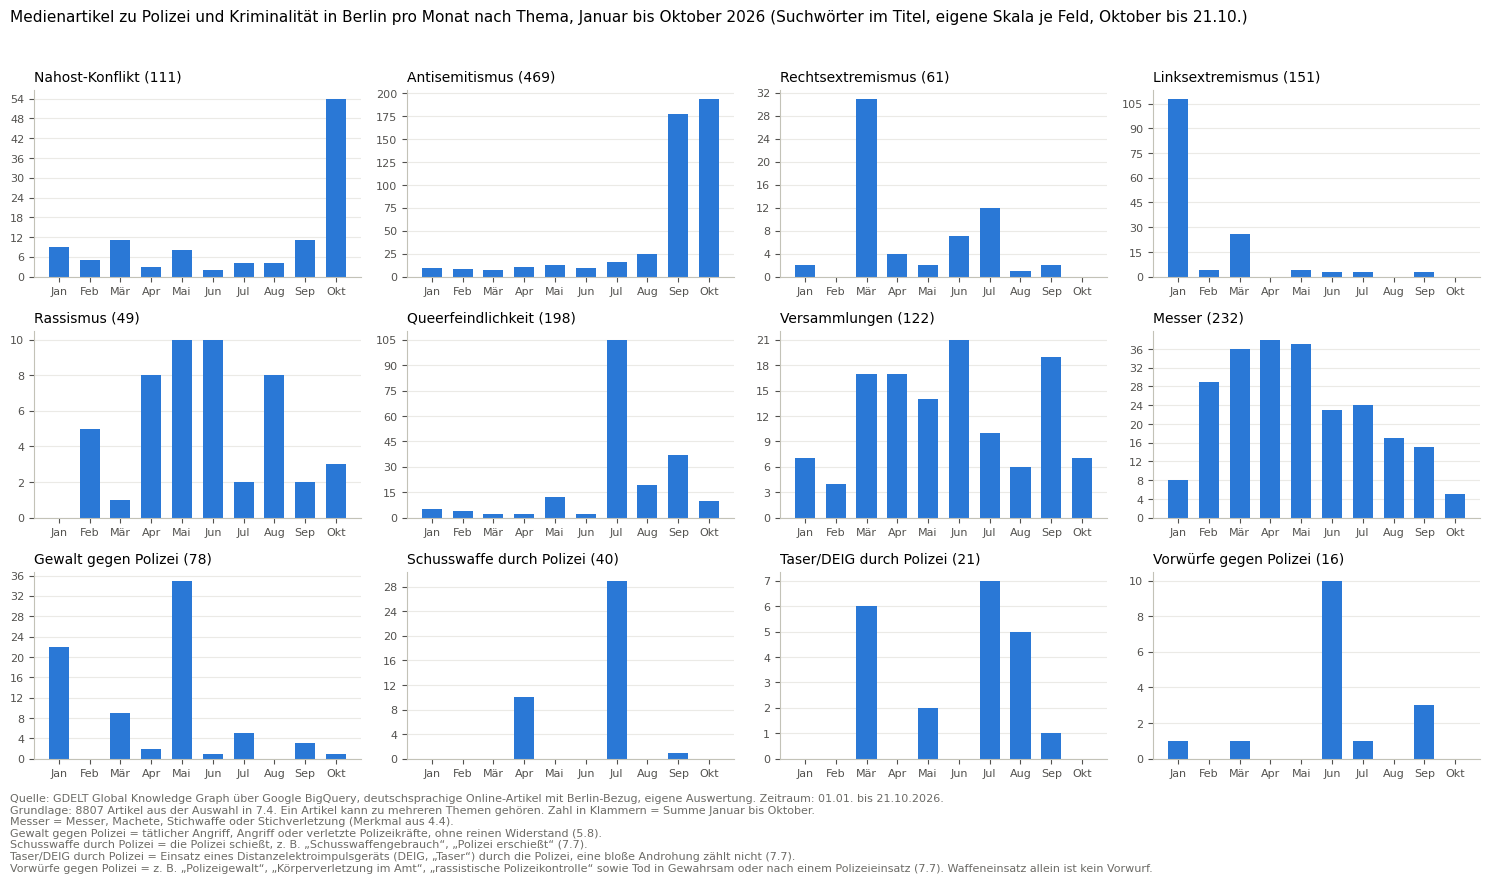

Nahost-Konflikt, stärkster Monat Okt (54 Artikel):
    5x  Hamas-Terror: Dobrindt gedenkt Opfern des 7. Oktober in Berlin
    3x  Propalästinensische Demo im Berliner Regierungsviertel
    2x  Linke-Politikerin begleitet Palästina-Demo in Berlin
Antisemitismus, stärkster Monat Okt (194 Artikel):
    21x  Parteien suchen Einigung zum Thema Antisemitismus in Berlin
    8x  CSU-Studie belastet Linke: Antisemitismus-Vorwürfe in Berlin
    7x  Weg frei für Sondierungen in Berlin? Linke einigt sich auf Aktionsplan gegen Antisemitismus
Rechtsextremismus, stärkster Monat Mär (31 Artikel):
    20x  Verwechslung mit Rechtsextremistin: Frau aus Berlin verliert Job wegen Verfassungsschutz-Fehler
    2x  Staatsschutz ermittelt: Hitlergruß in Marzahn – Polizistin mit Farbe attackiert
    2x  Berlin: Verfassungsschutz verwechselt Hochschulmitarbeiterin mit Rechtsextremistin
Linksextremismus, stärkster Monat Jan (108 Artikel):
    19x  Stromausfall in Berlin: Linksextreme "Vulkangruppe" bekennt sich z

In [68]:
# Themen aus 5.7 und 5.8 in den Medientiteln, dazu neu: Gewalt durch die Polizei in drei Themen
# Die Suchwörter aus 5.7 werden unverändert übernommen. Für Gewalt gegen Polizei werden die Muster aus 5.8
# um Formen erweitert, die nur in Überschriften üblich sind ("Angriffe auf Polizei", "30 verletzte Polizisten").
POLIZEI_TITEL = rf"(?:{POLIZEI}|Polizei\b|Bundespolizist\w*|Polizeisprecher\w*)"
GEWALT_GEGEN_POLIZEI = re.compile(
    TAETLICH.pattern
    + rf"|(?:Angriff\w*|Attacke\w*|Gewalt) (?:auf|gegen) (?:die |eine[nr]? )?{POLIZEI_TITEL}"
    + rf"|{POLIZEI_TITEL}\s+(?:\w+\s+){{0,4}}(?:angegriffen|attackiert|bespuckt|angespuckt|bedroht|beworfen|beschossen|gebissen|getreten|geschlagen)\b"
    + rf"|\b(?:greift|greifen|griff|griffen|attackiert|attackieren)\s+(?:\w+\s+){{0,4}}{POLIZEI_TITEL}"
    + rf"|auf {POLIZEI_TITEL} los", re.I)
# Verletzte Polizeikräfte zählen wie in 5.8 nur, wenn der Titel keinen Unfall nennt
VERLETZT_TITEL = re.compile(rf"{POLIZEI}\s+(?:\w+\s+){{0,4}}verletzt\b|verletzte\w* {POLIZEI}", re.I)
KEIN_ANGRIFF_TITEL = re.compile(KEIN_ANGRIFF.pattern + r"|kracht|prallt|Sturz|stürzt", re.I)
EINGREIFEN = re.compile(r"\bgreif\w*\s+(?:\w+\s+){0,3}ein\b", re.I)     # "greift Polizei ein" ist kein Angriff


def gewalt_gegen_polizei(titel: str) -> bool:
    titel = EINGREIFEN.sub(" ", titel)
    if GEWALT_GEGEN_POLIZEI.search(titel):
        return True
    return bool(VERLETZT_TITEL.search(titel)) and not KEIN_ANGRIFF_TITEL.search(titel)


# Gewalt durch die Polizei, in drei getrennten Themen, damit Waffeneinsatz und Vorwürfe nicht vermischt werden.
# Wird in Abschnitt 8 auch auf die Polizeimeldungen angewendet.
# 1. Schusswaffe durch Polizei: die Polizei schießt
SCHUSS_POLIZEI = re.compile(
    r"Polizeischüsse|Polizeischuss|Schusswaffengebrauch|Schussabgaben? (?:eines|einer|durch) (?:\w+ )?(?:Polizei|Beamt|Zivilbeamt)\w*|"
    rf"{POLIZEI_TITEL} (?:erschießt|erschoss|schießt|schoss|schossen)\b|"
    r"(?:von|durch) (?:der |die |einem |einer )?(?:Polizei|Polizist\w*|Beamt\w*|Zivilbeamt\w*) (?:erschossen|angeschossen)|"
    r"(?:Schüsse|Schuss) (?:aus|durch) (?:der |die |einer |eine[nm]? )?(?:Polizei|Dienstwaffe)|"
    r"bei (?:einem |dem )?Polizeieinsatz (?:erschossen|getötet|tödlich verletzt)|"
    r"von (?:der |ihrer |ihren |seiner )?(?:Schusswaffe|Dienstwaffe)\w* Gebrauch|"
    r"(?:setzte|setzten) (?:\w+ ){0,3}(?:Dienstwaffe|Schusswaffe)\w* ein", re.I)
# 2. Taser/DEIG durch Polizei: Einsatz eines Distanzelektroimpulsgeräts
GERAET = r"(?:Distanz-?[Ee]lektroimpulsger(?:ä|a)t\w*|DEIG|Taser\w*)"
DEIG_POLIZEI = re.compile(
    rf"{GERAET}[- ]?(?:Einsatz|Einsätz)\w*|{GERAET}\b[^.]{{0,40}}?(?:eingesetzt|einsetz\w*|überwältigt|gestoppt|\bein\b(?=\s*(?:[.,;:!?–-]|$)))|"
    rf"(?:Einsatz|Einsatzes|einsetz\w*|mithilfe|mit Hilfe) (?:\w+ ){{0,2}}{GERAET}|mit (?:einem |dem )?{GERAET}|\btasert|getasert", re.I)
# 3. Vorwürfe gegen Polizei: was man meist mit "Polizeigewalt" meint, dazu Tod in Gewahrsam oder nach einem Einsatz
VORWURF_POLIZEI = re.compile(
    r"Polizeigewalt|Polizeibrutalität|Gewalt (?:durch|von) (?:der |die )?Polizei|Körperverletzung im Amt|"
    r"rassistische\w* Polizei\w*|Racial Profiling|prügelnde\w* Polizist\w*|"
    rf"{POLIZEI_TITEL} (?:schlägt|schlug|prügelt)|"
    r"(?:Tod|tot|gestorben|stirbt|starb) (?:\w+ ){0,3}(?:Polizeigewahrsam|Polizeieinsatz)", re.I)
# Nur angedroht ist kein Einsatz
ANDROHUNG = re.compile(rf"Androhung (?:de[sr] )?(?:Einsatzes )?(?:eines |des |der )?(?:{GERAET}|Schusswaffe)(?: \(DEIG\))?"
                       rf"|(?:den |dem )?Einsatz (?:eines|des) {GERAET}\w* angedroht", re.I)
GEWALT_DURCH_POLIZEI = {"Schusswaffe durch Polizei": SCHUSS_POLIZEI,
                        "Taser/DEIG durch Polizei": DEIG_POLIZEI,
                        "Vorwürfe gegen Polizei": VORWURF_POLIZEI}


def trifft(muster, text: str) -> bool:
    return muster.search(ANDROHUNG.sub(" ", text)) is not None


THEMEN_MEDIEN = {**{k: re.compile(v, re.I) for k, v in THEMEN.items()},
                 "Messer": re.compile(MERKMALE["messer"], re.I),
                 "Gewalt gegen Polizei": gewalt_gegen_polizei,
                 **{k: (lambda t, m=m: trifft(m, t)) for k, m in GEWALT_DURCH_POLIZEI.items()}}
for thema, muster in THEMEN_MEDIEN.items():
    pruefen = muster if callable(muster) else (lambda t, m=muster: m.search(t) is not None)
    krimi[thema] = krimi["titel"].map(pruefen)

themen_m = list(THEMEN_MEDIEN)
monat_thema_m = krimi.groupby("monat")[themen_m].sum().astype(int)
display(monat_thema_m.T.assign(gesamt=monat_thema_m.sum()).rename(
    columns=lambda m: MONATE[int(m[5:7]) - 1] if m != "gesamt" else m))

fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True)
labels = [MONATE[int(m[5:7]) - 1] for m in monat_thema_m.index]
for ax, thema in zip(axes.flat, themen_m):
    werte = monat_thema_m[thema]
    ax.bar(labels, werte.values, color="#2a78d6", width=0.65)
    ax.set_title(f"{thema} ({werte.sum()})", loc="left", fontsize=10)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8, labelbottom=True)
    ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
for ax in axes.flat[len(themen_m):]:
    ax.set_visible(False)
fig.suptitle("Medienartikel zu Polizei und Kriminalität in Berlin pro Monat nach Thema, Januar bis Oktober 2026 (Suchwörter im Titel, eigene Skala je Feld, Oktober bis 21.10.)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.96))
fussnote(fig, f"Quelle: {QUELLE_MEDIEN}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(krimi)} Artikel aus der Auswahl in 7.4. Ein Artikel kann zu mehreren Themen gehören. Zahl in Klammern = Summe Januar bis Oktober.",
         BEGRIFF_MESSER, BEGRIFF_GEWALT_POLIZEI, BEGRIFF_SCHUSSWAFFE, BEGRIFF_DEIG, BEGRIFF_VORWURF)
plt.show()

# Worum geht es im stärksten Monat jedes Themas? Die drei Titel, die dort am häufigsten erscheinen
for thema in themen_m:
    monat_max = monat_thema_m[thema].idxmax()
    titel_max = krimi.loc[krimi[thema] & (krimi["monat"] == monat_max), "titel"].value_counts().head(3)
    print(f"{thema}, stärkster Monat {MONATE[int(monat_max[5:7]) - 1]} ({monat_thema_m[thema].max()} Artikel):")
    for t, n in titel_max.items():
        print(f"    {n}x  {t[:110]}")

# Zum Nachlesen: je 8 zufällige Titel zu Gewalt gegen Polizei und zur Gewalt durch die Polizei
for thema in ["Gewalt gegen Polizei"] + list(GEWALT_DURCH_POLIZEI):
    treffer = krimi[krimi[thema]]
    print(f"\n{thema}: {len(treffer)} Artikel")
    for _, r in treffer.sample(min(8, len(treffer)), random_state=1).iterrows():
        print(f"  {r['zeit']:%d.%m.}  {r['titel'][:120]}")


#### Interpretation 7.7: Themen in den Medien

- **Antisemitismus ist das größte Thema** mit 469 Artikeln, davon 371 im September (177) und Oktober (194). Die häufigsten Titel im Oktober handeln von der Regierungsbildung nach der Wahl („Parteien suchen Einigung zum Thema Antisemitismus in Berlin“, 21 Mal). Es geht also vor allem um eine politische Debatte, nicht um einzelne Taten.
- **Linksextremismus** (151) liegt fast ganz im Januar (108). Die Titel handeln von der „Vulkangruppe“ und dem Anschlag auf das Stromnetz.
- **Queerfeindlichkeit** (198) hat ihren Schwerpunkt im Juli (105), die Titel handeln vom Anschlag auf den CSD.
- **Rechtsextremismus** (61) hat eine Spitze im März (31). 20 davon sind derselbe Titel über eine Frau, die der Verfassungsschutz mit einer Rechtsextremistin verwechselt hat.
- **Messer** (232) verteilt sich über das Jahr, mit den meisten Artikeln von Februar bis Mai (29 bis 38 im Monat).
- **Gewalt gegen Polizei** (78) ballt sich im Januar (22) und Mai (35), also um Silvester und den 1. Mai. Im Mai erscheint derselbe Titel „Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin“ 19 Mal.
- **Schusswaffe durch Polizei** (40) liegt fast nur im Juli (29) und April (10). Im Juli berichten die Titel, dass die Polizei den mutmaßlichen CSD-Attentäter erschossen hat, im April, dass die Polizei auf einen flüchtenden Autodieb geschossen hat. Viele Artikel über wenige Einsätze: Im Juli sind es 29 Artikel, aber nur 2 Polizeimeldungen mit Schusswaffe (siehe 8.6).
- **Taser/DEIG durch Polizei** (21) hat im Juli die meisten Artikel (7), vor allem zur Geiselnahme im Supermarkt, die mit einem Taser beendet wurde.
- **Vorwürfe gegen Polizei** (16) liegen vor allem im Juni (10): ein Fall von möglicher Körperverletzung im Amt in Friedrichshain und eine Entschädigung nach einer rassistischen Polizeikontrolle.
- **Grenze der Suchwörter:** Unter „Versammlungen“ zählt auch eine „Mitgliederversammlung“ eines Unternehmerverbands. Die Suchwörter aus 5.7 wurden für Polizeimeldungen gebaut und treffen in Medientiteln auch Unpassendes.

### 7.8 Orte im Zusammenhang

Bezirke werden nicht flächendeckend verglichen (siehe Ergebnis 7.3). Python sucht dieselben Ortsnamen wie in 7.4 in den Titeln und zeigt für jeden Ort, in welchem Zusammenhang er genannt wird: häufigste Kategorien und Themen. Bezirke und Orte stehen getrennt, kbO sind rot wie auf der Karte in 6.7. Teilnamen wie Kreuzberg oder Wilmersdorf werden einzeln gezählt.

Artikel mit mindestens einem Ortsnamen: 1199 von 8807
Bezirke (Teilnamen wie Kreuzberg oder Wilmersdorf einzeln):


,Art,Artikel,häufigste Kategorien,Themen
Ort,,,,
Neukölln,Bezirk,295,"Schusswaffen und OK (87), Gewalt (75), Sonstiges (37)","Messer (22), Antisemitismus (7)"
Kreuzberg,Bezirk,206,"Schusswaffen und OK (73), Sonstiges (33), Gewalt (30)","Nahost-Konflikt (11), Messer (8)"
Spandau,Bezirk,124,"Schusswaffen und OK (27), Brand und Sachbeschädigung (23), Sonstiges (21)","Taser/DEIG durch Polizei (6), Messer (6)"
Schöneberg,Bezirk,77,"Schusswaffen und OK (40), Politisch motiviert (11), Brand und Sachbeschädigu...","Rassismus (7), Queerfeindlichkeit (5)"
Charlottenburg,Bezirk,63,"Brand und Sachbeschädigung (16), Sonstiges (13), Raub und Diebstahl (12)","Messer (4), Antisemitismus (1)"
Wilmersdorf,Bezirk,49,"Schusswaffen und OK (16), Gewalt (15), Brand und Sachbeschädigung (5)","Messer (15), Antisemitismus (3)"
Köpenick,Bezirk,45,"Verkehr (11), Schusswaffen und OK (9), Sonstiges (8)","Schusswaffe durch Polizei (5), Rechtsextremismus (1)"
Marzahn,Bezirk,39,"Politisch motiviert (10), Verkehr (7), Sonstiges (6)","Rechtsextremismus (7), Gewalt gegen Polizei (5)"
Lichtenberg,Bezirk,34,"Brand und Sachbeschädigung (11), Gewalt (8), Sonstiges (6)",Linksextremismus (1)


Orte und kbO, die 15 häufigsten:


,Art,Artikel,häufigste Kategorien,Themen
Ort,,,,
Görlitzer Park,kbO,52,"Einsatzlage und Versammlung (19), Gewalt (10), Brand und Sachbeschädigung (7)","Versammlungen (5), Messer (5)"
Kottbusser Tor,kbO,14,"Sonstiges (6), Gewalt (6), Drogen (1)",Messer (3)
Alexanderplatz,kbO,13,"Gewalt (7), Verkehr (2), Sonstiges (2)","Messer (5), Versammlungen (1)"
Sonnenallee,Ort,11,"Schusswaffen und OK (4), Gewalt (2), Verkehr (2)",Queerfeindlichkeit (1)
Tierpark,Ort,7,"Gewalt (4), Sonstiges (3)",Messer (1)
Rigaer Straße,kbO,7,"Brand und Sachbeschädigung (4), Sonstiges (2), Einsatzlage und Versammlung (1)",Gewalt gegen Polizei (1)
Nollendorfplatz,Ort,7,"Verkehr (5), Brand und Sachbeschädigung (2)",Queerfeindlichkeit (1)
Hermannstraße,kbO,7,"Schusswaffen und OK (5), Drogen (1), Verkehr (1)",
Potsdamer Platz,Ort,6,"Einsatzlage und Versammlung (3), Sonstiges (2), Brand und Sachbeschädigung (1)",Versammlungen (1)


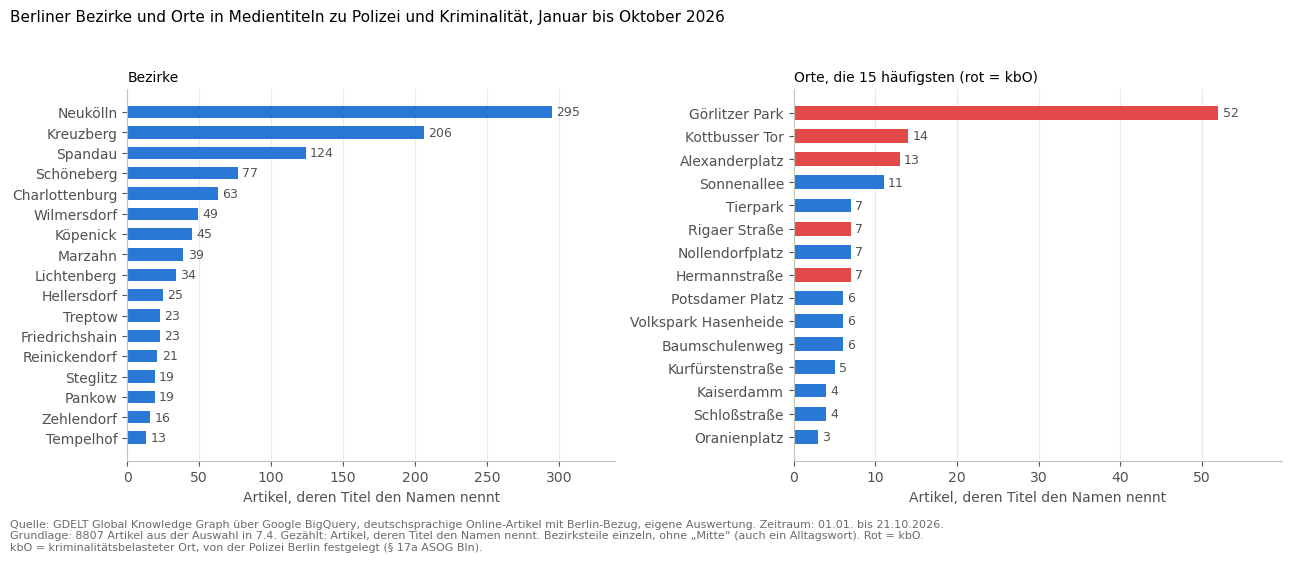

In [69]:
# Orte im Zusammenhang: Welche Berliner Orte nennen die Medien, und bei welchen Themen?
# Gleiche Ortsnamen wie in 7.4 (Bezirke, Orte aus 6.6, kbO). Ein Titel kann mehrere Orte nennen.
art = {**{n: "Bezirk" for n in bezirksteile}, **{n: "Ort" for n in orte_osm - bezirksteile},
       **{n: "kbO" for n in kbo_namen}}                                    # kbO geht vor
krimi["orte"] = krimi["titel"].map(lambda t: sorted(set(ORT.findall(t))))
orte_m = krimi[["kategorie", "orte"] + themen_m].explode("orte").dropna(subset=["orte"])
print(f"Artikel mit mindestens einem Ortsnamen: {(krimi['orte'].str.len() > 0).sum()} von {len(krimi)}")


def zusammenhang(gruppe: pd.DataFrame) -> pd.Series:
    kat = gruppe["kategorie"].value_counts()
    them = gruppe[themen_m].sum().sort_values(ascending=False)
    return pd.Series({
        "Artikel": len(gruppe),
        "häufigste Kategorien": ", ".join(f"{k} ({n})" for k, n in kat.head(3).items()),
        "Themen": ", ".join(f"{k} ({n})" for k, n in them[them > 0].head(2).items()),
    })


orte_tabelle_m = (orte_m.groupby("orte")[orte_m.columns].apply(zusammenhang)
                  .sort_values("Artikel", ascending=False))
orte_tabelle_m.insert(0, "Art", orte_tabelle_m.index.map(art))
orte_tabelle_m.index.name = "Ort"
ist_bezirk = orte_tabelle_m["Art"] == "Bezirk"
print("Bezirke (Teilnamen wie Kreuzberg oder Wilmersdorf einzeln):")
display(orte_tabelle_m[ist_bezirk])
print("Orte und kbO, die 15 häufigsten:")
display(orte_tabelle_m[~ist_bezirk].head(15))

# Zwei Balkendiagramme: links Bezirke, rechts Orte (kbO rot wie auf der Karte in 6.7)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, daten, titel_ax in [(ax1, orte_tabelle_m[ist_bezirk], "Bezirke"),
                            (ax2, orte_tabelle_m[~ist_bezirk].head(15), "Orte, die 15 häufigsten (rot = kbO)")]:
    daten = daten.iloc[::-1]
    farben_ort = ["#e34948" if a == "kbO" else "#2a78d6" for a in daten["Art"]]
    ax.barh(daten.index, daten["Artikel"], color=farben_ort, height=0.6)
    for y, w in enumerate(daten["Artikel"]):
        ax.text(w + daten["Artikel"].max() * 0.01, y, str(w), va="center", fontsize=9, color="#52514e")
    ax.set_xlim(0, daten["Artikel"].max() * 1.15)
    ax.set_title(titel_ax, loc="left", fontsize=10)
    ax.set_xlabel("Artikel, deren Titel den Namen nennt", color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Berliner Bezirke und Orte in Medientiteln zu Polizei und Kriminalität, Januar bis Oktober 2026",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.95))
fussnote(fig, f"Quelle: {QUELLE_MEDIEN}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(krimi)} Artikel aus der Auswahl in 7.4. Gezählt: Artikel, deren Titel den Namen nennt. Bezirksteile einzeln, ohne „Mitte“ (auch ein Alltagswort). Rot = kbO.",
         BEGRIFF_KBO)
plt.show()


#### Interpretation 7.8: Orte im Zusammenhang

- **1.199 von 8.807 Artikeln** nennen im Titel einen Bezirk oder Ort.
- **Neukölln (295), Kreuzberg (206) und Spandau (124)** werden am häufigsten genannt. Bei Neukölln und Kreuzberg ist „Schusswaffen und OK“ die häufigste Kategorie (87 und 73 Artikel).
- **Unter den Orten führen die kbO.** Görlitzer Park (52), Kottbusser Tor (14) und Alexanderplatz (13) stehen an der Spitze. Beim Görlitzer Park ist „Einsatzlage und Versammlung“ der häufigste Zusammenhang (19), danach Gewalt (10).
- **Einzelne Orte haben ein klares Thema:** Kurfürstenstraße fast nur Drogen (4 von 5), Schloßstraße nur Brand und Sachbeschädigung (4 von 4).
- „Mitte“ wird nicht gesucht (siehe 7.4), Artikel über Mitte fehlen deshalb in dieser Liste.

### 7.9 Quellen

Welche Medien liefern die meisten Artikel zu Polizei und Kriminalität in Berlin? In Klammern steht der Anteil an allen Berlin-Artikeln der Quelle aus 7.3. Viele Titel erscheinen in mehreren Medien, deshalb nennt die Zelle auch die Zahl der verschiedenen Titel.

Quellen mit mindestens einem Artikel in der Auswahl: 232
Die 5 größten Quellen liefern 3148 von 8807 Artikeln (36 %)
Verschiedene Titel in der Auswahl: 6597 (derselbe Titel erscheint oft in mehreren Medien)


,Artikel Auswahl,Artikel gesamt (7.3),Anteil Auswahl %
quelle,,,
tagesspiegel.de,1247,5818,21.4
morgenpost.de,670,4928,13.6
zeit.de,441,4353,10.1
n-tv.de,405,4770,8.5
welt.de,385,5579,6.9
rbb24.de,252,2121,11.9
bild.de,230,1496,15.4
berliner-zeitung.de,209,3482,6.0
volksstimme.de,188,2131,8.8


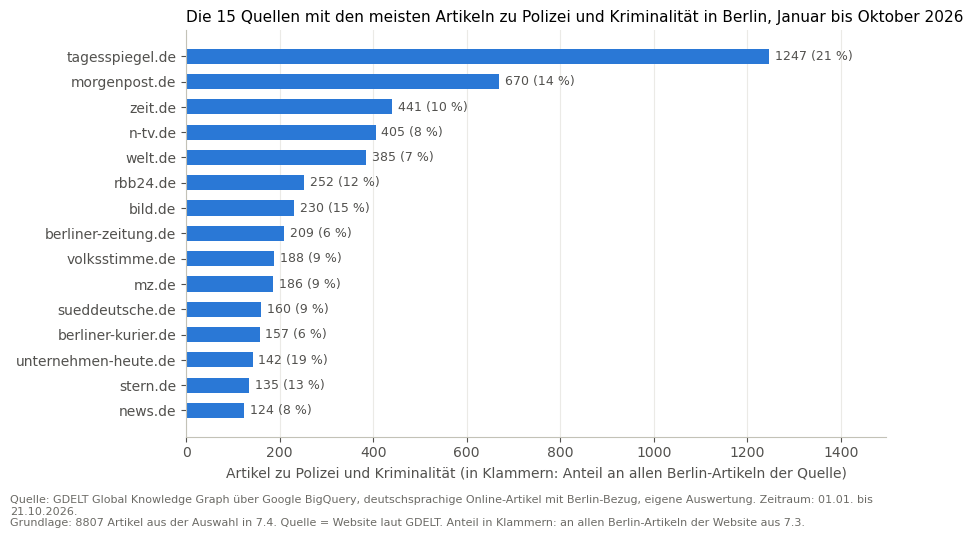

In [70]:
# Welche Medien berichten am meisten? Anteil der Auswahl an allen Berlin-Artikeln der Quelle aus 7.3
quellen = pd.DataFrame({
    "Artikel Auswahl": krimi["quelle"].value_counts(),
    "Artikel gesamt (7.3)": medien["quelle"].value_counts(),
}).fillna(0).astype(int)
quellen["Anteil Auswahl %"] = (quellen["Artikel Auswahl"] / quellen["Artikel gesamt (7.3)"] * 100).round(1)
quellen = quellen.sort_values("Artikel Auswahl", ascending=False)
quellen_mit = quellen[quellen["Artikel Auswahl"] > 0]
top5 = quellen_mit["Artikel Auswahl"].head(5).sum()
print(f"Quellen mit mindestens einem Artikel in der Auswahl: {len(quellen_mit)}")
print(f"Die 5 größten Quellen liefern {top5} von {len(krimi)} Artikeln ({top5 / len(krimi) * 100:.0f} %)")
print(f"Verschiedene Titel in der Auswahl: {krimi['titel'].nunique()} "
      f"(derselbe Titel erscheint oft in mehreren Medien)")
display(quellen_mit.head(15))

daten = quellen_mit.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(daten.index, daten["Artikel Auswahl"], color="#2a78d6", height=0.6)
for y, (w, a) in enumerate(zip(daten["Artikel Auswahl"], daten["Anteil Auswahl %"])):
    ax.text(w + daten["Artikel Auswahl"].max() * 0.01, y, f"{w} ({a:.0f} %)", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, daten["Artikel Auswahl"].max() * 1.2)
ax.set_xlabel("Artikel zu Polizei und Kriminalität (in Klammern: Anteil an allen Berlin-Artikeln der Quelle)",
              color="#52514e")
ax.set_title("Die 15 Quellen mit den meisten Artikeln zu Polizei und Kriminalität in Berlin, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quelle: {QUELLE_MEDIEN}, eigene Auswertung. Zeitraum: {ZEITRAUM_TEXT}.",
         f"Grundlage: {len(krimi)} Artikel aus der Auswahl in 7.4. Quelle = Website laut GDELT. Anteil in Klammern: an allen Berlin-Artikeln der Website aus 7.3.")
plt.show()


#### Interpretation 7.9: Quellen

- **232 Quellen** haben mindestens einen Artikel in der Auswahl. Die fünf größten liefern 3.148 von 8.807 Artikeln (36 %).
- **Der Tagesspiegel liegt weit vorn** mit 1.247 Artikeln, das sind 21,4 % seiner Berlin-Artikel. Danach folgen Morgenpost (670), Zeit (441), n-tv (405) und Welt (385).
- **Den größten Anteil an Polizei- und Kriminalitätsthemen** unter den 15 größten Quellen haben Tagesspiegel (21,4 %), unternehmen-heute.de (18,7 %) und Bild (15,4 %), den kleinsten Berliner Kurier (5,8 %) und Berliner Zeitung (6,0 %).
- **Viele Titel sind doppelt.** Es gibt 6.597 verschiedene Titel bei 8.807 Artikeln. Rund ein Viertel der Artikel (2.210) trägt also einen Titel, den es in der Auswahl schon einmal gibt.

## 8. Vergleich Polizeimeldungen und Medien

Leitfrage 4: Wo unterscheiden sich Polizeimeldungen und Medienberichterstattung? Verglichen werden die 1272 Polizeimeldungen aus Abschnitt 3 bis 6 und die Medienartikel aus 7.4.

Die beiden Quellen sind sehr unterschiedlich groß. Verglichen werden deshalb **Anteile**, nicht absolute Zahlen. Wo es möglich ist, wird bei beiden dieselbe Methode verwendet, z. B. die Regeln aus 4.3 nur auf den Titel.

### 8.1 Kategorien

Die Polizeimeldungen werden hier mit derselben Methode eingeordnet wie die Medien: Regeln aus 4.3, nur Titel. Die endgültige Kategorie aus 4.8 (Sprachmodell mit Titel und Text) steht zum Vergleich in der Tabelle. Die letzte Spalte zeigt den Unterschied in Prozentpunkten: positiv heißt, die Kategorie hat in den Medien einen größeren Anteil.

Grundlage: 1272 Polizeimeldungen, 8807 Medienartikel


,"Polizei, nur Titel %","Polizei, endgültig %","Medien, nur Titel %",Medien minus Polizei (Punkte)
Sonstiges,22.8,1.3,35.5,12.7
Gewalt,17.4,17.5,15.0,-2.4
Verkehr,16.8,24.8,4.7,-12.1
Schusswaffen und OK,11.9,11.9,9.1,-2.8
Raub und Diebstahl,10.3,13.1,2.5,-7.8
Brand und Sachbeschädigung,8.3,7.1,11.6,3.2
Politisch motiviert,5.3,13.1,13.4,8.0
Vermisste und Fahndung,2.3,3.5,1.2,-1.1
Drogen,2.0,2.8,1.8,-0.1
Einsatzlage und Versammlung,1.7,1.7,4.4,2.7


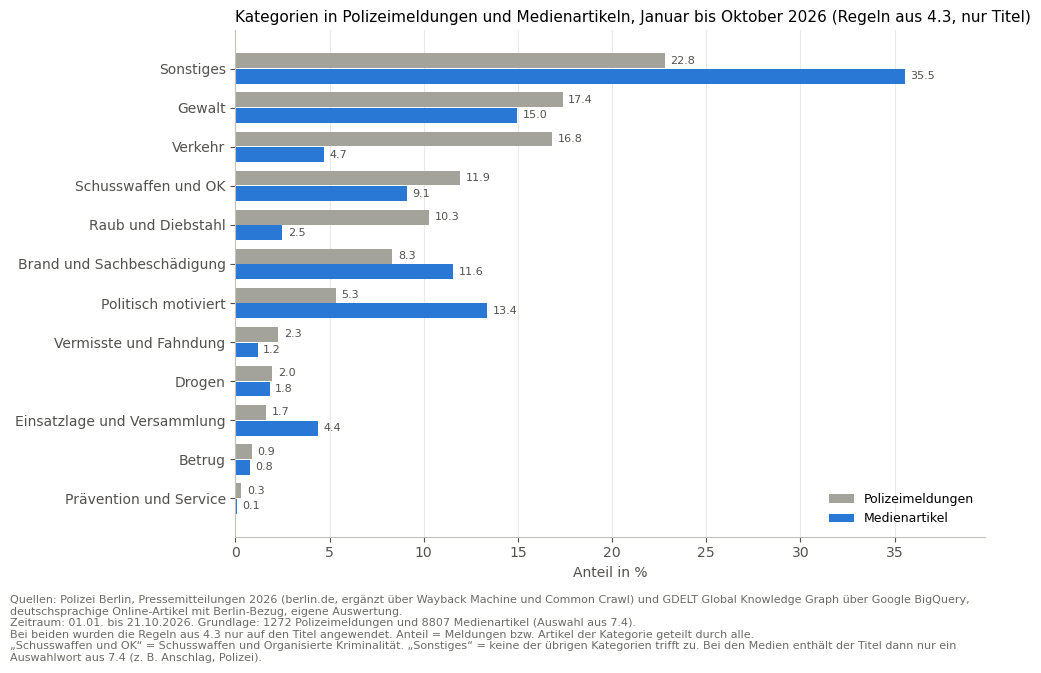

In [71]:
# Kategorien im Vergleich. Damit die Methode gleich ist, werden die Regeln aus 4.3 auch bei den Polizeimeldungen
# nur auf den Titel angewendet (wie bei den Medien). Die endgültige Kategorie aus 4.8 steht zum Vergleich daneben.
import numpy as np

df["kategorie_titel"] = df["titel"].map(kategorie_titel)

vergleich_kat = pd.DataFrame({
    "Polizei, nur Titel %": df["kategorie_titel"].value_counts(normalize=True) * 100,
    "Polizei, endgültig %": df["kategorie"].value_counts(normalize=True) * 100,
    "Medien, nur Titel %": krimi["kategorie"].value_counts(normalize=True) * 100,
}).fillna(0)
vergleich_kat["Medien minus Polizei (Punkte)"] = vergleich_kat["Medien, nur Titel %"] - vergleich_kat["Polizei, nur Titel %"]
vergleich_kat = vergleich_kat.sort_values("Polizei, nur Titel %", ascending=False)
print(f"Grundlage: {len(df)} Polizeimeldungen, {len(krimi)} Medienartikel")
display(vergleich_kat.round(1))

# Balken nebeneinander: Anteil je Kategorie, Polizei und Medien mit derselben Methode (nur Titel)
daten = vergleich_kat[["Polizei, nur Titel %", "Medien, nur Titel %"]].iloc[::-1]
y = np.arange(len(daten))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(y + 0.2, daten["Polizei, nur Titel %"], height=0.38, color="#a3a29b", label="Polizeimeldungen")
ax.barh(y - 0.2, daten["Medien, nur Titel %"], height=0.38, color="#2a78d6", label="Medienartikel")
for yy, p, m in zip(y, daten["Polizei, nur Titel %"], daten["Medien, nur Titel %"]):
    ax.text(p + 0.3, yy + 0.2, f"{p:.1f}", va="center", fontsize=8, color="#52514e")
    ax.text(m + 0.3, yy - 0.2, f"{m:.1f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, daten.index)
ax.set_xlim(0, daten.max().max() * 1.12)
ax.set_xlabel("Anteil in %", color="#52514e")
ax.set_title("Kategorien in Polizeimeldungen und Medienartikeln, Januar bis Oktober 2026 (Regeln aus 4.3, nur Titel)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.", f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen und {len(krimi)} Medienartikel (Auswahl aus 7.4).",
         "Bei beiden wurden die Regeln aus 4.3 nur auf den Titel angewendet. Anteil = Meldungen bzw. Artikel der Kategorie geteilt durch alle.",
         BEGRIFF_KATEGORIE + " Bei den Medien enthält der Titel dann nur ein Auswahlwort aus 7.4 (z. B. Anschlag, Polizei).")
plt.show()


#### Interpretation 8.1: Kategorien

- **Mit derselben Methode (nur Titel) unterscheiden sich vor allem vier Kategorien:**
  - Verkehr: 16,8 % der Polizeimeldungen, 4,7 % der Medienartikel (12,1 Punkte weniger in den Medien)
  - Raub und Diebstahl: 10,3 % zu 2,5 % (7,8 Punkte weniger)
  - Politisch motiviert: 5,3 % zu 13,4 % (8,0 Punkte mehr)
  - Brand und Sachbeschädigung: 8,3 % zu 11,6 % (3,2 Punkte mehr)
- **Gewalt ist ähnlich groß** (17,4 % zu 15,0 %), ebenso Schusswaffen und OK (11,9 % zu 9,1 %).
- **Der Titel allein reicht oft nicht.** Auch bei den Polizeimeldungen bleiben mit dieser Methode 22,8 % ohne Kategorie, bei der endgültigen Kategorie aus 4.8 sind es nur 1,3 %. Der hohe Anteil „Sonstiges“ bei den Medien (35,5 %) liegt also zum Teil an der Methode.
- **Vorsicht bei „Politisch motiviert“.** Nach der endgültigen Kategorie sind 13,1 % der Polizeimeldungen politisch motiviert, fast so viel wie bei den Medien (13,4 %). Die Polizei nennt den politischen Hintergrund oft erst im Text, nicht im Titel. Der Unterschied von 8,0 Punkten ist deshalb kleiner, als er mit der Titelmethode aussieht.
- **Verkehr und Raub bleiben ein echter Unterschied.** Auch nach der endgültigen Kategorie sind sie bei der Polizei groß (24,8 % und 13,1 %), in den Medien aber klein.

### 8.2 Zeitverlauf

Damit beide Reihen auf eine Skala passen, zeigt das Diagramm für jeden Monat seinen Anteil an der Summe von Januar bis Oktober. Zusätzlich misst die Korrelation der Wochenwerte, ob Polizei und Medien in denselben Wochen viel oder wenig veröffentlichen (1 = völlig gleichlaufend, 0 = kein Zusammenhang, negativ = gegenläufig). Pearson reagiert stark auf einzelne Spitzen, Spearman nutzt nur die Rangfolge der Wochen.

,Polizeimeldungen,Medienartikel,Polizei %,Medien %
monat,,,,
2026-01,109,1601,8.6,18.2
2026-02,99,705,7.8,8.0
2026-03,126,709,9.9,8.1
2026-04,117,695,9.2,7.9
2026-05,144,636,11.3,7.2
2026-06,137,500,10.8,5.7
2026-07,132,1662,10.4,18.9
2026-08,133,807,10.5,9.2
2026-09,166,1040,13.1,11.8


Wochen: 42, Korrelation der Wochenwerte: Pearson -0.21, Spearman -0.01


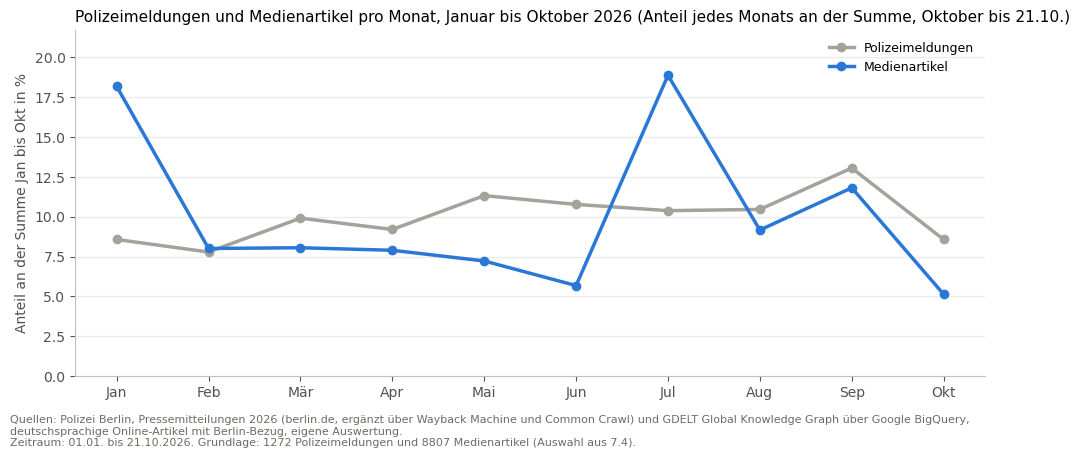

In [72]:
# Zeitverlauf im Vergleich: Anteil jedes Monats an der Jahressumme, damit beide Reihen trotz
# unterschiedlicher Größe auf eine Skala passen. Dazu die Korrelation der Wochenwerte.
monat_pol = df.groupby("monat").size()
monat_med = krimi.groupby("monat").size()
monate_v = pd.DataFrame({"Polizeimeldungen": monat_pol, "Medienartikel": monat_med}).fillna(0).astype(int)
anteil_monat = monate_v / monate_v.sum() * 100
display(monate_v.assign(**{"Polizei %": anteil_monat["Polizeimeldungen"].round(1),
                           "Medien %": anteil_monat["Medienartikel"].round(1)}))

woche_pol = df.set_index("datum").resample("W-MON", label="left", closed="left").size()
woche_med = krimi.set_index("tag").resample("W-MON", label="left", closed="left").size()
wochen = pd.DataFrame({"pol": woche_pol, "med": woche_med}).fillna(0).iloc[:-1]   # letzte Woche unvollständig
r_pearson = wochen["pol"].corr(wochen["med"])
r_spearman = wochen["pol"].corr(wochen["med"], method="spearman")
print(f"Wochen: {len(wochen)}, Korrelation der Wochenwerte: Pearson {r_pearson:.2f}, Spearman {r_spearman:.2f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
labels = [MONATE[int(m[5:7]) - 1] for m in anteil_monat.index]
ax.plot(labels, anteil_monat["Polizeimeldungen"], color="#a3a29b", linewidth=2.5, marker="o", label="Polizeimeldungen")
ax.plot(labels, anteil_monat["Medienartikel"], color="#2a78d6", linewidth=2.5, marker="o", label="Medienartikel")
ax.set_ylim(0, anteil_monat.max().max() * 1.15)
ax.set_ylabel("Anteil an der Summe Jan bis Okt in %", color="#52514e")
ax.set_title("Polizeimeldungen und Medienartikel pro Monat, Januar bis Oktober 2026 (Anteil jedes Monats an der Summe, Oktober bis 21.10.)",
             loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.", f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen und {len(krimi)} Medienartikel (Auswahl aus 7.4).")
(ROOT / "images").mkdir(exist_ok=True)                                  # Bild für die README
fig.savefig(ROOT / "images" / "polizei_medien_pro_monat.png", dpi=150, bbox_inches="tight")
plt.show()


#### Interpretation 8.2: Zeitverlauf

- **Die Polizei veröffentlicht gleichmäßig,** zwischen 7,8 % (Februar) und 13,1 % (September) ihrer Meldungen pro Monat.
- **Die Medien folgen großen Ereignissen.** Januar (18,2 %) und Juli (18,9 %) bringen zusammen mehr als ein Drittel aller Artikel, bei der Polizei sind es in diesen beiden Monaten 8,6 % und 10,4 %.
- **Kein Gleichlauf.** Die Wochenwerte hängen nicht zusammen (Pearson -0,21, Spearman -0,01). Wochen mit vielen Polizeimeldungen sind also nicht die Wochen mit vielen Medienartikeln.
- **Gemeinsam hoch ist nur der September** (13,1 % und 11,8 %).

### 8.3 Die vier Ereignisse

Gleiche Suchwörter und gleicher Zeitraum wie in 5.4, bei den Medien im Titel. Die Tabelle zeigt auch, wie viele verschiedene Titel es gibt und wie viele Artikel am Tag nach dem Ereignis erschienen sind.

,Zeitraum (Tage),Polizeimeldungen,Medienartikel,verschiedene Titel,Artikel je Meldung,Medienartikel am Tag danach
Ereignis,,,,,,
Brandanschlag auf Stromkabel,0 bis +28,3,533,254,177.7,129
1. Mai,-7 bis +7,2,151,112,75.5,48
Anschlag im Umfeld des CSD,0 bis +28,1,961,656,961.0,437
Wahl zum Abgeordnetenhaus,-7 bis +7,7,135,83,19.3,6


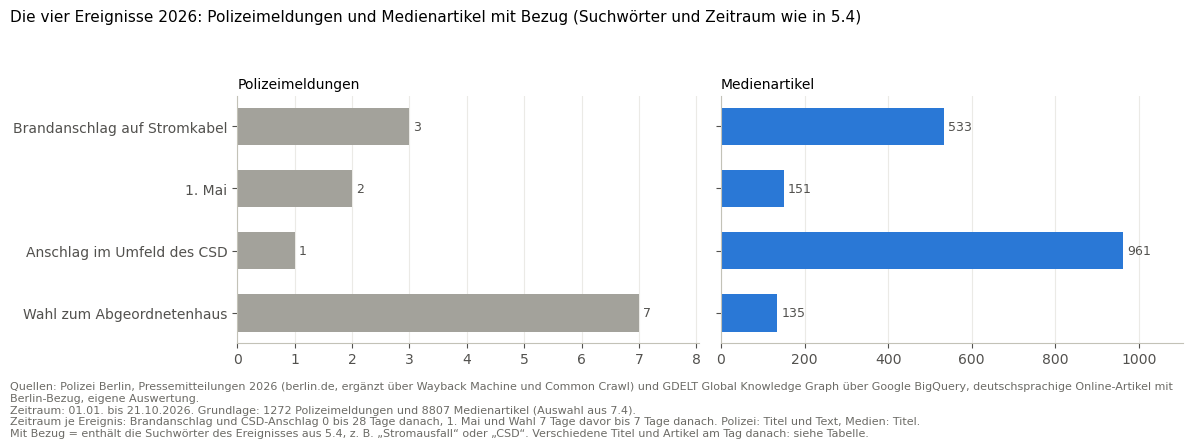

In [73]:
# Die vier Ereignisse: gleiche Suchwörter und gleicher Zeitraum wie in 5.4, bei den Medien im Titel
zeilen = []
for _, e in EREIGNISSE.iterrows():
    muster, vor, nach = BEZUG[e["ereignis"]]
    von, bis = e["datum"] + pd.Timedelta(days=vor), e["datum"] + pd.Timedelta(days=nach)
    pol = df[(df["datum"] >= von) & (df["datum"] <= bis)]
    pol = pol[(pol["titel"] + " " + pol["text"]).str.contains(muster, case=False, regex=True)]
    med = krimi[(krimi["tag"] >= von) & (krimi["tag"] <= bis)]
    med = med[med["titel"].str.contains(muster, case=False, regex=True)]
    zeilen.append({
        "Ereignis": e["ereignis"], "Zeitraum (Tage)": f"{vor} bis +{nach}",
        "Polizeimeldungen": len(pol), "Medienartikel": len(med),
        "verschiedene Titel": med["titel"].nunique(),
        "Artikel je Meldung": round(len(med) / len(pol), 1) if len(pol) else None,
        "Medienartikel am Tag danach": int((med["tag"] == e["datum"] + pd.Timedelta(days=1)).sum()),
    })
ereignis_vergleich = pd.DataFrame(zeilen).set_index("Ereignis")
display(ereignis_vergleich)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, spalte, farbe in [(axes[0], "Polizeimeldungen", "#a3a29b"), (axes[1], "Medienartikel", "#2a78d6")]:
    daten = ereignis_vergleich[spalte].iloc[::-1]
    ax.barh(daten.index, daten.values, color=farbe, height=0.6)
    for yy, w in enumerate(daten.values):
        ax.text(w + daten.max() * 0.01, yy, str(w), va="center", fontsize=9, color="#52514e")
    ax.set_xlim(0, daten.max() * 1.15)
    ax.set_title(spalte, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
axes[1].set_yticklabels([])
fig.suptitle("Die vier Ereignisse 2026: Polizeimeldungen und Medienartikel mit Bezug (Suchwörter und Zeitraum wie in 5.4)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.92))
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.", f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen und {len(krimi)} Medienartikel (Auswahl aus 7.4).",
         "Zeitraum je Ereignis: Brandanschlag und CSD-Anschlag 0 bis 28 Tage danach, 1. Mai und Wahl 7 Tage davor bis 7 Tage danach. Polizei: Titel und Text, Medien: Titel.",
         "Mit Bezug = enthält die Suchwörter des Ereignisses aus 5.4, z. B. „Stromausfall“ oder „CSD“. Verschiedene Titel und Artikel am Tag danach: siehe Tabelle.")
plt.show()


#### Interpretation 8.3: Die vier Ereignisse

- **Wenige Meldungen, sehr viele Artikel.** Zum Anschlag im Umfeld des CSD gibt es eine Polizeimeldung, aber 961 Medienartikel mit 656 verschiedenen Titeln. Zum Brandanschlag auf das Stromnetz sind es 3 Meldungen und 533 Artikel.
- **Am Tag danach** erschienen 437 Artikel zum CSD-Anschlag und 129 zum Stromanschlag.
- **1. Mai:** 2 Meldungen, 151 Artikel.
- **Die Wahl hat die meisten Meldungen (7), aber die wenigsten Artikel (135).** In der Auswahl aus 7.4 stehen nur Artikel zu Polizei und Kriminalität, die übrige Wahlberichterstattung fehlt hier.
- Zum CSD-Anschlag fehlt die erste Polizeimeldung (Nr. 905) in den Daten (siehe Limitations). Die Zahl der Polizeimeldungen ist dort deshalb zu klein.

### 8.4 Themen

Für jedes Thema aus 7.7 steht der Anteil an allen Polizeimeldungen (Titel und Text) und an allen Medienartikeln (Titel). Bei den Polizeimeldungen werden dieselben Suchwörter verwendet: 5.7, Messer aus 4.4, Gewalt gegen Polizei wie in 5.8 und die drei Themen zur Gewalt durch die Polizei wie in 7.7.

Anders als in 5.7 werden vorher die Kontaktangaben entfernt (z. B. „Hinweise nimmt … entgegen“), wie in 5.8. Deshalb liegen zwei Zahlen um eine Meldung niedriger als in 5.7: Antisemitismus 20 statt 21 und Rechtsextremismus 16 statt 17. In beiden Fällen stand das Suchwort nur im Kontaktsatz.

Der Faktor teilt den Medienanteil durch den Polizeianteil. Über 1 heißt: Das Thema nimmt in den Medien mehr Raum ein als in den Polizeimeldungen.

,Polizeimeldungen,Polizei %,Medienartikel,Medien %,Faktor Medien/Polizei
Linksextremismus,3,0.24,151,1.71,7.27
Antisemitismus,20,1.57,469,5.33,3.39
Nahost-Konflikt,11,0.86,111,1.26,1.46
Schusswaffe durch Polizei,5,0.39,40,0.45,1.16
Vorwürfe gegen Polizei,2,0.16,16,0.18,1.16
Versammlungen,22,1.73,122,1.39,0.80
Queerfeindlichkeit,36,2.83,198,2.25,0.79
Rechtsextremismus,16,1.26,61,0.69,0.55
Rassismus,29,2.28,49,0.56,0.24
Messer,175,13.76,232,2.63,0.19


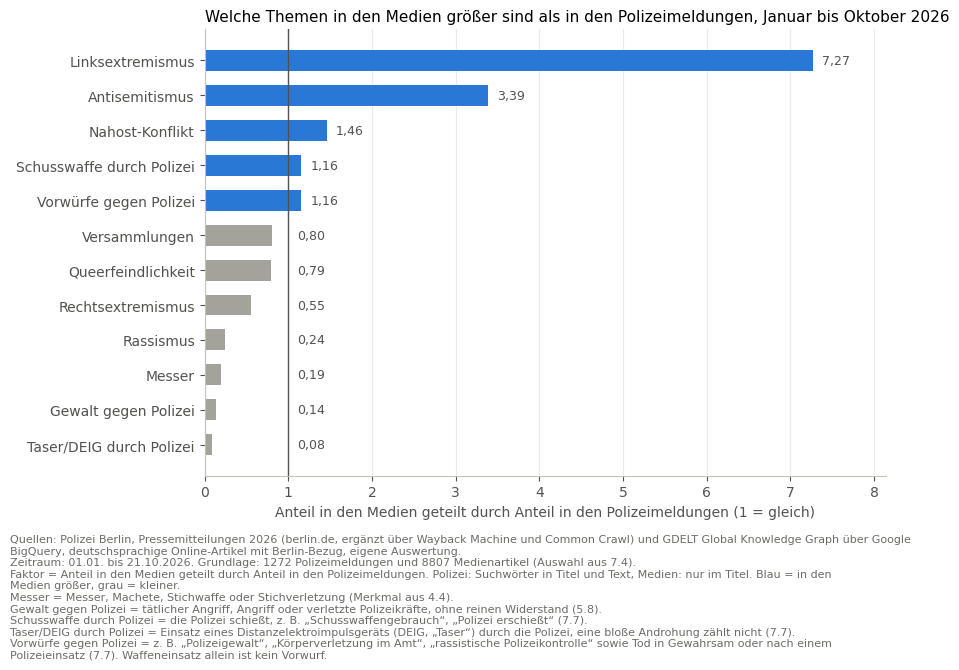

In [74]:
# Themen im Vergleich: Anteil der Polizeimeldungen (Titel und Text) und der Medienartikel (Titel) je Thema
# Polizei: Suchwörter aus 5.7, Messer aus 4.4, Gewalt gegen Polizei wie in 5.8, Gewalt durch die Polizei wie in 7.7
texte_pol = (df["titel"] + ". " + df["text"]).str.replace(KONTAKT, " ", regex=True)
for thema, muster in THEMEN.items():
    df[thema] = texte_pol.str.contains(muster, case=False, regex=True)
df["Messer"] = df["messer"]
df["Gewalt gegen Polizei"] = (texte_pol.str.contains(TAETLICH) | texte_pol.str.contains(ANGRIFF)
                              | pd.Series([polizei_verletzt(t, x) for t, x in zip(df["titel"], texte_pol)], index=df.index))
for thema, muster in GEWALT_DURCH_POLIZEI.items():
    df[thema] = texte_pol.map(lambda x, m=muster: trifft(m, x))

themen_vergleich = pd.DataFrame({
    "Polizeimeldungen": df[themen_m].sum(),
    "Polizei %": df[themen_m].mean() * 100,
    "Medienartikel": krimi[themen_m].sum(),
    "Medien %": krimi[themen_m].mean() * 100,
})
themen_vergleich["Faktor Medien/Polizei"] = themen_vergleich["Medien %"] / themen_vergleich["Polizei %"].where(themen_vergleich["Polizei %"] > 0)
themen_vergleich = themen_vergleich.sort_values("Faktor Medien/Polizei", ascending=False)
display(themen_vergleich.round(2))

# Faktor über 1: Thema hat in den Medien einen größeren Anteil als in den Polizeimeldungen
daten = themen_vergleich["Faktor Medien/Polizei"].dropna().iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(daten.index, daten.values, color=["#2a78d6" if v >= 1 else "#a3a29b" for v in daten.values], height=0.6)
ax.axvline(1, color="#52514e", linewidth=1)
for yy, v in enumerate(daten.values):                       # Zahl rechts vom Balken, aber nie auf der Linie bei 1
    ax.text(max(v, 1) + daten.max() * 0.015, yy, f"{v:.2f}".replace(".", ","), va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, daten.max() * 1.12)
ax.set_xlabel("Anteil in den Medien geteilt durch Anteil in den Polizeimeldungen (1 = gleich)", color="#52514e")
ax.set_title("Welche Themen in den Medien größer sind als in den Polizeimeldungen, Januar bis Oktober 2026", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.", f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen und {len(krimi)} Medienartikel (Auswahl aus 7.4).",
         "Faktor = Anteil in den Medien geteilt durch Anteil in den Polizeimeldungen. Polizei: Suchwörter in Titel und Text, Medien: nur im Titel. Blau = in den Medien größer, grau = kleiner.",
         BEGRIFF_MESSER, BEGRIFF_GEWALT_POLIZEI, BEGRIFF_SCHUSSWAFFE, BEGRIFF_DEIG, BEGRIFF_VORWURF)
plt.show()


#### Interpretation 8.4: Themen

- **Deutlich größer in den Medien sind drei Themen:** Linksextremismus (Faktor 7,27, 3 Meldungen zu 151 Artikeln), Antisemitismus (3,39) und Nahost-Konflikt (1,46). Bei Linksextremismus und Antisemitismus geht es in den Medien vor allem um Debatten nach dem Stromanschlag und nach der Wahl (siehe 7.7), nicht um einzelne Taten.
- **Gewalt gegen Polizei hat nach Taser/DEIG den zweitkleinsten Faktor (0,14).** Sie steht in 6,29 % der Polizeimeldungen, aber nur in 0,89 % der Medienartikel. Die Polizei meldet viele Einzelfälle, die Medien berichten vor allem über Silvester und den 1. Mai (siehe 7.7).
- **Messer (0,19) und Rassismus (0,24)** sind in den Medien ebenfalls deutlich kleiner als in den Polizeimeldungen.
- **Gewalt durch die Polizei, getrennt betrachtet:**
  - **Taser/DEIG** hat den kleinsten Faktor (0,08). Die Polizei meldet 36 Einsätze, meist bei Festnahmen, die Medien berichten in 21 Artikeln darüber.
  - **Schusswaffe** und **Vorwürfe gegen Polizei** liegen knapp über 1 (rund 1,2). Beide beruhen aber auf sehr kleinen Zahlen: 5 Polizeimeldungen und 40 Artikel bei der Schusswaffe, 2 Meldungen und 16 Artikel bei den Vorwürfen. Die 40 Artikel zur Schusswaffe betreffen vor allem einen einzigen Einsatz, den erschossenen CSD-Tatverdächtigen (siehe 8.6).
- **Die Grundlage ist ungleich.** Polizeimeldungen werden über Titel und Text durchsucht, Medienartikel nur über den Titel. Themen, die selten im Titel stehen, sind bei den Medien eher zu klein gemessen. Ein Faktor unter 1 heißt also nicht sicher, dass die Medien weniger darüber berichten.

### 8.5 Orte

Medientitel nennen viel seltener einen Ort als Polizeimeldungen, deren Text fast immer einen Ort enthält. Die Anteile beziehen sich deshalb nur auf Meldungen bzw. Artikel, die überhaupt einen Ort nennen (ohne Bezirke). Die Spalte „Rang Polizei“ zeigt, an welcher Stelle der Ort bei den Polizeimeldungen steht.

Polizeimeldungen mit Ortsangabe: 1165 von 1272, Medienartikel mit Ortsangabe im Titel: 186 von 8807


,Polizeimeldungen,Medienartikel,Polizei %,Medien %
kbO,,,,
Görlitzer Park/Wrangelkiez,15,52,1.3,28.0
Kottbusser Tor,10,14,0.9,7.5
Alexanderplatz,15,13,1.3,7.0
Hermannstraße/Bahnhof Neukölln,15,8,1.3,4.3
Rigaer Straße,8,7,0.7,3.8
Hermannplatz/Donaukiez,9,0,0.8,0.0
Warschauer Brücke,3,0,0.3,0.0


,Polizeimeldungen,Medienartikel,Polizei %,Medien %,Rang Polizei
Görlitzer Park,12,52,1.0,28.0,6
Kottbusser Tor,4,14,0.3,7.5,80
Alexanderplatz,9,13,0.8,7.0,17
Sonnenallee,15,11,1.3,5.9,2
Hermannstraße,13,7,1.1,3.8,4
Rigaer Straße,8,7,0.7,3.8,20
Tierpark,4,7,0.3,3.8,80
Nollendorfplatz,3,7,0.3,3.8,133
Baumschulenweg,10,6,0.9,3.2,14
Potsdamer Platz,4,6,0.3,3.2,80


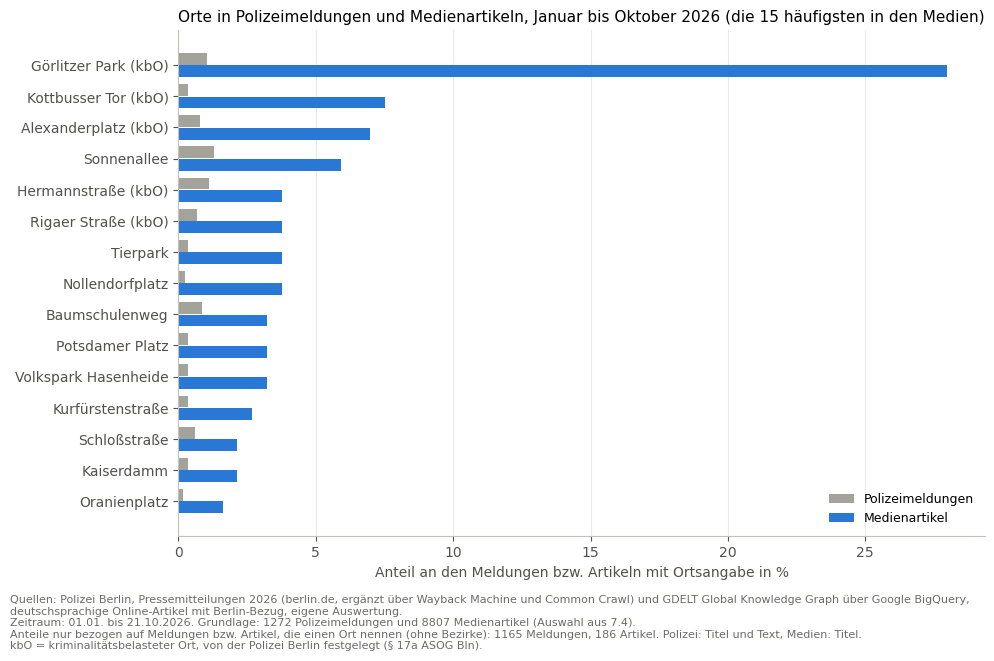

In [75]:
# Orte im Vergleich: kriminalitätsbelastete Orte (kbO) und Orte, die die Medien oft nennen
# Polizei: Orte aus 6.4 (Titel und Text), Medien: Orte aus 7.8 (Titel). Medientitel nennen viel seltener einen Ort
# als Polizeimeldungen, deshalb beziehen sich die Anteile nur auf Meldungen bzw. Artikel, die überhaupt einen Ort
# (ohne Bezirke) nennen.
import numpy as np

orte_ohne_bezirk = krimi["orte"].map(lambda o: [x for x in o if art.get(x) != "Bezirk"])
basis_pol = orte["meldung_id"].nunique()
basis_med = int((orte_ohne_bezirk.str.len() > 0).sum())
print(f"Polizeimeldungen mit Ortsangabe: {basis_pol} von {len(df)}, "
      f"Medienartikel mit Ortsangabe im Titel: {basis_med} von {len(krimi)}")

# kbO: Polizei wie in 6.5, Medien: Titel nennt einen Teil des kbO-Namens
kbo_vergleich = pd.DataFrame([{
    "kbO": kbo,
    "Polizeimeldungen": int(df[f"kbo_{kbo}"].sum()),
    "Medienartikel": int(orte_ohne_bezirk.map(lambda o, t=[x.strip() for x in kbo.split("/")]: any(x in o for x in t)).sum()),
} for kbo in KBO]).set_index("kbO")
kbo_vergleich["Polizei %"] = kbo_vergleich["Polizeimeldungen"] / basis_pol * 100
kbo_vergleich["Medien %"] = kbo_vergleich["Medienartikel"] / basis_med * 100
display(kbo_vergleich.sort_values("Medienartikel", ascending=False).round(1))

# Orte: die 15, die in den Medien am häufigsten vorkommen
orte_pol = orte.groupby("ort")["meldung_id"].nunique()
orte_med = pd.Series(Counter(x for o in orte_ohne_bezirk for x in o))
orte_v = pd.DataFrame({"Polizeimeldungen": orte_pol, "Medienartikel": orte_med}).fillna(0).astype(int)
orte_v = orte_v[orte_v.index.isin(orte_med.index)].sort_values(["Medienartikel", "Polizeimeldungen"], ascending=False).head(15)
orte_v["Polizei %"] = orte_v["Polizeimeldungen"] / basis_pol * 100
orte_v["Medien %"] = orte_v["Medienartikel"] / basis_med * 100
orte_v["Rang Polizei"] = orte_v.index.map(orte_pol.rank(ascending=False, method="min")).astype(int)
display(orte_v.round(1))

daten = orte_v.iloc[::-1]
y = np.arange(len(daten))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(y + 0.2, daten["Polizei %"], height=0.38, color="#a3a29b", label="Polizeimeldungen")
ax.barh(y - 0.2, daten["Medien %"], height=0.38, color="#2a78d6", label="Medienartikel")
ax.set_yticks(y, [f"{o} (kbO)" if o in kbo_namen else o for o in daten.index])
ax.set_xlabel("Anteil an den Meldungen bzw. Artikeln mit Ortsangabe in %", color="#52514e")
ax.set_title("Orte in Polizeimeldungen und Medienartikeln, Januar bis Oktober 2026 (die 15 häufigsten in den Medien)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.", f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen und {len(krimi)} Medienartikel (Auswahl aus 7.4).",
         f"Anteile nur bezogen auf Meldungen bzw. Artikel, die einen Ort nennen (ohne Bezirke): {basis_pol} Meldungen, {basis_med} Artikel. Polizei: Titel und Text, Medien: Titel.",
         BEGRIFF_KBO)
plt.show()


#### Interpretation 8.5: Orte

- **Medientitel nennen selten einen Ort.** Nur 186 von 8.807 Artikeln nennen im Titel einen Ort (ohne Bezirke), bei der Polizei sind es 1.165 von 1.272 Meldungen.
- **Die Medien konzentrieren sich auf wenige bekannte Orte.** Der Görlitzer Park steht in 28,0 % der Artikel mit Ortsangabe, aber nur in 1,0 % der Polizeimeldungen mit Ortsangabe (Rang 6 bei der Polizei). Das Kottbusser Tor kommt auf 7,5 %, bei der Polizei steht es auf Rang 80.
- **Bei der Polizei verteilt sich die Nennung auf viele Orte.** Die Sonnenallee ist bei der Polizei der Ort auf Rang 2, in den Medien kommt sie auf 5,9 %.
- **Fünf der acht häufigsten Medienorte sind kbO:** Görlitzer Park, Kottbusser Tor, Alexanderplatz, Hermannstraße und Rigaer Straße. Die Plätze 5 bis 8 teilen sich Hermannstraße, Rigaer Straße, Tierpark und Nollendorfplatz mit je 7 Artikeln.
- **Zwei kbO kommen in den Medientiteln gar nicht vor:** Hermannplatz/Donaukiez (9 Polizeimeldungen) und Warschauer Brücke (3).
- Die Medienanteile beruhen auf nur 186 Artikeln und sind deshalb unsicher.

### 8.6 Gewalt gegen Polizei und Gewalt durch die Polizei im Jahresverlauf

Vier Liniendiagramme, je Thema Polizeimeldungen und Medienartikel nebeneinander: Gewalt gegen Polizei, Schusswaffe durch Polizei, Taser/DEIG durch Polizei und Vorwürfe gegen Polizei.

**Wichtig beim Lesen:** Eine Polizeimeldung beschreibt meist einen Fall. Über einen Fall erscheinen aber oft Dutzende Medienartikel. Eine hohe Medienlinie heißt deshalb nicht, dass es viele Fälle gab. Unter jedem Diagramm steht für den stärksten Monat auch die Zahl der verschiedenen Titel. Die Zelle listet außerdem jede Polizeimeldung mit Schusswaffeneinsatz der Polizei einzeln auf, mit der Angabe, ob die Meldung einen Todesfall nennt.

Monate mit einem der vier Ereignisse aus 5.1 sind grau hinterlegt und nummeriert, die Namen stehen unter den Diagrammen. Die Stichwörter findet Python in den Titeln (wie in 7.6). Für den stärksten Medienmonat jedes Themas zeigt die Zelle alle Medientitel mit ihrer Anzahl und alle Polizeimeldungen desselben Monats.

,Jan,Feb,Mär,Apr,Mai,Jun,Jul,Aug,Sep,Okt,gesamt
Polizei: Gewalt gegen Polizei,5,3,9,5,16,13,10,1,11,7,80
Medien: Gewalt gegen Polizei,22,0,9,2,35,1,5,0,3,1,78
Polizei: Schusswaffe durch Polizei,0,0,0,1,0,0,2,0,1,1,5
Medien: Schusswaffe durch Polizei,0,0,0,10,0,0,29,0,1,0,40
Polizei: Taser/DEIG durch Polizei,2,2,2,4,8,4,3,4,4,3,36
Medien: Taser/DEIG durch Polizei,0,0,6,0,2,0,7,5,1,0,21
Polizei: Vorwürfe gegen Polizei,0,0,0,0,0,0,0,0,2,0,2
Medien: Vorwürfe gegen Polizei,1,0,1,0,0,10,1,0,3,0,16


Polizeimeldungen mit Schusswaffeneinsatz der Polizei: 5, davon tödlich laut Meldung: 1


,nr,datum,titel,tödlich laut Meldung
0,478,30.04.2026,"Festnahme nach Fahrzeugdiebstahl, verbotenem Kraftfahrzeugrennen und mehrere...",nein
1,906,26.07.2026,Anschlag im Umfeld des Christopher Street Day - Tatverdächtiger bei Polizeie...,ja
2,909,27.07.2026,Mutmaßlicher Brandstifter greift Polizeikräfte an – Schusswaffengebrauch,nein
3,1207,18.09.2026,Schussabgabe durch Polizeibeamten,nein
4,1362,14.10.2026,Schussabgabe eines Polizeibeamten,nein


Polizeimeldungen mit Waffeneinsatz der Polizei: 39, davon auch mit Gewalt gegen Polizei: 18

Gewalt gegen Polizei, stärkster Medienmonat Mai: 35 Medienartikel (11 verschiedene Titel), 16 Polizeimeldungen
  Medien, alle Titel mit Anzahl:
    19x  Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin
    5x  Berlin-Kreuzberg: Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin
    2x  Berlin-Kreuzberg: Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin - Politik
    2x  Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin - Politik
    1x  1. Mai in Berlin: 87 Festnahmen, 15 verletzte Polizisten!
    1x  Erste Bilanz mit zehn verletzten Polizisten am 1. Mai in Berlin
    1x  Auseinandersetzung in Berliner Hostel: 32-Jähriger greift nach Dienstwaffe von Polizisten – mit Taser ges
    1x  Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin - Politik Inland
    1x  Angriffe auf Polizei trüben friedlichen 1. Mai in Berlin - Politik-Nachrichten - Reutlinger General-Anze

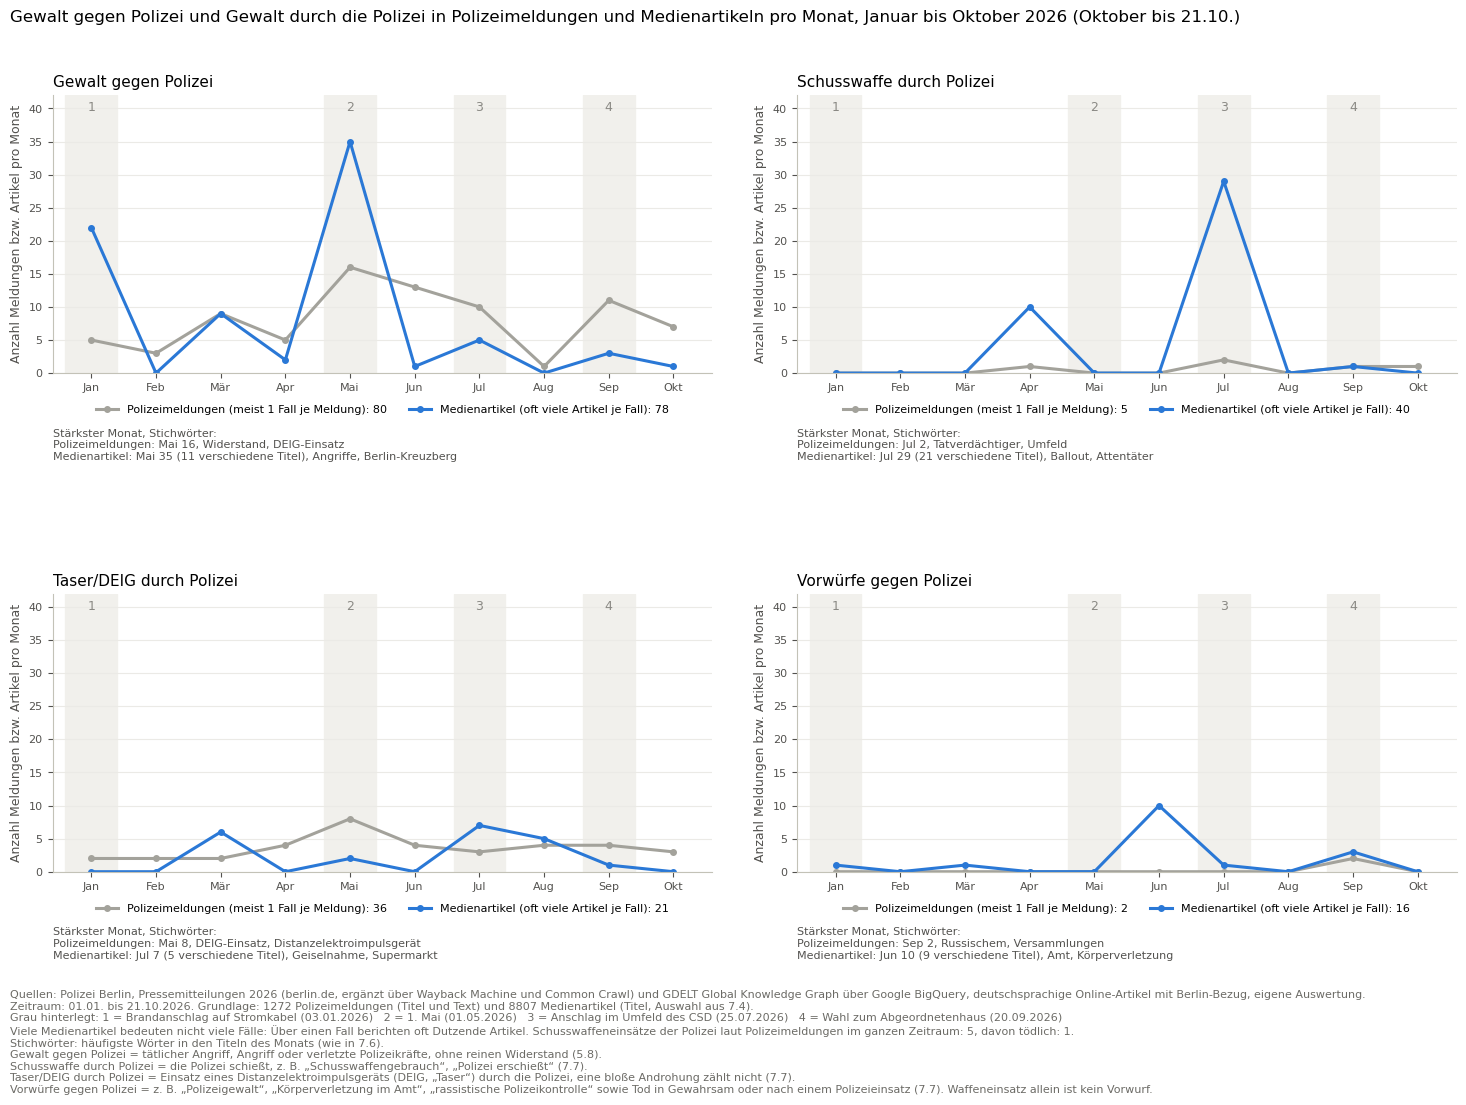

In [76]:
# Gewalt gegen Polizei und Gewalt durch die Polizei: Polizeimeldungen und Medien Monat für Monat nebeneinander
# Grundlage: die Spalten aus 8.4 (Polizei, Titel und Text) und 7.7 (Medien, Titel)
import numpy as np

POL_THEMEN = ["Gewalt gegen Polizei"] + list(GEWALT_DURCH_POLIZEI)
monate_v = sorted(set(df["monat"]) | set(krimi["monat"]))
labels_v = [MONATE[int(m[5:7]) - 1] for m in monate_v]
pro_monat_v = pd.DataFrame({
    f"{quelle}: {thema}": daten.groupby("monat")[thema].sum().reindex(monate_v, fill_value=0).astype(int)
    for thema in POL_THEMEN for quelle, daten in [("Polizei", df), ("Medien", krimi)]
})
pro_monat_v.index = labels_v
display(pro_monat_v.T.assign(gesamt=pro_monat_v.sum()))

# Wie oft hat die Polizei laut ihren Meldungen geschossen, und mit welchem Ausgang? Jede Meldung einzeln
TOEDLICH = re.compile(r"verstorben|verstarb|erlag|tödlich|getötet|erschossen|\bstarb\b", re.I)
schuss = df[df["Schusswaffe durch Polizei"]].copy()
schuss["tödlich laut Meldung"] = (schuss["titel"] + ". " + schuss["text"]).str.contains(TOEDLICH).map({True: "ja", False: "nein"})
print(f"Polizeimeldungen mit Schusswaffeneinsatz der Polizei: {len(schuss)}, davon tödlich laut Meldung: "
      f"{(schuss['tödlich laut Meldung'] == 'ja').sum()}")
display(schuss[["nr", "datum", "titel", "tödlich laut Meldung"]]
        .assign(datum=lambda d: d["datum"].dt.strftime("%d.%m.%Y"), titel=lambda d: d["titel"].str[:90])
        .reset_index(drop=True))

# Waffeneinsatz als Reaktion auf einen Angriff? Meldungen mit Taser/DEIG oder Schusswaffe, die auch Gewalt gegen Polizei nennen
waffe = df["Schusswaffe durch Polizei"] | df["Taser/DEIG durch Polizei"]
beide = waffe & df["Gewalt gegen Polizei"]
print(f"Polizeimeldungen mit Waffeneinsatz der Polizei: {waffe.sum()}, davon auch mit Gewalt gegen Polizei: {beide.sum()}")


def stichwoerter(titel: pd.Series, n: int = 2) -> str:
    """Häufigste Wörter in den Titeln, wie in 7.6 ohne allgemeine Wörter und Wörter vom Satzanfang."""
    zaehler = Counter(w for t in titel for w in set(WORT.findall(t)) if w not in allgemein)
    return ", ".join(w for w, _ in zaehler.most_common(n))


# Für jeden Monat: Worum geht es? Python sucht die Stichwörter in den Titeln der Treffer
zeilen = []
for thema in POL_THEMEN:
    for quelle, daten in [("Polizei", df), ("Medien", krimi)]:
        for m, lab in zip(monate_v, labels_v):
            treffer = daten.loc[(daten["monat"] == m) & daten[thema], "titel"]
            if len(treffer):
                zeilen.append({"Thema": thema, "Quelle": quelle, "Monat": lab, "Anzahl": len(treffer),
                               "verschiedene Titel": treffer.nunique(), "Stichwörter": stichwoerter(treffer)})
stich = pd.DataFrame(zeilen)

# Was meldet die Polizei in den Monaten, in denen die Medien am meisten berichten?
for thema in POL_THEMEN:
    spitze_m = monate_v[int(np.argmax([krimi.loc[krimi["monat"] == m, thema].sum() for m in monate_v]))]
    pol_titel = df.loc[(df["monat"] == spitze_m) & df[thema], "titel"]
    med_titel = krimi.loc[(krimi["monat"] == spitze_m) & krimi[thema], "titel"].value_counts()
    print(f"\n{thema}, stärkster Medienmonat {MONATE[int(spitze_m[5:7]) - 1]}: "
          f"{med_titel.sum()} Medienartikel ({len(med_titel)} verschiedene Titel), {len(pol_titel)} Polizeimeldungen")
    print("  Medien, alle Titel mit Anzahl:")
    for t, n in med_titel.items():
        print(f"    {n}x  {t[:105]}")
    print("  Polizeimeldungen im selben Monat:")
    for t in pol_titel:
        print(f"    {t[:105]}")

# Vier Liniendiagramme, je Thema Polizeimeldungen und Medienartikel. Unter jedem Diagramm: stärkster Monat mit Stichwörtern.
# Eine Polizeimeldung beschreibt meist einen Fall, über einen Fall erscheinen oft viele Medienartikel.
FARBE_Q = {"Polizei": "#a3a29b", "Medien": "#2a78d6"}
NAME_Q = {"Polizei": "Polizeimeldungen (meist 1 Fall je Meldung)", "Medien": "Medienartikel (oft viele Artikel je Fall)"}
ereignis_monat = [(MONATE[d.month - 1], nr, e, d) for nr, (e, d) in enumerate(zip(EREIGNISSE["ereignis"], EREIGNISSE["datum"]), 1)]
oben = pro_monat_v.max().max() * 1.2

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, thema in zip(axes.flat, POL_THEMEN):
    for monat_lab, nr, _, _ in ereignis_monat:                 # Monate mit einem der vier Ereignisse aus 5.1
        x = labels_v.index(monat_lab)
        ax.axvspan(x - 0.4, x + 0.4, color="#f1f0ec", zorder=0)
        ax.text(x, oben * 0.98, str(nr), ha="center", va="top", fontsize=9, color="#8a8984")
    spitzen = []
    for quelle in ["Polizei", "Medien"]:
        werte = pro_monat_v[f"{quelle}: {thema}"]
        ax.plot(labels_v, werte.values, color=FARBE_Q[quelle], linewidth=2.2, marker="o", markersize=4,
                label=f"{NAME_Q[quelle]}: {werte.sum()}")
        spitze = werte.idxmax()
        z = stich[(stich["Thema"] == thema) & (stich["Quelle"] == quelle) & (stich["Monat"] == spitze)]
        if len(z) and quelle == "Polizei":
            spitzen.append(f"Polizeimeldungen: {spitze} {werte.max()}, {z['Stichwörter'].iloc[0]}")
        elif len(z):
            spitzen.append(f"Medienartikel: {spitze} {werte.max()} ({z['verschiedene Titel'].iloc[0]} verschiedene Titel), "
                           f"{z['Stichwörter'].iloc[0]}")
    ax.set_ylim(0, oben)
    ax.set_xlim(-0.6, len(labels_v) - 0.4)
    ax.set_title(thema, loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
    ax.text(0, -0.2, "Stärkster Monat, Stichwörter:\n" + "\n".join(spitzen), transform=ax.transAxes,
            ha="left", va="top", fontsize=8, color="#52514e")
    ax.set_ylabel("Anzahl Meldungen bzw. Artikel pro Monat", color="#52514e", fontsize=9)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8)
    ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Gewalt gegen Polizei und Gewalt durch die Polizei in Polizeimeldungen und Medienartikeln pro Monat, "
             "Januar bis Oktober 2026 (Oktober bis 21.10.)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.96), h_pad=7)
fussnote(fig, f"Quellen: {QUELLE_POLIZEI} und {QUELLE_MEDIEN}, eigene Auswertung.",
         f"Zeitraum: {ZEITRAUM_TEXT}. Grundlage: {len(df)} Polizeimeldungen (Titel und Text) und {len(krimi)} Medienartikel (Titel, Auswahl aus 7.4).",
         "Grau hinterlegt: " + "   ".join(f"{nr} = {e} ({d:%d.%m.%Y})" for _, nr, e, d in ereignis_monat),
         "Viele Medienartikel bedeuten nicht viele Fälle: Über einen Fall berichten oft Dutzende Artikel. "
         f"Schusswaffeneinsätze der Polizei laut Polizeimeldungen im ganzen Zeitraum: {len(schuss)}, davon tödlich: {(schuss['tödlich laut Meldung'] == 'ja').sum()}.",
         "Stichwörter: häufigste Wörter in den Titeln des Monats (wie in 7.6).",
         BEGRIFF_GEWALT_POLIZEI, BEGRIFF_SCHUSSWAFFE, BEGRIFF_DEIG, BEGRIFF_VORWURF)
plt.show()


#### Interpretation 8.6: Gewalt gegen Polizei und Gewalt durch die Polizei

- **Viele Artikel heißen nicht viele Fälle.** Laut ihren Meldungen hat die Polizei im ganzen Zeitraum in fünf Fällen geschossen, einmal mit tödlichem Ausgang. Über diesen einen Fall erscheinen im Juli 28 der 29 Medienartikel zur Schusswaffe.
- **Juli, Schusswaffe:** Nach dem Anschlag im Umfeld des CSD wurde der Tatverdächtige bei einem Polizeieinsatz erschossen (Polizeimeldung Nr. 906 vom 26.07.2026). Laut der Meldung soll er die Spezialeinsatzkräfte mit einer Stichwaffe angegriffen haben, woraufhin sie von der Schusswaffe Gebrauch machten. Am 27.07.2026 meldet die Polizei einen zweiten Schusswaffengebrauch in Köpenick: Ein mutmaßlicher Brandstifter griff Polizeikräfte an (Nr. 909). Von den 29 Medienartikeln im Juli betrifft nur einer diesen zweiten Fall, alle anderen den CSD-Tatverdächtigen (siehe Titelliste in der Ausgabe).
- **April, Schusswaffe:** 10 Medienartikel berichten, dass die Polizei auf einen flüchtenden Autodieb geschossen hat. Dazu gibt es eine Polizeimeldung (Nr. 478 vom 30.04.2026).
- **Taser/DEIG** setzt die Polizei laut ihren Meldungen das ganze Jahr über ein, 2 bis 8 Mal im Monat, zusammen 36 Mal. Die Medien berichten selten darüber, am meisten im Juli (7 Artikel), vor allem über die Geiselnahme im Supermarkt.
- **Vorwürfe gegen Polizei** gibt es in den Polizeimeldungen nur zweimal, beide im September. In den Medien sind es 16 Artikel, 10 davon im Juni.
- **Gewalt gegen Polizei** zeigt das umgekehrte Bild: Die Polizei meldet das ganze Jahr Einzelfälle (80 Meldungen), die Medien berichten vor allem zu Silvester und zum 1. Mai (57 der 78 Artikel im Januar und Mai).
- **Waffeneinsatz und Angriffe auf Polizei hängen zusammen.** Von den 39 Polizeimeldungen mit Waffeneinsatz der Polizei nennen 18 auch Gewalt gegen Polizei. So stellt die Polizei ihren Waffeneinsatz in diesen Meldungen dar: als Reaktion auf einen Angriff auf Polizeikräfte.
- **Grenze:** Ob ein Einsatz rechtmäßig war, lässt sich aus Meldungen und Titeln nicht ablesen. Die Polizeimeldungen sind die Darstellung der Polizei.

## 9. Dashboard

Das Dashboard zeigt die wichtigsten Ergebnisse aus den Abschnitten 2 bis 8 interaktiv, auf Deutsch und Englisch. Es ist mit Streamlit gebaut und liegt im Ordner `dashboard/`:

| Datei | Inhalt |
|---|---|
| `dashboard/app.py` | das Dashboard |
| `dashboard/i18n.py` | alle Texte auf Deutsch und Englisch |
| `dashboard/data/` | die Tabellen aus 9.1 |
| `dashboard/requirements.txt` | die nötigen Pakete |

Das Dashboard liest nur die fertigen Tabellen aus 9.1. Darin stehen nur Zahlen, keine Texte von Polizeimeldungen oder Medienartikeln. So kann der Ordner auf GitHub und auf Streamlit Community Cloud veröffentlicht werden.

### 9.1 Tabellen für das Dashboard

Die Zelle schreibt die Ergebnisse der Abschnitte 2 bis 8 als CSV-Dateien nach `dashboard/data/`, dazu die Bezirksgrenzen und eine Datei mit Kennzahlen. Sie muss nach allen anderen Zellen laufen, weil sie deren Ergebnisse braucht.

In [77]:
# Tabellen für das Dashboard: nur Zahlen aus den Abschnitten 2 bis 8, keine Texte von Meldungen oder Artikeln
# Ziel: dashboard/data/ im Projektordner. Das Dashboard (dashboard/app.py) liest nur diese Dateien.
DASH = ROOT / "dashboard" / "data"
DASH.mkdir(parents=True, exist_ok=True)
schreiben = {}


def speichern(name: str, tabelle: pd.DataFrame):
    tabelle.to_csv(DASH / name, index=False, encoding="utf-8")
    schreiben[name] = len(tabelle)


alle_monate = sorted(set(df["monat"]) | set(krimi["monat"]))
alle_tage = pd.date_range("2026-01-01", "2026-10-21", freq="D")

# 1. Polizeimeldungen pro Monat, Bezirk und Kategorie (endgültige Kategorie aus 4.8)
speichern("polizei_monat.csv", df.assign(bezirk=df["bezirk"].fillna("ohne einzelnen Bezirk"))
          .groupby(["monat", "bezirk", "kategorie"]).size().reset_index(name="meldungen"))
# 2. Pro Tag: Polizei (Veröffentlichung) und Medien (Datum laut GDELT)
speichern("tag.csv", pd.DataFrame({
    "datum": alle_tage.strftime("%Y-%m-%d"),
    "polizei": df.groupby("datum").size().reindex(alle_tage, fill_value=0).values,
    "medien": krimi.groupby("tag").size().reindex(alle_tage, fill_value=0).values}))
# 3. Medienartikel pro Monat und Kategorie (Regeln aus 4.3 auf dem Titel, 7.5)
speichern("medien_monat.csv", krimi.groupby(["monat", "kategorie"]).size().reset_index(name="artikel"))
# 4. Themen pro Monat, Polizei und Medien (7.7 und 8.4)
themen_lang = pd.concat([
    d.groupby("monat")[themen_m].sum().reindex(alle_monate, fill_value=0).reset_index()
     .melt(id_vars="monat", var_name="thema", value_name="anzahl").assign(quelle=q)
    for q, d in [("polizei", df), ("medien", krimi)]])
speichern("themen_monat.csv", themen_lang)
speichern("themen_vergleich.csv", themen_vergleich.rename_axis("thema").reset_index().set_axis(
    ["thema", "polizei", "polizei_pct", "medien", "medien_pct", "faktor"], axis=1))
# 5. Kategorien im Vergleich (8.1)
speichern("kategorien_vergleich.csv", vergleich_kat.rename_axis("kategorie").reset_index().set_axis(
    ["kategorie", "polizei_titel_pct", "polizei_endgueltig_pct", "medien_titel_pct", "differenz_punkte"], axis=1))
# 6. Bezirke: Meldungen, Einwohner, je 100.000 (6.2) und Kategorien je Bezirk (6.3)
speichern("bezirke.csv", je_einwohner.rename_axis("bezirk").reset_index().set_axis(
    ["bezirk", "meldungen", "einwohner", "je_100000", "rang_meldungen", "rang_je_einwohner"], axis=1))
# Bevölkerung nach Staatsangehörigkeit und Migrationshintergrund (6.2, Tabelle 7), nur Anteile je Bezirk
speichern("bezirke_herkunft.csv", anteile_herkunft.rename_axis("bezirk").reset_index().set_axis(
    ["bezirk", "deutsche_ohne_mh_pct", "deutsche_mit_mh_pct", "auslaender_pct", "mit_mh_pct"], axis=1))
speichern("herkunft_test.csv", herkunft_tests.assign(
    anteil=herkunft_tests["Anteil"].map({v: k for k, v in {**GRUPPEN, "mit_mh": "mit Migrationshintergrund zusammen"}.items()}),
    bezirke=np.where(herkunft_tests["Bezirke"] == "alle 12 Bezirke", "alle", "ohne_top2"))
    [["anteil", "bezirke", "Spearman", "Zufallstest p"]].set_axis(["anteil", "bezirke", "spearman", "p"], axis=1))
# Haushalte nach Haushaltsnettoeinkommen (6.2, Mikrozensus Tabelle 7.5), Anteile je Bezirk
speichern("bezirke_einkommen.csv", einkommen.set_axis(["unter_1500", "1500_2000", "2000_3000", "3000_4000", "ab_4000"], axis=1)
    .rename_axis("bezirk").reset_index())
speichern("einkommen_test.csv", einkommen_tests.assign(
    anteil=np.where(einkommen_tests["Anteil Haushalte"] == STUFEN[0], "unter_1500", "ab_4000"),
    bezirke=np.where(einkommen_tests["Bezirke"] == "alle 12 Bezirke", "alle", "ohne_top2"))
    [["anteil", "bezirke", "Spearman", "Zufallstest p"]].set_axis(["anteil", "bezirke", "spearman", "p"], axis=1))
# Erwerbsbeteiligung (6.2, Mikrozensus Tabelle 7.3), Anteile je Bezirk
speichern("bezirke_erwerb.csv", erwerb_anteile.join(erwerb["Angabe Erwerbslose"].map(
    {"gesichert": "gesichert", "eingeschränkt": "eingeschraenkt", "berechnet, unsicher": "berechnet"}).rename("angabe_erwerbslose"))
    .rename_axis("bezirk").reset_index())
speichern("erwerb_test.csv", erwerb_tests.assign(
    anteil=np.where(erwerb_tests["Merkmal"] == "Erwerbstätige", "erwerbstaetige", "erwerbslosenquote"),
    bezirke=np.where(erwerb_tests["Bezirke"] == "alle 12 Bezirke", "alle", "ohne_top2"))
    [["anteil", "bezirke", "Spearman", "Zufallstest p"]].set_axis(["anteil", "bezirke", "spearman", "p"], axis=1))
speichern("bezirk_kategorie.csv", df.dropna(subset=["bezirk"]).groupby(["bezirk", "kategorie"]).size()
          .reset_index(name="meldungen"))
# 7. Karte: Orte mit Koordinaten (6.7) und Bezirksgrenzen (Geodatenportal Berlin, Datenlizenz Deutschland Zero 2.0)
speichern("orte_karte.csv", punkte[["ort", "bezirk", "lat", "lon", "meldungen", "kbo", "haeufigste_kategorie"]])
geo_dash = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {"bezirk": f["properties"][NAMENSFELD]}, "geometry": f["geometry"]}
    for f in bezirke_geo["features"]]}
(DASH / "bezirke.geojson").write_text(json.dumps(geo_dash, ensure_ascii=False), encoding="utf-8")
schreiben["bezirke.geojson"] = len(geo_dash["features"])
# 8. kbO und Orte im Vergleich (8.5), Orte in Medientiteln (7.8)
speichern("kbo_vergleich.csv", kbo_vergleich.rename_axis("kbo").reset_index().set_axis(
    ["kbo", "polizei", "medien", "polizei_pct", "medien_pct"], axis=1))
speichern("orte_vergleich.csv", orte_v.rename_axis("ort").reset_index().set_axis(
    ["ort", "polizei", "medien", "polizei_pct", "medien_pct", "rang_polizei"], axis=1))
speichern("medien_orte.csv", orte_tabelle_m[["Art", "Artikel"]].rename_axis("ort").reset_index().set_axis(
    ["ort", "art", "artikel"], axis=1))
# 9. Ereignisse (5.1 und 8.3), Quellen (7.9)
speichern("ereignisse.csv", ereignis_vergleich.rename_axis("ereignis").reset_index().set_axis(
    ["ereignis", "zeitraum", "polizei", "medien", "titel_verschieden", "artikel_je_meldung", "medien_tag_danach"], axis=1)
          .merge(EREIGNISSE[["ereignis", "datum"]].assign(datum=lambda d: d["datum"].dt.strftime("%Y-%m-%d")), on="ereignis"))
speichern("quellen.csv", quellen_mit.head(25).rename_axis("quelle").reset_index().set_axis(
    ["quelle", "artikel", "artikel_gesamt", "anteil_pct"], axis=1))
# 10. Veröffentlichung nach Wochentag und Stunde (5.6), Abdeckung pro Monat (2.8)
speichern("wochentag.csv", df["wochentag"].value_counts().reindex(["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"])
          .rename_axis("wochentag").reset_index(name="meldungen"))
speichern("stunde.csv", df.loc[df["uhrzeit_bekannt"] == 1, "stunde"].astype(int).value_counts()
          .reindex(range(24), fill_value=0).rename_axis("stunde").reset_index(name="meldungen"))
speichern("abdeckung.csv", abdeckung.reset_index().assign(monat=lambda d: d["monat"].astype(str))[["monat", "Abdeckung %"]]
          .set_axis(["monat", "abdeckung_pct"], axis=1))
# 11. Schusswaffeneinsätze der Polizei (8.6): nur Nummer, Datum, Bezirk und Ausgang, kein Text
speichern("schusswaffe_polizei.csv", schuss[["nr", "datum", "bezirk", "tödlich laut Meldung"]]
          .assign(datum=lambda d: d["datum"].dt.strftime("%Y-%m-%d")).set_axis(["nr", "datum", "bezirk", "toedlich"], axis=1))

# 12. Kennzahlen
kennzahlen = {
    "meldungen": int(len(df)), "meldungen_mit_bezirk": int(pro_bezirk.sum()),
    "artikel_auswahl": int(len(krimi)), "artikel_gesamt": int(len(medien)),
    "quellen_auswahl": int(krimi["quelle"].nunique()), "titel_verschieden": int(krimi["titel"].nunique()),
    "zeitraum_von": "2026-01-01", "zeitraum_bis": "2026-10-21",
    "einwohner_stichtag": STICHTAG.strftime("%Y-%m-%d"), "einwohner_berlin": int(berlin),
    "ohne_top2": spitze_bezirke,
    "mikrozensus_jahr": MZ_JAHR,
    "abdeckung_gesamt": round(float(gesamt_quote), 1),
    "korrelation_pearson": round(float(r_pearson), 2), "korrelation_spearman": round(float(r_spearman), 2),
    "schuss_polizei": int(len(schuss)), "schuss_toedlich": int((schuss["tödlich laut Meldung"] == "ja").sum()),
    "waffe_polizei": int(waffe.sum()), "waffe_mit_gewalt_gegen_polizei": int(beide.sum()),
    "modell": MODELL,
}
(DASH / "kennzahlen.json").write_text(json.dumps(kennzahlen, ensure_ascii=False, indent=1), encoding="utf-8")
schreiben["kennzahlen.json"] = len(kennzahlen)

print(f"Gespeichert in {DASH}:")
display(pd.Series(schreiben, name="Zeilen").to_frame())


Gespeichert in /home/amir/Dokumente/Github_projects/berlin_osint_2026/dashboard/data:


,Zeilen
polizei_monat.csv,659
tag.csv,294
medien_monat.csv,111
themen_monat.csv,240
themen_vergleich.csv,12
kategorien_vergleich.csv,12
bezirke.csv,12
bezirke_herkunft.csv,12
herkunft_test.csv,8
bezirke_einkommen.csv,12


### 9.2 Dashboard starten

Im Terminal im Projektordner:

```
pip install -r dashboard/requirements.txt
streamlit run dashboard/app.py
```

Das Dashboard öffnet sich im Browser. Die Sprache lässt sich oben rechts umschalten.

## Limitations

- **Polizeimeldungen sind keine Kriminalstatistik.** Die Polizei veröffentlicht nur eine Auswahl ihrer Fälle, vor allem solche mit öffentlichem Interesse oder Zeugenaufruf. Aussagen über die tatsächliche Kriminalität in Berlin sind daraus nicht möglich. Dafür ist die PKS die richtige Quelle.
- **Unvollständige Daten.** Rund 9 % der Meldungsnummern fehlen. Ursachen: Das offizielle Archiv listet nicht alle Meldungen, Meldungen werden nachträglich gelöscht (vor allem Vermisstenfälle und Fahndungen, Status 404 und 410), und der ID-Scan deckt nur den Zeitraum 20.05. bis 09.07. ab.
- **Schätzung der Vollständigkeit.** Die Abdeckung pro Monat beruht auf den Meldungsnummern. Fehlende Meldungen am Monatsrand werden dabei nicht erkannt.
- **Uhrzeit.** Bei 287 der 1.272 Meldungen ist nur das Datum bekannt. Auswertungen nach Uhrzeit beruhen nur auf den Meldungen aus dem Archiv.
- **Oktober unvollständig.** Erfasst bis 21.10.2026.
- **Ereignisort.** Er bezeichnet den Bezirk der Tat oder des Einsatzes, keine genaue Adresse. Rund 8 % der Meldungen haben keinen einzelnen Bezirk.
- **Datenschutz.** Die Meldungen enthalten teils Beschreibungen von Personen. Auf GitHub werden deshalb nur Auswertungen veröffentlicht, nicht die Volltexte.
- **Eine Kategorie pro Meldung.** Viele Meldungen berühren mehrere Themen (z. B. Raub mit Messer). Die Hauptkategorie gibt nur den Kern wieder, die Merkmale in 4.4 fangen einen Teil davon auf.
- **Regeln sind wortbasiert.** Sie erkennen keine Verneinungen und keinen Zusammenhang, rund jede achte Entscheidung ist knapp.
- **Sprachmodell.** Auch Gemma 4 irrt, in der Stichprobe bei 6 von 100 Meldungen. Die Ergebnisse gelten nur für dieses Modell und diesen Prompt. Ein anderes Modell oder eine neue Modellversion kann anders entscheiden.
- **Manuelle Stichprobe.** Sie stammt von einer einzigen Person, und 100 Meldungen erlauben nur grobe Aussagen. Sechs Einträge wurden nach dem Abgleich mit den Modellen korrigiert (siehe 4.7), was die Bewertung leicht zugunsten der Modelle verschieben kann.
- **Kategorie-Definitionen.** Zwei Unschärfen sind bekannt: „Trickdiebstahl“ steht unter „Betrug“, obwohl es rechtlich ein Diebstahl ist, und „Schüsse“ unterscheidet nicht zwischen Tätern und Polizei. Eine Änderung hätte einen neuen Lauf aller Modelle erfordert und wurde deshalb nicht mehr umgesetzt.
- **Veröffentlichung statt Tatzeit.** Datum und Uhrzeit beziehen sich auf die Veröffentlichung. In 74 % der Meldungen steht schon im ersten Satz „gestern“ oder „in der vergangenen Nacht“ (5.6), die Tat liegt also meist einen Tag davor. Die Uhrzeiten in 5.6 zeigen die Arbeitszeit der Pressestelle, nicht die Tatzeit.
- **Ereignisbezug über Suchwörter.** Ob eine Meldung zu einem Ereignis oder zum Wahlkampf gehört, wird in 5.4, 5.5 und 5.7 über Suchwörter bestimmt. Meldungen mit anderen Formulierungen fehlen, und ein Treffer beweist keinen Zusammenhang (z. B. Trickdiebstahl mit dem Vorwand „Stromnetz“).
- **Meldungen zu großen Ereignissen fehlen teilweise.** Die erste Meldung zum CSD-Anschlag (Nr. 905) ist nicht in den Daten, ihr Text steht aber in der Folgemeldung Nr. 906.
- **Politische Ausrichtung nur laut Meldung.** Rechts- und Linksextremismus in 5.7 zählen nur Meldungen, in denen die Polizei die Ausrichtung selbst nennt. Bei linker Ausrichtung geschieht das selten (3 Meldungen), die tatsächliche Zahl links motivierter Taten lässt sich daraus nicht ablesen.
- **Einwohnerzahlen.** Meldungen je Einwohner gibt es nur für die Bezirke (6.2), mit der Einwohnerzahl vom 30.06.2026. Besucher und Pendler sind darin nicht enthalten, das betrifft vor allem Mitte und Friedrichshain-Kreuzberg.
- **Bevölkerung nach Migrationshintergrund.** Der Vergleich in 6.2 gilt nur für die 12 Bezirke als Ganzes, nicht für Personen. Er sagt nichts über die Herkunft von Tatverdächtigen oder Opfern, die Polizeimeldungen nennen sie nur selten. Mit 12 Bezirken lassen sich Lage, Besucher, Alter und soziale Lage nicht vom Migrationshintergrund trennen. Für die Staatsangehörigkeit von Tatverdächtigen ist die PKS die richtige Quelle.
- **Haushaltseinkommen aus dem Mikrozensus.** Der Mikrozensus ist eine Stichprobe, die Werte je Bezirk sind auf Tausend Haushalte gerundet und haben einen Stichprobenfehler. Das Haushaltsnettoeinkommen ist nicht nach Haushaltsgröße gewichtet: Ein Haushalt mit vier Personen hat bei gleichem Einkommen weniger je Person als ein Single-Haushalt. Die Einkommen gelten für 2025, die Meldungen für 2026.
- **Erwerbslose aus dem Mikrozensus.** Je Bezirk sind es nur rund 6.000 bis 16.000 Personen. Das Amt für Statistik weist die meisten Werte nur mit eingeschränktem Aussagewert aus, für Steglitz-Zehlendorf und Marzahn-Hellersdorf gar nicht. Dort ist die Zahl als Differenz berechnet. Kleine Unterschiede zwischen Bezirken können reiner Stichprobenfehler sein.
- **Orte aus dem Text.** Die Orte werden über ein Suchmuster gefunden. Eine Meldung kann mehrere Orte nennen, lange Straßen kommen schon wegen ihrer Länge häufiger vor, und der Bezirk der Meldung muss nicht für jeden genannten Ort stimmen.
- **Kriminalitätsbelastete Orte.** Sie werden nur über ihren Namen im Text gefunden, die tatsächlichen Gebiete sind größer. Die Liste gilt seit dem 01.07.2026, ausgewertet wird aber das ganze Jahr.
- **Koordinaten.** Sie stammen von OpenStreetMap. Orte ohne genauen Treffer fehlen auf der Karte, bei langen Straßen liegt der Punkt an einer beliebigen Stelle der Straße.
- **Gewalt gegen Polizei.** Sie wird in 5.8 über Suchwörter gefunden. Gezählt werden Meldungen, nicht die Zahl der Angriffe oder der verletzten Beamten, und Bilanzen zu Großlagen fassen viele Vorfälle in einer Meldung zusammen.
- **GDELT erfasst nicht alle Medien.** Gezählt werden nur Online-Artikel, die GDELT gefunden hat. Artikel hinter Bezahlschranken, Fernsehen und Radio fehlen teilweise oder ganz. Die DOC-API war wegen Sperren nicht nutzbar (7.1).
- **Berlin-Bezug laut GDELT.** Ein Artikel gilt als Berlin-Artikel, sobald er einen Berliner Ort nennt. Dazu gehören auch Berichte über Bundespolitik oder andere Bundesländer, die Berlin nur nebenbei erwähnen.
- **Auswahl nur über den Titel.** Die Medienartikel werden nur über ihren Titel ausgewählt und eingeordnet, die Polizeimeldungen über Titel und Text. Artikel, deren Titel weder Berlin noch einen Berliner Ort nennt, fehlen. „Berlin“ steht in Titeln auch für den Senat oder die Bundespolitik, solche Artikel können trotzdem in die Auswahl gelangen.
- **Artikel statt Ereignisse.** Gezählt werden Artikel. Ein Ereignis, über das viele Medien berichten, zählt vielfach, und derselbe Titel erscheint oft in mehreren Medien (7.9).
- **Kategorien nur aus dem Titel.** Die Regeln aus 4.3 wurden für Polizeimeldungen mit Titel und Text entwickelt. Auf kurze Titel angewendet bleibt ein großer Teil ohne Kategorie (Sonstiges), bei Medien wie bei Polizei. Die endgültige Kategorie aus 4.8 ist mit den Medien nicht direkt vergleichbar.
- **Gewalt durch die Polizei.** Die Themen Schusswaffe und Taser/DEIG zählen, wie oft die Polizei laut Meldung oder Titel eine Waffe eingesetzt hat. Ob ein Einsatz rechtmäßig war, lässt sich daraus nicht ablesen. Bei den Polizeimeldungen stammen die Angaben von der Polizei selbst. Vorwürfe gegen Polizeikräfte sind ein eigenes Thema.
- **Anteile mit unterschiedlicher Grundlage.** Polizeimeldungen werden über Titel und Text durchsucht, Medienartikel nur über den Titel. Ein Thema, das selten im Titel steht, ist bei den Medien deshalb eher zu klein gemessen.
- **Orte in Medientiteln selten.** Nur ein kleiner Teil der Medientitel nennt einen Ort. Die Anteile in 8.5 beruhen bei den Medien auf wenigen Artikeln.


## Quellen

- Polizei Berlin: Polizeimeldungen, Archiv 2026. https://www.berlin.de/polizei/polizeimeldungen/archiv/2026/ (abgerufen 21.10. bis 22.10.2026)
- Internet Archive: Wayback Machine CDX Server API. https://web.archive.org/cdx/search/cdx
- Common Crawl: Index Server. https://index.commoncrawl.org/
- pandas: https://pandas.pydata.org/ · matplotlib: https://matplotlib.org/ · Requests: https://requests.readthedocs.io/ · Beautiful Soup: https://www.crummy.com/software/BeautifulSoup/ · NumPy: https://numpy.org/ · pypdf: https://pypdf.readthedocs.io/ · adjustText: https://github.com/Phlya/adjustText · tqdm: https://tqdm.github.io/
- Ollama: lokale Ausführung von Sprachmodellen, Structured Outputs. https://ollama.com/ · https://github.com/ollama/ollama/blob/main/docs/api.md
- Verwendete Modelle (Ollama-Bibliothek): Gemma 4 https://ollama.com/library/gemma4 · Mistral Small 3.1 https://ollama.com/library/mistral-small3.1 · Qwen 3.6 https://ollama.com/library/qwen3.6 · Gemma 2 https://ollama.com/library/gemma2
- berlin.de, Bezirksamt Neukölln, Wahlamt: Allgemeine Informationen (Berlinwahl 20.09.2026). https://www.berlin.de/ba-neukoelln/politik-und-verwaltung/aemter/amt-fuer-buergerdienste/wahlamt/artikel.1601620.php
- Cohen, J. (1960): A Coefficient of Agreement for Nominal Scales. Educational and Psychological Measurement 20 (1), S. 37-46.
- Polizei Berlin: Kriminalitätsbelastete Orte in Berlin. https://www.berlin.de/polizei/polizeimeldungen/fakten-hintergruende/artikel.1078268.php (Stand 27.07.2026)
- Geodatenportal Berlin: ALKIS Berlin Bezirke (WFS), Datenlizenz Deutschland Zero 2.0. https://gdi.berlin.de/services/wfs/alkis_bezirke
- OpenStreetMap: Nominatim, Daten © OpenStreetMap-Mitwirkende (ODbL). https://nominatim.openstreetmap.org/ · Nutzungsregeln: https://operations.osmfoundation.org/policies/nominatim/
- folium: https://python-visualization.github.io/folium/
- GDELT Project: DOC 2.0 API. https://blog.gdeltproject.org/gdelt-doc-2-0-api-debuts/
- GDELT Project: Global Knowledge Graph 2.1 in Google BigQuery (Tabelle gdelt-bq.gdeltv2.gkg_partitioned). https://www.gdeltproject.org/data.html
- Google Cloud: BigQuery-Sandbox. https://cloud.google.com/bigquery/docs/sandbox · google-cloud-bigquery: https://cloud.google.com/python/docs/reference/bigquery/latest
- Amt für Statistik Berlin-Brandenburg: Statistischer Bericht A I 5 (hj 1/26), Einwohnerregisterstatistik Berlin 30. Juni 2026, Bestand, Grunddaten. Tabelle 3: Einwohnerinnen und Einwohner nach Bezirken. Tabelle 7: Einwohnerinnen und Einwohner mit bzw. ohne Migrationshintergrund nach Bezirken. https://www.statistik-berlin-brandenburg.de/a-i-5-hj
- Amt für Statistik Berlin-Brandenburg: Statistischer Bericht A I 10 / A I 11 / A VI 2 - j / 25, Ergebnisse des Mikrozensus in Berlin 2025 (Erstergebnis). Tabelle 7.3: Bevölkerung im Land Berlin 2025 im Alter von 15 bis unter 65 Jahren nach Bezirken, Erwerbsbeteiligung und Geschlecht. Tabelle 7.5: Haushalte im Land Berlin 2025 nach Bezirken und Haushaltsnettoeinkommen. https://www.statistik-berlin-brandenburg.de
